In [2]:

# Step 0.4.1 - Import libraries and configure paths

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root directory
PROJECT_ROOT = Path.cwd().resolve().parent

# Elliptic dataset directory
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "elliptic"

print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())


Python version: 3.11.18
Project root: C:\Users\DELL\OneDrive\Desktop\btc-traffic-analysis
Dataset directory: C:\Users\DELL\OneDrive\Desktop\btc-traffic-analysis\data\raw\elliptic
Dataset exists: True


In [3]:

# Step 0.4.2 - Verify Elliptic dataset files

expected_files = [
    "AddrAddr_edgelist.csv",
    "AddrTx_edgelist.csv",
    "TxAddr_edgelist.csv",
    "txs_classes.csv",
    "txs_edgelist.csv",
    "txs_features.csv",
    "wallets_classes.csv",
    "wallets_features.csv",
    "wallets_features_classes_combined.csv"
]

print("ELLIPTIC DATASET FILE VERIFICATION")
print("=" * 60)

for filename in expected_files:

    file_path = DATA_DIR / filename

    if file_path.is_file():

        file_size = file_path.stat().st_size / (1024 * 1024)

        print(f"\nFile: {filename}")
        print("Status: FOUND")
        print(f"Size: {file_size:.2f} MB")

        try:
            sample = pd.read_csv(file_path, nrows=5)

            print("Columns:", sample.shape[1])
            print("Sample rows loaded:", sample.shape[0])
            print("Readable: YES")

        except Exception as error:
            print("Readable: NO")
            print("Error:", error)

    else:
        print(f"\nFile: {filename}")
        print("Status: MISSING")

print("\nVerification completed.")


ELLIPTIC DATASET FILE VERIFICATION

File: AddrAddr_edgelist.csv
Status: FOUND
Size: 191.34 MB
Columns: 2
Sample rows loaded: 5
Readable: YES

File: AddrTx_edgelist.csv
Status: FOUND
Size: 20.26 MB
Columns: 2
Sample rows loaded: 5
Readable: YES

File: TxAddr_edgelist.csv
Status: FOUND
Size: 35.00 MB
Columns: 2
Sample rows loaded: 5
Readable: YES

File: txs_classes.csv
Status: FOUND
Size: 2.25 MB
Columns: 2
Sample rows loaded: 5
Readable: YES

File: txs_edgelist.csv
Status: FOUND
Size: 4.26 MB
Columns: 2
Sample rows loaded: 5
Readable: YES

File: txs_features.csv
Status: FOUND
Size: 662.60 MB
Columns: 184
Sample rows loaded: 5
Readable: YES

File: wallets_classes.csv
Status: FOUND
Size: 29.01 MB
Columns: 2
Sample rows loaded: 5
Readable: YES

File: wallets_features.csv
Status: FOUND
Size: 578.37 MB
Columns: 57
Sample rows loaded: 5
Readable: YES

File: wallets_features_classes_combined.csv
Status: FOUND
Size: 580.79 MB
Columns: 58
Sample rows loaded: 5
Readable: YES

Verification complet

In [4]:

# Step 0.4.3 - Compact dataset verification

file_summary = []

for filename in expected_files:
    file_path = DATA_DIR / filename

    record = {
        "Filename": filename,
        "Exists": file_path.is_file(),
        "Size (MB)": None,
        "Columns": None,
        "Readable": False
    }

    if file_path.is_file():
        record["Size (MB)"] = round(
            file_path.stat().st_size / (1024 ** 2), 2
        )

        try:
            sample = pd.read_csv(file_path, nrows=5)
            record["Columns"] = sample.shape[1]
            record["Readable"] = True
        except Exception as error:
            print(f"Error reading {filename}: {error}")

    file_summary.append(record)

summary_df = pd.DataFrame(file_summary)

display(summary_df)

print("\nFiles found:", summary_df["Exists"].sum())
print("Files readable:", summary_df["Readable"].sum())
print("Total expected:", len(expected_files))



,Filename,Exists,Size (MB),Columns,Readable
0,AddrAddr_edgelist.csv,True,191.34,2,True
1,AddrTx_edgelist.csv,True,20.26,2,True
2,TxAddr_edgelist.csv,True,35.00,2,True
3,txs_classes.csv,True,2.25,2,True
4,txs_edgelist.csv,True,4.26,2,True
5,txs_features.csv,True,662.60,184,True
6,wallets_classes.csv,True,29.01,2,True
7,wallets_features.csv,True,578.37,57,True
8,wallets_features_classes_combined.csv,True,580.79,58,True



Files found: 9
Files readable: 9
Total expected: 9


In [5]:

# Step 0.4.4 - Inspect CSV headers and sample records

from IPython.display import display

for filename in expected_files:

    file_path = DATA_DIR / filename

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    # Read first 3 rows without assuming a header
    raw_sample = pd.read_csv(
        file_path,
        header=None,
        nrows=3,
        low_memory=False
    )

    # Read first 3 rows using pandas default header behavior
    default_sample = pd.read_csv(
        file_path,
        nrows=3,
        low_memory=False
    )

    print("\nNumber of columns:", raw_sample.shape[1])

    print("\nFirst row interpreted as data:")
    display(raw_sample.head(2).iloc[:, :8])

    print("\nColumn names detected by pandas:")
    print(default_sample.columns[:8].tolist())

    print("\nFirst rows using default CSV loading:")
    display(default_sample.head(2).iloc[:, :8])

print("\nCSV schema inspection completed.")



FILE: AddrAddr_edgelist.csv

Number of columns: 2

First row interpreted as data:


,0,1
0,input_address,output_address
1,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,1GASxu5nMntiRKdVtTVRvEbP965G51bhHH



Column names detected by pandas:
['input_address', 'output_address']

First rows using default CSV loading:


,input_address,output_address
0,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,1GASxu5nMntiRKdVtTVRvEbP965G51bhHH
1,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a



FILE: AddrTx_edgelist.csv

Number of columns: 2

First row interpreted as data:


,0,1
0,input_address,txId
1,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,230325127


... (27 outputs left out)

,0,1,2,3,4,5,6,7
0,address,Time step,class,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks
1,111112TykSw72ztDN2WJger4cynzWYC5w,25,2,0.0,1.0,439586.0,439586.0,0.0



Column names detected by pandas:
['address', 'Time step', 'class', 'num_txs_as_sender', 'num_txs_as receiver', 'first_block_appeared_in', 'last_block_appeared_in', 'lifetime_in_blocks']

First rows using default CSV loading:


,address,Time step,class,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,2,0.0,1.0,439586.0,439586.0,0.0
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,25,3,0.0,8.0,439589.0,485959.0,46370.0



CSV schema inspection completed.


In [6]:

# Step 0.4.5 - Full dataset profiling

import pandas as pd
import gc

CHUNK_SIZE = 50000

profile_results = []

for filename in expected_files:

    file_path = DATA_DIR / filename

    print(f"Profiling: {filename}")

    total_rows = 0
    total_columns = 0
    missing_values = 0
    duplicate_rows = 0

    # Track rows seen across chunks to detect exact duplicates
    seen_rows = set()

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE
    ):

        total_rows += len(chunk)
        total_columns = len(chunk.columns)

        missing_values += int(
            chunk.isna().sum().sum()
        )

        # Count exact duplicates across all chunks
        row_hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        )

        for row_hash in row_hashes:
            row_hash = int(row_hash)

            if row_hash in seen_rows:
                duplicate_rows += 1
            else:
                seen_rows.add(row_hash)

        del chunk
        gc.collect()

    profile_results.append({
        "File": filename,
        "Rows": total_rows,
        "Columns": total_columns,
        "Missing Values": missing_values,
        "Duplicate Rows": duplicate_rows
    })

profile_df = pd.DataFrame(profile_results)

display(profile_df)

print("\nFull dataset profiling completed.")


Profiling: AddrAddr_edgelist.csv
Profiling: AddrTx_edgelist.csv
Profiling: TxAddr_edgelist.csv
Profiling: txs_classes.csv
Profiling: txs_edgelist.csv
Profiling: txs_features.csv
Profiling: wallets_classes.csv
Profiling: wallets_features.csv
Profiling: wallets_features_classes_combined.csv


,File,Rows,Columns,Missing Values,Duplicate Rows
0,AddrAddr_edgelist.csv,2868964,2,0,84620
1,AddrTx_edgelist.csv,477117,2,0,0
2,TxAddr_edgelist.csv,837124,2,0,0
3,txs_classes.csv,203769,2,0,0
4,txs_edgelist.csv,234355,2,0,0
5,txs_features.csv,203769,184,16405,0
6,wallets_classes.csv,822942,2,0,0
7,wallets_features.csv,1268260,57,0,347569
8,wallets_features_classes_combined.csv,1268260,58,0,347569



Full dataset profiling completed.


In [7]:

# Step 0.4.5 - Full dataset profiling

import pandas as pd
import gc

CHUNK_SIZE = 50000

profile_results = []

for filename in expected_files:

    file_path = DATA_DIR / filename

    print(f"Profiling: {filename}")

    total_rows = 0
    total_columns = 0
    missing_values = 0
    duplicate_rows = 0

    # Track rows seen across chunks to detect exact duplicates
    seen_rows = set()

    for chunk in pd.read_csv(
        file_path,
        chunksize=CHUNK_SIZE
    ):

        total_rows += len(chunk)
        total_columns = len(chunk.columns)

        missing_values += int(
            chunk.isna().sum().sum()
        )

        # Count exact duplicates across all chunks
        row_hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        )

        for row_hash in row_hashes:
            row_hash = int(row_hash)

            if row_hash in seen_rows:
                duplicate_rows += 1
            else:
                seen_rows.add(row_hash)

        del chunk
        gc.collect()

    profile_results.append({
        "File": filename,
        "Rows": total_rows,
        "Columns": total_columns,
        "Missing Values": missing_values,
        "Duplicate Rows": duplicate_rows
    })

profile_df = pd.DataFrame(profile_results)

display(profile_df)

print("\nFull dataset profiling completed.")


Profiling: AddrAddr_edgelist.csv
Profiling: AddrTx_edgelist.csv
Profiling: TxAddr_edgelist.csv
Profiling: txs_classes.csv
Profiling: txs_edgelist.csv
Profiling: txs_features.csv
Profiling: wallets_classes.csv
Profiling: wallets_features.csv
Profiling: wallets_features_classes_combined.csv


,File,Rows,Columns,Missing Values,Duplicate Rows
0,AddrAddr_edgelist.csv,2868964,2,0,84620
1,AddrTx_edgelist.csv,477117,2,0,0
2,TxAddr_edgelist.csv,837124,2,0,0
3,txs_classes.csv,203769,2,0,0
4,txs_edgelist.csv,234355,2,0,0
5,txs_features.csv,203769,184,16405,0
6,wallets_classes.csv,822942,2,0,0
7,wallets_features.csv,1268260,57,0,347569
8,wallets_features_classes_combined.csv,1268260,58,0,347569



Full dataset profiling completed.


In [8]:

# Step 0.4.6 - Analyze class distributions

import pandas as pd

# Load only the two class-label datasets
tx_classes = pd.read_csv(
    DATA_DIR / "txs_classes.csv",
    dtype={"txId": "string", "class": "string"}
)

wallet_classes = pd.read_csv(
    DATA_DIR / "wallets_classes.csv",
    dtype={"address": "string", "class": "string"}
)

print("=" * 55)
print("TRANSACTION CLASS DISTRIBUTION")
print("=" * 55)

tx_distribution = (
    tx_classes["class"]
    .value_counts(dropna=False)
    .rename_axis("Class")
    .reset_index(name="Count")
)

tx_distribution["Percentage"] = (
    tx_distribution["Count"] / len(tx_classes) * 100
).round(2)

display(tx_distribution)

print("\n" + "=" * 55)
print("WALLET CLASS DISTRIBUTION")
print("=" * 55)

wallet_distribution = (
    wallet_classes["class"]
    .value_counts(dropna=False)
    .rename_axis("Class")
    .reset_index(name="Count")
)

wallet_distribution["Percentage"] = (
    wallet_distribution["Count"] / len(wallet_classes) * 100
).round(2)

display(wallet_distribution)

print("\nUnique transaction IDs:",
      tx_classes["txId"].nunique())

print("Unique wallet addresses:",
      wallet_classes["address"].nunique())

print("\nDuplicate transaction IDs:",
      tx_classes["txId"].duplicated().sum())

print("Duplicate wallet addresses:",
      wallet_classes["address"].duplicated().sum())

print("\nClass distribution analysis completed.")


TRANSACTION CLASS DISTRIBUTION


,Class,Count,Percentage
0,3,157205,77.15
1,2,42019,20.62
2,1,4545,2.23



WALLET CLASS DISTRIBUTION


,Class,Count,Percentage
0,3,557588,67.76
1,2,251088,30.51
2,1,14266,1.73



Unique transaction IDs: 203769
Unique wallet addresses: 822942

Duplicate transaction IDs: 0
Duplicate wallet addresses: 0

Class distribution analysis completed.


In [9]:

# Step 0.4.7 - Investigate wallet record repetition

wallet_df = pd.read_csv(
    DATA_DIR / "wallets_features.csv",
    usecols=["address", "Time step"],
    dtype={"address": "string"}
)

print("Total wallet feature rows:", len(wallet_df))
print("Unique addresses:", wallet_df["address"].nunique())
print("Unique time steps:", wallet_df["Time step"].nunique())

print("\nRepeated address entries:",
      wallet_df["address"].duplicated().sum())

print("Repeated address + time step pairs:",
      wallet_df.duplicated(
          subset=["address", "Time step"]
      ).sum())

print("\nNumber of time steps per address:")

steps_per_address = (
    wallet_df.groupby("address")["Time step"]
    .nunique()
)

display(steps_per_address.describe())

print("\nExample addresses appearing in multiple time steps:")

multiple_steps = steps_per_address[
    steps_per_address > 1
].head(5)

display(multiple_steps)

print("\nWallet repetition analysis completed.")


Total wallet feature rows: 1268260
Unique addresses: 822942
Unique time steps: 49

Repeated address entries: 445318
Repeated address + time step pairs: 347569

Number of time steps per address:


count    822942.000000
mean          1.118780
std           0.571136
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          47.000000
Name: Time step, dtype: float64


Example addresses appearing in multiple time steps:


address
1111DAYXhoxZx2tsRnzimfozo783x1yC2     6
111khWGs3Mj7UgKT7aS6hLsYK11ii4Gmw     2
1121A3vrYYduVPMnfS87ieHFP2bwy6xriv    3
112467zLZa5J6JLmvDr384Adx9ddqeRqC2    2
1125mk1uScXXFi5MfR6gBpBDu3UNCvh2WF    3
Name: Time step, dtype: int64


Wallet repetition analysis completed.


In [10]:

# Step 0.4.8 - Verify exact wallet duplicates

wallet_full = pd.read_csv(
    DATA_DIR / "wallets_features.csv"
)

# Duplicate rows across every column
exact_duplicates = wallet_full.duplicated().sum()

# Duplicate rows based on address and time step
key_duplicates = wallet_full.duplicated(
    subset=["address", "Time step"]
).sum()

print("Total rows:", len(wallet_full))
print("Exact duplicate rows:", exact_duplicates)
print("Repeated address-time pairs:", key_duplicates)

print("\nDo duplicate counts match?",
      exact_duplicates == key_duplicates)

print("\nUnique address-time observations:",
      len(wallet_full) - key_duplicates)

print("\nExample of repeated records:")

duplicate_examples = wallet_full[
    wallet_full.duplicated(
        subset=["address", "Time step"],
        keep=False
    )
]

display(duplicate_examples.iloc[:6, :8])

print("\nExact duplicate verification completed.")



Total rows: 1268260
Exact duplicate rows: 347569
Repeated address-time pairs: 347569

Do duplicate counts match? True

Unique address-time observations: 920691

Example of repeated records:


,address,Time step,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs
3,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0
4,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0
5,1111DAYXhoxZx2tsRnzimfozo783x1yC2,43,0.0,8.0,439589.0,485959.0,46370.0,8.0
6,1111DAYXhoxZx2tsRnzimfozo783x1yC2,43,0.0,8.0,439589.0,485959.0,46370.0,8.0
10,111218KKkh1JJFRHbwM16AwCiVCc4m7he1,17,1.0,1.0,423456.0,423456.0,0.0,2.0
11,111218KKkh1JJFRHbwM16AwCiVCc4m7he1,17,1.0,1.0,423456.0,423456.0,0.0,2.0



Exact duplicate verification completed.


In [11]:

# Step 0.4.9 - Analyze missing transaction features

tx_features = pd.read_csv(
    DATA_DIR / "txs_features.csv"
)

print("Total transactions:", len(tx_features))
print("Total columns:", tx_features.shape[1])

# Count missing cells across the dataset
total_missing = tx_features.isna().sum().sum()

# Count transactions containing at least one missing value
rows_with_missing = tx_features.isna().any(axis=1).sum()

# Count columns containing missing values
columns_with_missing = (
    tx_features.isna().sum() > 0
).sum()

print("\nTotal missing cells:", total_missing)
print("Transactions with missing values:", rows_with_missing)
print("Columns with missing values:", columns_with_missing)

# Missing-value summary by column
missing_summary = pd.DataFrame({
    "Missing Count": tx_features.isna().sum(),
    "Missing Percentage": (
        tx_features.isna().mean() * 100
    ).round(3)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Count",
    ascending=False
)

print("\nTop 15 columns with missing values:")
display(missing_summary.head(15))

print("\nMissing values in identifier and time columns:")
print(tx_features[["txId", "Time step"]].isna().sum())

print("\nMissing-value analysis completed.")


Total transactions: 203769
Total columns: 184

Total missing cells: 16405
Transactions with missing values: 965
Columns with missing values: 17

Top 15 columns with missing values:


,Missing Count,Missing Percentage
in_txs_degree,965,0.474
out_txs_degree,965,0.474
total_BTC,965,0.474
fees,965,0.474
size,965,0.474
num_input_addresses,965,0.474
num_output_addresses,965,0.474
in_BTC_min,965,0.474
in_BTC_max,965,0.474
in_BTC_mean,965,0.474



Missing values in identifier and time columns:
txId         0
Time step    0
dtype: int64

Missing-value analysis completed.


In [12]:

# Step 0.4.10 - Investigate missing-value patterns

# Identify columns containing missing values
missing_columns = tx_features.columns[
    tx_features.isna().any()
].tolist()

# Count missing feature values per transaction
missing_per_row = tx_features[
    missing_columns
].isna().sum(axis=1)

print("Number of affected columns:", len(missing_columns))

print("\nMissing values per transaction:")
display(
    missing_per_row.value_counts()
    .sort_index()
    .rename_axis("Missing features")
    .reset_index(name="Transaction count")
)

# Select transactions with at least one missing feature
affected_tx = tx_features.loc[
    missing_per_row > 0,
    ["txId", "Time step"]
].copy()

print("\nAffected transactions:", len(affected_tx))

print("\nTime-step distribution of affected transactions:")
display(
    affected_tx["Time step"]
    .value_counts()
    .sort_index()
    .rename_axis("Time step")
    .reset_index(name="Affected transactions")
)

# Attach class labels for analysis only
affected_with_labels = affected_tx.merge(
    tx_classes[["txId", "class"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

print("\nClass distribution among affected transactions:")
display(
    affected_with_labels["class"]
    .value_counts(dropna=False)
    .rename_axis("Class")
    .reset_index(name="Count")
)

print("\nMissing-pattern investigation completed.")


Number of affected columns: 17

Missing values per transaction:


,Missing features,Transaction count
0,0,202804
1,17,965



Affected transactions: 965

Time-step distribution of affected transactions:


,Time step,Affected transactions
0,1,36
1,2,15
2,4,4
3,5,2
4,7,22
5,8,26
6,9,5
7,11,7
8,12,8
9,13,12


ValueError: You are trying to merge on int64 and string columns for key 'txId'. If you wish to proceed you should use pd.concat

In [ ]:

# Step 0.4.10 - Fix transaction ID data types and merge

# Convert both transaction ID columns to the same type
affected_tx["txId"] = affected_tx["txId"].astype("string")
tx_classes["txId"] = tx_classes["txId"].astype("string")

# Verify the data types
print("Affected transaction ID type:", affected_tx["txId"].dtype)
print("Class transaction ID type:", tx_classes["txId"].dtype)

# Merge affected transactions with their class labels
affected_with_labels = affected_tx.merge(
    tx_classes[["txId", "class"]],
    on="txId",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMerge verification:")
print(affected_with_labels["_merge"].value_counts())

print("\nClass distribution among affected transactions:")
display(
    affected_with_labels["class"]
    .value_counts(dropna=False)
    .rename_axis("Class")
    .reset_index(name="Count")
)

print("\nMissing-pattern investigation completed.")


Affected transaction ID type: string
Class transaction ID type: string

Merge verification:
_merge
both          965
left_only       0
right_only      0
Name: count, dtype: int64

Class distribution among affected transactions:


,Class,Count
0,2,519
1,3,446



Missing-pattern investigation completed.


In [ ]:

# Step 0.4.11 - Analyze missing transactions by time step

# Count all transactions in each time step
total_by_step = (
    tx_features.groupby("Time step")
    .size()
    .rename("Total Transactions")
)

# Count affected transactions in each time step
missing_by_step = (
    affected_tx.groupby("Time step")
    .size()
    .rename("Affected Transactions")
)

# Combine both counts
time_missing_summary = pd.concat(
    [total_by_step, missing_by_step],
    axis=1
).fillna(0)

time_missing_summary["Affected Transactions"] = (
    time_missing_summary["Affected Transactions"].astype(int)
)

# Calculate the percentage affected within each time step
time_missing_summary["Missing Rate (%)"] = (
    time_missing_summary["Affected Transactions"]
    / time_missing_summary["Total Transactions"]
    * 100
).round(3)

print("Time steps containing missing transactions:")

display(
    time_missing_summary[
        time_missing_summary["Affected Transactions"] > 0
    ].sort_values(
        "Affected Transactions",
        ascending=False
    )
)

print("\nTotal affected transactions:",
      time_missing_summary["Affected Transactions"].sum())

print("\nMissing-value time-step analysis completed.")


Time steps containing missing transactions:


,Total Transactions,Affected Transactions,Missing Rate (%)
Time step,,,
43,5063,144,2.844
36,6393,117,1.830
37,3306,62,1.875
34,2486,50,2.011
39,2760,43,1.558
31,2816,41,1.456
45,5598,40,0.715
1,7880,36,0.457
23,4165,33,0.792



Total affected transactions: 965

Missing-value time-step analysis completed.


In [ ]:

# Step 0.4.12 - Verify missing-feature pattern

missing_columns = tx_features.columns[
    tx_features.isna().any()
].tolist()

missing_per_row = tx_features[
    missing_columns
].isna().sum(axis=1)

print("Columns containing missing values:")
for column in missing_columns:
    print("-", column)

print("\nMissing features per transaction:")
display(
    missing_per_row.value_counts()
    .sort_index()
    .rename_axis("Missing feature count")
    .reset_index(name="Transaction count")
)

all_or_none = missing_per_row.isin(
    [0, len(missing_columns)]
).all()

print("\nAll affected rows missing the same feature set:",
      all_or_none)

print("\nMissing-feature verification completed.")


Columns containing missing values:
- in_txs_degree
- out_txs_degree
- total_BTC
- fees
- size
- num_input_addresses
- num_output_addresses
- in_BTC_min
- in_BTC_max
- in_BTC_mean
- in_BTC_median
- in_BTC_total
- out_BTC_min
- out_BTC_max
- out_BTC_mean
- out_BTC_median
- out_BTC_total

Missing features per transaction:


,Missing feature count,Transaction count
0,0,202804
1,17,965



All affected rows missing the same feature set: True

Missing-feature verification completed.


In [ ]:

# Step 0.4.13 - Inspect transaction feature data types

print("TRANSACTION FEATURE DATA TYPE ANALYSIS")
print("=" * 60)

# Count columns by data type
print("\nData type distribution:")
display(
    tx_features.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Column Count")
)

# Identify non-numeric columns
non_numeric_columns = tx_features.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("\nNon-numeric columns:")
print(non_numeric_columns)

# Inspect identifier and time-step data types
print("\nIdentifier and temporal column types:")
print(tx_features[["txId", "Time step"]].dtypes)

# Show the first 20 column names and types
print("\nFirst 20 columns and their data types:")
display(
    tx_features.dtypes
    .head(20)
    .rename("Data Type")
    .to_frame()
)

# Check for infinite values in numeric columns
numeric_features = tx_features.select_dtypes(
    include=["number"]
)

infinite_counts = np.isinf(
    numeric_features.to_numpy(dtype="float64")
).sum()

print("\nTotal infinite numeric values:", infinite_counts)

print("\nData type analysis completed.")


TRANSACTION FEATURE DATA TYPE ANALYSIS

Data type distribution:


,Data Type,Column Count
0,float64,182
1,int64,2



Non-numeric columns:
[]

Identifier and temporal column types:
txId         int64
Time step    int64
dtype: object

First 20 columns and their data types:


,Data Type
txId,int64
Time step,int64
Local_feature_1,float64
Local_feature_2,float64
Local_feature_3,float64
Local_feature_4,float64
Local_feature_5,float64
Local_feature_6,float64
Local_feature_7,float64
Local_feature_8,float64



Total infinite numeric values: 0

Data type analysis completed.


In [19]:

# Step 0.4.14 - Classify transaction feature columns

all_columns = tx_features.columns.tolist()

# Identifier and temporal metadata
identifier_columns = ["txId"]
temporal_columns = ["Time step"]

# Features with standardized local names
local_features = [
    col for col in all_columns
    if col.startswith("Local_feature_")
]

# Other named numerical features
other_features = [
    col for col in all_columns
    if col not in (
        identifier_columns
        + temporal_columns
        + local_features
    )
]

print("TRANSACTION FEATURE GROUPS")
print("=" * 60)

print("\nIdentifier columns:", identifier_columns)
print("Temporal columns:", temporal_columns)

print("\nLocal feature count:", len(local_features))
print("Other numerical feature count:", len(other_features))

print("\nOther numerical feature names:")
for col in other_features:
    print("-", col)

print("\nTotal classified columns:",
      len(identifier_columns)
      + len(temporal_columns)
      + len(local_features)
      + len(other_features))

print("\nFeature classification completed.")


TRANSACTION FEATURE GROUPS

Identifier columns: ['txId']
Temporal columns: ['Time step']

Local feature count: 93
Other numerical feature count: 89

Other numerical feature names:
- Aggregate_feature_1
- Aggregate_feature_2
- Aggregate_feature_3
- Aggregate_feature_4
- Aggregate_feature_5
- Aggregate_feature_6
- Aggregate_feature_7
- Aggregate_feature_8
- Aggregate_feature_9
- Aggregate_feature_10
- Aggregate_feature_11
- Aggregate_feature_12
- Aggregate_feature_13
- Aggregate_feature_14
- Aggregate_feature_15
- Aggregate_feature_16
- Aggregate_feature_17
- Aggregate_feature_18
- Aggregate_feature_19
- Aggregate_feature_20
- Aggregate_feature_21
- Aggregate_feature_22
- Aggregate_feature_23
- Aggregate_feature_24
- Aggregate_feature_25
- Aggregate_feature_26
- Aggregate_feature_27
- Aggregate_feature_28
- Aggregate_feature_29
- Aggregate_feature_30
- Aggregate_feature_31
- Aggregate_feature_32
- Aggregate_feature_33
- Aggregate_feature_34
- Aggregate_feature_35
- Aggregate_feature_36
-

In [20]:

# Step 0.4.15 - Complete transaction feature inventory

aggregate_features = [
    col for col in all_columns
    if col.startswith("Aggregate_feature_")
]

named_features = [
    col for col in all_columns
    if col not in (
        identifier_columns
        + temporal_columns
        + local_features
        + aggregate_features
    )
]

print("COMPLETE TRANSACTION FEATURE INVENTORY")
print("=" * 55)

print("Identifier columns:", len(identifier_columns))
print("Temporal columns:", len(temporal_columns))
print("Local features:", len(local_features))
print("Aggregate features:", len(aggregate_features))
print("Named blockchain features:", len(named_features))

print("\nNamed blockchain feature columns:")
for column in named_features:
    print("-", column)

total = (
    len(identifier_columns)
    + len(temporal_columns)
    + len(local_features)
    + len(aggregate_features)
    + len(named_features)
)

print("\nTotal classified columns:", total)
print("Matches dataset column count:",
      total == tx_features.shape[1])

print("\nFeature inventory completed.")


COMPLETE TRANSACTION FEATURE INVENTORY
Identifier columns: 1
Temporal columns: 1
Local features: 93
Aggregate features: 72
Named blockchain features: 17

Named blockchain feature columns:
- in_txs_degree
- out_txs_degree
- total_BTC
- fees
- size
- num_input_addresses
- num_output_addresses
- in_BTC_min
- in_BTC_max
- in_BTC_mean
- in_BTC_median
- in_BTC_total
- out_BTC_min
- out_BTC_max
- out_BTC_mean
- out_BTC_median
- out_BTC_total

Total classified columns: 184
Matches dataset column count: True

Feature inventory completed.


In [22]:

# Step 0.4.16 - Inspect transaction feature statistics

model_feature_columns = (
    local_features
    + aggregate_features
    + named_features
)

model_features = tx_features[model_feature_columns]

# Calculate summary statistics
feature_stats = model_features.agg(
    ["min", "max", "mean", "median", "std"]
).T

# Identify constant and all-missing columns
unique_counts = model_features.nunique(dropna=True)

constant_columns = unique_counts[
    unique_counts == 1
].index.tolist()

all_missing_columns = unique_counts[
    unique_counts == 0
].index.tolist()

print("TRANSACTION FEATURE STATISTICS")
print("=" * 60)

print("Candidate model features:", len(model_feature_columns))
print("Constant columns:", len(constant_columns))
print("All-missing columns:", len(all_missing_columns))

print("\nConstant feature names:")
print(constant_columns)

print("\nAll-missing feature names:")
print(all_missing_columns)

print("\nNamed blockchain feature statistics:")
display(
    feature_stats.loc[named_features].round(4)
)

print("\nFeature statistics analysis completed.")


TRANSACTION FEATURE STATISTICS
Candidate model features: 182
Constant columns: 0
All-missing columns: 0

Constant feature names:
[]

All-missing feature names:
[]

Named blockchain feature statistics:


,min,max,mean,median,std
in_txs_degree,0.0,284.0000,1.1526,1.0000,3.9201
out_txs_degree,0.0,472.0000,1.1528,1.0000,1.8985
total_BTC,0.0,11391.8559,27.5446,0.6061,158.9060
fees,0.0,0.2851,0.0008,0.0003,0.0039
size,188.0,445268.0000,596.9374,226.0000,2802.3202
num_input_addresses,1.0,656.0000,2.6317,1.0000,13.3577
num_output_addresses,1.0,13107.0000,4.2167,2.0000,50.4971
in_BTC_min,0.0,11391.8565,25.4678,0.2500,155.3120
in_BTC_max,0.0,11391.8565,26.7479,0.5153,157.5190
in_BTC_mean,0.0,11391.8565,25.8552,0.4093,155.4853



Feature statistics analysis completed.


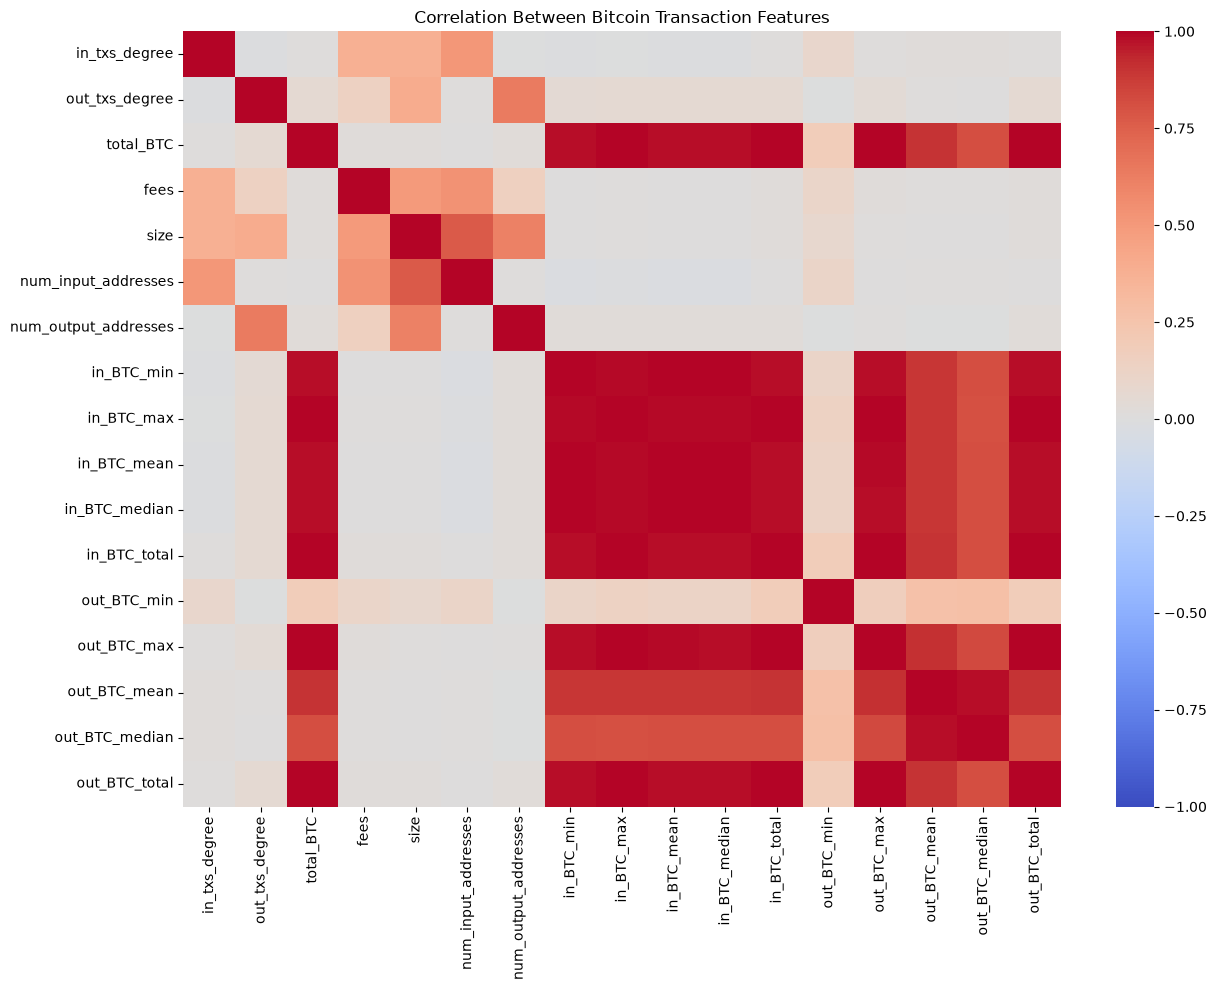

Highly correlated feature pairs (|r| >= 0.95):


,Feature 1,Feature 2,Correlation
4,total_BTC,in_BTC_total,1.000000
6,total_BTC,out_BTC_total,1.000000
26,in_BTC_total,out_BTC_total,1.000000
18,in_BTC_mean,in_BTC_median,0.999857
9,in_BTC_min,in_BTC_median,0.998839
8,in_BTC_min,in_BTC_mean,0.998701
27,out_BTC_max,out_BTC_total,0.996121
5,total_BTC,out_BTC_max,0.996121
25,in_BTC_total,out_BTC_max,0.996120
1,total_BTC,in_BTC_max,0.995457



Total highly correlated pairs: 29

Correlation analysis completed.


In [ ]:

# Step 0.4.17 - Analyze named feature correlations

# Select the 17 interpretable blockchain features
named_df = tx_features[named_features]

# Calculate Pearson correlation matrix
correlation_matrix = named_df.corr()

# Display correlation heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("Correlation Between Bitcoin Transaction Features")
plt.tight_layout()
plt.show()

# Identify highly correlated feature pairs
high_corr_pairs = []

for i in range(len(named_features)):
    for j in range(i + 1, len(named_features)):

        feature_1 = named_features[i]
        feature_2 = named_features[j]

        correlation = correlation_matrix.loc[
            feature_1, feature_2
        ]

        if abs(correlation) >= 0.95:
            high_corr_pairs.append({
                "Feature 1": feature_1,
                "Feature 2": feature_2,
                "Correlation": round(correlation, 6)
            })

high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=["Feature 1", "Feature 2", "Correlation"]
)

print("Highly correlated feature pairs (|r| >= 0.95):")
display(
    high_corr_df.sort_values(
        "Correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
)

print("\nTotal highly correlated pairs:",
      len(high_corr_df))

print("\nCorrelation analysis completed.")


In [ ]:

# Step 0.4.18 - Verify highly correlated BTC features

import numpy as np
import pandas as pd

btc_pairs = [
    ("total_BTC", "in_BTC_total"),
    ("total_BTC", "out_BTC_total"),
    ("in_BTC_total", "out_BTC_total")
]

comparison_results = []

for feature_1, feature_2 in btc_pairs:

    # Compare only rows where both values are present
    pair_data = tx_features[
        [feature_1, feature_2]
    ].dropna()

    values_1 = pair_data[feature_1].to_numpy()
    values_2 = pair_data[feature_2].to_numpy()

    absolute_difference = np.abs(
        values_1 - values_2
    )

    comparison_results.append({
        "Feature 1": feature_1,
        "Feature 2": feature_2,
        "Rows Compared": len(pair_data),
        "Exactly Equal Rows": int(
            np.sum(values_1 == values_2)
        ),
        "Near Equal Rows": int(
            np.sum(
                np.isclose(
                    values_1,
                    values_2,
                    rtol=1e-5,
                    atol=1e-8
                )
            )
        ),
        "Maximum Absolute Difference": float(
            absolute_difference.max()
        ),
        "Mean Absolute Difference": float(
            absolute_difference.mean()
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("BTC FEATURE REDUNDANCY ANALYSIS")
print("=" * 60)

display(comparison_df)

print("\nFeature comparison completed.")


BTC FEATURE REDUNDANCY ANALYSIS


,Feature 1,Feature 2,Rows Compared,Exactly Equal Rows,Near Equal Rows,Maximum Absolute Difference,Mean Absolute Difference
0,total_BTC,in_BTC_total,202804,67,24197,0.285129,0.000813
1,total_BTC,out_BTC_total,202804,202804,202804,0.000000,0.000000
2,in_BTC_total,out_BTC_total,202804,67,24195,0.285129,0.000813



Feature comparison completed.


In [ ]:

# Step 0.4.19 - Verify BTC input-output fee relationship

fee_df = tx_features[
    ["in_BTC_total", "out_BTC_total", "fees"]
].dropna().copy()

# Calculate fee from input-output difference
fee_df["calculated_fee"] = (
    fee_df["in_BTC_total"]
    - fee_df["out_BTC_total"]
)

# Compare calculated and recorded fees
fee_df["fee_error"] = (
    fee_df["calculated_fee"]
    - fee_df["fees"]
)

absolute_error = fee_df["fee_error"].abs()

# Check numerical agreement
matching_rows = np.isclose(
    fee_df["calculated_fee"],
    fee_df["fees"],
    rtol=1e-5,
    atol=1e-8
)

print("BITCOIN TRANSACTION FEE VALIDATION")
print("=" * 60)

print("Rows compared:", len(fee_df))
print("Matching rows:", matching_rows.sum())
print("Non-matching rows:", (~matching_rows).sum())

print("\nMaximum absolute error:", absolute_error.max())
print("Mean absolute error:", absolute_error.mean())

print("\nNegative calculated fees:",
      (fee_df["calculated_fee"] < -1e-8).sum())

print("\nSample fee comparisons:")
display(
    fee_df[
        [
            "in_BTC_total",
            "out_BTC_total",
            "fees",
            "calculated_fee",
            "fee_error"
        ]
    ].head(10)
)

print("\nFee relationship validation completed.")


BITCOIN TRANSACTION FEE VALIDATION
Rows compared: 202804
Matching rows: 202804
Non-matching rows: 0

Maximum absolute error: 1.4560064308735687e-12
Mean absolute error: 1.6572049353811079e-15

Negative calculated fees: 0

Sample fee comparisons:


,in_BTC_total,out_BTC_total,fees,calculated_fee,fee_error
0,0.534072,0.533972,0.000100,0.000100,-1.101820e-17
1,5.611878,5.611778,0.000100,0.000100,-2.330628e-16
2,0.456608,0.456508,0.000100,0.000100,-1.101820e-17
3,9.308900,9.308800,0.000100,0.000100,-2.330628e-16
4,852.164680,852.164680,0.000000,0.000000,0.000000e+00
5,0.427955,0.427855,0.000100,0.000100,-1.101820e-17
6,5.448193,5.448093,0.000100,0.000100,-2.330628e-16
7,63.864257,63.864107,0.000150,0.000150,-2.125958e-15
8,7.812598,7.812140,0.000458,0.000458,-8.944668e-17
9,0.199900,0.199800,0.000100,0.000100,-1.101820e-17



Fee relationship validation completed.


In [ ]:

# Step 0.4.20 - Analyze skewness of named blockchain features

# Select the 17 named numerical features
named_df = tx_features[named_features]

# Calculate skewness
skewness_values = named_df.skew()

# Create a summary table
skewness_df = pd.DataFrame({
    "Feature": skewness_values.index,
    "Skewness": skewness_values.values
})

# Classify the magnitude of skewness
def classify_skewness(value):
    if pd.isna(value):
        return "Undefined"
    elif abs(value) < 0.5:
        return "Approximately symmetric"
    elif abs(value) < 1:
        return "Moderately skewed"
    else:
        return "Highly skewed"

skewness_df["Distribution"] = (
    skewness_df["Skewness"].apply(classify_skewness)
)

# Sort by absolute skewness
skewness_df = skewness_df.sort_values(
    "Skewness",
    key=lambda x: x.abs(),
    ascending=False
)

print("TRANSACTION FEATURE SKEWNESS ANALYSIS")
print("=" * 60)

display(skewness_df.round(4))

print("\nHighly skewed features:",
      (skewness_df["Skewness"].abs() >= 1).sum())

print("\nApproximately symmetric features:",
      (skewness_df["Skewness"].abs() < 0.5).sum())

print("\nSkewness analysis completed.")


TRANSACTION FEATURE SKEWNESS ANALYSIS


,Feature,Skewness,Distribution
6,num_output_addresses,122.1700,Highly skewed
1,out_txs_degree,102.1337,Highly skewed
12,out_BTC_min,86.7715,Highly skewed
4,size,38.8616,Highly skewed
7,in_BTC_min,27.9736,Highly skewed
10,in_BTC_median,27.8908,Highly skewed
9,in_BTC_mean,27.8854,Highly skewed
8,in_BTC_max,27.2112,Highly skewed
2,total_BTC,26.7212,Highly skewed
16,out_BTC_total,26.7212,Highly skewed



Highly skewed features: 17

Approximately symmetric features: 0

Skewness analysis completed.


In [ ]:

# Step 0.4.21 - Check log transformation suitability

log_suitability = []

for feature in named_features:

    values = tx_features[feature]

    valid_values = values.dropna()

    log_suitability.append({
        "Feature": feature,
        "Negative Values": int((valid_values < 0).sum()),
        "Zero Values": int((valid_values == 0).sum()),
        "Zero Percentage": round(
            (valid_values == 0).mean() * 100, 2
        ),
        "Minimum Value": valid_values.min(),
        "Maximum Value": valid_values.max(),
        "Log1p Suitable": bool((valid_values >= 0).all())
    })

log_suitability_df = pd.DataFrame(log_suitability)

print("LOG TRANSFORMATION SUITABILITY ANALYSIS")
print("=" * 60)

display(log_suitability_df)

print("\nFeatures with negative values:",
      (log_suitability_df["Negative Values"] > 0).sum())

print("Features suitable for log1p:",
      log_suitability_df["Log1p Suitable"].sum())

print("\nLog suitability analysis completed.")


LOG TRANSFORMATION SUITABILITY ANALYSIS


,Feature,Negative Values,Zero Values,Zero Percentage,Minimum Value,Maximum Value,Log1p Suitable
0,in_txs_degree,0,54970,27.10,0.000000e+00,284.000000,True
1,out_txs_degree,0,36989,18.24,0.000000e+00,472.000000,True
2,total_BTC,0,0,0.00,6.000000e-06,11391.855937,True
3,fees,0,67,0.03,0.000000e+00,0.285129,True
4,size,0,0,0.00,1.880000e+02,445268.000000,True
5,num_input_addresses,0,0,0.00,1.000000e+00,656.000000,True
6,num_output_addresses,0,0,0.00,1.000000e+00,13107.000000,True
7,in_BTC_min,0,0,0.00,1.000000e-08,11391.856516,True
8,in_BTC_max,0,0,0.00,1.370000e-05,11391.856516,True
9,in_BTC_mean,0,0,0.00,1.355857e-05,11391.856516,True



Features with negative values: 0
Features suitable for log1p: 17

Log suitability analysis completed.


In [ ]:

# Step 0.4.22 - Analyze anonymized feature distributions

anonymized_features = local_features + aggregate_features

anonymized_df = tx_features[anonymized_features]

# Calculate statistics for each anonymized feature
anonymized_stats = pd.DataFrame({
    "Minimum": anonymized_df.min(),
    "Maximum": anonymized_df.max(),
    "Mean": anonymized_df.mean(),
    "Median": anonymized_df.median(),
    "Std Dev": anonymized_df.std(),
    "Skewness": anonymized_df.skew()
})

# Count features containing negative values
negative_features = (
    anonymized_stats["Minimum"] < 0
).sum()

# Count features containing only nonnegative values
nonnegative_features = (
    anonymized_stats["Minimum"] >= 0
).sum()

# Count highly skewed features
highly_skewed = (
    anonymized_stats["Skewness"].abs() >= 1
).sum()

print("ANONYMIZED FEATURE DISTRIBUTION ANALYSIS")
print("=" * 60)

print("Total anonymized features:",
      len(anonymized_features))

print("Features containing negative values:",
      negative_features)

print("Nonnegative features:",
      nonnegative_features)

print("Highly skewed features:",
      highly_skewed)

print("\nLocal feature statistics (first 10):")
display(
    anonymized_stats.loc[local_features].head(10).round(4)
)

print("\nAggregate feature statistics (first 10):")
display(
    anonymized_stats.loc[aggregate_features].head(10).round(4)
)

print("\nOverall minimum:",
      anonymized_df.min().min())

print("Overall maximum:",
      anonymized_df.max().max())

print("\nAnonymized feature analysis completed.")


ANONYMIZED FEATURE DISTRIBUTION ANALYSIS
Total anonymized features: 165
Features containing negative values: 165
Nonnegative features: 0
Highly skewed features: 102

Local feature statistics (first 10):


,Minimum,Maximum,Mean,Median,Std Dev,Skewness
Local_feature_1,-0.1730,71.6820,0.0,-0.1692,1.0,26.7815
Local_feature_2,-0.2106,73.5951,0.0,-0.1329,1.0,21.4771
Local_feature_3,-1.7564,2.6836,0.0,0.4636,1.0,-0.0642
Local_feature_4,-0.1220,49.0276,0.0,-0.1220,1.0,24.8741
Local_feature_5,-0.0637,260.0907,0.0,-0.0439,1.0,122.4573
Local_feature_6,-0.1130,54.5652,0.0,-0.1130,1.0,27.1560
Local_feature_7,-0.0616,113.4409,0.0,-0.0616,1.0,55.0430
Local_feature_8,-0.1636,73.3546,0.0,-0.1620,1.0,28.0371
Local_feature_9,-0.1695,72.3184,0.0,-0.1662,1.0,27.2727
Local_feature_10,-0.0497,189.1869,0.0,-0.0497,1.0,71.8759



Aggregate feature statistics (first 10):


,Minimum,Maximum,Mean,Median,Std Dev,Skewness
Aggregate_feature_1,-0.1711,48.9400,0.0,-0.1664,1.0,25.5664
Aggregate_feature_2,-0.2031,127.1137,0.0,-0.1932,1.0,29.3719
Aggregate_feature_3,-0.1168,175.0089,-0.0,-0.1168,1.0,56.1870
Aggregate_feature_4,-0.1934,47.8630,0.0,-0.1831,1.0,24.3942
Aggregate_feature_5,-2.5661,2.5368,-0.0,-0.0147,1.0,0.0368
Aggregate_feature_6,-2.5700,2.5323,0.0,-0.0188,1.0,0.0419
Aggregate_feature_7,-9.1768,1.6414,0.0,-0.0377,1.0,-0.1181
Aggregate_feature_8,-9.3431,1.6576,0.0,-0.0497,1.0,0.0086
Aggregate_feature_9,-0.0835,91.5358,0.0,-0.0835,1.0,24.2730
Aggregate_feature_10,-9.3137,1.6571,0.0,-0.0456,1.0,-0.0032



Overall minimum: -13.09335839600819
Overall maximum: 289.20438805244663

Anonymized feature analysis completed.


In [ ]:

# Step 0.4.23 - Verify anonymized feature standardization

# Calculate statistics across all 165 anonymized features
feature_means = anonymized_df.mean()
feature_stds = anonymized_df.std(ddof=0)

# Use numerical tolerances for approximate standardization
mean_tolerance = 1e-3
std_tolerance = 1e-3

near_zero_mean = feature_means.abs() < mean_tolerance
near_unit_std = (feature_stds - 1).abs() < std_tolerance

standardized_features = near_zero_mean & near_unit_std

print("ANONYMIZED FEATURE STANDARDIZATION CHECK")
print("=" * 60)

print("Total features:", len(anonymized_features))

print("Features with mean approximately 0:",
      int(near_zero_mean.sum()))

print("Features with standard deviation approximately 1:",
      int(near_unit_std.sum()))

print("Features satisfying both conditions:",
      int(standardized_features.sum()))

print("\nLargest absolute feature mean:",
      feature_means.abs().max())

print("Largest deviation from unit standard deviation:",
      (feature_stds - 1).abs().max())

print("\nFeatures failing standardization check:")

failed_features = standardized_features[
    ~standardized_features
].index.tolist()

print(failed_features)

print("\nStandardization verification completed.")


ANONYMIZED FEATURE STANDARDIZATION CHECK
Total features: 165
Features with mean approximately 0: 165
Features with standard deviation approximately 1: 165
Features satisfying both conditions: 165

Largest absolute feature mean: 3.142206469326254e-15
Largest deviation from unit standard deviation: 4.440892098500626e-16

Features failing standardization check:
[]

Standardization verification completed.


In [ ]:

# Step 0.4.24 - Detect exact duplicate feature columns

from collections import defaultdict
import hashlib

# All 182 candidate numerical features
feature_data = tx_features[model_feature_columns]

# Group columns by their content hashes
hash_groups = defaultdict(list)

for column in feature_data.columns:

    # Include values, missing-value positions, and row order
    column_hashes = pd.util.hash_pandas_object(
        feature_data[column],
        index=False
    ).to_numpy(dtype="uint64")

    fingerprint = hashlib.sha256(
        column_hashes.tobytes()
    ).hexdigest()

    hash_groups[fingerprint].append(column)

# Verify candidate duplicates using exact equality
duplicate_groups = []

for columns in hash_groups.values():

    if len(columns) < 2:
        continue

    verified_groups = []

    for column in columns:

        placed = False

        for group in verified_groups:
            if feature_data[column].equals(
                feature_data[group[0]]
            ):
                group.append(column)
                placed = True
                break

        if not placed:
            verified_groups.append([column])

    duplicate_groups.extend(
        group for group in verified_groups
        if len(group) > 1
    )

print("EXACT DUPLICATE FEATURE ANALYSIS")
print("=" * 60)

print("Candidate numerical features:",
      len(model_feature_columns))

print("Duplicate feature groups:",
      len(duplicate_groups))

print("Redundant feature columns:",
      sum(len(group) - 1 for group in duplicate_groups))

print("\nVerified duplicate groups:")

for i, group in enumerate(duplicate_groups, start=1):
    print(f"Group {i}: {group}")

print("\nDuplicate feature analysis completed.")



EXACT DUPLICATE FEATURE ANALYSIS
Candidate numerical features: 182
Duplicate feature groups: 1
Redundant feature columns: 1

Verified duplicate groups:
Group 1: ['total_BTC', 'out_BTC_total']

Duplicate feature analysis completed.


In [23]:

# Step 0.4.25 - Build initial transaction feature inventory

excluded_model_features = [
    "out_BTC_total",
    "in_BTC_total"
]

initial_model_features = [
    col for col in model_feature_columns
    if col not in excluded_model_features
]

feature_inventory = pd.DataFrame({
    "Feature": tx_features.columns
})

def assign_feature_group(feature):
    if feature in identifier_columns:
        return "Identifier"
    elif feature in temporal_columns:
        return "Temporal"
    elif feature in local_features:
        return "Local"
    elif feature in aggregate_features:
        return "Aggregate"
    else:
        return "Named blockchain"

feature_inventory["Group"] = (
    feature_inventory["Feature"].apply(assign_feature_group)
)

feature_inventory["Model Input"] = (
    feature_inventory["Feature"].isin(initial_model_features)
)

feature_inventory["Reason"] = "Included as candidate feature"

feature_inventory.loc[
    feature_inventory["Group"] == "Identifier",
    "Reason"
] = "Excluded: transaction identifier"

feature_inventory.loc[
    feature_inventory["Group"] == "Temporal",
    "Reason"
] = "Reserved for temporal analysis"

feature_inventory.loc[
    feature_inventory["Feature"] == "out_BTC_total",
    "Reason"
] = "Excluded: exact duplicate of total_BTC"

feature_inventory.loc[
    feature_inventory["Feature"] == "in_BTC_total",
    "Reason"
] = "Excluded: derivable from total_BTC and fees"

print("INITIAL TRANSACTION FEATURE INVENTORY")
print("=" * 60)

print("Total dataset columns:", len(feature_inventory))
print("Initial model features:", len(initial_model_features))
print("Excluded dataset columns:",
      (~feature_inventory["Model Input"]).sum())

print("\nFeature groups:")
display(
    feature_inventory.groupby("Group").agg(
        Total_Columns=("Feature", "count"),
        Model_Inputs=("Model Input", "sum")
    )
)

print("\nExcluded columns:")
display(
    feature_inventory.loc[
        ~feature_inventory["Model Input"],
        ["Feature", "Group", "Reason"]
    ]
)

print("\nFeature inventory validation:")
print("All dataset columns accounted for:",
      len(feature_inventory) == tx_features.shape[1])

print("Model features unique:",
      len(initial_model_features) == len(set(initial_model_features)))

print("\nFeature inventory completed.")


INITIAL TRANSACTION FEATURE INVENTORY
Total dataset columns: 184
Initial model features: 180
Excluded dataset columns: 4

Feature groups:


,Total_Columns,Model_Inputs
Group,,
Aggregate,72,72
Identifier,1,0
Local,93,93
Named blockchain,17,15
Temporal,1,0



Excluded columns:


,Feature,Group,Reason
0,txId,Identifier,Excluded: transaction identifier
1,Time step,Temporal,Reserved for temporal analysis
178,in_BTC_total,Named blockchain,Excluded: derivable from total_BTC and fees
183,out_BTC_total,Named blockchain,Excluded: exact duplicate of total_BTC



Feature inventory validation:
All dataset columns accounted for: True
Model features unique: True

Feature inventory completed.


TRANSACTION TEMPORAL DISTRIBUTION
Total transactions: 203769
Unique time steps: 49

First time step: 1
Last time step: 49

Minimum transactions in a time step: 1089
Maximum transactions in a time step: 7880

Transaction counts by time step:


,Time step,Transaction Count
0,1,7880
1,2,4544
2,3,6621
3,4,5693
4,5,6803
5,6,4328
6,7,6048
7,8,4457
8,9,4996
9,10,6727


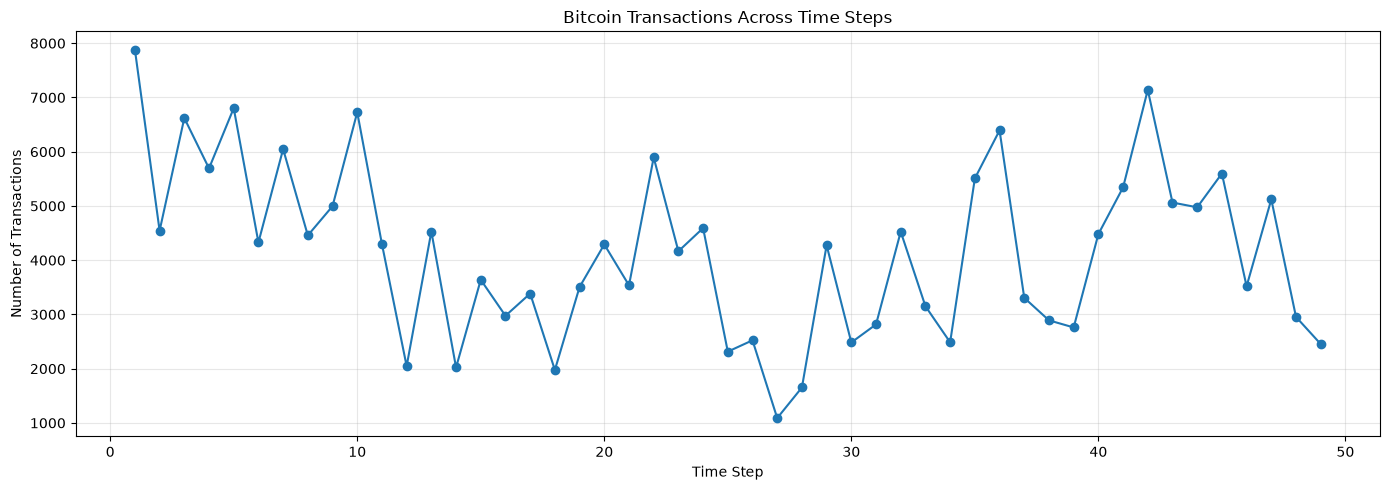


Temporal distribution analysis completed.


In [ ]:

# Step 0.4.26 - Analyze transaction distribution over time

# Count transactions at each time step
time_step_counts = (
    tx_features["Time step"]
    .value_counts()
    .sort_index()
)

print("TRANSACTION TEMPORAL DISTRIBUTION")
print("=" * 60)

print("Total transactions:", len(tx_features))
print("Unique time steps:", time_step_counts.size)

print("\nFirst time step:", time_step_counts.index.min())
print("Last time step:", time_step_counts.index.max())

print("\nMinimum transactions in a time step:",
      time_step_counts.min())

print("Maximum transactions in a time step:",
      time_step_counts.max())

print("\nTransaction counts by time step:")

display(
    time_step_counts
    .rename_axis("Time step")
    .reset_index(name="Transaction Count")
)

# Plot temporal transaction distribution
plt.figure(figsize=(14, 5))

plt.plot(
    time_step_counts.index,
    time_step_counts.values,
    marker="o",
    linewidth=1.5
)

plt.title("Bitcoin Transactions Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTemporal distribution analysis completed.")


In [ ]:

# Step 0.4.27 - Evaluate chronological split sizes

# Define proposed chronological boundaries
train_mask = tx_features["Time step"].between(1, 30)
val_mask = tx_features["Time step"].between(31, 39)
test_mask = tx_features["Time step"].between(40, 49)

# Calculate sample counts
total_rows = len(tx_features)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Start Step": [1, 31, 40],
    "End Step": [30, 39, 49],
    "Transactions": [
        int(train_mask.sum()),
        int(val_mask.sum()),
        int(test_mask.sum())
    ]
})

split_summary["Percentage"] = (
    split_summary["Transactions"]
    / total_rows * 100
).round(2)

print("CHRONOLOGICAL SPLIT ANALYSIS")
print("=" * 60)

display(split_summary)

print("\nTotal transactions:", total_rows)
print("Assigned transactions:",
      split_summary["Transactions"].sum())

# Verify that every transaction belongs to one split
assignment_count = (
    train_mask.astype(int)
    + val_mask.astype(int)
    + test_mask.astype(int)
)

print("\nEvery transaction assigned exactly once:",
      bool((assignment_count == 1).all()))

print("Train before validation:",
      bool(
          tx_features.loc[train_mask, "Time step"].max()
          < tx_features.loc[val_mask, "Time step"].min()
      ))

print("Validation before test:",
      bool(
          tx_features.loc[val_mask, "Time step"].max()
          < tx_features.loc[test_mask, "Time step"].min()
      ))

print("\nChronological split analysis completed.")


CHRONOLOGICAL SPLIT ANALYSIS


,Split,Start Step,End Step,Transactions,Percentage
0,Train,1,30,123287,60.50
1,Validation,31,39,33835,16.60
2,Test,40,49,46647,22.89



Total transactions: 203769
Assigned transactions: 203769

Every transaction assigned exactly once: True
Train before validation: True
Validation before test: True

Chronological split analysis completed.


In [45]:

# Step 0.4.28 - Class distribution across chronological splits

# Load transaction labels using string IDs
tx_labels = pd.read_csv(
    DATA_DIR / "txs_classes.csv",
    dtype={"txId": "string"}
)

# Prepare transaction identifiers and time steps
temporal_info = tx_features[
    ["txId", "Time step"]
].copy()

temporal_info["txId"] = (
    temporal_info["txId"].astype("string")
)

# Join class labels with transaction time steps
temporal_labels = temporal_info.merge(
    tx_labels,
    on="txId",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Assign chronological split names
temporal_labels["Split"] = np.select(
    [
        temporal_labels["Time step"].between(1, 30),
        temporal_labels["Time step"].between(31, 39),
        temporal_labels["Time step"].between(40, 49)
    ],
    ["Train", "Validation", "Test"],
    default="Unassigned"
)

# Normalize class values for consistent grouping
temporal_labels["class"] = (
    temporal_labels["class"].astype("string")
)

# Count transactions by split and class
class_distribution = pd.crosstab(
    temporal_labels["Split"],
    temporal_labels["class"]
)

class_distribution = class_distribution.reindex(
    index=["Train", "Validation", "Test"],
    columns=["1", "2", "3"],
    fill_value=0
)

class_distribution.columns = [
    "Illicit (1)",
    "Licit (2)",
    "Unknown (3)"
]

class_distribution["Total"] = (
    class_distribution.sum(axis=1)
)

class_distribution["Known Labels"] = (
    class_distribution["Illicit (1)"]
    + class_distribution["Licit (2)"]
)

class_distribution["Illicit % of Known"] = (
    100
    * class_distribution["Illicit (1)"]
    / class_distribution["Known Labels"].replace(0, np.nan)
).round(2)

print("CHRONOLOGICAL CLASS DISTRIBUTION")
print("=" * 60)

display(class_distribution)

print("\nUnmatched transaction IDs:",
      int((temporal_labels["_merge"] != "both").sum()))

print("Unassigned transactions:",
      int((temporal_labels["Split"] == "Unassigned").sum()))

print("\nTotal transactions:",
      len(temporal_labels))

print("\nChronological class analysis completed.")


CHRONOLOGICAL CLASS DISTRIBUTION


,Illicit (1),Licit (2),Unknown (3),Total,Known Labels,Illicit % of Known
Split,,,,,,
Train,2954,23951,96382,123287,26905,10.98
Validation,955,7520,25360,33835,8475,11.27
Test,636,10548,35463,46647,11184,5.69



Unmatched transaction IDs: 0
Unassigned transactions: 0

Total transactions: 203769

Chronological class analysis completed.


TIME-STEP CLASS DISTRIBUTION ANALYSIS


,Illicit,Licit,Unknown,Known Labels,Illicit % of Known
Time step,,,,,
1,17,2130,5733,2147,0.79
2,18,1099,3427,1117,1.61
3,11,1268,5342,1279,0.86
4,30,1410,4253,1440,2.08
5,8,1874,4921,1882,0.43
6,5,480,3843,485,1.03
7,102,1101,4845,1203,8.48
8,67,1098,3292,1165,5.75
9,248,530,4218,778,31.88



Time steps with zero illicit transactions: []

Time steps with zero known labels: []

Maximum illicit transactions in one time step: 342
Minimum illicit transactions in one time step: 2


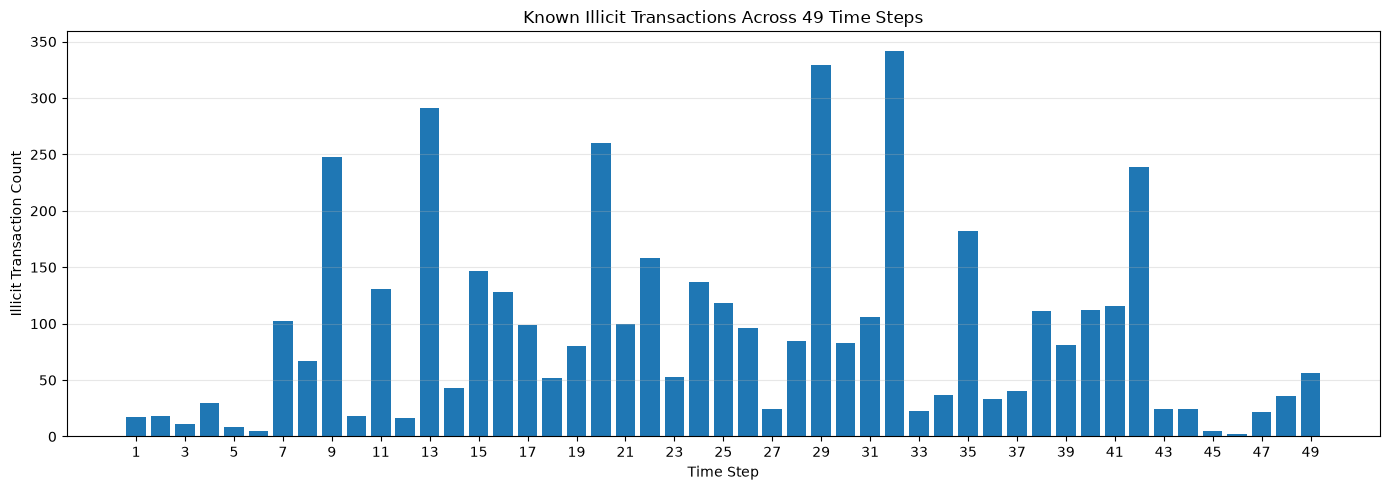


Time-step class analysis completed.


In [ ]:

# Step 0.4.29 - Analyze class distribution by time step

# Count classes for every time step
time_class_distribution = pd.crosstab(
    temporal_labels["Time step"],
    temporal_labels["class"]
)

# Ensure all expected classes are represented
time_class_distribution = time_class_distribution.reindex(
    index=range(1, 50),
    columns=["1", "2", "3"],
    fill_value=0
)

time_class_distribution.columns = [
    "Illicit",
    "Licit",
    "Unknown"
]

# Calculate known-label totals
time_class_distribution["Known Labels"] = (
    time_class_distribution["Illicit"]
    + time_class_distribution["Licit"]
)

# Calculate illicit percentage among known labels
time_class_distribution["Illicit % of Known"] = (
    100
    * time_class_distribution["Illicit"]
    / time_class_distribution["Known Labels"].replace(0, np.nan)
).round(2)

print("TIME-STEP CLASS DISTRIBUTION ANALYSIS")
print("=" * 60)

display(time_class_distribution)

print("\nTime steps with zero illicit transactions:",
      time_class_distribution.index[
          time_class_distribution["Illicit"] == 0
      ].tolist())

print("\nTime steps with zero known labels:",
      time_class_distribution.index[
          time_class_distribution["Known Labels"] == 0
      ].tolist())

print("\nMaximum illicit transactions in one time step:",
      time_class_distribution["Illicit"].max())

print("Minimum illicit transactions in one time step:",
      time_class_distribution["Illicit"].min())

# Visualize illicit transaction counts
plt.figure(figsize=(14, 5))

plt.bar(
    time_class_distribution.index,
    time_class_distribution["Illicit"]
)

plt.title("Known Illicit Transactions Across 49 Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Illicit Transaction Count")
plt.xticks(range(1, 50, 2))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTime-step class analysis completed.")


In [ ]:

# Step 0.4.30 - Missing values across chronological splits

# Identify rows with missing candidate model features
missing_row_mask = (
    tx_features[initial_model_features]
    .isna()
    .any(axis=1)
)

# Assign split labels using time steps
split_labels = np.select(
    [
        tx_features["Time step"].between(1, 30),
        tx_features["Time step"].between(31, 39),
        tx_features["Time step"].between(40, 49)
    ],
    ["Train", "Validation", "Test"],
    default="Unassigned"
)

# Create missingness summary
missing_split_df = pd.DataFrame({
    "Split": split_labels,
    "Has Missing Features": missing_row_mask
})

missing_summary = (
    missing_split_df
    .groupby("Split")
    .agg(
        Total_Transactions=("Has Missing Features", "size"),
        Affected_Transactions=("Has Missing Features", "sum")
    )
    .reindex(["Train", "Validation", "Test"])
)

missing_summary["Missing Row %"] = (
    100
    * missing_summary["Affected_Transactions"]
    / missing_summary["Total_Transactions"]
).round(3)

print("MISSING VALUES BY CHRONOLOGICAL SPLIT")
print("=" * 60)

display(missing_summary)

print("\nTotal affected transactions:",
      int(missing_row_mask.sum()))

print("\nMissingness analysis completed.")


MISSING VALUES BY CHRONOLOGICAL SPLIT


,Total_Transactions,Affected_Transactions,Missing Row %
Split,,,
Train,123287,295,0.239
Validation,33835,366,1.082
Test,46647,304,0.652



Total affected transactions: 965

Missingness analysis completed.


In [25]:

# Step 0.4.31 - Verify preprocessing feature configurations

# Baseline A: anonymized features only
baseline_a_features = (
    local_features + aggregate_features
)

# Baseline B: anonymized + selected named features
baseline_b_features = initial_model_features.copy()

# Named features retained in Baseline B
selected_named_features = [
    feature for feature in named_features
    if feature not in excluded_model_features
]

# Check missing values in each configuration
baseline_a_missing = int(
    tx_features[baseline_a_features].isna().sum().sum()
)

baseline_b_missing = int(
    tx_features[baseline_b_features].isna().sum().sum()
)

print("PREPROCESSING FEATURE CONFIGURATION CHECK")
print("=" * 60)

print("\nBASELINE A - ANONYMIZED FEATURES")
print("Feature count:", len(baseline_a_features))
print("Missing cells:", baseline_a_missing)

print("\nBASELINE B - COMBINED FEATURES")
print("Feature count:", len(baseline_b_features))
print("Named features:", len(selected_named_features))
print("Missing cells:", baseline_b_missing)

print("\nSELECTED NAMED FEATURES:")
for feature in selected_named_features:
    print("-", feature)

print("\nVALIDATION CHECKS")
print("Baseline A contains 165 features:",
      len(baseline_a_features) == 165)

print("Baseline B contains 180 features:",
      len(baseline_b_features) == 180)

print("Baseline A has no missing cells:",
      baseline_a_missing == 0)

print("All Baseline A features are in Baseline B:",
      set(baseline_a_features).issubset(
          set(baseline_b_features)
      ))

print("Excluded BTC features absent from Baseline B:",
      all(
          feature not in baseline_b_features
          for feature in excluded_model_features
      ))

print("\nFeature configuration verification completed.")


PREPROCESSING FEATURE CONFIGURATION CHECK

BASELINE A - ANONYMIZED FEATURES
Feature count: 165
Missing cells: 0

BASELINE B - COMBINED FEATURES
Feature count: 180
Named features: 15
Missing cells: 14475

SELECTED NAMED FEATURES:
- in_txs_degree
- out_txs_degree
- total_BTC
- fees
- size
- num_input_addresses
- num_output_addresses
- in_BTC_min
- in_BTC_max
- in_BTC_mean
- in_BTC_median
- out_BTC_min
- out_BTC_max
- out_BTC_mean
- out_BTC_median

VALIDATION CHECKS
Baseline A contains 165 features: True
Baseline B contains 180 features: True
Baseline A has no missing cells: True
All Baseline A features are in Baseline B: True
Excluded BTC features absent from Baseline B: True

Feature configuration verification completed.


In [27]:

# Step 0.5.1 - Create chronological feature datasets

# Define chronological split masks
train_mask = tx_features["Time step"].between(1, 30)
val_mask = tx_features["Time step"].between(31, 39)
test_mask = tx_features["Time step"].between(40, 49)

# Baseline A: 165 anonymized features
X_train_a = tx_features.loc[
    train_mask, baseline_a_features
].copy()

X_val_a = tx_features.loc[
    val_mask, baseline_a_features
].copy()

X_test_a = tx_features.loc[
    test_mask, baseline_a_features
].copy()

# Baseline B: 180 combined features
X_train_b = tx_features.loc[
    train_mask, baseline_b_features
].copy()

X_val_b = tx_features.loc[
    val_mask, baseline_b_features
].copy()

X_test_b = tx_features.loc[
    test_mask, baseline_b_features
].copy()

print("CHRONOLOGICAL FEATURE DATASETS")
print("=" * 60)

split_shapes = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Baseline A Shape": [
        str(X_train_a.shape),
        str(X_val_a.shape),
        str(X_test_a.shape)
    ],
    "Baseline B Shape": [
        str(X_train_b.shape),
        str(X_val_b.shape),
        str(X_test_b.shape)
    ]
})

display(split_shapes)

print("\nVALIDATION CHECKS")

print(
    "Training rows correct:",
    len(X_train_a) == 123287
)

print(
    "Validation rows correct:",
    len(X_val_a) == 33835
)

print(
    "Testing rows correct:",
    len(X_test_a) == 46647
)

print(
    "Baseline A and B indices match:",
    X_train_a.index.equals(X_train_b.index)
    and X_val_a.index.equals(X_val_b.index)
    and X_test_a.index.equals(X_test_b.index)
)

print(
    "No overlapping split indices:",
    len(
        set(X_train_a.index)
        & set(X_val_a.index)
    ) == 0
    and len(
        set(X_train_a.index)
        & set(X_test_a.index)
    ) == 0
    and len(
        set(X_val_a.index)
        & set(X_test_a.index)
    ) == 0
)

print("\nChronological feature datasets created.")



CHRONOLOGICAL FEATURE DATASETS


,Split,Baseline A Shape,Baseline B Shape
0,Train,"(123287, 165)","(123287, 180)"
1,Validation,"(33835, 165)","(33835, 180)"
2,Test,"(46647, 165)","(46647, 180)"



VALIDATION CHECKS
Training rows correct: True
Validation rows correct: True
Testing rows correct: True
Baseline A and B indices match: True
No overlapping split indices: True

Chronological feature datasets created.


In [39]:

# Step 0.5.2 - Create missingness indicators for Baseline B

# Create independent working copies
X_train_b_work = X_train_b.copy()
X_val_b_work = X_val_b.copy()
X_test_b_work = X_test_b.copy()

# Add a binary missingness indicator to each split
for dataset in [
    X_train_b_work,
    X_val_b_work,
    X_test_b_work
]:
    dataset["named_features_missing"] = (
        dataset[selected_named_features]
        .isna()
        .any(axis=1)
        .astype("int8")
    )

# Summarize missingness indicators
missing_indicator_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Transactions": [
        len(X_train_b_work),
        len(X_val_b_work),
        len(X_test_b_work)
    ],
    "Missing Indicator = 1": [
        int(X_train_b_work["named_features_missing"].sum()),
        int(X_val_b_work["named_features_missing"].sum()),
        int(X_test_b_work["named_features_missing"].sum())
    ],
    "Feature Count": [
        X_train_b_work.shape[1],
        X_val_b_work.shape[1],
        X_test_b_work.shape[1]
    ]
})

print("BASELINE B MISSINGNESS INDICATOR")
print("=" * 60)

display(missing_indicator_summary)

print("\nVALIDATION CHECKS")

print(
    "Training indicator count correct:",
    X_train_b_work["named_features_missing"].sum() == 295
)

print(
    "Validation indicator count correct:",
    X_val_b_work["named_features_missing"].sum() == 366
)

print(
    "Testing indicator count correct:",
    X_test_b_work["named_features_missing"].sum() == 304
)

print(
    "All working datasets contain 181 features:",
    all(
        dataset.shape[1] == 181
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Original Baseline B datasets unchanged:",
    all(
        "named_features_missing" not in dataset.columns
        for dataset in [
            X_train_b,
            X_val_b,
            X_test_b
        ]
    )
)

print("\nMissingness indicators created successfully.")


BASELINE B MISSINGNESS INDICATOR


,Split,Transactions,Missing Indicator = 1,Feature Count
0,Train,123287,295,181
1,Validation,33835,366,181
2,Test,46647,304,181



VALIDATION CHECKS
Training indicator count correct: True
Validation indicator count correct: True
Testing indicator count correct: True
All working datasets contain 181 features: True
Original Baseline B datasets unchanged: True

Missingness indicators created successfully.


In [ ]:

# Step 0.5.3 - Training-only median imputation

from sklearn.impute import SimpleImputer

# Initialize the imputer
named_feature_imputer = SimpleImputer(
    strategy="median"
)

# Fit ONLY on training data
named_feature_imputer.fit(
    X_train_b_work[selected_named_features]
)

# Transform all three chronological splits
for dataset in [
    X_train_b_work,
    X_val_b_work,
    X_test_b_work
]:
    dataset[selected_named_features] = (
        named_feature_imputer.transform(
            dataset[selected_named_features]
        )
    )

# Display learned training medians
training_medians = pd.DataFrame({
    "Feature": selected_named_features,
    "Training Median": named_feature_imputer.statistics_
})

print("TRAINING-ONLY MEDIAN IMPUTATION")
print("=" * 60)

display(training_medians)

print("\nREMAINING MISSING VALUES")

for name, dataset in [
    ("Train", X_train_b_work),
    ("Validation", X_val_b_work),
    ("Test", X_test_b_work)
]:
    print(
        f"{name}:",
        int(dataset.isna().sum().sum())
    )

print("\nVALIDATION CHECKS")

print(
    "Imputer learned 15 medians:",
    len(named_feature_imputer.statistics_) == 15
)

print(
    "No missing values remain:",
    all(
        not dataset.isna().any().any()
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Feature counts remain 181:",
    all(
        dataset.shape[1] == 181
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Missingness indicators preserved:",
    [
        int(dataset["named_features_missing"].sum())
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    ] == [295, 366, 304]
)

print(
    "Original Baseline B still contains missing values:",
    X_train_b[selected_named_features].isna().any().any()
)

print("\nMedian imputation completed.")


ModuleNotFoundError: No module named 'sklearn'

In [ ]:
%pip install scikit-learn

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ----------- ---------------------------- 2.4/8.3 MB 16.8 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.3 MB 15.9 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.3 MB 9.9 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.3 MB 8.6 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.3 MB 7.2 MB/s eta 0:00:01
   ------------------------------------- -- 7.9/8.3 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 6.0 MB/s  0:00:01
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------

In [ ]:

# Step 0.5.3 - Training-only median imputation

from sklearn.impute import SimpleImputer

# Initialize the imputer
named_feature_imputer = SimpleImputer(
    strategy="median"
)

# Fit ONLY on training data
named_feature_imputer.fit(
    X_train_b_work[selected_named_features]
)

# Transform all three chronological splits
for dataset in [
    X_train_b_work,
    X_val_b_work,
    X_test_b_work
]:
    dataset[selected_named_features] = (
        named_feature_imputer.transform(
            dataset[selected_named_features]
        )
    )

# Display learned training medians
training_medians = pd.DataFrame({
    "Feature": selected_named_features,
    "Training Median": named_feature_imputer.statistics_
})

print("TRAINING-ONLY MEDIAN IMPUTATION")
print("=" * 60)

display(training_medians)

print("\nREMAINING MISSING VALUES")

for name, dataset in [
    ("Train", X_train_b_work),
    ("Validation", X_val_b_work),
    ("Test", X_test_b_work)
]:
    print(
        f"{name}:",
        int(dataset.isna().sum().sum())
    )

print("\nVALIDATION CHECKS")

print(
    "Imputer learned 15 medians:",
    len(named_feature_imputer.statistics_) == 15
)

print(
    "No missing values remain:",
    all(
        not dataset.isna().any().any()
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Feature counts remain 181:",
    all(
        dataset.shape[1] == 181
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Missingness indicators preserved:",
    [
        int(dataset["named_features_missing"].sum())
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    ] == [295, 366, 304]
)

print(
    "Original Baseline B still contains missing values:",
    X_train_b[selected_named_features].isna().any().any()
)

print("\nMedian imputation completed.")


TRAINING-ONLY MEDIAN IMPUTATION


,Feature,Training Median
0,in_txs_degree,1.000000
1,out_txs_degree,1.000000
2,total_BTC,0.699832
3,fees,0.000156
4,size,258.000000
5,num_input_addresses,1.000000
6,num_output_addresses,2.000000
7,in_BTC_min,0.279596
8,in_BTC_max,0.609955
9,in_BTC_mean,0.472194



REMAINING MISSING VALUES
Train: 0
Validation: 0
Test: 0

VALIDATION CHECKS
Imputer learned 15 medians: True
No missing values remain: True
Feature counts remain 181: True
Missingness indicators preserved: True
Original Baseline B still contains missing values: True

Median imputation completed.


In [ ]:

# Step 0.5.4 - Log transformation of named blockchain features

# Verify that log1p is safe for all selected features
for name, dataset in [
    ("Train", X_train_b_work),
    ("Validation", X_val_b_work),
    ("Test", X_test_b_work)
]:
    minimum_value = dataset[
        selected_named_features
    ].min().min()

    print(f"{name} minimum named-feature value: {minimum_value}")

    assert minimum_value >= 0, (
        f"Negative values found in {name} named features!"
    )

# Preserve pre-transformation values for comparison
named_before_log = X_train_b_work[
    selected_named_features
].copy()

# Apply log1p only to named blockchain features
for dataset in [
    X_train_b_work,
    X_val_b_work,
    X_test_b_work
]:
    dataset[selected_named_features] = np.log1p(
        dataset[selected_named_features]
    )

# Compare skewness before and after transformation
skew_comparison = pd.DataFrame({
    "Feature": selected_named_features,
    "Skew Before": named_before_log.skew().values,
    "Skew After": X_train_b_work[
        selected_named_features
    ].skew().values
})

skew_comparison["Skew Reduction"] = (
    skew_comparison["Skew Before"].abs()
    - skew_comparison["Skew After"].abs()
)

print("\nLOG TRANSFORMATION ANALYSIS")
print("=" * 60)

display(skew_comparison.round(3))

print("\nVALIDATION CHECKS")

print(
    "No missing values after transformation:",
    all(
        not dataset.isna().any().any()
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Feature counts remain 181:",
    all(
        dataset.shape[1] == 181
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Missingness indicators preserved:",
    [
        int(dataset["named_features_missing"].sum())
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    ] == [295, 366, 304]
)

print(
    "Original Baseline B unchanged:",
    X_train_b[selected_named_features].isna().any().any()
)

print("\nLog transformation completed.")


Train minimum named-feature value: 0.0
Validation minimum named-feature value: 0.0
Test minimum named-feature value: 0.0

LOG TRANSFORMATION ANALYSIS


,Feature,Skew Before,Skew After,Skew Reduction
0,in_txs_degree,30.753,1.677,29.076
1,out_txs_degree,129.729,0.339,129.390
2,total_BTC,19.842,1.465,18.377
3,fees,33.482,32.631,0.851
4,size,45.142,2.868,42.274
5,num_input_addresses,26.253,3.757,22.496
6,num_output_addresses,120.098,4.679,115.419
7,in_BTC_min,20.404,1.654,18.750
8,in_BTC_max,20.103,1.519,18.584
9,in_BTC_mean,20.376,1.595,18.781



VALIDATION CHECKS
No missing values after transformation: True
Feature counts remain 181: True
Missingness indicators preserved: True
Original Baseline B unchanged: True

Log transformation completed.


In [ ]:

# Step 0.5.5 - Evaluate log transformation effectiveness

print("LOG TRANSFORMATION EFFECTIVENESS")
print("=" * 60)

# Display the complete skewness comparison
display(skew_comparison.round(3))

# Count features with improved absolute skewness
improved_features = (
    skew_comparison["Skew Reduction"] > 0
).sum()

worsened_features = (
    skew_comparison["Skew Reduction"] < 0
).sum()

unchanged_features = (
    skew_comparison["Skew Reduction"] == 0
).sum()

print("\nSUMMARY")
print("Total named features:", len(skew_comparison))
print("Features with reduced absolute skewness:",
      int(improved_features))
print("Features with increased absolute skewness:",
      int(worsened_features))
print("Features with unchanged absolute skewness:",
      int(unchanged_features))

print("\nAverage absolute skewness before:",
      round(skew_comparison["Skew Before"].abs().mean(), 3))

print("Average absolute skewness after:",
      round(skew_comparison["Skew After"].abs().mean(), 3))

print("\nLog transformation evaluation completed.")


LOG TRANSFORMATION EFFECTIVENESS


,Feature,Skew Before,Skew After,Skew Reduction
0,in_txs_degree,30.753,1.677,29.076
1,out_txs_degree,129.729,0.339,129.390
2,total_BTC,19.842,1.465,18.377
3,fees,33.482,32.631,0.851
4,size,45.142,2.868,42.274
5,num_input_addresses,26.253,3.757,22.496
6,num_output_addresses,120.098,4.679,115.419
7,in_BTC_min,20.404,1.654,18.750
8,in_BTC_max,20.103,1.519,18.584
9,in_BTC_mean,20.376,1.595,18.781



SUMMARY
Total named features: 15
Features with reduced absolute skewness: 15
Features with increased absolute skewness: 0
Features with unchanged absolute skewness: 0

Average absolute skewness before: 40.149
Average absolute skewness after: 4.27

Log transformation evaluation completed.


In [ ]:

# Step 0.5.6 - Training-only scaling of named features

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
named_feature_scaler = StandardScaler()

# Fit ONLY on the log-transformed training features
named_feature_scaler.fit(
    X_train_b_work[selected_named_features]
)

# Apply the same fitted scaler to all three splits
for dataset in [
    X_train_b_work,
    X_val_b_work,
    X_test_b_work
]:
    dataset[selected_named_features] = (
        named_feature_scaler.transform(
            dataset[selected_named_features]
        )
    )

# Inspect training feature statistics
scaled_feature_summary = pd.DataFrame({
    "Feature": selected_named_features,
    "Mean After Scaling": (
        X_train_b_work[selected_named_features]
        .mean()
        .values
    ),
    "Std After Scaling": (
        X_train_b_work[selected_named_features]
        .std(ddof=0)
        .values
    )
})

print("TRAINING-ONLY FEATURE SCALING")
print("=" * 60)

display(scaled_feature_summary.round(6))

print("\nVALIDATION CHECKS")

print(
    "Scaler learned 15 feature means:",
    len(named_feature_scaler.mean_) == 15
)

print(
    "Training means approximately zero:",
    np.allclose(
        X_train_b_work[selected_named_features].mean(),
        0,
        atol=1e-10
    )
)

print(
    "Training standard deviations approximately one:",
    np.allclose(
        X_train_b_work[selected_named_features].std(ddof=0),
        1,
        atol=1e-10
    )
)

print(
    "No missing values:",
    all(
        not dataset.isna().any().any()
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Feature counts remain 181:",
    all(
        dataset.shape[1] == 181
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print(
    "Missingness indicators remain binary:",
    all(
        dataset["named_features_missing"]
        .isin([0, 1])
        .all()
        for dataset in [
            X_train_b_work,
            X_val_b_work,
            X_test_b_work
        ]
    )
)

print("\nFeature scaling completed.")


TRAINING-ONLY FEATURE SCALING


,Feature,Mean After Scaling,Std After Scaling
0,in_txs_degree,0.0,1.0
1,out_txs_degree,0.0,1.0
2,total_BTC,-0.0,1.0
3,fees,-0.0,1.0
4,size,-0.0,1.0
5,num_input_addresses,-0.0,1.0
6,num_output_addresses,0.0,1.0
7,in_BTC_min,0.0,1.0
8,in_BTC_max,0.0,1.0
9,in_BTC_mean,-0.0,1.0



VALIDATION CHECKS
Scaler learned 15 feature means: True
Training means approximately zero: True
Training standard deviations approximately one: True
No missing values: True
Feature counts remain 181: True
Missingness indicators remain binary: True

Feature scaling completed.


In [ ]:

# Step 0.5.7 - Final numerical integrity check

# Define all six processed feature matrices
feature_datasets = {
    "Train A": X_train_a,
    "Validation A": X_val_a,
    "Test A": X_test_a,
    "Train B": X_train_b_work,
    "Validation B": X_val_b_work,
    "Test B": X_test_b_work
}

integrity_results = []

for name, dataset in feature_datasets.items():

    # Check whether all columns are numeric
    all_numeric = all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in dataset.dtypes
    )

    # Convert to a NumPy array for numerical checks
    values = dataset.to_numpy(dtype=np.float64)

    # Count invalid numerical values
    missing_count = int(np.isnan(values).sum())
    infinite_count = int(np.isinf(values).sum())

    # Count constant features
    constant_count = int(
        (dataset.nunique(dropna=False) <= 1).sum()
    )

    integrity_results.append({
        "Dataset": name,
        "Rows": dataset.shape[0],
        "Features": dataset.shape[1],
        "All Numeric": all_numeric,
        "Missing Values": missing_count,
        "Infinite Values": infinite_count,
        "Constant Features": constant_count
    })

integrity_summary = pd.DataFrame(integrity_results)

print("FINAL NUMERICAL INTEGRITY CHECK")
print("=" * 60)

display(integrity_summary)

print("\nVALIDATION CHECKS")

print(
    "All datasets contain numeric features:",
    integrity_summary["All Numeric"].all()
)

print(
    "No missing values:",
    (integrity_summary["Missing Values"] == 0).all()
)

print(
    "No infinite values:",
    (integrity_summary["Infinite Values"] == 0).all()
)

print(
    "No constant features:",
    (integrity_summary["Constant Features"] == 0).all()
)

print(
    "Expected feature counts:",
    integrity_summary["Features"].tolist()
    == [165, 165, 165, 181, 181, 181]
)

print(
    "Expected row counts:",
    integrity_summary["Rows"].tolist()
    == [123287, 33835, 46647, 123287, 33835, 46647]
)

print("\nNumerical integrity check completed.")


FINAL NUMERICAL INTEGRITY CHECK


,Dataset,Rows,Features,All Numeric,Missing Values,Infinite Values,Constant Features
0,Train A,123287,165,True,0,0,0
1,Validation A,33835,165,True,0,0,0
2,Test A,46647,165,True,0,0,0
3,Train B,123287,181,True,0,0,0
4,Validation B,33835,181,True,0,0,0
5,Test B,46647,181,True,0,0,0



VALIDATION CHECKS
All datasets contain numeric features: True
No missing values: True
No infinite values: True
No constant features: True
Expected feature counts: True
Expected row counts: True

Numerical integrity check completed.


In [40]:

# Step 0.6.1 - Train Isolation Forest on Baseline A

from sklearn.ensemble import IsolationForest
import time

# Initialize the unsupervised anomaly detection model
isolation_forest_a = IsolationForest(
    n_estimators=100,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

print("ISOLATION FOREST - BASELINE A")
print("=" * 60)

print("Training observations:", X_train_a.shape[0])
print("Training features:", X_train_a.shape[1])

# Record training time
start_time = time.perf_counter()

# Fit using training features only
isolation_forest_a.fit(X_train_a)

training_time = time.perf_counter() - start_time

print("\nMODEL TRAINING COMPLETED")

print("Training time (seconds):",
      round(training_time, 3))

print("Number of fitted trees:",
      len(isolation_forest_a.estimators_))

print("Maximum samples used per tree:",
      isolation_forest_a.max_samples_)

print("Number of input features:",
      isolation_forest_a.n_features_in_)

print("\nVALIDATION CHECKS")

print(
    "Expected number of trees:",
    len(isolation_forest_a.estimators_) == 100
)

print(
    "Expected input features:",
    isolation_forest_a.n_features_in_ == 165
)

print(
    "Expected maximum samples:",
    isolation_forest_a.max_samples_ == 256
)

print("\nBaseline A Isolation Forest training completed.")


ISOLATION FOREST - BASELINE A
Training observations: 123287
Training features: 165

MODEL TRAINING COMPLETED
Training time (seconds): 1.292
Number of fitted trees: 100
Maximum samples used per tree: 256
Number of input features: 165

VALIDATION CHECKS
Expected number of trees: True
Expected input features: True
Expected maximum samples: True

Baseline A Isolation Forest training completed.


In [42]:

# Step 0.6.2 - Generate validation anomaly scores

import time

print("ISOLATION FOREST - VALIDATION ANOMALY SCORES")
print("=" * 60)

# Record scoring time
start_time = time.perf_counter()

# Higher scores will indicate more anomalous transactions
val_anomaly_scores_a = -isolation_forest_a.score_samples(
    X_val_a
)

scoring_time = time.perf_counter() - start_time

# Store scores alongside transaction identifiers
val_anomaly_results_a = pd.DataFrame({
    "txId": tx_features.loc[X_val_a.index, "txId"].values,
    "Time step": tx_features.loc[
        X_val_a.index, "Time step"
    ].values,
    "Anomaly Score": val_anomaly_scores_a
})

print("\nVALIDATION SCORING SUMMARY")
print("Transactions scored:", len(val_anomaly_scores_a))
print("Scoring time (seconds):", round(scoring_time, 3))

print("\nANOMALY SCORE STATISTICS")
display(
    val_anomaly_results_a["Anomaly Score"]
    .describe()
    .to_frame(name="Value")
)

print("\nTOP 10 MOST ANOMALOUS VALIDATION TRANSACTIONS")
display(
    val_anomaly_results_a
    .sort_values("Anomaly Score", ascending=False)
    .head(10)
)

print("\nVALIDATION CHECKS")

print(
    "All validation transactions scored:",
    len(val_anomaly_scores_a) == len(X_val_a)
)

print(
    "All anomaly scores finite:",
    bool(np.isfinite(val_anomaly_scores_a).all())
)

print(
    "Transaction identifiers unique:",
    val_anomaly_results_a["txId"].is_unique
)

print(
    "Higher score means more anomalous:",
    bool(
        val_anomaly_results_a
        .sort_values("Anomaly Score", ascending=False)
        ["Anomaly Score"]
        .is_monotonic_decreasing
    )
)

print("\nValidation anomaly scoring completed.")


ISOLATION FOREST - VALIDATION ANOMALY SCORES

VALIDATION SCORING SUMMARY
Transactions scored: 33835
Scoring time (seconds): 0.245

ANOMALY SCORE STATISTICS


,Value
count,33835.000000
mean,0.401292
std,0.046287
min,0.343659
25%,0.367630
50%,0.385532
75%,0.422484
max,0.750030



TOP 10 MOST ANOMALOUS VALIDATION TRANSACTIONS


,txId,Time step,Anomaly Score
10666,99332126,34,0.750030
25587,29140182,37,0.746226
17184,69727711,35,0.741922
13062,43396863,35,0.739191
27943,6060482,38,0.738844
8710,92713387,33,0.733730
16973,69599555,35,0.731826
30835,14182114,39,0.730860
245,180525719,31,0.729378
3227,156795980,32,0.727305



VALIDATION CHECKS
All validation transactions scored: True
All anomaly scores finite: True
Transaction identifiers unique: True
Higher score means more anomalous: True

Validation anomaly scoring completed.


In [ ]:

# Step 0.6.3 - Evaluate Isolation Forest on known validation labels

from sklearn.metrics import roc_auc_score, average_precision_score

# Retrieve labels for validation transactions
validation_labels = temporal_labels.loc[
    X_val_a.index, ["txId", "class"]
].copy()

# Align labels with anomaly scores using transaction IDs
validation_evaluation = val_anomaly_results_a.merge(
    validation_labels,
    on="txId",
    how="left",
    validate="one_to_one"
)

# Keep only known illicit and licit transactions
known_validation = validation_evaluation[
    validation_evaluation["class"].isin(["1", "2"])
].copy()

# Convert known labels into binary targets
# 1 = illicit, 0 = licit
y_val_known = (
    known_validation["class"] == "1"
).astype(int)

# Extract anomaly scores
scores_val_known = known_validation["Anomaly Score"]

# Calculate ranking metrics
roc_auc = roc_auc_score(
    y_val_known,
    scores_val_known
)

average_precision = average_precision_score(
    y_val_known,
    scores_val_known
)

# Calculate illicit prevalence among known labels
illicit_prevalence = y_val_known.mean()

print("ISOLATION FOREST - BASELINE A EVALUATION")
print("=" * 60)

print("\nVALIDATION LABEL DISTRIBUTION")
print("Total validation transactions:",
      len(validation_evaluation))

print("Known-label transactions:",
      len(known_validation))

print("Known illicit transactions:",
      int(y_val_known.sum()))

print("Known licit transactions:",
      int((y_val_known == 0).sum()))

print("Excluded unknown transactions:",
      len(validation_evaluation) - len(known_validation))

print("\nMODEL PERFORMANCE")
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision (AP):",
      round(average_precision, 4))
print("Illicit prevalence baseline:",
      round(illicit_prevalence, 4))

print("\nVALIDATION CHECKS")

print(
    "Expected known-label count:",
    len(known_validation) == 8475
)

print(
    "Expected illicit count:",
    int(y_val_known.sum()) == 955
)

print(
    "Expected licit count:",
    int((y_val_known == 0).sum()) == 7520
)

print(
    "Unknown labels excluded:",
    known_validation["class"].isin(["1", "2"]).all()
)

print(
    "Scores are finite:",
    bool(np.isfinite(scores_val_known).all())
)

print("\nBaseline A validation evaluation completed.")


ValueError: You are trying to merge on int64 and string columns for key 'txId'. If you wish to proceed you should use pd.concat

In [47]:

# Step 0.6.3 - Corrected Isolation Forest validation evaluation

from sklearn.metrics import roc_auc_score, average_precision_score

# Prepare validation labels
validation_labels = temporal_labels.loc[
    X_val_a.index, ["txId", "class"]
].copy()

# Fix transaction ID data types
validation_labels["txId"] = (
    validation_labels["txId"].astype("string")
)

val_anomaly_results_a["txId"] = (
    val_anomaly_results_a["txId"].astype("string")
)

# Merge anomaly scores with transaction labels
validation_evaluation = val_anomaly_results_a.merge(
    validation_labels,
    on="txId",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Keep only known illicit and licit transactions
known_validation = validation_evaluation[
    validation_evaluation["class"].isin(["1", "2"])
].copy()

# Binary evaluation targets
# 1 = illicit, 0 = licit
y_val_known = (
    known_validation["class"] == "1"
).astype(int)

# Anomaly scores (higher = more anomalous)
scores_val_known = known_validation["Anomaly Score"]

# Calculate ranking metrics
roc_auc = roc_auc_score(
    y_val_known,
    scores_val_known
)

average_precision = average_precision_score(
    y_val_known,
    scores_val_known
)

illicit_prevalence = y_val_known.mean()

print("ISOLATION FOREST - BASELINE A EVALUATION")
print("=" * 60)

print("\nVALIDATION LABEL DISTRIBUTION")
print("Total validation transactions:",
      len(validation_evaluation))

print("Known-label transactions:",
      len(known_validation))

print("Known illicit transactions:",
      int(y_val_known.sum()))

print("Known licit transactions:",
      int((y_val_known == 0).sum()))

print("Excluded unknown transactions:",
      len(validation_evaluation) - len(known_validation))

print("Unmatched transaction IDs:",
      int((validation_evaluation["_merge"] != "both").sum()))

print("\nMODEL PERFORMANCE")
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision (AP):",
      round(average_precision, 4))
print("Illicit prevalence baseline:",
      round(illicit_prevalence, 4))

print("\nVALIDATION CHECKS")

print(
    "Expected known-label count:",
    len(known_validation) == 8475
)

print(
    "Expected illicit count:",
    int(y_val_known.sum()) == 955
)

print(
    "Expected licit count:",
    int((y_val_known == 0).sum()) == 7520
)

print(
    "All transaction IDs matched:",
    (validation_evaluation["_merge"] == "both").all()
)

print(
    "Unknown labels excluded:",
    known_validation["class"].isin(["1", "2"]).all()
)

print(
    "Scores are finite:",
    bool(np.isfinite(scores_val_known).all())
)

print("\nBaseline A validation evaluation completed.")


ISOLATION FOREST - BASELINE A EVALUATION

VALIDATION LABEL DISTRIBUTION
Total validation transactions: 33835
Known-label transactions: 8475
Known illicit transactions: 955
Known licit transactions: 7520
Excluded unknown transactions: 25360
Unmatched transaction IDs: 0

MODEL PERFORMANCE
ROC-AUC: 0.1476
Average Precision (AP): 0.0637
Illicit prevalence baseline: 0.1127

VALIDATION CHECKS
Expected known-label count: True
Expected illicit count: True
Expected licit count: True
All transaction IDs matched: True
Unknown labels excluded: True
Scores are finite: True

Baseline A validation evaluation completed.


In [ ]:

# Step 0.6.4 - Investigate anomaly scores by known class

# Work with the already aligned validation results
score_class_analysis = known_validation.copy()

# Add readable class names
score_class_analysis["Class Name"] = (
    score_class_analysis["class"].map({
        "1": "Illicit",
        "2": "Licit"
    })
)

# Calculate score statistics for each class
class_score_summary = (
    score_class_analysis
    .groupby("Class Name")["Anomaly Score"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Minimum="min",
        Maximum="max"
    )
)

print("ANOMALY SCORE ANALYSIS BY CLASS")
print("=" * 60)

display(class_score_summary.round(6))

# Calculate score quantiles
class_score_quantiles = (
    score_class_analysis
    .groupby("Class Name")["Anomaly Score"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90])
    .unstack()
)

class_score_quantiles.columns = [
    "10th Percentile",
    "25th Percentile",
    "50th Percentile",
    "75th Percentile",
    "90th Percentile"
]

print("\nSCORE PERCENTILES BY CLASS")
display(class_score_quantiles.round(6))

# Compare mean scores
illicit_mean = class_score_summary.loc["Illicit", "Mean"]
licit_mean = class_score_summary.loc["Licit", "Mean"]

print("\nMEAN SCORE COMPARISON")
print("Mean illicit anomaly score:", round(illicit_mean, 6))
print("Mean licit anomaly score:", round(licit_mean, 6))
print("Difference (illicit - licit):",
      round(illicit_mean - licit_mean, 6))

print("\nVALIDATION CHECKS")

print(
    "Both known classes present:",
    set(score_class_analysis["Class Name"])
    == {"Illicit", "Licit"}
)

print(
    "Expected known-label count:",
    len(score_class_analysis) == 8475
)

print(
    "No missing anomaly scores:",
    score_class_analysis["Anomaly Score"].notna().all()
)

print("\nClass-based score investigation completed.")


ANOMALY SCORE ANALYSIS BY CLASS


,Count,Mean,Median,Std,Minimum,Maximum
Class Name,,,,,,
Illicit,955,0.380521,0.375369,0.026257,0.346926,0.524079
Licit,7520,0.443059,0.436277,0.058292,0.345349,0.750030



SCORE PERCENTILES BY CLASS


,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile
Class Name,,,,,
Illicit,0.354846,0.361763,0.375369,0.391541,0.415726
Licit,0.372342,0.400610,0.436277,0.475774,0.511949



MEAN SCORE COMPARISON
Mean illicit anomaly score: 0.380521
Mean licit anomaly score: 0.443059
Difference (illicit - licit): -0.062538

VALIDATION CHECKS
Both known classes present: True
Expected known-label count: True
No missing anomaly scores: True

Class-based score investigation completed.


In [ ]:

# Step 0.6.5 - Investigate anomaly scores across validation time steps

# Use known-labeled validation transactions only
temporal_score_analysis = score_class_analysis.copy()

# Summarize scores by time step and class
temporal_class_summary = (
    temporal_score_analysis
    .groupby(["Time step", "Class Name"])["Anomaly Score"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .reset_index()
)

print("TEMPORAL ANOMALY SCORE ANALYSIS")
print("=" * 60)

display(temporal_class_summary.round(6))

# Compare mean scores within each time step
temporal_mean_comparison = (
    temporal_class_summary
    .pivot(
        index="Time step",
        columns="Class Name",
        values="Mean"
    )
)

temporal_mean_comparison["Difference (Illicit - Licit)"] = (
    temporal_mean_comparison["Illicit"]
    - temporal_mean_comparison["Licit"]
)

print("\nMEAN SCORE COMPARISON BY TIME STEP")
display(temporal_mean_comparison.round(6))

# Count how many time steps show each pattern
negative_difference_steps = int(
    (temporal_mean_comparison[
        "Difference (Illicit - Licit)"
    ] < 0).sum()
)

positive_difference_steps = int(
    (temporal_mean_comparison[
        "Difference (Illicit - Licit)"
    ] > 0).sum()
)

print("\nSUMMARY")
print(
    "Time steps where illicit mean score is lower:",
    negative_difference_steps
)

print(
    "Time steps where illicit mean score is higher:",
    positive_difference_steps
)

print("\nVALIDATION CHECKS")

print(
    "Expected 9 validation time steps:",
    temporal_mean_comparison.shape[0] == 9
)

print(
    "Both classes represented at every time step:",
    temporal_mean_comparison[
        ["Illicit", "Licit"]
    ].notna().all().all()
)

print(
    "Expected known-label transaction count:",
    int(temporal_class_summary["Count"].sum()) == 8475
)

print("\nTemporal anomaly score investigation completed.")


TEMPORAL ANOMALY SCORE ANALYSIS


,Time step,Class Name,Count,Mean,Median
0,31,Illicit,106,0.379770,0.376655
1,31,Licit,604,0.446996,0.445422
2,32,Illicit,342,0.378473,0.376817
3,32,Licit,981,0.410915,0.399737
4,33,Illicit,23,0.382628,0.365314
5,33,Licit,418,0.455848,0.452724
6,34,Illicit,37,0.380377,0.362813
7,34,Licit,478,0.430142,0.415150
8,35,Illicit,182,0.368032,0.361755
9,35,Licit,1159,0.441217,0.431993



MEAN SCORE COMPARISON BY TIME STEP


Class Name,Illicit,Licit,Difference (Illicit - Licit)
Time step,,,
31,0.379770,0.446996,-0.067225
32,0.378473,0.410915,-0.032442
33,0.382628,0.455848,-0.073221
34,0.380377,0.430142,-0.049765
35,0.368032,0.441217,-0.073184
36,0.387986,0.442348,-0.054362
37,0.394897,0.458140,-0.063242
38,0.390116,0.451595,-0.061479
39,0.394390,0.462022,-0.067632



SUMMARY
Time steps where illicit mean score is lower: 9
Time steps where illicit mean score is higher: 0

VALIDATION CHECKS
Expected 9 validation time steps: True
Both classes represented at every time step: True
Expected known-label transaction count: True

Temporal anomaly score investigation completed.


In [41]:

# Step 0.6.6 - Train Isolation Forest on Baseline B

from sklearn.ensemble import IsolationForest
import time

# Initialize Baseline B with the same model parameters
isolation_forest_b = IsolationForest(
    n_estimators=100,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

print("ISOLATION FOREST - BASELINE B")
print("=" * 60)

print("Training observations:", X_train_b_work.shape[0])
print("Training features:", X_train_b_work.shape[1])

# Measure training time
start_time = time.perf_counter()

# Fit using training features only
isolation_forest_b.fit(X_train_b_work)

training_time_b = time.perf_counter() - start_time

print("\nMODEL TRAINING COMPLETED")

print(
    "Training time (seconds):",
    round(training_time_b, 3)
)

print(
    "Number of fitted trees:",
    len(isolation_forest_b.estimators_)
)

print(
    "Maximum samples used per tree:",
    isolation_forest_b.max_samples_
)

print(
    "Number of input features:",
    isolation_forest_b.n_features_in_
)

print("\nVALIDATION CHECKS")

print(
    "Expected number of trees:",
    len(isolation_forest_b.estimators_) == 100
)

print(
    "Expected input features:",
    isolation_forest_b.n_features_in_ == 181
)

print(
    "Expected maximum samples:",
    isolation_forest_b.max_samples_ == 256
)

print(
    "Baseline A model preserved:",
    isolation_forest_a.n_features_in_ == 165
)

print(
    "Training rows aligned between baselines:",
    X_train_a.index.equals(X_train_b_work.index)
)

print("\nBaseline B Isolation Forest training completed.")


ISOLATION FOREST - BASELINE B
Training observations: 123287
Training features: 181

MODEL TRAINING COMPLETED
Training time (seconds): 0.709
Number of fitted trees: 100
Maximum samples used per tree: 256
Number of input features: 181

VALIDATION CHECKS
Expected number of trees: True
Expected input features: True
Expected maximum samples: True
Baseline A model preserved: True
Training rows aligned between baselines: True

Baseline B Isolation Forest training completed.


In [49]:

# Step 0.6.7 - Generate Baseline B validation anomaly scores

import time

print("ISOLATION FOREST - BASELINE B VALIDATION SCORES")
print("=" * 60)

# Measure scoring time
start_time = time.perf_counter()

# Higher scores indicate greater statistical unusualness
val_anomaly_scores_b = -isolation_forest_b.score_samples(
    X_val_b_work
)

scoring_time_b = time.perf_counter() - start_time

# Store scores alongside transaction identifiers
val_anomaly_results_b = pd.DataFrame({
    "txId": tx_features.loc[
        X_val_b_work.index, "txId"
    ].astype("string").to_numpy(),

    "Time step": tx_features.loc[
        X_val_b_work.index, "Time step"
    ].to_numpy(),

    "Anomaly Score": val_anomaly_scores_b
})

print("\nVALIDATION SCORING SUMMARY")
print(
    "Transactions scored:",
    len(val_anomaly_scores_b)
)
print(
    "Scoring time (seconds):",
    round(scoring_time_b, 3)
)

print("\nANOMALY SCORE STATISTICS")
display(
    val_anomaly_results_b["Anomaly Score"]
    .describe()
    .to_frame(name="Value")
)

print("\nTOP 10 MOST ANOMALOUS TRANSACTIONS")
display(
    val_anomaly_results_b
    .sort_values("Anomaly Score", ascending=False)
    .head(10)
)

print("\nVALIDATION CHECKS")

print(
    "All validation transactions scored:",
    len(val_anomaly_scores_b) == 33835
)

print(
    "All anomaly scores finite:",
    bool(np.isfinite(val_anomaly_scores_b).all())
)

print(
    "Transaction identifiers unique:",
    val_anomaly_results_b["txId"].is_unique
)

print(
    "Same transaction IDs as Baseline A:",
    val_anomaly_results_b["txId"].reset_index(drop=True).equals(
        val_anomaly_results_a["txId"].reset_index(drop=True)
    )
)

print(
    "Same time steps as Baseline A:",
    val_anomaly_results_b["Time step"].reset_index(drop=True).equals(
        val_anomaly_results_a["Time step"].reset_index(drop=True)
    )
)

print("\nBaseline B validation scoring completed.")


ISOLATION FOREST - BASELINE B VALIDATION SCORES

VALIDATION SCORING SUMMARY
Transactions scored: 33835
Scoring time (seconds): 0.27

ANOMALY SCORE STATISTICS


,Value
count,33835.000000
mean,0.398498
std,0.050852
min,0.335780
25%,0.361520
50%,0.380918
75%,0.423437
max,0.765906



TOP 10 MOST ANOMALOUS TRANSACTIONS


,txId,Time step,Anomaly Score
10666,99332126,34,0.765906
25587,29140182,37,0.759713
17184,69727711,35,0.758777
27943,6060482,38,0.758172
245,180525719,31,0.748506
16973,69599555,35,0.746602
30835,14182114,39,0.744375
13062,43396863,35,0.741787
8710,92713387,33,0.739344
3227,156795980,32,0.731472



VALIDATION CHECKS
All validation transactions scored: True
All anomaly scores finite: True
Transaction identifiers unique: True
Same transaction IDs as Baseline A: False
Same time steps as Baseline A: True

Baseline B validation scoring completed.


In [ ]:

# Step 0.6.8 - Diagnose transaction ID alignment

print("BASELINE A VS BASELINE B - ID ALIGNMENT DIAGNOSTIC")
print("=" * 60)

# Inspect original data types
print("\nORIGINAL DATA TYPES")
print(
    "Baseline A txId dtype:",
    val_anomaly_results_a["txId"].dtype
)
print(
    "Baseline B txId dtype:",
    val_anomaly_results_b["txId"].dtype
)

# Normalize both transaction ID columns for comparison
ids_a = (
    val_anomaly_results_a["txId"]
    .astype("string")
    .reset_index(drop=True)
)

ids_b = (
    val_anomaly_results_b["txId"]
    .astype("string")
    .reset_index(drop=True)
)

# Compare transaction IDs position by position
matching_positions = ids_a.eq(ids_b).fillna(False)

mismatch_count = int((~matching_positions).sum())

print("\nTRANSACTION ID COMPARISON")
print("Baseline A transactions:", len(ids_a))
print("Baseline B transactions:", len(ids_b))
print("Matching positions:", int(matching_positions.sum()))
print("Mismatched positions:", mismatch_count)

print("\nVALIDATION CHECKS")

print(
    "Same number of transactions:",
    len(ids_a) == len(ids_b)
)

print(
    "Same IDs in the same order:",
    ids_a.equals(ids_b)
)

print(
    "Same unique ID sets:",
    set(ids_a.dropna()) == set(ids_b.dropna())
)

print(
    "No missing transaction IDs:",
    ids_a.notna().all() and ids_b.notna().all()
)

print("\nTransaction ID alignment diagnostic completed.")


BASELINE A VS BASELINE B - ID ALIGNMENT DIAGNOSTIC

ORIGINAL DATA TYPES
Baseline A txId dtype: string
Baseline B txId dtype: str

TRANSACTION ID COMPARISON
Baseline A transactions: 33835
Baseline B transactions: 33835
Matching positions: 33835
Mismatched positions: 0

VALIDATION CHECKS
Same number of transactions: True
Same IDs in the same order: True
Same unique ID sets: True
No missing transaction IDs: True

Transaction ID alignment diagnostic completed.


In [ ]:

# Step 0.6.8 - Diagnose transaction ID alignment

print("BASELINE A VS BASELINE B - ID ALIGNMENT DIAGNOSTIC")
print("=" * 60)

# Inspect original data types
print("\nORIGINAL DATA TYPES")
print(
    "Baseline A txId dtype:",
    val_anomaly_results_a["txId"].dtype
)
print(
    "Baseline B txId dtype:",
    val_anomaly_results_b["txId"].dtype
)

# Normalize both transaction ID columns for comparison
ids_a = (
    val_anomaly_results_a["txId"]
    .astype("string")
    .reset_index(drop=True)
)

ids_b = (
    val_anomaly_results_b["txId"]
    .astype("string")
    .reset_index(drop=True)
)

# Compare transaction IDs position by position
matching_positions = ids_a.eq(ids_b).fillna(False)

mismatch_count = int((~matching_positions).sum())

print("\nTRANSACTION ID COMPARISON")
print("Baseline A transactions:", len(ids_a))
print("Baseline B transactions:", len(ids_b))
print("Matching positions:", int(matching_positions.sum()))
print("Mismatched positions:", mismatch_count)

print("\nVALIDATION CHECKS")

print(
    "Same number of transactions:",
    len(ids_a) == len(ids_b)
)

print(
    "Same IDs in the same order:",
    ids_a.equals(ids_b)
)

print(
    "Same unique ID sets:",
    set(ids_a.dropna()) == set(ids_b.dropna())
)

print(
    "No missing transaction IDs:",
    ids_a.notna().all() and ids_b.notna().all()
)

print("\nTransaction ID alignment diagnostic completed.")


BASELINE A VS BASELINE B - ID ALIGNMENT DIAGNOSTIC

ORIGINAL DATA TYPES
Baseline A txId dtype: string
Baseline B txId dtype: str

TRANSACTION ID COMPARISON
Baseline A transactions: 33835
Baseline B transactions: 33835
Matching positions: 33835
Mismatched positions: 0

VALIDATION CHECKS
Same number of transactions: True
Same IDs in the same order: True
Same unique ID sets: True
No missing transaction IDs: True

Transaction ID alignment diagnostic completed.


In [53]:

# Step 0.6.9 - Evaluate Baseline B and compare both models

from sklearn.metrics import roc_auc_score, average_precision_score

print("ISOLATION FOREST - BASELINE COMPARISON")
print("=" * 60)

# Prepare known validation labels using the verified row alignment
validation_labels_b = temporal_labels.loc[
    X_val_b_work.index, ["txId", "class"]
].copy()

# Normalize identifiers and labels
validation_labels_b["txId"] = (
    validation_labels_b["txId"].astype("string")
)

validation_labels_b["class"] = (
    validation_labels_b["class"].astype("string")
)

# Prepare Baseline B score records
validation_scores_b = val_anomaly_results_b.copy()

validation_scores_b["txId"] = (
    validation_scores_b["txId"].astype("string")
)

# Join scores to labels by transaction ID
validation_evaluation_b = validation_scores_b.merge(
    validation_labels_b,
    on="txId",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Exclude unknown labels
known_validation_b = validation_evaluation_b[
    validation_evaluation_b["class"].isin(["1", "2"])
].copy()

# Convert labels to binary evaluation targets
y_val_known_b = (
    known_validation_b["class"] == "1"
).astype(int)

scores_val_known_b = known_validation_b["Anomaly Score"]

# Evaluate Baseline B
roc_auc_b = roc_auc_score(
    y_val_known_b,
    scores_val_known_b
)

average_precision_b = average_precision_score(
    y_val_known_b,
    scores_val_known_b
)

# Store comparison using Baseline A metrics
baseline_comparison = pd.DataFrame({
    "Model": ["Baseline A", "Baseline B"],
    "Features": [165, 181],
    "ROC-AUC": [roc_auc, roc_auc_b],
    "Average Precision": [
        average_precision,
        average_precision_b
    ]
})

print("\nMODEL PERFORMANCE COMPARISON")
display(baseline_comparison.round(4))

print("\nPERFORMANCE DIFFERENCE (B - A)")
print(
    "ROC-AUC difference:",
    round(roc_auc_b - roc_auc, 4)
)

print(
    "Average Precision difference:",
    round(average_precision_b - average_precision, 4)
)

print("\nEVALUATION DATA CHECKS")

print(
    "Expected known-label count:",
    len(known_validation_b) == 8475
)

print(
    "Expected illicit count:",
    int(y_val_known_b.sum()) == 955
)

print(
    "Expected licit count:",
    int((y_val_known_b == 0).sum()) == 7520
)

print(
    "All transaction IDs matched:",
    (validation_evaluation_b["_merge"] == "both").all()
)

print(
    "Only known labels evaluated:",
    known_validation_b["class"].isin(["1", "2"]).all()
)

print(
    "All evaluation scores finite:",
    bool(np.isfinite(scores_val_known_b).all())
)

print("\nBaseline comparison completed.")



ISOLATION FOREST - BASELINE COMPARISON

MODEL PERFORMANCE COMPARISON


,Model,Features,ROC-AUC,Average Precision
0,Baseline A,165,0.1476,0.0637
1,Baseline B,181,0.1565,0.0644



PERFORMANCE DIFFERENCE (B - A)
ROC-AUC difference: 0.0089
Average Precision difference: 0.0007

EVALUATION DATA CHECKS
Expected known-label count: True
Expected illicit count: True
Expected licit count: True
All transaction IDs matched: True
Only known labels evaluated: True
All evaluation scores finite: True

Baseline comparison completed.


In [54]:

# Step 0.6.10 - Compare training and validation anomaly scores by class

print("TRAINING VS VALIDATION - CLASS SCORE DIAGNOSTIC")
print("=" * 60)

# Score training transactions using the existing models
train_scores_a = -isolation_forest_a.score_samples(X_train_a)
train_scores_b = -isolation_forest_b.score_samples(X_train_b_work)

# Retrieve training labels in the same row order
train_labels = temporal_labels.loc[
    X_train_a.index, "class"
].astype("string")

# Construct diagnostic table
train_score_analysis = pd.DataFrame({
    "Class": train_labels.to_numpy(),
    "Baseline A Score": train_scores_a,
    "Baseline B Score": train_scores_b
})

# Keep known labels only
train_score_known = train_score_analysis[
    train_score_analysis["Class"].isin(["1", "2"])
].copy()

# Map class labels to readable names
train_score_known["Class Name"] = (
    train_score_known["Class"].map({
        "1": "Illicit",
        "2": "Licit"
    })
)

# Summarize training scores
training_class_summary = (
    train_score_known
    .groupby("Class Name")[
        ["Baseline A Score", "Baseline B Score"]
    ]
    .agg(["count", "mean", "median"])
)

print("\nTRAINING SCORE SUMMARY BY CLASS")
display(training_class_summary.round(6))

# Compare with validation scores
comparison_rows = []

for model_name, train_column, val_data in [
    ("Baseline A", "Baseline A Score", known_validation),
    ("Baseline B", "Baseline B Score", known_validation_b)
]:
    for class_code, class_name in [
        ("1", "Illicit"),
        ("2", "Licit")
    ]:
        train_mean = train_score_known.loc[
            train_score_known["Class"] == class_code,
            train_column
        ].mean()

        val_mean = val_data.loc[
            val_data["class"] == class_code,
            "Anomaly Score"
        ].mean()

        comparison_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Train Mean": train_mean,
            "Validation Mean": val_mean,
            "Difference (Val - Train)": val_mean - train_mean
        })

train_val_comparison = pd.DataFrame(comparison_rows)

print("\nTRAINING VS VALIDATION MEAN SCORES")
display(train_val_comparison.round(6))

print("\nVALIDATION CHECKS")

print(
    "Training observations scored:",
    len(train_scores_a) == len(X_train_a)
    and len(train_scores_b) == len(X_train_b_work)
)

print(
    "Expected known training labels:",
    len(train_score_known) == 26905
)

print(
    "Expected illicit training count:",
    int((train_score_known["Class"] == "1").sum()) == 2954
)

print(
    "Expected licit training count:",
    int((train_score_known["Class"] == "2").sum()) == 23951
)

print(
    "All training scores finite:",
    bool(
        np.isfinite(train_scores_a).all()
        and np.isfinite(train_scores_b).all()
    )
)

print("\nTraining-validation diagnostic completed.")


TRAINING VS VALIDATION - CLASS SCORE DIAGNOSTIC

TRAINING SCORE SUMMARY BY CLASS


Baseline A Score                     Baseline B Score            \
                      count      mean    median            count      mean   
Class Name                                                                   
Illicit                2954  0.360621  0.353126             2954  0.354047   
Licit                 23951  0.449534  0.438806            23951  0.444594   

                      
              median  
Class Name            
Illicit     0.343698  
Licit       0.435249


TRAINING VS VALIDATION MEAN SCORES


,Model,Class,Train Mean,Validation Mean,Difference (Val - Train)
0,Baseline A,Illicit,0.360621,0.380521,0.019900
1,Baseline A,Licit,0.449534,0.443059,-0.006476
2,Baseline B,Illicit,0.354047,0.375750,0.021703
3,Baseline B,Licit,0.444594,0.443007,-0.001587



VALIDATION CHECKS
Training observations scored: True
Expected known training labels: True
Expected illicit training count: True
Expected licit training count: True
All training scores finite: True

Training-validation diagnostic completed.


In [ ]:

# Step 0.6.11 - Compare interpretable features by known training class

print("TRAINING FEATURE ANALYSIS BY TRANSACTION CLASS")
print("=" * 60)

# Use original, untransformed feature values
training_feature_analysis = tx_features.loc[
    X_train_a.index,
    selected_named_features
].copy()

# Attach known training labels for analysis only
training_feature_analysis["class"] = (
    temporal_labels.loc[
        X_train_a.index, "class"
    ].astype("string").to_numpy()
)

# Exclude unknown labels
training_feature_known = training_feature_analysis[
    training_feature_analysis["class"].isin(["1", "2"])
].copy()

# Calculate medians for each class
class_feature_medians = (
    training_feature_known
    .groupby("class")[selected_named_features]
    .median()
)

# Build a readable comparison table
feature_class_comparison = pd.DataFrame({
    "Feature": selected_named_features,
    "Illicit Median": class_feature_medians.loc[
        "1", selected_named_features
    ].values,
    "Licit Median": class_feature_medians.loc[
        "2", selected_named_features
    ].values
})

# Calculate absolute median differences
feature_class_comparison["Absolute Difference"] = (
    feature_class_comparison["Illicit Median"]
    - feature_class_comparison["Licit Median"]
).abs()

print("\nMEDIAN FEATURE COMPARISON")
display(feature_class_comparison.round(6))

print("\nVALIDATION CHECKS")

print(
    "Expected named feature count:",
    len(feature_class_comparison) == 15
)

print(
    "Expected known training transactions:",
    len(training_feature_known) == 26905
)

print(
    "Expected illicit count:",
    int(
        (training_feature_known["class"] == "1").sum()
    ) == 2954
)

print(
    "Expected licit count:",
    int(
        (training_feature_known["class"] == "2").sum()
    ) == 23951
)

print(
    "Original feature values preserved:",
    tx_features.shape[1] == 184
)

print("\nFeature comparison completed.")


TRAINING FEATURE ANALYSIS BY TRANSACTION CLASS

MEDIAN FEATURE COMPARISON


,Feature,Illicit Median,Licit Median,Absolute Difference
0,in_txs_degree,1.000000,1.000000,0.000000
1,out_txs_degree,1.000000,1.000000,0.000000
2,total_BTC,0.170875,0.541732,0.370857
3,fees,0.000200,0.000200,0.000000
4,size,192.000000,373.000000,181.000000
5,num_input_addresses,1.000000,2.000000,1.000000
6,num_output_addresses,1.000000,2.000000,1.000000
7,in_BTC_min,0.142136,0.024058,0.118079
8,in_BTC_max,0.165285,0.431201,0.265916
9,in_BTC_mean,0.158663,0.236178,0.077515



VALIDATION CHECKS
Expected named feature count: True
Expected known training transactions: True
Expected illicit count: True
Expected licit count: True
Original feature values preserved: True

Feature comparison completed.


In [ ]:

# Step 0.6.12 - Analyze correlations between features and anomaly scores

print("FEATURE VS ANOMALY SCORE - SPEARMAN ANALYSIS")
print("=" * 60)

# Original training feature values (not transformed)
correlation_data = tx_features.loc[
    X_train_a.index,
    selected_named_features
].copy()

# Attach training anomaly scores from both models
correlation_data["Baseline A Score"] = train_scores_a
correlation_data["Baseline B Score"] = train_scores_b

# Compute rank-based correlations
spearman_correlations = correlation_data.corr(
    method="spearman"
)

# Extract correlations with anomaly scores
feature_score_correlations = pd.DataFrame({
    "Feature": selected_named_features,

    "Baseline A Correlation": (
        spearman_correlations.loc[
            selected_named_features,
            "Baseline A Score"
        ].values
    ),

    "Baseline B Correlation": (
        spearman_correlations.loc[
            selected_named_features,
            "Baseline B Score"
        ].values
    )
})

# Rank by strength of association with Baseline B scores
feature_score_correlations["Absolute B Correlation"] = (
    feature_score_correlations[
        "Baseline B Correlation"
    ].abs()
)

feature_score_correlations = (
    feature_score_correlations
    .sort_values(
        "Absolute B Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nFEATURE-SCORE SPEARMAN CORRELATIONS")
display(feature_score_correlations.round(4))

print("\nTOP 5 POSITIVE ASSOCIATIONS - BASELINE B")
display(
    feature_score_correlations
    .sort_values(
        "Baseline B Correlation",
        ascending=False
    )
    .head(5)
    .round(4)
)

print("\nTOP 5 NEGATIVE ASSOCIATIONS - BASELINE B")
display(
    feature_score_correlations
    .sort_values(
        "Baseline B Correlation",
        ascending=True
    )
    .head(5)
    .round(4)
)

print("\nVALIDATION CHECKS")

print(
    "Expected number of features:",
    len(feature_score_correlations) == 15
)

print(
    "Expected training observations:",
    len(correlation_data) == 123287
)

print(
    "All correlation values finite:",
    bool(
        np.isfinite(
            feature_score_correlations[
                [
                    "Baseline A Correlation",
                    "Baseline B Correlation"
                ]
            ].to_numpy()
        ).all()
    )
)

print(
    "All correlations within [-1, 1]:",
    bool(
        (
            feature_score_correlations[
                [
                    "Baseline A Correlation",
                    "Baseline B Correlation"
                ]
            ].abs() <= 1
        ).all().all()
    )
)

print("\nFeature-score correlation analysis completed.")


FEATURE VS ANOMALY SCORE - SPEARMAN ANALYSIS

FEATURE-SCORE SPEARMAN CORRELATIONS


,Feature,Baseline A Correlation,Baseline B Correlation,Absolute B Correlation
0,num_input_addresses,0.6147,0.5851,0.5851
1,size,0.5359,0.5145,0.5145
2,fees,0.1987,0.2186,0.2186
3,total_BTC,0.0834,0.1888,0.1888
4,num_output_addresses,0.1814,0.1874,0.1874
5,out_BTC_max,0.0698,0.1737,0.1737
6,out_BTC_mean,0.0469,0.1505,0.1505
7,in_BTC_min,-0.2471,-0.1486,0.1486
8,in_BTC_max,0.0380,0.1417,0.1417
9,in_txs_degree,0.1362,0.1385,0.1385



TOP 5 POSITIVE ASSOCIATIONS - BASELINE B


,Feature,Baseline A Correlation,Baseline B Correlation,Absolute B Correlation
0,num_input_addresses,0.6147,0.5851,0.5851
1,size,0.5359,0.5145,0.5145
2,fees,0.1987,0.2186,0.2186
3,total_BTC,0.0834,0.1888,0.1888
4,num_output_addresses,0.1814,0.1874,0.1874



TOP 5 NEGATIVE ASSOCIATIONS - BASELINE B


,Feature,Baseline A Correlation,Baseline B Correlation,Absolute B Correlation
7,in_BTC_min,-0.2471,-0.1486,0.1486
14,out_txs_degree,-0.0213,0.0058,0.0058
13,in_BTC_median,-0.0900,0.0106,0.0106
12,out_BTC_min,-0.0179,0.0537,0.0537
11,in_BTC_mean,-0.0402,0.0622,0.0622



VALIDATION CHECKS
Expected number of features: True
Expected training observations: True
All correlation values finite: True
All correlations within [-1, 1]: True

Feature-score correlation analysis completed.


In [ ]:

# Step 0.6.13 - Analyze transaction behavior across anomaly-score quartiles

print("ANOMALY SCORE QUARTILE - TRANSACTION BEHAVIOR ANALYSIS")
print("=" * 65)

# Select interpretable features from the original dataset
quartile_features = [
    "num_input_addresses",
    "num_output_addresses",
    "size",
    "total_BTC",
    "fees"
]

quartile_analysis = tx_features.loc[
    X_train_b_work.index,
    quartile_features
].copy()

# Attach Baseline B training anomaly scores
quartile_analysis["Anomaly Score"] = train_scores_b

# Attach labels for retrospective analysis only
quartile_analysis["class"] = (
    temporal_labels.loc[
        X_train_b_work.index, "class"
    ].astype("string").to_numpy()
)

# Divide transactions into four score-ranked groups
quartile_analysis["Score Quartile"] = pd.qcut(
    quartile_analysis["Anomaly Score"],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4 - Highest"
    ]
)

# Summarize original transaction characteristics
quartile_summary = (
    quartile_analysis
    .groupby("Score Quartile", observed=True)
    .agg(
        Transactions=("Anomaly Score", "size"),
        Median_Score=("Anomaly Score", "median"),
        Median_Inputs=("num_input_addresses", "median"),
        Median_Outputs=("num_output_addresses", "median"),
        Median_Size=("size", "median"),
        Median_BTC=("total_BTC", "median"),
        Median_Fees=("fees", "median")
    )
)

print("\nTRANSACTION CHARACTERISTICS BY SCORE QUARTILE")
display(quartile_summary.round(6))

# Evaluate known-label composition within each quartile
known_quartiles = quartile_analysis[
    quartile_analysis["class"].isin(["1", "2"])
].copy()

quartile_label_summary = (
    known_quartiles
    .groupby("Score Quartile", observed=True)["class"]
    .agg(
        Known_Transactions="count",
        Illicit_Count=lambda s: (s == "1").sum(),
        Licit_Count=lambda s: (s == "2").sum()
    )
)

quartile_label_summary["Illicit_Percent_Of_Known"] = (
    100
    * quartile_label_summary["Illicit_Count"]
    / quartile_label_summary["Known_Transactions"]
)

print("\nKNOWN-LABEL COMPOSITION BY SCORE QUARTILE")
display(quartile_label_summary.round(4))

print("\nVALIDATION CHECKS")

print(
    "All training transactions assigned:",
    int(quartile_summary["Transactions"].sum())
    == len(X_train_b_work)
)

print(
    "Exactly four quartiles:",
    len(quartile_summary) == 4
)

print(
    "Known transaction total preserved:",
    int(quartile_label_summary["Known_Transactions"].sum())
    == 26905
)

print(
    "Known illicit total preserved:",
    int(quartile_label_summary["Illicit_Count"].sum())
    == 2954
)

print(
    "Known licit total preserved:",
    int(quartile_label_summary["Licit_Count"].sum())
    == 23951
)

print("\nQuartile behavior analysis completed.")


ANOMALY SCORE QUARTILE - TRANSACTION BEHAVIOR ANALYSIS

TRANSACTION CHARACTERISTICS BY SCORE QUARTILE


,Transactions,Median_Score,Median_Inputs,Median_Outputs,Median_Size,Median_BTC,Median_Fees
Score Quartile,,,,,,,
Q1 - Lowest,30822,0.347550,1.0,2.0,226.0,0.384629,0.000124
Q2,30822,0.362325,1.0,2.0,226.0,0.772516,0.000128
Q3,30821,0.390256,1.0,2.0,335.0,0.935311,0.000189
Q4 - Highest,30822,0.448037,2.0,2.0,373.0,1.185297,0.000200



KNOWN-LABEL COMPOSITION BY SCORE QUARTILE


,Known_Transactions,Illicit_Count,Licit_Count,Illicit_Percent_Of_Known
Score Quartile,,,,
Q1 - Lowest,3158,1834,1324,58.0747
Q2,2941,688,2253,23.3934
Q3,4941,252,4689,5.1002
Q4 - Highest,15865,180,15685,1.1346



VALIDATION CHECKS
All training transactions assigned: True
Exactly four quartiles: True
Known transaction total preserved: True
Known illicit total preserved: True
Known licit total preserved: True

Quartile behavior analysis completed.


In [ ]:

# Step 0.6.14 - Validate anomaly-score quartile patterns

print("VALIDATION ANOMALY QUARTILE ANALYSIS")
print("=" * 65)

# Use existing Baseline B validation results
validation_quartiles = validation_evaluation_b.copy()

# Create quartiles from validation anomaly scores
validation_quartiles["Score Quartile"] = pd.qcut(
    validation_quartiles["Anomaly Score"],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4 - Highest"
    ]
)

# Summarize score distribution across all validation transactions
validation_quartile_summary = (
    validation_quartiles
    .groupby("Score Quartile", observed=True)
    .agg(
        Transactions=("Anomaly Score", "size"),
        Median_Score=("Anomaly Score", "median"),
        Min_Score=("Anomaly Score", "min"),
        Max_Score=("Anomaly Score", "max")
    )
)

print("\nVALIDATION SCORE QUARTILES")
display(validation_quartile_summary.round(6))

# Evaluate known labels only
validation_known_quartiles = validation_quartiles[
    validation_quartiles["class"].isin(["1", "2"])
].copy()

validation_quartile_labels = (
    validation_known_quartiles
    .groupby("Score Quartile", observed=True)["class"]
    .agg(
        Known_Transactions="count",
        Illicit_Count=lambda s: (s == "1").sum(),
        Licit_Count=lambda s: (s == "2").sum()
    )
)

validation_quartile_labels["Illicit_Percent_Of_Known"] = (
    100
    * validation_quartile_labels["Illicit_Count"]
    / validation_quartile_labels["Known_Transactions"]
)

print("\nVALIDATION KNOWN-LABEL COMPOSITION")
display(validation_quartile_labels.round(4))

# Compare training and validation illicit percentages
quartile_pattern_comparison = pd.DataFrame({
    "Training Illicit %": (
        quartile_label_summary[
            "Illicit_Percent_Of_Known"
        ]
    ),
    "Validation Illicit %": (
        validation_quartile_labels[
            "Illicit_Percent_Of_Known"
        ]
    )
})

print("\nTRAINING VS VALIDATION QUARTILE COMPARISON")
display(quartile_pattern_comparison.round(4))

print("\nVALIDATION CHECKS")

print(
    "All validation transactions assigned:",
    int(validation_quartile_summary["Transactions"].sum())
    == 33835
)

print(
    "Exactly four validation quartiles:",
    len(validation_quartile_summary) == 4
)

print(
    "Known validation total preserved:",
    int(
        validation_quartile_labels[
            "Known_Transactions"
        ].sum()
    ) == 8475
)

print(
    "Known illicit total preserved:",
    int(
        validation_quartile_labels[
            "Illicit_Count"
        ].sum()
    ) == 955
)

print(
    "Known licit total preserved:",
    int(
        validation_quartile_labels[
            "Licit_Count"
        ].sum()
    ) == 7520
)

print("\nValidation quartile analysis completed.")


VALIDATION ANOMALY QUARTILE ANALYSIS

VALIDATION SCORE QUARTILES


,Transactions,Median_Score,Min_Score,Max_Score
Score Quartile,,,,
Q1 - Lowest,8459,0.357074,0.337244,0.364577
Q2,8459,0.373091,0.364578,0.383549
Q3,8458,0.399145,0.383555,0.425129
Q4 - Highest,8459,0.463028,0.425139,0.772243



VALIDATION KNOWN-LABEL COMPOSITION


,Known_Transactions,Illicit_Count,Licit_Count,Illicit_Percent_Of_Known
Score Quartile,,,,
Q1 - Lowest,906,364,542,40.1766
Q2,1103,318,785,28.8305
Q3,1866,223,1643,11.9507
Q4 - Highest,4600,50,4550,1.0870



TRAINING VS VALIDATION QUARTILE COMPARISON


,Training Illicit %,Validation Illicit %
Score Quartile,,
Q1 - Lowest,58.0747,40.1766
Q2,23.3934,28.8305
Q3,5.1002,11.9507
Q4 - Highest,1.1346,1.0870



VALIDATION CHECKS
All validation transactions assigned: True
Exactly four validation quartiles: True
Known validation total preserved: True
Known illicit total preserved: True
Known licit total preserved: True

Validation quartile analysis completed.


In [ ]:

# Step 0.6.15 - Profile the top 1% training anomalies

print("TOP 1% ANOMALY - TRANSACTION PROFILE")
print("=" * 65)

# Select interpretable original transaction features
profile_features = [
    "num_input_addresses",
    "num_output_addresses",
    "size",
    "total_BTC",
    "fees"
]

top_anomaly_profile = tx_features.loc[
    X_train_b_work.index,
    profile_features
].copy()

# Attach existing Baseline B training anomaly scores
top_anomaly_profile["Anomaly Score"] = train_scores_b

# Define the top 1% anomaly threshold from training scores
top_one_percent_threshold = np.quantile(
    train_scores_b,
    0.99
)

# Mark transactions at or above the threshold
top_anomaly_profile["Top 1% Anomaly"] = (
    top_anomaly_profile["Anomaly Score"]
    >= top_one_percent_threshold
)

# Compare median feature values
top_one_percent_summary = (
    top_anomaly_profile
    .groupby("Top 1% Anomaly")[profile_features]
    .median()
)

top_one_percent_summary.index = (
    top_one_percent_summary.index.map({
        False: "Remaining 99%",
        True: "Top 1%"
    })
)

print("\nTOP 1% THRESHOLD")
print(
    "Anomaly score threshold:",
    round(top_one_percent_threshold, 6)
)

print(
    "Transactions in top group:",
    int(top_anomaly_profile["Top 1% Anomaly"].sum())
)

print("\nMEDIAN TRANSACTION CHARACTERISTICS")
display(top_one_percent_summary.round(6))

# Inspect the highest-scoring transactions
top_anomaly_examples = top_anomaly_profile.loc[
    top_anomaly_profile["Top 1% Anomaly"]
].sort_values(
    "Anomaly Score",
    ascending=False
).head(10)

print("\nTOP 10 HIGHEST-SCORING TRAINING TRANSACTIONS")
display(top_anomaly_examples.round(6))

print("\nVALIDATION CHECKS")

print(
    "All training transactions included:",
    len(top_anomaly_profile) == 123287
)

print(
    "Top group contains approximately 1%:",
    0.009 <= (
        top_anomaly_profile["Top 1% Anomaly"].mean()
    ) <= 0.011
)

print(
    "No missing anomaly scores:",
    top_anomaly_profile["Anomaly Score"].notna().all()
)

print(
    "Threshold calculated from training scores:",
    np.isclose(
        top_one_percent_threshold,
        np.quantile(train_scores_b, 0.99)
    )
)

print("\nTop anomaly profile completed.")


TOP 1% ANOMALY - TRANSACTION PROFILE

TOP 1% THRESHOLD
Anomaly score threshold: 0.575273
Transactions in top group: 1233

MEDIAN TRANSACTION CHARACTERISTICS


,num_input_addresses,num_output_addresses,size,total_BTC,fees
Top 1% Anomaly,,,,,
Remaining 99%,1.0,2.0,258.0,0.688853,0.000154
Top 1%,2.0,2.0,373.0,5.499700,0.000200



TOP 10 HIGHEST-SCORING TRAINING TRANSACTIONS


,num_input_addresses,num_output_addresses,size,total_BTC,fees,Anomaly Score,Top 1% Anomaly
120567,2.0,25.0,1173.0,973.264098,0.001351,0.746144,True
99840,2.0,3.0,405.0,500.003454,0.000400,0.712108,True
114686,2.0,15.0,844.0,1024.656373,0.000676,0.707690,True
99841,2.0,4.0,439.0,500.001826,0.000400,0.696865,True
113157,2.0,2.0,374.0,2.692764,0.000600,0.682349,True
98044,2.0,2.0,374.0,72.658939,0.000200,0.679225,True
21201,2.0,2.0,371.0,500.004394,0.000000,0.677298,True
671,29.0,14.0,5685.0,2582.225202,0.000000,0.674440,True
81127,2.0,2.0,436.0,31.491754,0.000328,0.671112,True
28753,2.0,2.0,370.0,570.484500,0.000000,0.669784,True



VALIDATION CHECKS
All training transactions included: True
Top group contains approximately 1%: True
No missing anomaly scores: True
Threshold calculated from training scores: True

Top anomaly profile completed.


In [28]:

# Step 0.7.1 - Prepare and validate transaction clustering inputs

print("TRANSACTION CLUSTERING - INPUT PREPARATION")
print("=" * 65)

# Use the existing 165-feature unsupervised baseline
X_cluster_train = X_train_a.copy()
X_cluster_val = X_val_a.copy()

print("\nCLUSTERING DATASET SHAPES")
print("Training:", X_cluster_train.shape)
print("Validation:", X_cluster_val.shape)

# Check numerical validity
train_values = X_cluster_train.to_numpy(dtype=np.float64)
val_values = X_cluster_val.to_numpy(dtype=np.float64)

print("\nFEATURE VALUE SUMMARY")
print("Training minimum:", round(float(train_values.min()), 6))
print("Training maximum:", round(float(train_values.max()), 6))
print("Validation minimum:", round(float(val_values.min()), 6))
print("Validation maximum:", round(float(val_values.max()), 6))

# Inspect feature means and standard deviations on training data
train_feature_means = X_cluster_train.mean()
train_feature_stds = X_cluster_train.std(ddof=0)

print("\nTRAINING FEATURE STATISTICS")
print(
    "Maximum absolute feature mean:",
    round(float(train_feature_means.abs().max()), 6)
)

print(
    "Minimum feature standard deviation:",
    round(float(train_feature_stds.min()), 6)
)

print(
    "Maximum feature standard deviation:",
    round(float(train_feature_stds.max()), 6)
)

print("\nVALIDATION CHECKS")

print(
    "Expected training rows:",
    len(X_cluster_train) == 123287
)

print(
    "Expected validation rows:",
    len(X_cluster_val) == 33835
)

print(
    "Expected feature count:",
    X_cluster_train.shape[1] == 165
    and X_cluster_val.shape[1] == 165
)

print(
    "Feature columns aligned:",
    X_cluster_train.columns.equals(X_cluster_val.columns)
)

print(
    "All values finite:",
    bool(
        np.isfinite(train_values).all()
        and np.isfinite(val_values).all()
    )
)

print(
    "No constant training features:",
    bool((train_feature_stds > 0).all())
)

print(
    "No transaction labels included:",
    "class" not in X_cluster_train.columns
    and "class" not in X_cluster_val.columns
)

print("\nClustering input preparation completed.")


TRANSACTION CLUSTERING - INPUT PREPARATION

CLUSTERING DATASET SHAPES
Training: (123287, 165)
Validation: (33835, 165)

FEATURE VALUE SUMMARY
Training minimum: -13.093358
Training maximum: 289.204388
Validation minimum: -13.093358
Validation maximum: 287.891515

TRAINING FEATURE STATISTICS
Maximum absolute feature mean: 0.699042
Minimum feature standard deviation: 0.194467
Maximum feature standard deviation: 1.276614

VALIDATION CHECKS
Expected training rows: True
Expected validation rows: True
Expected feature count: True
Feature columns aligned: True
All values finite: True
No constant training features: True
No transaction labels included: True

Clustering input preparation completed.


In [29]:

# Step 0.7.2 - Training-only standardization for clustering

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

print("TRANSACTION CLUSTERING - FEATURE STANDARDIZATION")
print("=" * 65)

# Create a separate scaler for the clustering experiment
cluster_scaler = StandardScaler()

# Fit only on training transactions
cluster_train_scaled_values = cluster_scaler.fit_transform(
    X_cluster_train
)

# Apply the fitted training scaler to validation transactions
cluster_val_scaled_values = cluster_scaler.transform(
    X_cluster_val
)

# Preserve feature names and original row indices
X_cluster_train_scaled = pd.DataFrame(
    cluster_train_scaled_values,
    index=X_cluster_train.index,
    columns=X_cluster_train.columns
)

X_cluster_val_scaled = pd.DataFrame(
    cluster_val_scaled_values,
    index=X_cluster_val.index,
    columns=X_cluster_val.columns
)

print("\nSCALED DATASET SHAPES")
print("Training:", X_cluster_train_scaled.shape)
print("Validation:", X_cluster_val_scaled.shape)

# Inspect training-set standardization
scaled_train_means = X_cluster_train_scaled.mean()
scaled_train_stds = X_cluster_train_scaled.std(ddof=0)

print("\nSCALED TRAINING FEATURE STATISTICS")
print(
    "Maximum absolute feature mean:",
    float(scaled_train_means.abs().max())
)

print(
    "Minimum feature standard deviation:",
    float(scaled_train_stds.min())
)

print(
    "Maximum feature standard deviation:",
    float(scaled_train_stds.max())
)

print("\nVALIDATION CHECKS")

print(
    "Training shape preserved:",
    X_cluster_train_scaled.shape == (123287, 165)
)

print(
    "Validation shape preserved:",
    X_cluster_val_scaled.shape == (33835, 165)
)

print(
    "Training feature means approximately zero:",
    bool(
        np.allclose(
            scaled_train_means.to_numpy(),
            0,
            atol=1e-10
        )
    )
)

print(
    "Training feature standard deviations approximately one:",
    bool(
        np.allclose(
            scaled_train_stds.to_numpy(),
            1,
            atol=1e-10
        )
    )
)

print(
    "All scaled values finite:",
    bool(
        np.isfinite(cluster_train_scaled_values).all()
        and np.isfinite(cluster_val_scaled_values).all()
    )
)

print(
    "Feature columns preserved:",
    X_cluster_train_scaled.columns.equals(
        X_cluster_val_scaled.columns
    )
)

print(
    "Row indices preserved:",
    X_cluster_train_scaled.index.equals(
        X_cluster_train.index
    )
    and X_cluster_val_scaled.index.equals(
        X_cluster_val.index
    )
)

print(
    "Scaler fitted on training row count:",
    cluster_scaler.n_samples_seen_ == 123287
)

print("\nClustering feature standardization completed.")


TRANSACTION CLUSTERING - FEATURE STANDARDIZATION

SCALED DATASET SHAPES
Training: (123287, 165)
Validation: (33835, 165)

SCALED TRAINING FEATURE STATISTICS
Maximum absolute feature mean: 3.540985317600441e-16
Minimum feature standard deviation: 0.9999999999999997
Maximum feature standard deviation: 1.0000000000000002

VALIDATION CHECKS
Training shape preserved: True
Validation shape preserved: True
Training feature means approximately zero: True
Training feature standard deviations approximately one: True
All scaled values finite: True
Feature columns preserved: True
Row indices preserved: True
Scaler fitted on training row count: True

Clustering feature standardization completed.


In [ ]:

# Step 0.7.3 - Compare candidate cluster counts with MiniBatch K-Means

from sklearn.cluster import MiniBatchKMeans
import numpy as np
import pandas as pd
import time

print("MINIBATCH K-MEANS - CANDIDATE CLUSTER COUNTS")
print("=" * 65)

candidate_k_values = [2, 3, 4, 5]

cluster_experiment_results = []
cluster_candidate_models = {}

for k in candidate_k_values:

    print(f"\nTraining model with k = {k}")

    model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=2048,
        n_init=5,
        random_state=42,
        max_iter=100
    )

    start_time = time.perf_counter()

    model.fit(X_cluster_train_scaled)

    elapsed_time = time.perf_counter() - start_time

    # Cluster assignments for training observations
    labels = model.labels_

    # Count transactions assigned to each cluster
    cluster_counts = np.bincount(
        labels,
        minlength=k
    )

    cluster_candidate_models[k] = model

    cluster_experiment_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Training Time (s)": elapsed_time,
        "Smallest Cluster": int(cluster_counts.min()),
        "Largest Cluster": int(cluster_counts.max()),
        "Smallest Cluster %": (
            100 * cluster_counts.min() / len(labels)
        ),
        "Largest Cluster %": (
            100 * cluster_counts.max() / len(labels)
        )
    })

cluster_k_comparison = pd.DataFrame(
    cluster_experiment_results
)

print("\nCANDIDATE CLUSTER COMPARISON")
display(cluster_k_comparison.round(4))

print("\nVALIDATION CHECKS")

print(
    "Four candidate models trained:",
    len(cluster_candidate_models) == 4
)

print(
    "Expected candidate values:",
    sorted(cluster_candidate_models.keys()) == [2, 3, 4, 5]
)

print(
    "All models used 165 features:",
    all(
        model.n_features_in_ == 165
        for model in cluster_candidate_models.values()
    )
)

print(
    "All inertia values finite:",
    bool(
        np.isfinite(
            cluster_k_comparison["Inertia"]
        ).all()
    )
)

print(
    "All clusters contain transactions:",
    bool(
        (
            cluster_k_comparison["Smallest Cluster"] > 0
        ).all()
    )
)

print(
    "All training rows assigned:",
    all(
        len(model.labels_) == 123287
        for model in cluster_candidate_models.values()
    )
)

print("\nCandidate cluster-count experiment completed.")


MINIBATCH K-MEANS - CANDIDATE CLUSTER COUNTS

Training model with k = 2

Training model with k = 3

Training model with k = 4

Training model with k = 5

CANDIDATE CLUSTER COMPARISON


,k,Inertia,Training Time (s),Smallest Cluster,Largest Cluster,Smallest Cluster %,Largest Cluster %
0,2,1.947805e+07,2.0584,39377,83910,31.9393,68.0607
1,3,1.912426e+07,0.3113,3859,93337,3.1301,75.7071
2,4,1.785296e+07,0.5459,5498,55366,4.4595,44.9082
3,5,1.721976e+07,0.6188,1846,43498,1.4973,35.2819



VALIDATION CHECKS
Four candidate models trained: True
Expected candidate values: True
All models used 165 features: True
All inertia values finite: True
All clusters contain transactions: True
All training rows assigned: True

Candidate cluster-count experiment completed.


In [ ]:

# Step 0.7.4 - Evaluate clustering quality using Silhouette Score

from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import time

print("MINIBATCH K-MEANS - SILHOUETTE EVALUATION")
print("=" * 65)

# Select one reproducible sample from training transactions
rng = np.random.default_rng(42)

sample_positions = rng.choice(
    len(X_cluster_train_scaled),
    size=3000,
    replace=False
)

# Use the same sampled transactions for every candidate
X_silhouette_sample = X_cluster_train_scaled.iloc[
    sample_positions
]

silhouette_results = []

for k in candidate_k_values:

    model = cluster_candidate_models[k]

    # Predict cluster assignments for the sampled transactions
    sample_labels = model.predict(X_silhouette_sample)

    unique_clusters = np.unique(sample_labels)

    print(f"\nEvaluating k = {k}")

    start_time = time.perf_counter()

    if 2 <= len(unique_clusters) < len(sample_labels):

        score = silhouette_score(
            X_silhouette_sample,
            sample_labels,
            metric="euclidean"
        )

    else:
        score = np.nan

    elapsed_time = time.perf_counter() - start_time

    silhouette_results.append({
        "k": k,
        "Silhouette Score": score,
        "Clusters in Sample": len(unique_clusters),
        "Evaluation Time (s)": elapsed_time
    })

silhouette_comparison = pd.DataFrame(
    silhouette_results
)

print("\nSILHOUETTE SCORE COMPARISON")
display(silhouette_comparison.round(4))

print("\nVALIDATION CHECKS")

print(
    "Expected sample size:",
    len(X_silhouette_sample) == 3000
)

print(
    "Four candidates evaluated:",
    len(silhouette_comparison) == 4
)

print(
    "All scores finite:",
    bool(
        np.isfinite(
            silhouette_comparison["Silhouette Score"]
        ).all()
    )
)

print(
    "All scores within valid range:",
    bool(
        silhouette_comparison[
            "Silhouette Score"
        ].between(-1, 1).all()
    )
)

print(
    "At least two clusters represented in each sample:",
    bool(
        (
            silhouette_comparison[
                "Clusters in Sample"
            ] >= 2
        ).all()
    )
)

print(
    "Training sample only:",
    X_silhouette_sample.index.isin(
        X_cluster_train_scaled.index
    ).all()
)

print("\nSilhouette evaluation completed.")


MINIBATCH K-MEANS - SILHOUETTE EVALUATION

Evaluating k = 2

Evaluating k = 3

Evaluating k = 4

Evaluating k = 5

SILHOUETTE SCORE COMPARISON


,k,Silhouette Score,Clusters in Sample,Evaluation Time (s)
0,2,0.1410,2,0.2395
1,3,0.1476,3,0.1826
2,4,0.0478,4,0.1897
3,5,0.0540,5,0.1646



VALIDATION CHECKS
Expected sample size: True
Four candidates evaluated: True
All scores finite: True
All scores within valid range: True
At least two clusters represented in each sample: True
Training sample only: True

Silhouette evaluation completed.


In [ ]:

# Step 0.7.5 - Check clustering stability across random seeds

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd
import time

print("MINIBATCH K-MEANS - CLUSTER STABILITY ANALYSIS")
print("=" * 65)

stability_k_values = [2, 3, 4]
alternative_seed = 123

stability_results = []
alternative_cluster_models = {}

for k in stability_k_values:

    print(f"\nEvaluating stability for k = {k}")

    # Retrieve the existing model trained with random_state=42
    original_model = cluster_candidate_models[k]

    # Fit an independent model with a different random seed
    alternative_model = MiniBatchKMeans(
        n_clusters=k,
        batch_size=2048,
        n_init=5,
        random_state=alternative_seed,
        max_iter=100
    )

    start_time = time.perf_counter()

    alternative_model.fit(X_cluster_train_scaled)

    training_time = time.perf_counter() - start_time

    alternative_cluster_models[k] = alternative_model

    # Compare assignments on the same fixed training sample
    original_labels = original_model.predict(
        X_silhouette_sample
    )

    alternative_labels = alternative_model.predict(
        X_silhouette_sample
    )

    ari = adjusted_rand_score(
        original_labels,
        alternative_labels
    )

    stability_results.append({
        "k": k,
        "Adjusted Rand Index": ari,
        "Original Inertia": original_model.inertia_,
        "Alternative Inertia": alternative_model.inertia_,
        "Alternative Training Time (s)": training_time
    })

cluster_stability_comparison = pd.DataFrame(
    stability_results
)

print("\nCLUSTER STABILITY COMPARISON")
display(cluster_stability_comparison.round(4))

print("\nVALIDATION CHECKS")

print(
    "Three candidate values evaluated:",
    len(cluster_stability_comparison) == 3
)

print(
    "Alternative models trained:",
    len(alternative_cluster_models) == 3
)

print(
    "All ARI values finite:",
    bool(
        np.isfinite(
            cluster_stability_comparison[
                "Adjusted Rand Index"
            ]
        ).all()
    )
)

print(
    "All ARI values within valid range:",
    bool(
        cluster_stability_comparison[
            "Adjusted Rand Index"
        ].between(-1, 1).all()
    )
)

print(
    "All alternative models use 165 features:",
    all(
        model.n_features_in_ == 165
        for model in alternative_cluster_models.values()
    )
)

print(
    "Original candidate models preserved:",
    all(
        cluster_candidate_models[k].random_state == 42
        for k in stability_k_values
    )
)

print("\nCluster stability analysis completed.")


MINIBATCH K-MEANS - CLUSTER STABILITY ANALYSIS

Evaluating stability for k = 2

Evaluating stability for k = 3

Evaluating stability for k = 4

CLUSTER STABILITY COMPARISON


,k,Adjusted Rand Index,Original Inertia,Alternative Inertia,Alternative Training Time (s)
0,2,0.2082,1.947805e+07,1.889612e+07,2.2310
1,3,0.4564,1.912426e+07,1.839344e+07,0.7152
2,4,0.1997,1.785296e+07,1.768881e+07,0.2729



VALIDATION CHECKS
Three candidate values evaluated: True
Alternative models trained: True
All ARI values finite: True
All ARI values within valid range: True
All alternative models use 165 features: True
Original candidate models preserved: True

Cluster stability analysis completed.


In [ ]:

# Step 0.7.6 - Profile transaction behavior across k=3 clusters

import numpy as np
import pandas as pd

print("K=3 TRANSACTION CLUSTER - BEHAVIORAL PROFILING")
print("=" * 65)

# Use the original k=3 model without retraining
selected_cluster_model = cluster_candidate_models[3]

# Retrieve cluster assignments for training transactions
train_cluster_labels = selected_cluster_model.labels_

# Select interpretable original transaction features
cluster_profile_features = [
    "num_input_addresses",
    "num_output_addresses",
    "size",
    "total_BTC",
    "fees",
    "in_txs_degree",
    "out_txs_degree"
]

# Preserve training row alignment
cluster_behavior_data = tx_features.loc[
    X_cluster_train_scaled.index,
    cluster_profile_features
].copy()

# Attach unsupervised cluster assignments
cluster_behavior_data["Cluster"] = train_cluster_labels

# Calculate cluster sizes
cluster_sizes = (
    cluster_behavior_data["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_size_summary = pd.DataFrame({
    "Transactions": cluster_sizes,
    "Percentage": (
        100 * cluster_sizes / len(cluster_behavior_data)
    )
})

print("\nCLUSTER SIZE DISTRIBUTION")
display(cluster_size_summary.round(4))

# Calculate median transaction behavior for each cluster
cluster_behavior_summary = (
    cluster_behavior_data
    .groupby("Cluster")[cluster_profile_features]
    .median()
)

print("\nMEDIAN TRANSACTION CHARACTERISTICS BY CLUSTER")
display(cluster_behavior_summary.round(6))

# Compare with overall training medians
overall_feature_medians = (
    cluster_behavior_data[cluster_profile_features]
    .median()
)

cluster_median_ratios = (
    cluster_behavior_summary
    .div(
        overall_feature_medians.replace(0, np.nan),
        axis=1
    )
)

print("\nCLUSTER MEDIANS RELATIVE TO OVERALL TRAINING MEDIANS")
print("1.0 = equal to overall median")
print("2.0 = twice the overall median")
display(cluster_median_ratios.round(3))

print("\nVALIDATION CHECKS")

print(
    "Expected number of clusters:",
    cluster_behavior_data["Cluster"].nunique() == 3
)

print(
    "All training transactions assigned:",
    len(cluster_behavior_data) == 123287
)

print(
    "Cluster counts sum to training total:",
    int(cluster_sizes.sum()) == 123287
)

print(
    "No missing cluster assignments:",
    cluster_behavior_data["Cluster"].notna().all()
)

print(
    "Original model preserved:",
    selected_cluster_model.random_state == 42
)

print(
    "Profile uses original transaction features:",
    cluster_behavior_data[
        cluster_profile_features
    ].equals(
        tx_features.loc[
            X_cluster_train_scaled.index,
            cluster_profile_features
        ]
    )
)

print("\nCluster behavioral profiling completed.")


K=3 TRANSACTION CLUSTER - BEHAVIORAL PROFILING

CLUSTER SIZE DISTRIBUTION


,Transactions,Percentage
Cluster,,
0,26091,21.1628
1,93337,75.7071
2,3859,3.1301



MEDIAN TRANSACTION CHARACTERISTICS BY CLUSTER


,num_input_addresses,num_output_addresses,size,total_BTC,fees,in_txs_degree,out_txs_degree
Cluster,,,,,,,
0,1.0,2.0,335.0,2.017370,0.000200,1.0,1.0
1,1.0,2.0,226.0,0.510316,0.000147,1.0,1.0
2,2.0,2.0,373.0,0.447536,0.000100,1.0,1.0



CLUSTER MEDIANS RELATIVE TO OVERALL TRAINING MEDIANS
1.0 = equal to overall median
2.0 = twice the overall median


,num_input_addresses,num_output_addresses,size,total_BTC,fees,in_txs_degree,out_txs_degree
Cluster,,,,,,,
0,1.0,1.0,1.298,2.883,1.282,1.0,1.0
1,1.0,1.0,0.876,0.729,0.941,1.0,1.0
2,2.0,1.0,1.446,0.639,0.641,1.0,1.0



VALIDATION CHECKS
Expected number of clusters: True
All training transactions assigned: True
Cluster counts sum to training total: True
No missing cluster assignments: True
Original model preserved: True
Profile uses original transaction features: True

Cluster behavioral profiling completed.


In [ ]:

# Step 0.7.7 - Validate k=3 cluster profiles on future transactions

import numpy as np
import pandas as pd

print("K=3 TRANSACTION CLUSTER - TEMPORAL VALIDATION")
print("=" * 65)

# Use the existing trained model (no refitting)
validation_cluster_labels = selected_cluster_model.predict(
    X_cluster_val_scaled
)

# Use original named features for interpretation
validation_cluster_behavior = tx_features.loc[
    X_cluster_val_scaled.index,
    cluster_profile_features
].copy()

validation_cluster_behavior["Cluster"] = validation_cluster_labels

# Compare cluster proportions between train and validation
train_cluster_counts = (
    cluster_behavior_data["Cluster"]
    .value_counts()
    .sort_index()
)

val_cluster_counts = (
    validation_cluster_behavior["Cluster"]
    .value_counts()
    .reindex(range(3), fill_value=0)
)

cluster_temporal_distribution = pd.DataFrame({
    "Training Count": train_cluster_counts,
    "Training %": (
        100 * train_cluster_counts / len(cluster_behavior_data)
    ),
    "Validation Count": val_cluster_counts,
    "Validation %": (
        100 * val_cluster_counts / len(validation_cluster_behavior)
    )
})

cluster_temporal_distribution["Percentage Point Change"] = (
    cluster_temporal_distribution["Validation %"]
    - cluster_temporal_distribution["Training %"]
)

print("\nTRAINING VS VALIDATION CLUSTER DISTRIBUTION")
display(cluster_temporal_distribution.round(4))

# Compare interpretable median transaction features
validation_cluster_medians = (
    validation_cluster_behavior
    .groupby("Cluster")[cluster_profile_features]
    .median()
    .reindex(range(3))
)

print("\nVALIDATION MEDIAN TRANSACTION CHARACTERISTICS")
display(validation_cluster_medians.round(6))

# Compare median BTC and transaction size between periods
cluster_temporal_behavior = pd.DataFrame({
    "Training Median BTC": cluster_behavior_summary["total_BTC"],
    "Validation Median BTC": validation_cluster_medians["total_BTC"],
    "Training Median Size": cluster_behavior_summary["size"],
    "Validation Median Size": validation_cluster_medians["size"],
    "Training Median Inputs": cluster_behavior_summary[
        "num_input_addresses"
    ],
    "Validation Median Inputs": validation_cluster_medians[
        "num_input_addresses"
    ]
})

print("\nTRAINING VS VALIDATION BEHAVIOR COMPARISON")
display(cluster_temporal_behavior.round(6))

print("\nVALIDATION CHECKS")

print(
    "All validation transactions assigned:",
    len(validation_cluster_labels) == 33835
)

print(
    "Cluster IDs valid:",
    bool(np.isin(validation_cluster_labels, [0, 1, 2]).all())
)

print(
    "Validation counts sum correctly:",
    int(val_cluster_counts.sum()) == 33835
)

print(
    "No missing cluster assignments:",
    validation_cluster_behavior["Cluster"].notna().all()
)

print(
    "Original model preserved:",
    selected_cluster_model.random_state == 42
)

print(
    "Validation features aligned with training:",
    X_cluster_val_scaled.columns.equals(
        X_cluster_train_scaled.columns
    )
)

print("\nTemporal cluster validation completed.")


K=3 TRANSACTION CLUSTER - TEMPORAL VALIDATION

TRAINING VS VALIDATION CLUSTER DISTRIBUTION


,Training Count,Training %,Validation Count,Validation %,Percentage Point Change
Cluster,,,,,
0,26091,21.1628,5250,15.5165,-5.6463
1,93337,75.7071,28476,84.1614,8.4543
2,3859,3.1301,109,0.3222,-2.8079



VALIDATION MEDIAN TRANSACTION CHARACTERISTICS


,num_input_addresses,num_output_addresses,size,total_BTC,fees,in_txs_degree,out_txs_degree
Cluster,,,,,,,
0,1.0,2.0,334.0,9.004351,0.000560,1.0,1.0
1,1.0,2.0,226.0,0.265309,0.000588,1.0,1.0
2,2.0,2.0,373.0,0.025917,0.000600,1.0,1.0



TRAINING VS VALIDATION BEHAVIOR COMPARISON


,Training Median BTC,Validation Median BTC,Training Median Size,Validation Median Size,Training Median Inputs,Validation Median Inputs
Cluster,,,,,,
0,2.017370,9.004351,335.0,334.0,1.0,1.0
1,0.510316,0.265309,226.0,226.0,1.0,1.0
2,0.447536,0.025917,373.0,373.0,2.0,2.0



VALIDATION CHECKS
All validation transactions assigned: True
Cluster IDs valid: True
Validation counts sum correctly: True
No missing cluster assignments: True
Original model preserved: True
Validation features aligned with training: True

Temporal cluster validation completed.


K=3 TRANSACTION CLUSTER - TIME-STEP ANALYSIS

CLUSTER PERCENTAGES - LAST 5 TRAINING STEPS


Cluster,0,1,2
Time step,,,
26,12.564,86.722,0.713
27,22.590,77.135,0.275
28,28.796,70.296,0.907
29,33.357,65.754,0.889
30,26.581,72.573,0.846



CLUSTER PERCENTAGES - VALIDATION STEPS


Cluster,0,1,2
Time step,,,
31,22.230,76.598,1.172
32,15.978,83.514,0.508
33,23.009,76.864,0.127
34,16.211,83.628,0.161
35,13.020,86.490,0.490
36,6.617,93.274,0.109
37,9.165,90.805,0.030
38,20.962,78.796,0.242
39,26.232,73.659,0.109


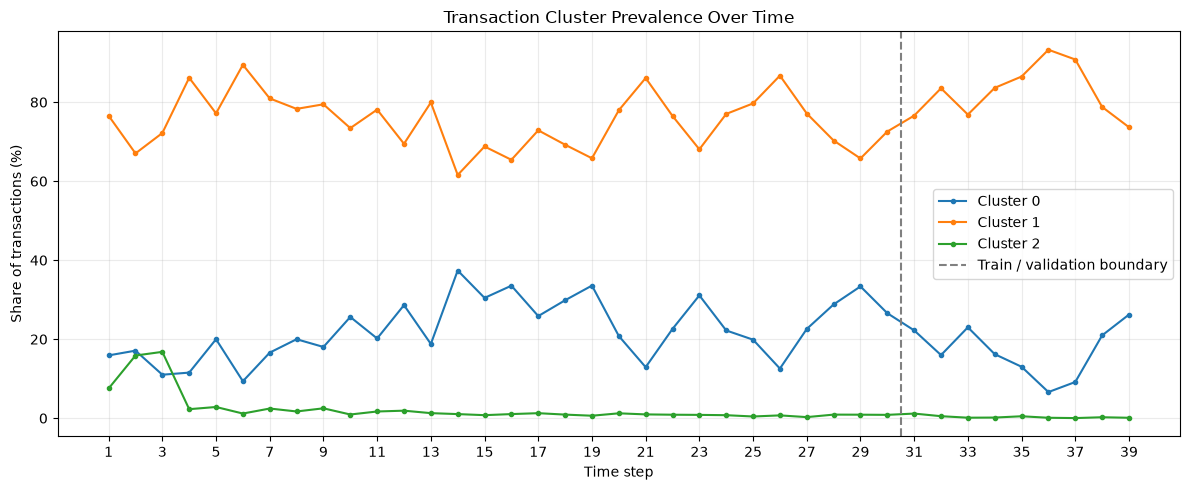


VALIDATION CHECKS
Expected total transactions: True
Exactly 39 time steps: True
Three cluster columns: True
Every time step sums to 100%: True
Training steps correctly assigned: True
Validation steps correctly assigned: True

Cluster time-step analysis completed.


In [ ]:

# Step 0.7.8 - Analyze cluster membership over time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("K=3 TRANSACTION CLUSTER - TIME-STEP ANALYSIS")
print("=" * 65)

# Create training time-step assignments
train_cluster_timeline = pd.DataFrame({
    "Time step": tx_features.loc[
        X_cluster_train_scaled.index, "Time step"
    ].to_numpy(),
    "Cluster": train_cluster_labels,
    "Period": "Training"
})

# Create validation time-step assignments
val_cluster_timeline = pd.DataFrame({
    "Time step": tx_features.loc[
        X_cluster_val_scaled.index, "Time step"
    ].to_numpy(),
    "Cluster": validation_cluster_labels,
    "Period": "Validation"
})

# Combine only the training and validation periods
cluster_timeline = pd.concat(
    [train_cluster_timeline, val_cluster_timeline],
    ignore_index=True
)

# Count cluster assignments within each time step
cluster_counts_by_step = pd.crosstab(
    cluster_timeline["Time step"],
    cluster_timeline["Cluster"]
).reindex(columns=[0, 1, 2], fill_value=0)

# Convert counts to percentages within each time step
cluster_percent_by_step = (
    cluster_counts_by_step
    .div(cluster_counts_by_step.sum(axis=1), axis=0)
    * 100
)

print("\nCLUSTER PERCENTAGES - LAST 5 TRAINING STEPS")
display(cluster_percent_by_step.loc[26:30].round(3))

print("\nCLUSTER PERCENTAGES - VALIDATION STEPS")
display(cluster_percent_by_step.loc[31:39].round(3))

# Visualize cluster prevalence across all 39 steps
fig, ax = plt.subplots(figsize=(12, 5))

for cluster_id in [0, 1, 2]:
    ax.plot(
        cluster_percent_by_step.index,
        cluster_percent_by_step[cluster_id],
        marker="o",
        markersize=3,
        label=f"Cluster {cluster_id}"
    )

ax.axvline(
    x=30.5,
    linestyle="--",
    color="gray",
    label="Train / validation boundary"
)

ax.set_title("Transaction Cluster Prevalence Over Time")
ax.set_xlabel("Time step")
ax.set_ylabel("Share of transactions (%)")
ax.set_xticks(range(1, 40, 2))
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("\nVALIDATION CHECKS")

print(
    "Expected total transactions:",
    len(cluster_timeline) == 123287 + 33835
)

print(
    "Exactly 39 time steps:",
    cluster_percent_by_step.shape[0] == 39
)

print(
    "Three cluster columns:",
    cluster_percent_by_step.shape[1] == 3
)

print(
    "Every time step sums to 100%:",
    bool(
        np.allclose(
            cluster_percent_by_step.sum(axis=1).to_numpy(),
            100,
            atol=1e-8
        )
    )
)

print(
    "Training steps correctly assigned:",
    train_cluster_timeline["Time step"].between(1, 30).all()
)

print(
    "Validation steps correctly assigned:",
    val_cluster_timeline["Time step"].between(31, 39).all()
)

print("\nCluster time-step analysis completed.")


In [ ]:

# Step 0.7.9 - Evaluate validation clusters using external labels

import pandas as pd
import numpy as np

print("K=3 CLUSTER - EXTERNAL LABEL EVALUATION")
print("=" * 65)

# Create validation transaction-to-cluster mapping
cluster_label_evaluation = pd.DataFrame({
    "txId": tx_features.loc[
        X_cluster_val_scaled.index, "txId"
    ].astype("string").to_numpy(),
    "Cluster": validation_cluster_labels
})

# Prepare labels without modifying the original label dataset
external_labels = tx_classes[["txId", "class"]].copy()

external_labels["txId"] = (
    external_labels["txId"].astype("string")
)

external_labels["class"] = (
    external_labels["class"].astype("string")
)

# Join labels only after clustering is complete
cluster_label_evaluation = cluster_label_evaluation.merge(
    external_labels,
    on="txId",
    how="left",
    validate="one_to_one"
)

# Count known illicit, known licit and unknown transactions
cluster_class_counts = pd.crosstab(
    cluster_label_evaluation["Cluster"],
    cluster_label_evaluation["class"]
).reindex(
    index=[0, 1, 2],
    columns=["1", "2", "3"],
    fill_value=0
)

cluster_class_counts.columns = [
    "Known Illicit",
    "Known Licit",
    "Unknown"
]

cluster_class_counts["Total"] = (
    cluster_class_counts.sum(axis=1)
)

cluster_class_counts["Known Total"] = (
    cluster_class_counts["Known Illicit"]
    + cluster_class_counts["Known Licit"]
)

cluster_class_counts["Illicit % of Known"] = (
    100
    * cluster_class_counts["Known Illicit"]
    / cluster_class_counts["Known Total"].replace(0, np.nan)
)

cluster_class_counts["Known Label Coverage %"] = (
    100
    * cluster_class_counts["Known Total"]
    / cluster_class_counts["Total"]
)

print("\nVALIDATION CLUSTER LABEL COMPOSITION")
display(cluster_class_counts.round(4))

# Calculate overall known illicit prevalence for comparison
overall_known_illicit_percent = (
    100
    * (cluster_label_evaluation["class"] == "1").sum()
    / cluster_label_evaluation["class"].isin(["1", "2"]).sum()
)

print("\nOVERALL VALIDATION BASELINE")
print(
    "Known illicit prevalence:",
    round(overall_known_illicit_percent, 4),
    "%"
)

# Compare each cluster against the overall known-label baseline
cluster_enrichment = pd.DataFrame({
    "Illicit % of Known": (
        cluster_class_counts["Illicit % of Known"]
    ),
    "Overall Known Illicit %": (
        overall_known_illicit_percent
    )
})

cluster_enrichment["Enrichment Ratio"] = (
    cluster_enrichment["Illicit % of Known"]
    / overall_known_illicit_percent
)

print("\nCLUSTER ENRICHMENT COMPARISON")
display(cluster_enrichment.round(4))

print("\nVALIDATION CHECKS")

print(
    "All validation transactions included:",
    len(cluster_label_evaluation) == 33835
)

print(
    "No unmatched transaction labels:",
    cluster_label_evaluation["class"].notna().all()
)

print(
    "Known illicit count preserved:",
    int(cluster_class_counts["Known Illicit"].sum()) == 955
)

print(
    "Known licit count preserved:",
    int(cluster_class_counts["Known Licit"].sum()) == 7520
)

print(
    "Unknown count preserved:",
    int(cluster_class_counts["Unknown"].sum()) == 25360
)

print(
    "Cluster counts preserved:",
    cluster_class_counts["Total"].tolist()
    == [5250, 28476, 109]
)

print("\nExternal cluster evaluation completed.")


K=3 CLUSTER - EXTERNAL LABEL EVALUATION

VALIDATION CLUSTER LABEL COMPOSITION


,Known Illicit,Known Licit,Unknown,Total,Known Total,Illicit % of Known,Known Label Coverage %
Cluster,,,,,,,
0,146,2158,2946,5250,2304,6.3368,43.8857
1,807,5333,22336,28476,6140,13.1433,21.5620
2,2,29,78,109,31,6.4516,28.4404



OVERALL VALIDATION BASELINE
Known illicit prevalence: 11.2684 %

CLUSTER ENRICHMENT COMPARISON


,Illicit % of Known,Overall Known Illicit %,Enrichment Ratio
Cluster,,,
0,6.3368,11.2684,0.5624
1,13.1433,11.2684,1.1664
2,6.4516,11.2684,0.5725



VALIDATION CHECKS
All validation transactions included: True
No unmatched transaction labels: True
Known illicit count preserved: True
Known licit count preserved: True
Unknown count preserved: True
Cluster counts preserved: True

External cluster evaluation completed.


In [ ]:

# Step 0.7.10 - Examine behavioral diversity within clusters

import numpy as np
import pandas as pd

print("K=3 CLUSTER - WITHIN-CLUSTER BEHAVIORAL DIVERSITY")
print("=" * 65)

diversity_features = [
    "total_BTC",
    "size",
    "num_input_addresses",
    "num_output_addresses",
    "fees"
]

# Calculate feature quartiles within each training cluster
cluster_diversity_summary = (
    cluster_behavior_data
    .groupby("Cluster")[diversity_features]
    .quantile([0.25, 0.50, 0.75])
)

cluster_diversity_summary.index.names = [
    "Cluster",
    "Quantile"
]

print("\nTRAINING CLUSTER FEATURE QUARTILES")
display(cluster_diversity_summary.round(6))

# Calculate interquartile range (Q3 - Q1)
cluster_iqr_summary = (
    cluster_diversity_summary
    .xs(0.75, level="Quantile")
    - cluster_diversity_summary
    .xs(0.25, level="Quantile")
)

print("\nINTERQUARTILE RANGE BY CLUSTER")
display(cluster_iqr_summary.round(6))

# Compare validation quartiles using the same cluster IDs
validation_diversity_summary = (
    validation_cluster_behavior
    .groupby("Cluster")[diversity_features]
    .quantile([0.25, 0.50, 0.75])
)

validation_diversity_summary.index.names = [
    "Cluster",
    "Quantile"
]

print("\nVALIDATION CLUSTER FEATURE QUARTILES")
display(validation_diversity_summary.round(6))

print("\nVALIDATION CHECKS")

print(
    "Three training clusters represented:",
    cluster_diversity_summary.index.get_level_values(
        "Cluster"
    ).nunique() == 3
)

print(
    "Three validation clusters represented:",
    validation_diversity_summary.index.get_level_values(
        "Cluster"
    ).nunique() == 3
)

print(
    "Three quantiles per cluster:",
    len(cluster_diversity_summary) == 9
    and len(validation_diversity_summary) == 9
)

print(
    "Five features analyzed:",
    cluster_diversity_summary.shape[1] == 5
)

print(
    "All interquartile ranges nonnegative:",
    bool(
        (cluster_iqr_summary >= 0).all().all()
    )
)

print(
    "No transaction labels used:",
    "class" not in diversity_features
)

print("\nWithin-cluster diversity analysis completed.")


K=3 CLUSTER - WITHIN-CLUSTER BEHAVIORAL DIVERSITY

TRAINING CLUSTER FEATURE QUARTILES


total_BTC   size  num_input_addresses  num_output_addresses  \
Cluster Quantile                                                                
0       0.25       0.377550  226.0                  1.0                   2.0   
        0.50       2.017370  335.0                  1.0                   2.0   
        0.75       9.587441  371.0                  1.0                   2.0   
1       0.25       0.070998  225.0                  1.0                   2.0   
        0.50       0.510316  226.0                  1.0                   2.0   
        0.75       5.441496  373.0                  1.0                   2.0   
2       0.25       0.105503  372.0                  2.0                   2.0   
        0.50       0.447536  373.0                  2.0                   2.0   
        0.75       0.714900  374.0                  2.0                   2.0   

                      fees  
Cluster Quantile            
0       0.25      0.000100  
        0.50      0.000200  
        0.75      0.000500  
1       0.25      0.000100  
        0.50      0.000147  
        0.75      0.000300  
2       0.25      0.000100  
        0.50      0.000100  
        0.75      0.000153


INTERQUARTILE RANGE BY CLUSTER


,total_BTC,size,num_input_addresses,num_output_addresses,fees
Cluster,,,,,
0,9.209891,145.0,0.0,0.0,0.000400
1,5.370498,148.0,0.0,0.0,0.000200
2,0.609397,2.0,0.0,0.0,0.000053



VALIDATION CLUSTER FEATURE QUARTILES


total_BTC   size  num_input_addresses  num_output_addresses  \
Cluster Quantile                                                                
0       0.25       1.268707  226.0                  1.0                   2.0   
        0.50       9.004351  334.0                  1.0                   2.0   
        0.75      52.920461  335.0                  1.0                   2.0   
1       0.25       0.039465  225.0                  1.0                   2.0   
        0.50       0.265309  226.0                  1.0                   2.0   
        0.75       3.932214  372.0                  1.0                   2.0   
2       0.25       0.000898  318.0                  1.5                   2.0   
        0.50       0.025917  373.0                  2.0                   2.0   
        0.75       0.098918  374.0                  2.0                   2.0   

                      fees  
Cluster Quantile            
0       0.25      0.000415  
        0.50      0.000560  
        0.75      0.000655  
1       0.25      0.000400  
        0.50      0.000588  
        0.75      0.001060  
2       0.25      0.000500  
        0.50      0.000600  
        0.75      0.000792


VALIDATION CHECKS
Three training clusters represented: True
Three validation clusters represented: True
Three quantiles per cluster: True
Five features analyzed: True
All interquartile ranges nonnegative: True
No transaction labels used: True

Within-cluster diversity analysis completed.


In [30]:

# Step 0.8.1 - Prepare a training sample for DBSCAN

import numpy as np
import pandas as pd

print("DBSCAN - TRAINING SAMPLE PREPARATION")
print("=" * 65)

# Reproducible random sampling from training data only
dbscan_rng = np.random.default_rng(42)

dbscan_sample_positions = dbscan_rng.choice(
    len(X_cluster_train_scaled),
    size=10000,
    replace=False
)

# Preserve the original feature columns and row indices
X_dbscan_sample = X_cluster_train_scaled.iloc[
    dbscan_sample_positions
].copy()

print("\nDBSCAN SAMPLE SHAPE")
print(X_dbscan_sample.shape)

print("\nSAMPLE FEATURE STATISTICS")
print(
    "Minimum value:",
    round(float(X_dbscan_sample.to_numpy().min()), 6)
)
print(
    "Maximum value:",
    round(float(X_dbscan_sample.to_numpy().max()), 6)
)

print("\nVALIDATION CHECKS")

print(
    "Expected sample size:",
    len(X_dbscan_sample) == 10000
)

print(
    "Expected feature count:",
    X_dbscan_sample.shape[1] == 165
)

print(
    "No duplicate sampled rows by index:",
    X_dbscan_sample.index.is_unique
)

print(
    "All sampled indices belong to training:",
    X_dbscan_sample.index.isin(
        X_cluster_train_scaled.index
    ).all()
)

print(
    "All values finite:",
    bool(
        np.isfinite(
            X_dbscan_sample.to_numpy()
        ).all()
    )
)

print(
    "No transaction labels included:",
    "class" not in X_dbscan_sample.columns
)

print("\nDBSCAN sample preparation completed.")


DBSCAN - TRAINING SAMPLE PREPARATION

DBSCAN SAMPLE SHAPE
(10000, 165)

SAMPLE FEATURE STATISTICS
Minimum value: -20.311245
Maximum value: 140.540385

VALIDATION CHECKS
Expected sample size: True
Expected feature count: True
No duplicate sampled rows by index: True
All sampled indices belong to training: True
All values finite: True
No transaction labels included: True

DBSCAN sample preparation completed.


DBSCAN - K-NEAREST-NEIGHBOR DISTANCE ANALYSIS

10TH-NEAREST-NEIGHBOR DISTANCE STATISTICS


,Percentile,Distance
0,0,0.2869
1,25,3.3781
2,50,4.4793
3,75,7.5156
4,90,11.4710
5,95,14.2266
6,99,24.8370
7,100,159.2663


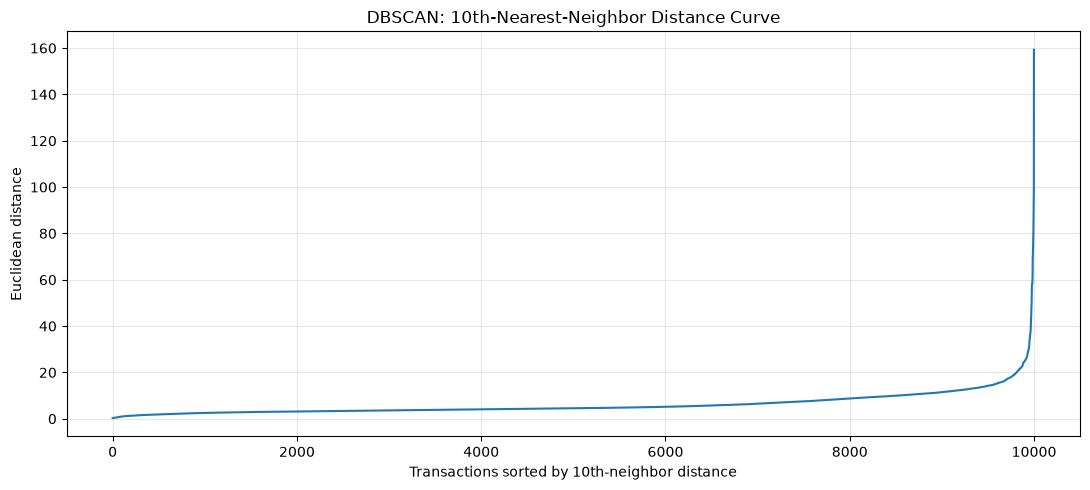


VALIDATION CHECKS
Expected number of distances: True
Correct neighbor matrix shape: True
All distances finite: True
No negative distances: True
Sorted distances nondecreasing: True
No transaction labels used: True

Nearest-neighbor distance analysis completed.


In [ ]:

# Step 0.8.2 - Nearest-neighbor distance analysis for DBSCAN

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors

print("DBSCAN - K-NEAREST-NEIGHBOR DISTANCE ANALYSIS")
print("=" * 65)

# Start with min_samples = 10 as an exploratory setting.
# NearestNeighbors includes each observation itself.
dbscan_min_samples = 10

dbscan_neighbors = NearestNeighbors(
    n_neighbors=dbscan_min_samples,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

dbscan_neighbors.fit(X_dbscan_sample)

# Shape: (10000, 10)
neighbor_distances, neighbor_indices = (
    dbscan_neighbors.kneighbors(X_dbscan_sample)
)

# Last column = distance to 10th neighbor, counting self
dbscan_k_distances = neighbor_distances[:, -1]

dbscan_sorted_distances = np.sort(
    dbscan_k_distances
)

print("\n10TH-NEAREST-NEIGHBOR DISTANCE STATISTICS")

distance_percentiles = [0, 25, 50, 75, 90, 95, 99, 100]

distance_summary = pd.DataFrame({
    "Percentile": distance_percentiles,
    "Distance": np.percentile(
        dbscan_k_distances,
        distance_percentiles
    )
})

display(distance_summary.round(4))

# Visualize the full sorted distance distribution
plt.figure(figsize=(11, 5))

plt.plot(
    dbscan_sorted_distances,
    linewidth=1.5
)

plt.xlabel("Transactions sorted by 10th-neighbor distance")
plt.ylabel("Euclidean distance")
plt.title("DBSCAN: 10th-Nearest-Neighbor Distance Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nVALIDATION CHECKS")

print(
    "Expected number of distances:",
    len(dbscan_k_distances) == 10000
)

print(
    "Correct neighbor matrix shape:",
    neighbor_distances.shape == (10000, 10)
)

print(
    "All distances finite:",
    bool(np.isfinite(dbscan_k_distances).all())
)

print(
    "No negative distances:",
    bool((dbscan_k_distances >= 0).all())
)

print(
    "Sorted distances nondecreasing:",
    bool(np.all(np.diff(dbscan_sorted_distances) >= 0))
)

print(
    "No transaction labels used:",
    "class" not in X_dbscan_sample.columns
)

print("\nNearest-neighbor distance analysis completed.")


In [ ]:

# Step 0.8.3 - Train DBSCAN with candidate eps values

import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN

print("DBSCAN - CANDIDATE MODEL TRAINING")
print("=" * 65)

dbscan_eps_candidates = [3.5, 4.5, 7.5, 11.5]

dbscan_candidate_models = {}
dbscan_candidate_labels = {}
dbscan_comparison_rows = []

for eps_value in dbscan_eps_candidates:

    print(f"\nTraining DBSCAN with eps={eps_value} ...")

    model = DBSCAN(
        eps=eps_value,
        min_samples=dbscan_min_samples,
        metric="euclidean",
        algorithm="brute",
        n_jobs=-1
    )

    labels = model.fit_predict(X_dbscan_sample)

    dbscan_candidate_models[eps_value] = model
    dbscan_candidate_labels[eps_value] = labels

    cluster_ids = set(labels) - {-1}
    n_clusters = len(cluster_ids)

    noise_count = int(np.sum(labels == -1))
    noise_percentage = 100 * noise_count / len(labels)

    cluster_sizes = pd.Series(
        labels[labels != -1]
    ).value_counts()

    largest_cluster = (
        int(cluster_sizes.max())
        if not cluster_sizes.empty
        else 0
    )

    smallest_cluster = (
        int(cluster_sizes.min())
        if not cluster_sizes.empty
        else 0
    )

    dbscan_comparison_rows.append({
        "eps": eps_value,
        "Clusters": n_clusters,
        "Noise Count": noise_count,
        "Noise %": noise_percentage,
        "Largest Cluster": largest_cluster,
        "Smallest Cluster": smallest_cluster
    })

dbscan_model_comparison = pd.DataFrame(
    dbscan_comparison_rows
)

print("\nDBSCAN MODEL COMPARISON")
display(dbscan_model_comparison.round(4))

print("\nVALIDATION CHECKS")

print(
    "Four candidate models trained:",
    len(dbscan_candidate_models) == 4
)

print(
    "Four label arrays generated:",
    len(dbscan_candidate_labels) == 4
)

print(
    "Every model assigned 10000 labels:",
    all(
        len(labels) == 10000
        for labels in dbscan_candidate_labels.values()
    )
)

print(
    "Noise percentages within valid range:",
    bool(
        dbscan_model_comparison["Noise %"]
        .between(0, 100).all()
    )
)

print(
    "Cluster counts nonnegative:",
    bool(
        (dbscan_model_comparison["Clusters"] >= 0).all()
    )
)

print(
    "No transaction labels used in training:",
    "class" not in X_dbscan_sample.columns
)

print("\nDBSCAN candidate training completed.")


DBSCAN - CANDIDATE MODEL TRAINING

Training DBSCAN with eps=3.5 ...

Training DBSCAN with eps=4.5 ...

Training DBSCAN with eps=7.5 ...

Training DBSCAN with eps=11.5 ...

DBSCAN MODEL COMPARISON


,eps,Clusters,Noise Count,Noise %,Largest Cluster,Smallest Cluster
0,3.5,17,5740,57.40,3269,10
1,4.5,10,3880,38.80,5945,2
2,7.5,10,2067,20.67,7719,9
3,11.5,6,661,6.61,9199,10



VALIDATION CHECKS
Four candidate models trained: True
Four label arrays generated: True
Every model assigned 10000 labels: True
Noise percentages within valid range: True
Cluster counts nonnegative: True
No transaction labels used in training: True

DBSCAN candidate training completed.


In [ ]:

# Step 0.8.4 - Verify DBSCAN cluster-size consistency

import numpy as np
import pandas as pd

print("DBSCAN - CLUSTER CONSISTENCY AUDIT")
print("=" * 65)

audit_rows = []

for eps_value in dbscan_eps_candidates:

    model = dbscan_candidate_models[eps_value]
    labels = np.asarray(
        dbscan_candidate_labels[eps_value]
    )

    non_noise_labels = labels[labels != -1]

    cluster_sizes = pd.Series(
        non_noise_labels
    ).value_counts().sort_index()

    core_indices = model.core_sample_indices_
    core_labels = labels[core_indices]

    n_clusters = len(cluster_sizes)

    clusters_with_core = len(
        set(core_labels) - {-1}
    )

    smallest_cluster = (
        int(cluster_sizes.min())
        if n_clusters > 0
        else 0
    )

    below_min_samples = (
        int((cluster_sizes < dbscan_min_samples).sum())
        if n_clusters > 0
        else 0
    )

    audit_rows.append({
        "eps": eps_value,
        "min_samples": model.min_samples,
        "Clusters": n_clusters,
        "Core Samples": len(core_indices),
        "Clusters With Core": clusters_with_core,
        "Smallest Cluster": smallest_cluster,
        "Clusters Below min_samples": below_min_samples,
        "Labels Match Model": np.array_equal(
            labels, model.labels_
        )
    })

dbscan_cluster_audit = pd.DataFrame(audit_rows)

print("\nCLUSTER CONSISTENCY SUMMARY")
display(dbscan_cluster_audit)

print("\nSMALL CLUSTERS FOR eps=4.5")

eps_45_sizes = pd.Series(
    dbscan_candidate_labels[4.5]
)

eps_45_sizes = (
    eps_45_sizes[eps_45_sizes != -1]
    .value_counts()
    .sort_values()
)

display(eps_45_sizes.head(10).to_frame("Cluster Size"))

print("\nVALIDATION CHECKS")

print(
    "Four models audited:",
    len(dbscan_cluster_audit) == 4
)

print(
    "All models use min_samples=10:",
    bool(
        (dbscan_cluster_audit["min_samples"] == 10).all()
    )
)

print(
    "All stored labels match fitted models:",
    bool(
        dbscan_cluster_audit["Labels Match Model"].all()
    )
)

print(
    "Every cluster has a core sample:",
    bool(
        (
            dbscan_cluster_audit["Clusters"]
            == dbscan_cluster_audit["Clusters With Core"]
        ).all()
    )
)

print(
    "No cluster smaller than min_samples:",
    bool(
        (
            dbscan_cluster_audit["Clusters Below min_samples"]
            == 0
        ).all()
    )
)

print("\nDBSCAN consistency audit completed.")


DBSCAN - CLUSTER CONSISTENCY AUDIT

CLUSTER CONSISTENCY SUMMARY


,eps,min_samples,Clusters,Core Samples,Clusters With Core,Smallest Cluster,Clusters Below min_samples,Labels Match Model
0,3.5,10,17,2798,17,10,0,True
1,4.5,10,10,5034,10,2,1,True
2,7.5,10,10,7489,10,9,2,True
3,11.5,10,6,9009,6,10,0,True



SMALL CLUSTERS FOR eps=4.5


,Cluster Size
5,2
1,10
8,10
9,10
6,13
7,16
3,28
2,32
4,54
0,5945



VALIDATION CHECKS
Four models audited: True
All models use min_samples=10: True
All stored labels match fitted models: True
Every cluster has a core sample: True
No cluster smaller than min_samples: False

DBSCAN consistency audit completed.


In [ ]:

# Step 0.8.5 - Investigate undersized DBSCAN clusters

import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances

print("DBSCAN - UNDERSIZED CLUSTER INVESTIGATION")
print("=" * 65)

X_dbscan_array = X_dbscan_sample.to_numpy(dtype=np.float64)

investigation_rows = []

for eps_value in [4.5, 7.5]:

    model = dbscan_candidate_models[eps_value]
    labels = np.asarray(model.labels_)

    cluster_sizes = pd.Series(
        labels[labels != -1]
    ).value_counts()

    small_cluster_ids = cluster_sizes[
        cluster_sizes < model.min_samples
    ].index.tolist()

    print(f"\neps={eps_value}")
    print("Undersized cluster IDs:", small_cluster_ids)

    for cluster_id in small_cluster_ids:

        member_positions = np.flatnonzero(
            labels == cluster_id
        )

        core_positions = np.intersect1d(
            member_positions,
            model.core_sample_indices_
        )

        print(
            f"\nCluster {cluster_id}: "
            f"{len(member_positions)} members, "
            f"{len(core_positions)} core samples"
        )

        # Inspect the first core sample of this cluster
        if len(core_positions) == 0:
            continue

        core_position = int(core_positions[0])

        distances = pairwise_distances(
            X_dbscan_array[core_position:core_position + 1],
            X_dbscan_array,
            metric="euclidean"
        )[0]

        # Small tolerance to inspect boundary effects
        exact_neighbors = np.flatnonzero(
            distances <= eps_value
        )

        tolerance_neighbors = np.flatnonzero(
            distances <= eps_value + 1e-8
        )

        neighbor_label_counts = pd.Series(
            labels[exact_neighbors]
        ).value_counts().sort_index()

        print("Core sample position:", core_position)
        print("Neighbors within eps:", len(exact_neighbors))
        print(
            "Neighbors within eps + 1e-8:",
            len(tolerance_neighbors)
        )
        print("Neighbor label distribution:")
        display(
            neighbor_label_counts.to_frame("Count")
        )

        investigation_rows.append({
            "eps": eps_value,
            "Cluster": int(cluster_id),
            "Cluster Size": len(member_positions),
            "Core Samples in Cluster": len(core_positions),
            "Neighbors Within eps": len(exact_neighbors),
            "Neighbors Within eps + tolerance": len(
                tolerance_neighbors
            ),
            "Neighbors Assigned Elsewhere": int(
                np.sum(labels[exact_neighbors] != cluster_id)
            )
        })

dbscan_small_cluster_investigation = pd.DataFrame(
    investigation_rows
)

print("\nINVESTIGATION SUMMARY")
display(dbscan_small_cluster_investigation)

print("\nVALIDATION CHECKS")

print(
    "All undersized clusters investigated:",
    len(dbscan_small_cluster_investigation) == 3
)

print(
    "Every investigated cluster has core samples:",
    bool(
        (
            dbscan_small_cluster_investigation[
                "Core Samples in Cluster"
            ] > 0
        ).all()
    )
)

print(
    "Distance calculations finite:",
    bool(
        np.isfinite(
            dbscan_small_cluster_investigation[
                "Neighbors Within eps"
            ]
        ).all()
    )
)

print("\nUndersized cluster investigation completed.")


DBSCAN - UNDERSIZED CLUSTER INVESTIGATION

eps=4.5
Undersized cluster IDs: [5]

Cluster 5: 2 members, 1 core samples
Core sample position: 739
Neighbors within eps: 11
Neighbors within eps + 1e-8: 11
Neighbor label distribution:


,Count
0,9
5,2



eps=7.5
Undersized cluster IDs: [7, 9]

Cluster 7: 9 members, 1 core samples
Core sample position: 2269
Neighbors within eps: 10
Neighbors within eps + 1e-8: 10
Neighbor label distribution:


,Count
0,1
7,9



Cluster 9: 9 members, 1 core samples
Core sample position: 6820
Neighbors within eps: 10
Neighbors within eps + 1e-8: 10
Neighbor label distribution:


,Count
0,1
9,9



INVESTIGATION SUMMARY


,eps,Cluster,Cluster Size,Core Samples in Cluster,Neighbors Within eps,Neighbors Within eps + tolerance,Neighbors Assigned Elsewhere
0,4.5,5,2,1,11,11,9
1,7.5,7,9,1,10,10,1
2,7.5,9,9,1,10,10,1



VALIDATION CHECKS
All undersized clusters investigated: True
Every investigated cluster has core samples: True
Distance calculations finite: True

Undersized cluster investigation completed.


In [ ]:

# Step 0.8.6 - Evaluate DBSCAN clustering quality

import numpy as np
import pandas as pd

from sklearn.metrics import silhouette_score

print("DBSCAN - CLUSTER QUALITY EVALUATION")
print("=" * 65)

dbscan_quality_rows = []

quality_rng = np.random.default_rng(42)

for eps_value in dbscan_eps_candidates:

    labels = np.asarray(
        dbscan_candidate_labels[eps_value]
    )

    non_noise_positions = np.flatnonzero(
        labels != -1
    )

    non_noise_labels = labels[
        non_noise_positions
    ]

    n_clusters = len(
        np.unique(non_noise_labels)
    )

    noise_percentage = (
        100 * np.mean(labels == -1)
    )

    cluster_sizes = pd.Series(
        non_noise_labels
    ).value_counts()

    largest_cluster_share = (
        100 * cluster_sizes.max() / len(labels)
        if len(cluster_sizes) > 0
        else np.nan
    )

    silhouette = np.nan

    if n_clusters >= 2 and len(non_noise_positions) > n_clusters:

        sample_size = min(
            2000,
            len(non_noise_positions)
        )

        # Sample non-noise points for memory-efficient evaluation
        sampled_positions = quality_rng.choice(
            non_noise_positions,
            size=sample_size,
            replace=False
        )

        sampled_labels = labels[
            sampled_positions
        ]

        unique_sampled_clusters = np.unique(
            sampled_labels
        )

        # Silhouette requires at least two groups and
        # fewer groups than sampled observations.
        if (
            2 <= len(unique_sampled_clusters)
            < sample_size
        ):
            silhouette = silhouette_score(
                X_dbscan_sample.iloc[
                    sampled_positions
                ],
                sampled_labels,
                metric="euclidean"
            )

    dbscan_quality_rows.append({
        "eps": eps_value,
        "Clusters": n_clusters,
        "Noise %": noise_percentage,
        "Largest Cluster % of All": largest_cluster_share,
        "Sampled Silhouette": silhouette
    })

dbscan_quality_comparison = pd.DataFrame(
    dbscan_quality_rows
)

print("\nDBSCAN QUALITY COMPARISON")
display(
    dbscan_quality_comparison.round(4)
)

print("\nVALIDATION CHECKS")

print(
    "Four models evaluated:",
    len(dbscan_quality_comparison) == 4
)

print(
    "All noise percentages valid:",
    bool(
        dbscan_quality_comparison[
            "Noise %"
        ].between(0, 100).all()
    )
)

print(
    "All largest-cluster percentages valid:",
    bool(
        dbscan_quality_comparison[
            "Largest Cluster % of All"
        ].between(0, 100).all()
    )
)

print(
    "All available silhouette scores valid:",
    bool(
        dbscan_quality_comparison[
            "Sampled Silhouette"
        ].dropna()
        .between(-1, 1).all()
    )
)

print(
    "No external transaction labels used:",
    "class" not in X_dbscan_sample.columns
)

print("\nDBSCAN cluster quality evaluation completed.")


DBSCAN - CLUSTER QUALITY EVALUATION

DBSCAN QUALITY COMPARISON


,eps,Clusters,Noise %,Largest Cluster % of All,Sampled Silhouette
0,3.5,17,57.40,32.69,-0.0847
1,4.5,10,38.80,59.45,0.2128
2,7.5,10,20.67,77.19,0.1413
3,11.5,6,6.61,91.99,0.3395



VALIDATION CHECKS
Four models evaluated: True
All noise percentages valid: True
All largest-cluster percentages valid: True
All available silhouette scores valid: True
No external transaction labels used: True

DBSCAN cluster quality evaluation completed.


DBSCAN - CLUSTER SIZE AND NOISE ANALYSIS

DBSCAN CLUSTER DISTRIBUTION


,Cluster,Transaction Count,Percentage,Group Type
0,-1,3880,38.80,Noise
1,0,5945,59.45,Cluster
2,1,10,0.10,Cluster
3,2,32,0.32,Cluster
4,3,28,0.28,Cluster
5,4,54,0.54,Cluster
6,5,2,0.02,Cluster
7,6,13,0.13,Cluster
8,7,16,0.16,Cluster
9,8,10,0.10,Cluster


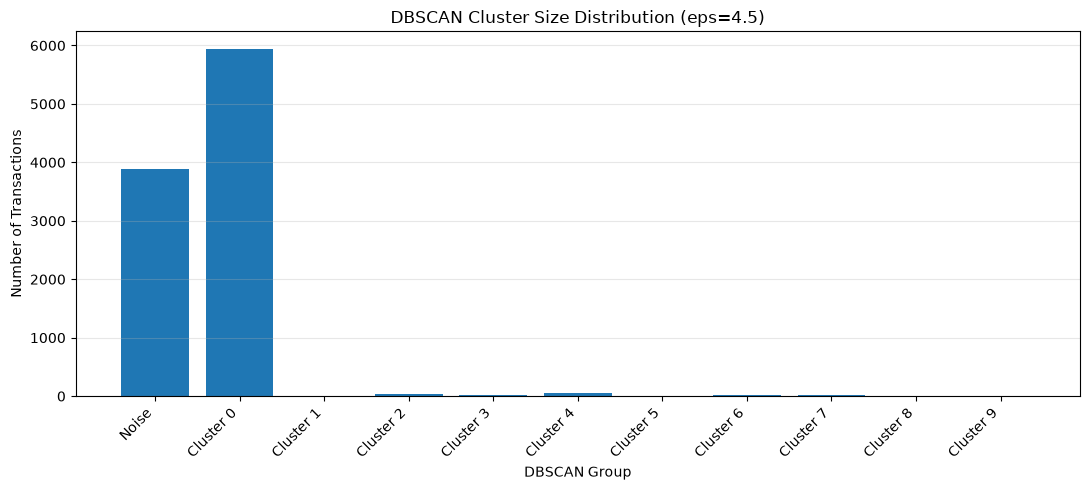


SUMMARY
Noise transactions: 3880
Clustered transactions: 6120
Noise percentage: 38.8

VALIDATION CHECKS
Exactly 10000 transactions accounted for: True
Noise count matches earlier result: True
Non-noise count matches earlier result: True
Ten non-noise clusters found: True
Largest cluster matches earlier result: True
No external labels used: True

DBSCAN cluster distribution analysis completed.


In [ ]:

# Step 0.8.7 - DBSCAN cluster size and noise analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("DBSCAN - CLUSTER SIZE AND NOISE ANALYSIS")
print("=" * 65)

# Provisional DBSCAN configuration
selected_dbscan_eps = 4.5

selected_dbscan_model = dbscan_candidate_models[
    selected_dbscan_eps
]

selected_dbscan_labels = np.asarray(
    dbscan_candidate_labels[selected_dbscan_eps]
)

# Count all assigned clusters, including noise (-1)
dbscan_cluster_distribution = (
    pd.Series(
        selected_dbscan_labels,
        name="Cluster"
    )
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Transaction Count")
)

dbscan_cluster_distribution["Percentage"] = (
    100
    * dbscan_cluster_distribution["Transaction Count"]
    / len(selected_dbscan_labels)
)

dbscan_cluster_distribution["Group Type"] = (
    dbscan_cluster_distribution["Cluster"]
    .apply(
        lambda cluster_id:
        "Noise" if cluster_id == -1 else "Cluster"
    )
)

print("\nDBSCAN CLUSTER DISTRIBUTION")
display(
    dbscan_cluster_distribution.round(4)
)

# Visualization
plot_labels = [
    "Noise" if cluster_id == -1 else f"Cluster {cluster_id}"
    for cluster_id in dbscan_cluster_distribution["Cluster"]
]

plt.figure(figsize=(11, 5))

plt.bar(
    plot_labels,
    dbscan_cluster_distribution["Transaction Count"]
)

plt.title("DBSCAN Cluster Size Distribution (eps=4.5)")
plt.xlabel("DBSCAN Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Summary statistics
noise_count = int(
    np.sum(selected_dbscan_labels == -1)
)

non_noise_count = int(
    np.sum(selected_dbscan_labels != -1)
)

print("\nSUMMARY")
print("Noise transactions:", noise_count)
print("Clustered transactions:", non_noise_count)
print(
    "Noise percentage:",
    round(100 * noise_count / len(selected_dbscan_labels), 4)
)

print("\nVALIDATION CHECKS")

print(
    "Exactly 10000 transactions accounted for:",
    dbscan_cluster_distribution[
        "Transaction Count"
    ].sum() == 10000
)

print(
    "Noise count matches earlier result:",
    noise_count == 3880
)

print(
    "Non-noise count matches earlier result:",
    non_noise_count == 6120
)

print(
    "Ten non-noise clusters found:",
    len(
        set(selected_dbscan_labels) - {-1}
    ) == 10
)

print(
    "Largest cluster matches earlier result:",
    int(
        dbscan_cluster_distribution.loc[
            dbscan_cluster_distribution["Cluster"] != -1,
            "Transaction Count"
        ].max()
    ) == 5945
)

print(
    "No external labels used:",
    "class" not in X_dbscan_sample.columns
)

print("\nDBSCAN cluster distribution analysis completed.")


In [ ]:

# Step 0.8.8 - DBSCAN noise vs clustered behavior analysis

import numpy as np
import pandas as pd

print("DBSCAN - NOISE VS CLUSTERED BEHAVIOR ANALYSIS")
print("=" * 65)

dbscan_behavior_features = [
    "total_BTC",
    "size",
    "num_input_addresses",
    "num_output_addresses",
    "fees",
    "in_txs_degree",
    "out_txs_degree"
]

# Retrieve original, interpretable transaction features
# using the exact sampled training row indices.
dbscan_behavior_data = tx_features.loc[
    X_dbscan_sample.index,
    dbscan_behavior_features
].copy()

# Add already-trained DBSCAN cluster assignments
dbscan_behavior_data["DBSCAN Cluster"] = (
    selected_dbscan_labels
)

# Define groups for post-training interpretation
dbscan_behavior_data["Behavior Group"] = np.select(
    [
        dbscan_behavior_data["DBSCAN Cluster"] == -1,
        dbscan_behavior_data["DBSCAN Cluster"] == 0
    ],
    [
        "Noise",
        "Dominant Cluster"
    ],
    default="Small Clusters"
)

group_order = [
    "Noise",
    "Dominant Cluster",
    "Small Clusters"
]

# Count observations in each group
dbscan_behavior_group_counts = (
    dbscan_behavior_data["Behavior Group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
)

print("\nBEHAVIOR GROUP COUNTS")
display(
    dbscan_behavior_group_counts.to_frame(
        "Transaction Count"
    )
)

# Compare medians in original units
dbscan_behavior_medians = (
    dbscan_behavior_data
    .groupby("Behavior Group")[
        dbscan_behavior_features
    ]
    .median()
    .reindex(group_order)
)

print("\nMEDIAN TRANSACTION BEHAVIOR BY GROUP")
display(dbscan_behavior_medians.round(6))

# Compare 25th and 75th percentiles for key features
dbscan_behavior_quartiles = (
    dbscan_behavior_data
    .groupby("Behavior Group")[
        ["total_BTC", "size", "fees"]
    ]
    .quantile([0.25, 0.75])
)

print("\nBEHAVIOR QUARTILES (25TH AND 75TH)")
display(dbscan_behavior_quartiles.round(6))

print("\nVALIDATION CHECKS")

print(
    "All 10000 transactions represented:",
    len(dbscan_behavior_data) == 10000
)

print(
    "Noise count preserved:",
    dbscan_behavior_group_counts["Noise"] == 3880
)

print(
    "Dominant cluster count preserved:",
    dbscan_behavior_group_counts[
        "Dominant Cluster"
    ] == 5945
)

print(
    "Small-cluster count preserved:",
    dbscan_behavior_group_counts[
        "Small Clusters"
    ] == 175
)

print(
    "All behavior groups represented:",
    bool(
        (dbscan_behavior_group_counts > 0).all()
    )
)

print(
    "No external transaction labels used:",
    "class" not in dbscan_behavior_data.columns
)

print("\nDBSCAN behavioral analysis completed.")


DBSCAN - NOISE VS CLUSTERED BEHAVIOR ANALYSIS

BEHAVIOR GROUP COUNTS


,Transaction Count
Behavior Group,
Noise,3880
Dominant Cluster,5945
Small Clusters,175



MEDIAN TRANSACTION BEHAVIOR BY GROUP


,total_BTC,size,num_input_addresses,num_output_addresses,fees,in_txs_degree,out_txs_degree
Behavior Group,,,,,,,
Noise,0.409429,373.0,2.0,2.0,0.000200,1.0,1.0
Dominant Cluster,1.003955,226.0,1.0,2.0,0.000143,1.0,1.0
Small Clusters,1.490235,334.0,1.0,2.0,0.000200,1.0,1.0



BEHAVIOR QUARTILES (25TH AND 75TH)


total_BTC   size      fees
Behavior Group                                   
Dominant Cluster 0.25   0.139631  225.0  0.000100
                 0.75   9.083499  334.0  0.000300
Noise            0.25   0.063599  257.0  0.000100
                 0.75   3.031470  666.0  0.000344
Small Clusters   0.25   0.485496  226.0  0.000100
                 0.75  12.599269  354.0  0.000400


VALIDATION CHECKS
All 10000 transactions represented: True
Noise count preserved: True
Dominant cluster count preserved: True
Small-cluster count preserved: True
All behavior groups represented: True
No external transaction labels used: True

DBSCAN behavioral analysis completed.


In [ ]:

# Step 0.8.9 - DBSCAN external-label evaluation
# Labels are used ONLY after unsupervised training.

import numpy as np
import pandas as pd

print("DBSCAN - EXTERNAL LABEL EVALUATION")
print("=" * 65)

# Match sampled training transactions to their original txIds
dbscan_label_evaluation = pd.DataFrame({
    "txId": tx_features.loc[
        X_dbscan_sample.index, "txId"
    ].astype("string").to_numpy(),
    "Behavior Group": dbscan_behavior_data[
        "Behavior Group"
    ].to_numpy()
})

# Use the transaction labels prepared earlier
dbscan_external_labels = tx_classes[
    ["txId", "class"]
].copy()

dbscan_external_labels["txId"] = (
    dbscan_external_labels["txId"].astype("string")
)

dbscan_external_labels["class"] = (
    dbscan_external_labels["class"].astype("string")
)

# Join external labels after clustering
dbscan_label_evaluation = dbscan_label_evaluation.merge(
    dbscan_external_labels,
    on="txId",
    how="left",
    validate="one_to_one"
)

group_order = [
    "Noise",
    "Dominant Cluster",
    "Small Clusters"
]

# Count known illicit, known licit and unknown transactions
dbscan_label_counts = pd.crosstab(
    dbscan_label_evaluation["Behavior Group"],
    dbscan_label_evaluation["class"]
).reindex(
    index=group_order,
    columns=["1", "2", "3"],
    fill_value=0
)

dbscan_label_counts.columns = [
    "Known Illicit",
    "Known Licit",
    "Unknown"
]

dbscan_label_counts["Total"] = (
    dbscan_label_counts.sum(axis=1)
)

dbscan_label_counts["Known Total"] = (
    dbscan_label_counts["Known Illicit"]
    + dbscan_label_counts["Known Licit"]
)

dbscan_label_counts["Illicit % of Known"] = (
    100
    * dbscan_label_counts["Known Illicit"]
    / dbscan_label_counts["Known Total"].replace(
        0, np.nan
    )
)

dbscan_label_counts["Known Label Coverage %"] = (
    100
    * dbscan_label_counts["Known Total"]
    / dbscan_label_counts["Total"]
)

print("\nDBSCAN LABEL COMPOSITION")
display(dbscan_label_counts.round(4))

# Baseline prevalence among known-labeled sampled transactions
overall_dbscan_illicit_percent = (
    100
    * (dbscan_label_evaluation["class"] == "1").sum()
    / dbscan_label_evaluation["class"].isin(
        ["1", "2"]
    ).sum()
)

print("\nOVERALL SAMPLED TRAINING BASELINE")
print(
    "Known illicit prevalence:",
    round(overall_dbscan_illicit_percent, 4),
    "%"
)

# Enrichment relative to the same sample's known-label baseline
dbscan_enrichment = pd.DataFrame({
    "Illicit % of Known": (
        dbscan_label_counts["Illicit % of Known"]
    ),
    "Overall Known Illicit %": (
        overall_dbscan_illicit_percent
    )
})

dbscan_enrichment["Enrichment Ratio"] = (
    dbscan_enrichment["Illicit % of Known"]
    / overall_dbscan_illicit_percent
)

print("\nDBSCAN LABEL ENRICHMENT")
display(dbscan_enrichment.round(4))

print("\nVALIDATION CHECKS")

print(
    "Exactly 10000 sampled transactions:",
    len(dbscan_label_evaluation) == 10000
)

print(
    "All transactions matched to labels:",
    dbscan_label_evaluation["class"].notna().all()
)

print(
    "Group counts preserved:",
    dbscan_label_counts["Total"].tolist()
    == [3880, 5945, 175]
)

print(
    "All label counts sum to 10000:",
    int(
        dbscan_label_counts[
            ["Known Illicit", "Known Licit", "Unknown"]
        ].to_numpy().sum()
    ) == 10000
)

print(
    "Only expected class values present:",
    set(
        dbscan_label_evaluation["class"].dropna()
    ).issubset({"1", "2", "3"})
)

print(
    "Enrichment computed from known labels only:",
    int(dbscan_label_counts["Known Total"].sum())
    == int(
        dbscan_label_evaluation["class"].isin(
            ["1", "2"]
        ).sum()
    )
)

print("\nDBSCAN external-label evaluation completed.")


DBSCAN - EXTERNAL LABEL EVALUATION

DBSCAN LABEL COMPOSITION


,Known Illicit,Known Licit,Unknown,Total,Known Total,Illicit % of Known,Known Label Coverage %
Behavior Group,,,,,,,
Noise,20,1543,2317,3880,1563,1.2796,40.2835
Dominant Cluster,232,303,5410,5945,535,43.3645,8.9992
Small Clusters,0,58,117,175,58,0.0000,33.1429



OVERALL SAMPLED TRAINING BASELINE
Known illicit prevalence: 11.6883 %

DBSCAN LABEL ENRICHMENT


,Illicit % of Known,Overall Known Illicit %,Enrichment Ratio
Behavior Group,,,
Noise,1.2796,11.6883,0.1095
Dominant Cluster,43.3645,11.6883,3.7101
Small Clusters,0.0000,11.6883,0.0000



VALIDATION CHECKS
Exactly 10000 sampled transactions: True
All transactions matched to labels: True
Group counts preserved: True
All label counts sum to 10000: True
Only expected class values present: True
Enrichment computed from known labels only: True

DBSCAN external-label evaluation completed.


DBSCAN - EXTERNAL LABEL EVALUATION

DBSCAN LABEL COMPOSITION


,Known Illicit,Known Licit,Unknown,Total,Known Total,Illicit % of Known,Known Label Coverage %
Behavior Group,,,,,,,
Noise,20,1543,2317,3880,1563,1.2796,40.2835
Dominant Cluster,232,303,5410,5945,535,43.3645,8.9992
Small Clusters,0,58,117,175,58,0.0000,33.1429



OVERALL SAMPLED TRAINING BASELINE
Known illicit prevalence: 11.6883 %

DBSCAN LABEL ENRICHMENT


,Illicit % of Known,Overall Known Illicit %,Enrichment Ratio
Behavior Group,,,
Noise,1.2796,11.6883,0.1095
Dominant Cluster,43.3645,11.6883,3.7101
Small Clusters,0.0000,11.6883,0.0000



VALIDATION CHECKS
Exactly 10000 sampled transactions: True
All transactions matched to labels: True
Group counts preserved: True
All label counts sum to 10000: True
Only expected class values present: True
Enrichment computed from known labels only: True

DBSCAN external-label evaluation completed.


DBSCAN - TIME-STEP DISTRIBUTION ANALYSIS

FIRST 10 TRAINING TIME STEPS


Behavior Group,Noise,Dominant Cluster,Small Clusters
Time step,,,
1,41.748,57.282,0.971
2,53.209,42.781,4.011
3,42.832,53.322,3.846
4,44.948,54.227,0.825
5,44.485,52.622,2.893
6,22.404,77.596,0.000
7,35.632,63.985,0.383
8,46.512,52.159,1.329
9,33.180,65.899,0.922



LAST 10 TRAINING TIME STEPS


Behavior Group,Noise,Dominant Cluster,Small Clusters
Time step,,,
21,35.540,64.460,0.000
22,44.654,54.927,0.419
23,39.595,55.780,4.624
24,40.729,53.495,5.775
25,36.872,63.128,0.000
26,39.409,60.591,0.000
27,39.535,60.465,0.000
28,40.476,59.524,0.000
29,46.543,53.457,0.000


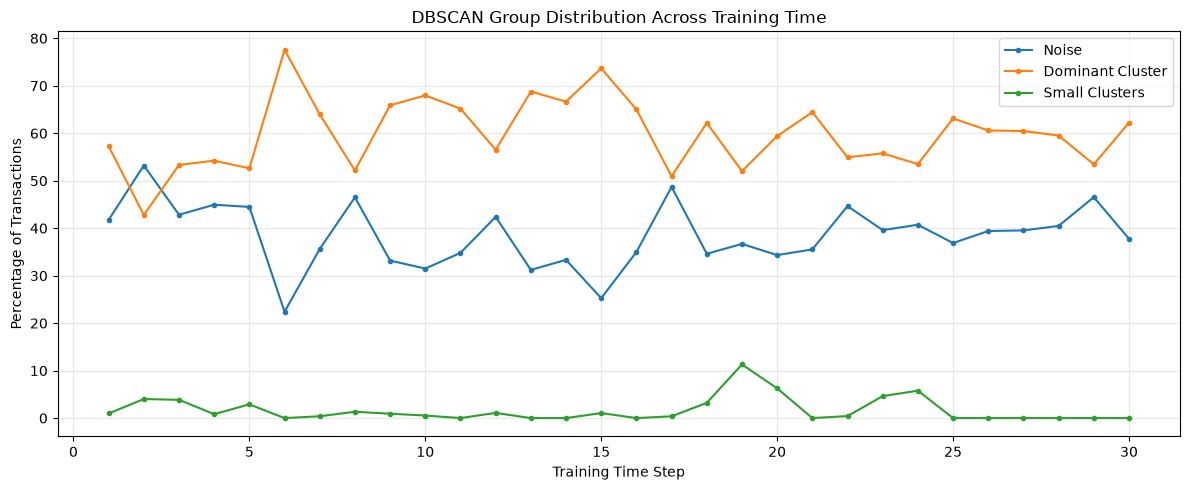


TEMPORAL VARIATION SUMMARY


,Minimum %,Maximum %,Range (percentage points)
Behavior Group,,,
Noise,22.4044,53.2086,30.8042
Dominant Cluster,42.7807,77.5956,34.8149
Small Clusters,0.0000,11.2903,11.2903



VALIDATION CHECKS
All 10000 sampled transactions included: True
All time steps are within training period: True
Exactly 30 training time steps represented: True
All group counts preserved: True
Each time step sums to 100%: True
No external transaction labels used: True

DBSCAN temporal analysis completed.


In [ ]:

# Step 0.8.10 - Analyze DBSCAN groups across training time steps

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("DBSCAN - TIME-STEP DISTRIBUTION ANALYSIS")
print("=" * 65)

# Create time-step mapping for the sampled training transactions
dbscan_temporal_data = pd.DataFrame({
    "Time step": tx_features.loc[
        X_dbscan_sample.index, "Time step"
    ].to_numpy(),

    "Behavior Group": dbscan_behavior_data[
        "Behavior Group"
    ].to_numpy()
})

group_order = [
    "Noise",
    "Dominant Cluster",
    "Small Clusters"
]

# Count transactions by time step and DBSCAN group
dbscan_temporal_counts = pd.crosstab(
    dbscan_temporal_data["Time step"],
    dbscan_temporal_data["Behavior Group"]
).reindex(
    columns=group_order,
    fill_value=0
)

# Convert counts into percentages within each time step
dbscan_temporal_percentages = (
    dbscan_temporal_counts.div(
        dbscan_temporal_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("\nFIRST 10 TRAINING TIME STEPS")
display(
    dbscan_temporal_percentages.head(10).round(3)
)

print("\nLAST 10 TRAINING TIME STEPS")
display(
    dbscan_temporal_percentages.tail(10).round(3)
)

# Plot group proportions across training time
plt.figure(figsize=(12, 5))

for group_name in group_order:
    plt.plot(
        dbscan_temporal_percentages.index,
        dbscan_temporal_percentages[group_name],
        marker="o",
        markersize=3,
        label=group_name
    )

plt.xlabel("Training Time Step")
plt.ylabel("Percentage of Transactions")
plt.title("DBSCAN Group Distribution Across Training Time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Summary of temporal variation
dbscan_temporal_range = pd.DataFrame({
    "Minimum %": dbscan_temporal_percentages.min(),
    "Maximum %": dbscan_temporal_percentages.max(),
    "Range (percentage points)": (
        dbscan_temporal_percentages.max()
        - dbscan_temporal_percentages.min()
    )
})

print("\nTEMPORAL VARIATION SUMMARY")
display(dbscan_temporal_range.round(4))

print("\nVALIDATION CHECKS")

print(
    "All 10000 sampled transactions included:",
    len(dbscan_temporal_data) == 10000
)

print(
    "All time steps are within training period:",
    dbscan_temporal_data["Time step"].between(
        1, 30
    ).all()
)

print(
    "Exactly 30 training time steps represented:",
    len(dbscan_temporal_counts) == 30
)

print(
    "All group counts preserved:",
    dbscan_temporal_counts.sum().tolist()
    == [3880, 5945, 175]
)

print(
    "Each time step sums to 100%:",
    bool(
        np.allclose(
            dbscan_temporal_percentages.sum(axis=1),
            100
        )
    )
)

print(
    "No external transaction labels used:",
    "class" not in dbscan_temporal_data.columns
)

print("\nDBSCAN temporal analysis completed.")


In [ ]:

# Step 0.8.11 - Time-step-stratified DBSCAN label evaluation

import numpy as np
import pandas as pd

print("DBSCAN - TIME-STEP-STRATIFIED LABEL EVALUATION")
print("=" * 65)

# Start with existing post-training evaluation data
dbscan_stratified_eval = dbscan_label_evaluation.copy()

# Attach the time step using transaction ID
dbscan_time_lookup = tx_features.loc[
    X_dbscan_sample.index,
    ["txId", "Time step"]
].copy()

dbscan_time_lookup["txId"] = (
    dbscan_time_lookup["txId"].astype("string")
)

dbscan_stratified_eval = dbscan_stratified_eval.merge(
    dbscan_time_lookup,
    on="txId",
    how="left",
    validate="one_to_one"
)

# Keep known labels only for external evaluation
dbscan_known_eval = dbscan_stratified_eval[
    dbscan_stratified_eval["class"].isin(["1", "2"])
].copy()

dbscan_known_eval["Is Known Illicit"] = (
    dbscan_known_eval["class"] == "1"
).astype(int)

# Calculate within-time-step group statistics
dbscan_step_label_summary = (
    dbscan_known_eval
    .groupby(["Time step", "Behavior Group"])
    ["Is Known Illicit"]
    .agg(
        Known_Count="count",
        Known_Illicit="sum",
        Known_Illicit_Rate="mean"
    )
    .reset_index()
)

dbscan_step_label_summary[
    "Known_Illicit_Rate"
] *= 100

# Compare the two major groups side by side
dbscan_step_rate_comparison = (
    dbscan_step_label_summary[
        dbscan_step_label_summary[
            "Behavior Group"
        ].isin(["Noise", "Dominant Cluster"])
    ]
    .pivot(
        index="Time step",
        columns="Behavior Group",
        values="Known_Illicit_Rate"
    )
    .reindex(
        columns=["Noise", "Dominant Cluster"]
    )
)

dbscan_step_rate_comparison[
    "Dominant Minus Noise (pp)"
] = (
    dbscan_step_rate_comparison["Dominant Cluster"]
    - dbscan_step_rate_comparison["Noise"]
)

print("\nKNOWN ILLICIT RATE BY TIME STEP (%)")
display(dbscan_step_rate_comparison.round(3))

# Known-label counts help judge reliability
dbscan_step_known_counts = (
    dbscan_step_label_summary[
        dbscan_step_label_summary[
            "Behavior Group"
        ].isin(["Noise", "Dominant Cluster"])
    ]
    .pivot(
        index="Time step",
        columns="Behavior Group",
        values="Known_Count"
    )
    .reindex(
        columns=["Noise", "Dominant Cluster"]
    )
    .fillna(0)
    .astype(int)
)

print("\nKNOWN-LABEL COUNTS BY TIME STEP")
display(dbscan_step_known_counts)

# Only compare steps where both groups have known labels
valid_step_comparisons = (
    dbscan_step_rate_comparison[
        "Dominant Minus Noise (pp)"
    ].dropna()
)

print("\nCOMPARISON SUMMARY")
print(
    "Time steps with both groups represented:",
    len(valid_step_comparisons)
)

print(
    "Steps where Dominant Cluster has higher known illicit rate:",
    int((valid_step_comparisons > 0).sum())
)

print(
    "Steps where Noise has higher known illicit rate:",
    int((valid_step_comparisons < 0).sum())
)

print(
    "Steps with equal known illicit rates:",
    int((valid_step_comparisons == 0).sum())
)

print("\nVALIDATION CHECKS")

print(
    "All sampled transactions preserved:",
    len(dbscan_stratified_eval) == 10000
)

print(
    "All time steps successfully matched:",
    dbscan_stratified_eval["Time step"].notna().all()
)

print(
    "Only training time steps included:",
    dbscan_stratified_eval["Time step"]
    .between(1, 30).all()
)

print(
    "Known illicit count preserved:",
    int(dbscan_known_eval["Is Known Illicit"].sum())
    == 252
)

print(
    "Known-labeled total preserved:",
    len(dbscan_known_eval) == 2156
)

print(
    "No labels used to refit DBSCAN:",
    np.array_equal(
        selected_dbscan_labels,
        selected_dbscan_model.labels_
    )
)

print("\nTime-step-stratified evaluation completed.")


DBSCAN - TIME-STEP-STRATIFIED LABEL EVALUATION

KNOWN ILLICIT RATE BY TIME STEP (%)


Behavior Group,Noise,Dominant Cluster,Dominant Minus Noise (pp)
Time step,,,
1,0.741,0.000,-0.741
2,1.493,16.667,15.174
3,0.000,0.000,0.000
4,0.855,8.333,7.479
5,0.000,0.000,0.000
6,0.000,0.000,0.000
7,4.054,37.500,33.446
8,0.000,6.667,6.667
9,0.000,66.667,66.667



KNOWN-LABEL COUNTS BY TIME STEP


Behavior Group,Noise,Dominant Cluster
Time step,,
1,135,25
2,67,6
3,86,5
4,117,12
5,133,8
6,37,3
7,74,16
8,72,15
9,28,42



COMPARISON SUMMARY
Time steps with both groups represented: 30
Steps where Dominant Cluster has higher known illicit rate: 25
Steps where Noise has higher known illicit rate: 1
Steps with equal known illicit rates: 4

VALIDATION CHECKS
All sampled transactions preserved: True
All time steps successfully matched: True
Only training time steps included: True
Known illicit count preserved: True
Known-labeled total preserved: True
No labels used to refit DBSCAN: True

Time-step-stratified evaluation completed.


In [ ]:

# Step 0.8.12 - Time-step-adjusted DBSCAN association
# External labels are used only for post-training evaluation.

import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import StratifiedTable

print("DBSCAN - MANTEL-HAENSZEL STRATIFIED ANALYSIS")
print("=" * 65)

# Use only known-labeled transactions from the two major groups
mh_eval = dbscan_known_eval[
    dbscan_known_eval["Behavior Group"].isin(
        ["Dominant Cluster", "Noise"]
    )
].copy()

mh_tables = []
mh_step_records = []

# Construct one 2x2 contingency table per training time step
for step in range(1, 31):
    step_data = mh_eval[
        mh_eval["Time step"] == step
    ]

    dominant = step_data[
        step_data["Behavior Group"] == "Dominant Cluster"
    ]

    noise = step_data[
        step_data["Behavior Group"] == "Noise"
    ]

    a = int(dominant["Is Known Illicit"].sum())
    b = int(len(dominant) - a)
    c = int(noise["Is Known Illicit"].sum())
    d = int(len(noise) - c)

    table = np.array([
        [a, b],
        [c, d]
    ], dtype=int)

    mh_tables.append(table)

    mh_step_records.append({
        "Time step": step,
        "Dominant Illicit": a,
        "Dominant Licit": b,
        "Noise Illicit": c,
        "Noise Licit": d
    })

mh_contingency_summary = pd.DataFrame(
    mh_step_records
)

print("\nFIRST FIVE STRATIFIED TABLES")
display(mh_contingency_summary.head())

# Calculate Mantel-Haenszel pooled odds ratio
mh_result = StratifiedTable(mh_tables)

mh_odds_ratio = float(
    mh_result.oddsratio_pooled
)

mh_ci_lower, mh_ci_upper = (
    mh_result.oddsratio_pooled_confint()
)

mh_null_test = mh_result.test_null_odds()
mh_p_value = float(mh_null_test.pvalue)

print("\nTIME-STEP-ADJUSTED ASSOCIATION")
print(
    "Mantel-Haenszel pooled odds ratio:",
    round(mh_odds_ratio, 4)
)

print(
    "95% confidence interval:",
    (
        round(float(mh_ci_lower), 4),
        round(float(mh_ci_upper), 4)
    )
)

print(
    "Null odds ratio test p-value:",
    mh_p_value
)

print("\nINTERPRETATION GUIDE")
print("OR > 1: Higher known-illicit odds in Dominant Cluster")
print("OR = 1: No pooled association")
print("OR < 1: Higher known-illicit odds in Noise")
print(
    "Note: This is in-sample association, "
    "not future predictive performance."
)

print("\nVALIDATION CHECKS")

print(
    "Exactly 30 time-step tables:",
    len(mh_tables) == 30
)

print(
    "Every table has shape 2x2:",
    all(table.shape == (2, 2) for table in mh_tables)
)

print(
    "All contingency counts are nonnegative:",
    all(np.all(table >= 0) for table in mh_tables)
)

print(
    "All major-group known labels accounted for:",
    sum(table.sum() for table in mh_tables)
    == 1563 + 535
)

print(
    "Dominant known illicit count preserved:",
    sum(table[0, 0] for table in mh_tables) == 232
)

print(
    "Noise known illicit count preserved:",
    sum(table[1, 0] for table in mh_tables) == 20
)

print(
    "Pooled odds ratio is positive and finite:",
    np.isfinite(mh_odds_ratio) and mh_odds_ratio > 0
)

print("\nMantel-Haenszel evaluation completed.")


ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.4 MB 11.2 MB/s eta 0:00:01
   ------- -------------------------------- 2.1/11.4 MB 11.7 MB/s eta 0:00:01
   ----------- ---------------------------- 3.1/11.4 MB 6.6 MB/s eta 0:00:02
   ---------------- ----------------------- 4.7/11.4 MB 5.8 MB/s eta 0:00:02
   ------------------ --------------------- 5.2/11.4 MB 6.1 MB/s eta 0:00:01
   ------------------------- -------------- 7.3/11.4 MB 6.2 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.4 MB 6.0 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.4 MB 5.3 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.4 MB 5.5 MB/s eta 0:00:01
   ----------------------------------- ---- 10.2/11.4 MB 5.4 MB/s eta 0:00:01
   ------------------------------------ --- 10.5/11.4 MB 5.0 MB/s eta 0:00:01
   ------------------------------------- -- 10.7/11.4 MB 4.3 MB/s eta 0:00:01


In [ ]:

# Verify statsmodels without restarting the Jupyter kernel

import statsmodels
from statsmodels.stats.contingency_tables import StratifiedTable

print("statsmodels version:", statsmodels.__version__)
print("StratifiedTable import successful!")

# Check that our existing DBSCAN results are still available
print("DBSCAN model available:", "selected_dbscan_model" in globals())
print("Known-label evaluation available:", "dbscan_known_eval" in globals())
print("Time-step evaluation available:", "dbscan_stratified_eval" in globals())

print("\nEnvironment verification completed.")


statsmodels version: 0.15.0
StratifiedTable import successful!
DBSCAN model available: True
Known-label evaluation available: True
Time-step evaluation available: True

Environment verification completed.


In [ ]:

# Step 0.8.12 - Time-step-adjusted DBSCAN association
# External labels are used only for post-training evaluation.

import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import StratifiedTable

print("DBSCAN - MANTEL-HAENSZEL STRATIFIED ANALYSIS")
print("=" * 65)

# Use only known-labeled transactions from the two major groups
mh_eval = dbscan_known_eval[
    dbscan_known_eval["Behavior Group"].isin(
        ["Dominant Cluster", "Noise"]
    )
].copy()

mh_tables = []
mh_step_records = []

# Construct one 2x2 contingency table per training time step
for step in range(1, 31):
    step_data = mh_eval[
        mh_eval["Time step"] == step
    ]

    dominant = step_data[
        step_data["Behavior Group"] == "Dominant Cluster"
    ]

    noise = step_data[
        step_data["Behavior Group"] == "Noise"
    ]

    a = int(dominant["Is Known Illicit"].sum())
    b = int(len(dominant) - a)
    c = int(noise["Is Known Illicit"].sum())
    d = int(len(noise) - c)

    table = np.array([
        [a, b],
        [c, d]
    ], dtype=int)

    mh_tables.append(table)

    mh_step_records.append({
        "Time step": step,
        "Dominant Illicit": a,
        "Dominant Licit": b,
        "Noise Illicit": c,
        "Noise Licit": d
    })

mh_contingency_summary = pd.DataFrame(
    mh_step_records
)

print("\nFIRST FIVE STRATIFIED TABLES")
display(mh_contingency_summary.head())

# Calculate Mantel-Haenszel pooled odds ratio
mh_result = StratifiedTable(mh_tables)

mh_odds_ratio = float(
    mh_result.oddsratio_pooled
)

mh_ci_lower, mh_ci_upper = (
    mh_result.oddsratio_pooled_confint()
)

mh_null_test = mh_result.test_null_odds()
mh_p_value = float(mh_null_test.pvalue)

print("\nTIME-STEP-ADJUSTED ASSOCIATION")
print(
    "Mantel-Haenszel pooled odds ratio:",
    round(mh_odds_ratio, 4)
)

print(
    "95% confidence interval:",
    (
        round(float(mh_ci_lower), 4),
        round(float(mh_ci_upper), 4)
    )
)

print(
    "Null odds ratio test p-value:",
    mh_p_value
)

print("\nINTERPRETATION GUIDE")
print("OR > 1: Higher known-illicit odds in Dominant Cluster")
print("OR = 1: No pooled association")
print("OR < 1: Higher known-illicit odds in Noise")
print(
    "Note: This is in-sample association, "
    "not future predictive performance."
)

print("\nVALIDATION CHECKS")

print(
    "Exactly 30 time-step tables:",
    len(mh_tables) == 30
)

print(
    "Every table has shape 2x2:",
    all(table.shape == (2, 2) for table in mh_tables)
)

print(
    "All contingency counts are nonnegative:",
    all(np.all(table >= 0) for table in mh_tables)
)

print(
    "All major-group known labels accounted for:",
    sum(table.sum() for table in mh_tables)
    == 1563 + 535
)

print(
    "Dominant known illicit count preserved:",
    sum(table[0, 0] for table in mh_tables) == 232
)

print(
    "Noise known illicit count preserved:",
    sum(table[1, 0] for table in mh_tables) == 20
)

print(
    "Pooled odds ratio is positive and finite:",
    np.isfinite(mh_odds_ratio) and mh_odds_ratio > 0
)

print("\nMantel-Haenszel evaluation completed.")


DBSCAN - MANTEL-HAENSZEL STRATIFIED ANALYSIS

FIRST FIVE STRATIFIED TABLES


,Time step,Dominant Illicit,Dominant Licit,Noise Illicit,Noise Licit
0,1,0,25,1,134
1,2,1,5,1,66
2,3,0,5,0,86
3,4,1,11,1,116
4,5,0,8,0,133



TIME-STEP-ADJUSTED ASSOCIATION
Mantel-Haenszel pooled odds ratio: 47.8107
95% confidence interval: (28.4111, 80.4567)
Null odds ratio test p-value: 0.0

INTERPRETATION GUIDE
OR > 1: Higher known-illicit odds in Dominant Cluster
OR = 1: No pooled association
OR < 1: Higher known-illicit odds in Noise
Note: This is in-sample association, not future predictive performance.

VALIDATION CHECKS
Exactly 30 time-step tables: True
Every table has shape 2x2: True
All contingency counts are nonnegative: True
All major-group known labels accounted for: True
Dominant known illicit count preserved: True
Noise known illicit count preserved: True
Pooled odds ratio is positive and finite: True

Mantel-Haenszel evaluation completed.


In [ ]:

# Step 0.8.13 - Audit label availability by DBSCAN group and time step

import numpy as np
import pandas as pd

print("DBSCAN - LABEL AVAILABILITY AUDIT")
print("=" * 65)

# Use existing post-training evaluation data
dbscan_coverage_eval = dbscan_stratified_eval.copy()

# Known labels are classes 1 and 2.
# Class 3 remains unknown, NOT licit.
dbscan_coverage_eval["Has Known Label"] = (
    dbscan_coverage_eval["class"].isin(["1", "2"])
).astype(int)

group_order = [
    "Noise",
    "Dominant Cluster",
    "Small Clusters"
]

# Overall label coverage
dbscan_overall_coverage = (
    dbscan_coverage_eval
    .groupby("Behavior Group")["Has Known Label"]
    .agg(
        Total="count",
        Known="sum"
    )
    .reindex(group_order)
)

dbscan_overall_coverage["Unknown"] = (
    dbscan_overall_coverage["Total"]
    - dbscan_overall_coverage["Known"]
)

dbscan_overall_coverage["Coverage %"] = (
    100
    * dbscan_overall_coverage["Known"]
    / dbscan_overall_coverage["Total"]
)

print("\nOVERALL LABEL AVAILABILITY")
display(dbscan_overall_coverage.round(4))

# Coverage within each time step
dbscan_step_coverage = (
    dbscan_coverage_eval
    .groupby(["Time step", "Behavior Group"])[
        "Has Known Label"
    ]
    .agg(
        Total="count",
        Known="sum"
    )
    .reset_index()
)

dbscan_step_coverage["Coverage %"] = (
    100
    * dbscan_step_coverage["Known"]
    / dbscan_step_coverage["Total"]
)

dbscan_coverage_pivot = (
    dbscan_step_coverage
    .pivot(
        index="Time step",
        columns="Behavior Group",
        values="Coverage %"
    )
    .reindex(columns=group_order)
)

print("\nFIRST 10 TIME STEPS - LABEL COVERAGE (%)")
display(dbscan_coverage_pivot.head(10).round(3))

print("\nLAST 10 TIME STEPS - LABEL COVERAGE (%)")
display(dbscan_coverage_pivot.tail(10).round(3))

# Compare coverage between the two major groups
dbscan_major_coverage_gap = (
    dbscan_coverage_pivot["Noise"]
    - dbscan_coverage_pivot["Dominant Cluster"]
).dropna()

print("\nCOVERAGE GAP SUMMARY")

print(
    "Steps with both major groups present:",
    len(dbscan_major_coverage_gap)
)

print(
    "Steps where Noise has higher label coverage:",
    int((dbscan_major_coverage_gap > 0).sum())
)

print(
    "Steps where Dominant Cluster has higher coverage:",
    int((dbscan_major_coverage_gap < 0).sum())
)

print(
    "Median Noise-minus-Dominant coverage gap (pp):",
    round(dbscan_major_coverage_gap.median(), 4)
)

print("\nVALIDATION CHECKS")

print(
    "All 10000 transactions preserved:",
    len(dbscan_coverage_eval) == 10000
)

print(
    "Overall group counts preserved:",
    dbscan_overall_coverage["Total"].tolist()
    == [3880, 5945, 175]
)

print(
    "Known-label counts preserved:",
    dbscan_overall_coverage["Known"].tolist()
    == [1563, 535, 58]
)

print(
    "Unknown labels not treated as licit:",
    int(
        (
            dbscan_coverage_eval["class"] == "3"
        ).sum()
    ) == int(
        dbscan_overall_coverage["Unknown"].sum()
    )
)

print(
    "All coverage percentages valid:",
    bool(
        dbscan_overall_coverage["Coverage %"]
        .between(0, 100).all()
    )
)

print(
    "No DBSCAN model retraining:",
    np.array_equal(
        selected_dbscan_labels,
        selected_dbscan_model.labels_
    )
)

print("\nDBSCAN label availability audit completed.")


DBSCAN - LABEL AVAILABILITY AUDIT

OVERALL LABEL AVAILABILITY


,Total,Known,Unknown,Coverage %
Behavior Group,,,,
Noise,3880,1563,2317,40.2835
Dominant Cluster,5945,535,5410,8.9992
Small Clusters,175,58,117,33.1429



FIRST 10 TIME STEPS - LABEL COVERAGE (%)


Behavior Group,Noise,Dominant Cluster,Small Clusters
Time step,,,
1,52.326,7.062,66.667
2,33.668,3.750,53.333
3,35.102,1.639,13.636
4,53.670,4.563,100.000
5,54.065,2.749,100.000
6,45.122,1.056,NaN
7,39.785,4.790,0.000
8,51.429,9.554,0.000
9,19.444,14.685,0.000



LAST 10 TIME STEPS - LABEL COVERAGE (%)


Behavior Group,Noise,Dominant Cluster,Small Clusters
Time step,,,
21,32.353,9.730,NaN
22,51.174,16.794,100.0
23,52.555,10.363,75.0
24,36.567,9.091,0.0
25,37.879,14.159,NaN
26,43.750,9.756,NaN
27,32.353,3.846,NaN
28,31.373,8.000,NaN
29,33.143,24.378,NaN



COVERAGE GAP SUMMARY
Steps with both major groups present: 30
Steps where Noise has higher label coverage: 30
Steps where Dominant Cluster has higher coverage: 0
Median Noise-minus-Dominant coverage gap (pp): 29.1567

VALIDATION CHECKS
All 10000 transactions preserved: True
Overall group counts preserved: True
Known-label counts preserved: True
Unknown labels not treated as licit: True
All coverage percentages valid: True
No DBSCAN model retraining: True

DBSCAN label availability audit completed.


In [ ]:

# Step 0.8.14 - Create reproducible DBSCAN experiment summary

import numpy as np
import pandas as pd

print("DBSCAN - EXPERIMENT SUMMARY")
print("=" * 65)

# Retrieve previously computed metrics
selected_quality = dbscan_quality_comparison.loc[
    np.isclose(
        dbscan_quality_comparison["eps"],
        selected_dbscan_eps
    )
].iloc[0]

dbscan_experiment_summary = pd.DataFrame([
    {
        "Metric": "Training sample size",
        "Value": len(X_dbscan_sample)
    },
    {
        "Metric": "Input features",
        "Value": X_dbscan_sample.shape[1]
    },
    {
        "Metric": "Selected eps (provisional)",
        "Value": selected_dbscan_eps
    },
    {
        "Metric": "min_samples",
        "Value": dbscan_min_samples
    },
    {
        "Metric": "Number of clusters",
        "Value": int(selected_quality["Clusters"])
    },
    {
        "Metric": "Noise percentage",
        "Value": round(
            float(selected_quality["Noise %"]), 4
        )
    },
    {
        "Metric": "Largest cluster percentage",
        "Value": round(
            float(
                selected_quality[
                    "Largest Cluster % of All"
                ]
            ), 4
        )
    },
    {
        "Metric": "Sampled silhouette",
        "Value": round(
            float(
                selected_quality["Sampled Silhouette"]
            ), 4
        )
    },
    {
        "Metric": "Noise known illicit percentage",
        "Value": round(
            float(
                dbscan_label_counts.loc[
                    "Noise", "Illicit % of Known"
                ]
            ), 4
        )
    },
    {
        "Metric": "Dominant known illicit percentage",
        "Value": round(
            float(
                dbscan_label_counts.loc[
                    "Dominant Cluster",
                    "Illicit % of Known"
                ]
            ), 4
        )
    },
    {
        "Metric": "Dominant enrichment ratio",
        "Value": round(
            float(
                dbscan_enrichment.loc[
                    "Dominant Cluster",
                    "Enrichment Ratio"
                ]
            ), 4
        )
    },
    {
        "Metric": "Mantel-Haenszel pooled OR",
        "Value": round(mh_odds_ratio, 4)
    },
    {
        "Metric": "Noise known-label coverage %",
        "Value": round(
            float(
                dbscan_overall_coverage.loc[
                    "Noise", "Coverage %"
                ]
            ), 4
        )
    },
    {
        "Metric": "Dominant known-label coverage %",
        "Value": round(
            float(
                dbscan_overall_coverage.loc[
                    "Dominant Cluster",
                    "Coverage %"
                ]
            ), 4
        )
    }
])

display(dbscan_experiment_summary)

print("\nMETHODOLOGICAL NOTES")
print(
    "1. DBSCAN was fitted on a reproducible "
    "10000-row training sample."
)
print(
    "2. External labels were not used for clustering."
)
print(
    "3. Noise membership does not establish illicit activity."
)
print(
    "4. Label enrichment and pooled odds ratio "
    "are in-sample associations."
)
print(
    "5. Label availability differs substantially "
    "between groups."
)
print(
    "6. Independent validation performance "
    "has not been established."
)
print(
    "7. Held-out test transactions remain untouched."
)

print("\nVALIDATION CHECKS")

print(
    "Fourteen summary metrics recorded:",
    len(dbscan_experiment_summary) == 14
)

print(
    "Training sample size correct:",
    dbscan_experiment_summary.loc[
        dbscan_experiment_summary["Metric"]
        == "Training sample size", "Value"
    ].iloc[0] == 10000
)

print(
    "Input feature count correct:",
    X_dbscan_sample.shape[1] == 165
)

print(
    "Selected DBSCAN model still available:",
    selected_dbscan_eps in dbscan_candidate_models
)

print(
    "External labels remain separate from features:",
    "class" not in X_dbscan_sample.columns
)

print("\nDBSCAN experiment summary completed.")


DBSCAN - EXPERIMENT SUMMARY


,Metric,Value
0,Training sample size,10000.0000
1,Input features,165.0000
2,Selected eps (provisional),4.5000
3,min_samples,10.0000
4,Number of clusters,10.0000
5,Noise percentage,38.8000
6,Largest cluster percentage,59.4500
7,Sampled silhouette,0.2128
8,Noise known illicit percentage,1.2796
9,Dominant known illicit percentage,43.3645



METHODOLOGICAL NOTES
1. DBSCAN was fitted on a reproducible 10000-row training sample.
2. External labels were not used for clustering.
3. Noise membership does not establish illicit activity.
4. Label enrichment and pooled odds ratio are in-sample associations.
5. Label availability differs substantially between groups.
6. Independent validation performance has not been established.
7. Held-out test transactions remain untouched.

VALIDATION CHECKS
Fourteen summary metrics recorded: True
Training sample size correct: True
Input feature count correct: True
Selected DBSCAN model still available: True
External labels remain separate from features: True

DBSCAN experiment summary completed.


In [31]:

# Step 0.9.1 - Prepare training data for Local Outlier Factor

import numpy as np
import pandas as pd

print("LOCAL OUTLIER FACTOR - DATA PREPARATION")
print("=" * 65)

# Reuse the existing training-only scaled representation
# used for K-Means and DBSCAN.
lof_feature_columns = X_cluster_train_scaled.columns.tolist()

# Reuse the same reproducible 10,000-row training sample
# used in our DBSCAN experiment.
X_lof_train = X_dbscan_sample.copy()

# Keep the full chronological validation set separate.
# Do not use validation data to fit LOF.
X_lof_val = X_cluster_val_scaled[
    lof_feature_columns
].copy()

print("\nDATASET SHAPES")
print("LOF training sample:", X_lof_train.shape)
print("LOF validation data:", X_lof_val.shape)

print("\nFEATURE INFORMATION")
print("Number of features:", len(lof_feature_columns))
print("Training transactions:", len(X_lof_train))
print("Validation transactions:", len(X_lof_val))

print("\nVALIDATION CHECKS")

print(
    "Training sample contains 10000 transactions:",
    X_lof_train.shape[0] == 10000
)

print(
    "Validation set contains 33835 transactions:",
    X_lof_val.shape[0] == 33835
)

print(
    "Both datasets contain 165 features:",
    X_lof_train.shape[1] == 165
    and X_lof_val.shape[1] == 165
)

print(
    "Training and validation feature order matches:",
    X_lof_train.columns.equals(X_lof_val.columns)
)

print(
    "No overlapping transaction rows:",
    X_lof_train.index.intersection(
        X_lof_val.index
    ).empty
)

print(
    "All training values are finite:",
    bool(np.isfinite(X_lof_train.to_numpy()).all())
)

print(
    "All validation values are finite:",
    bool(np.isfinite(X_lof_val.to_numpy()).all())
)

print(
    "No external labels included:",
    "class" not in X_lof_train.columns
    and "class" not in X_lof_val.columns
)

print("\nLOF data preparation completed.")


LOCAL OUTLIER FACTOR - DATA PREPARATION

DATASET SHAPES
LOF training sample: (10000, 165)
LOF validation data: (33835, 165)

FEATURE INFORMATION
Number of features: 165
Training transactions: 10000
Validation transactions: 33835

VALIDATION CHECKS
Training sample contains 10000 transactions: True
Validation set contains 33835 transactions: True
Both datasets contain 165 features: True
Training and validation feature order matches: True
No overlapping transaction rows: True
All training values are finite: True
All validation values are finite: True
No external labels included: True

LOF data preparation completed.


In [32]:

# Step 0.9.2 - Train the first Local Outlier Factor model

import numpy as np
import pandas as pd
import time

from sklearn.neighbors import LocalOutlierFactor

print("LOCAL OUTLIER FACTOR - BASELINE TRAINING")
print("=" * 65)

# Define baseline LOF configuration
lof_n_neighbors = 20

lof_baseline_model = LocalOutlierFactor(
    n_neighbors=lof_n_neighbors,
    metric="euclidean",
    novelty=True,
    contamination="auto",
    n_jobs=-1
)

print("\nMODEL CONFIGURATION")
print("Algorithm: Local Outlier Factor")
print("Number of neighbors:", lof_n_neighbors)
print("Distance metric: Euclidean")
print("Novelty detection enabled:", True)
print("Training samples:", len(X_lof_train))
print("Input features:", X_lof_train.shape[1])

# Fit on training transactions only
print("\nTraining LOF model...")

lof_start_time = time.perf_counter()

lof_baseline_model.fit(X_lof_train)

lof_training_seconds = (
    time.perf_counter() - lof_start_time
)

print("\nTRAINING COMPLETED")
print(
    "Training time (seconds):",
    round(lof_training_seconds, 3)
)

# Inspect original training outlier factors
# Lower negative_outlier_factor_ means more unusual.
lof_train_outlier_factors = (
    lof_baseline_model.negative_outlier_factor_
)

# Convert to an intuitive direction:
# Higher value = more locally anomalous.
lof_train_anomaly_factors = (
    -lof_train_outlier_factors
)

print("\nTRAINING OUTLIER FACTOR SUMMARY")

display(
    pd.Series(
        lof_train_anomaly_factors,
        name="LOF Anomaly Factor"
    ).describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame()
)

print("\nVALIDATION CHECKS")

print(
    "Model uses 20 neighbors:",
    lof_baseline_model.n_neighbors_ == 20
)

print(
    "Novelty detection enabled:",
    lof_baseline_model.novelty is True
)

print(
    "Model fitted on 10000 transactions:",
    lof_baseline_model.n_samples_fit_ == 10000
)

print(
    "Training factor count matches:",
    len(lof_train_anomaly_factors) == 10000
)

print(
    "All training factors are finite:",
    bool(
        np.isfinite(
            lof_train_anomaly_factors
        ).all()
    )
)

print(
    "All anomaly factors are positive:",
    bool(
        (lof_train_anomaly_factors > 0).all()
    )
)

print(
    "Validation data was not used for fitting:",
    lof_baseline_model.n_samples_fit_
    == len(X_lof_train)
)

print("\nLOF baseline training completed.")


LOCAL OUTLIER FACTOR - BASELINE TRAINING

MODEL CONFIGURATION
Algorithm: Local Outlier Factor
Number of neighbors: 20
Distance metric: Euclidean
Novelty detection enabled: True
Training samples: 10000
Input features: 165

Training LOF model...

TRAINING COMPLETED
Training time (seconds): 1.366

TRAINING OUTLIER FACTOR SUMMARY


,LOF Anomaly Factor
count,10000.000000
mean,1.275649
std,0.536619
min,0.946536
25%,1.028359
50%,1.118077
75%,1.327468
90%,1.711818
95%,1.978936
99%,3.253643



VALIDATION CHECKS
Model uses 20 neighbors: True
Novelty detection enabled: True
Model fitted on 10000 transactions: True
Training factor count matches: True
All training factors are finite: True
All anomaly factors are positive: True
Validation data was not used for fitting: True

LOF baseline training completed.


In [33]:

# Step 0.9.3 - Score unseen validation transactions using LOF

import numpy as np
import pandas as pd
import time

print("LOCAL OUTLIER FACTOR - VALIDATION SCORING")
print("=" * 65)

print("\nScoring unseen validation transactions...")

lof_scoring_start = time.perf_counter()

# Novelty scores: lower = more anomalous
lof_raw_validation_scores = (
    lof_baseline_model.score_samples(X_lof_val)
)

# Reverse direction for consistent interpretation
# Higher = more anomalous
lof_val_anomaly_scores = pd.Series(
    -lof_raw_validation_scores,
    index=X_lof_val.index,
    name="LOF Anomaly Score"
)

lof_scoring_seconds = (
    time.perf_counter() - lof_scoring_start
)

print("\nVALIDATION SCORING COMPLETED")
print(
    "Scoring time (seconds):",
    round(lof_scoring_seconds, 3)
)

print(
    "Transactions scored:",
    len(lof_val_anomaly_scores)
)

print("\nVALIDATION ANOMALY SCORE SUMMARY")

display(
    lof_val_anomaly_scores.describe(
        percentiles=[
            0.25, 0.50, 0.75,
            0.90, 0.95, 0.99
        ]
    ).to_frame()
)

# Inspect the 10 most anomalous validation transactions
lof_top_10 = (
    lof_val_anomaly_scores
    .nlargest(10)
    .to_frame()
)

# Attach transaction identifiers for interpretation only
lof_top_10["txId"] = tx_features.loc[
    lof_top_10.index,
    "txId"
].to_numpy()

lof_top_10["Time step"] = tx_features.loc[
    lof_top_10.index,
    "Time step"
].to_numpy()

print("\nTOP 10 VALIDATION OUTLIER CANDIDATES")
display(
    lof_top_10[
        ["txId", "Time step", "LOF Anomaly Score"]
    ]
)

print("\nVALIDATION CHECKS")

print(
    "Exactly 33835 transactions scored:",
    len(lof_val_anomaly_scores) == 33835
)

print(
    "All scores are finite:",
    bool(
        np.isfinite(
            lof_val_anomaly_scores.to_numpy()
        ).all()
    )
)

print(
    "All anomaly scores are positive:",
    bool(
        (lof_val_anomaly_scores > 0).all()
    )
)

print(
    "Validation row indices preserved:",
    lof_val_anomaly_scores.index.equals(
        X_lof_val.index
    )
)

print(
    "Top 10 contains 10 unique transactions:",
    lof_top_10["txId"].nunique() == 10
)

print(
    "Top 10 transactions belong to validation steps:",
    bool(
        lof_top_10["Time step"]
        .between(31, 39).all()
    )
)

print(
    "No external labels used in scoring:",
    "class" not in X_lof_val.columns
)

print("\nLOF validation scoring completed.")


LOCAL OUTLIER FACTOR - VALIDATION SCORING

Scoring unseen validation transactions...


d:\anaconda\envs\btc-analysis\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(



VALIDATION SCORING COMPLETED
Scoring time (seconds): 0.791
Transactions scored: 33835

VALIDATION ANOMALY SCORE SUMMARY


,LOF Anomaly Score
count,33835.000000
mean,1.528067
std,1.085276
min,0.962536
25%,1.202311
50%,1.345740
75%,1.616314
90%,2.083113
95%,2.395455
99%,4.187389



TOP 10 VALIDATION OUTLIER CANDIDATES


,txId,Time step,LOF Anomaly Score
139965,69599555,35,106.606683
140176,69727711,35,106.601339
145141,200505744,36,48.487043
141266,100804290,35,22.327396
153859,19631882,39,18.331264
153856,19631677,39,18.330939
153864,19631913,39,18.327434
153857,19631685,39,18.326564
153862,19631896,39,18.326484
153860,19631887,39,18.325282



VALIDATION CHECKS
Exactly 33835 transactions scored: True
All scores are finite: True
All anomaly scores are positive: True
Validation row indices preserved: True
Top 10 contains 10 unique transactions: True
Top 10 transactions belong to validation steps: True
No external labels used in scoring: True

LOF validation scoring completed.


LOCAL OUTLIER FACTOR - TEMPORAL SCORE ANALYSIS

LOF SCORE DISTRIBUTION BY VALIDATION TIME STEP


,Count,Mean,Median,Maximum,95th Percentile,99th Percentile
Time step,,,,,,
31,2816,1.4313,1.2317,17.6849,2.2621,5.0045
32,4525,1.4216,1.2518,7.9000,2.2242,5.0636
33,3151,1.3822,1.2974,12.6420,1.9131,2.7025
34,2486,1.4762,1.3458,12.9267,2.3125,3.0774
35,5507,1.5678,1.3653,106.6067,2.3337,4.4786
36,6393,1.5503,1.3569,48.4870,2.3729,3.4279
37,3306,1.5358,1.3590,7.5972,2.4382,4.0954
38,2891,1.6474,1.4740,10.4396,2.6019,4.2734
39,2760,1.7498,1.5036,18.3313,2.7890,5.4947



TOP 1% VALIDATION OUTLIERS BY TIME STEP
Descriptive top-1% threshold: 4.187389


,Top1_Count,Total,Top1_Percentage
Time step,,,
31,40,2816,1.4205
32,64,4525,1.4144
33,15,3151,0.4760
34,4,2486,0.1609
35,67,5507,1.2166
36,36,6393,0.5631
37,30,3306,0.9074
38,31,2891,1.0723
39,52,2760,1.8841


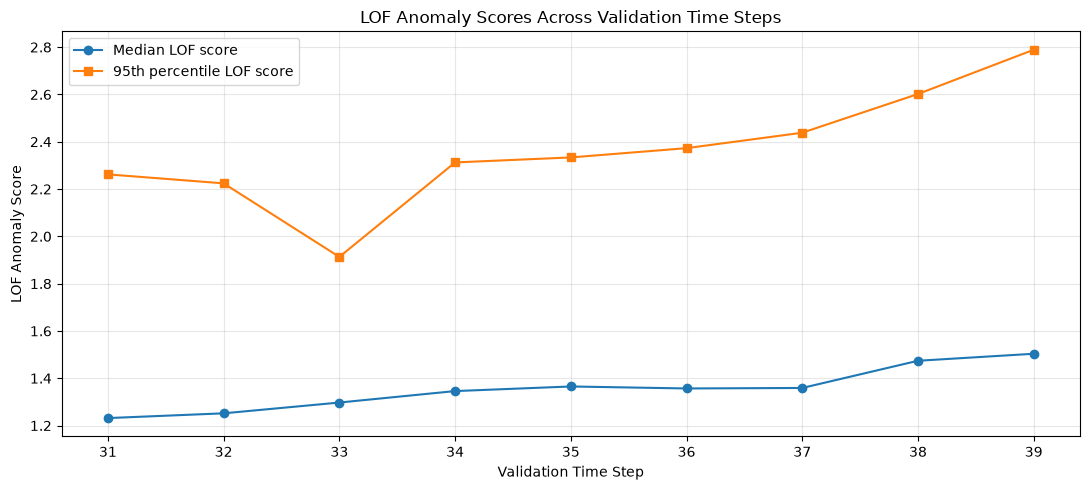


VALIDATION CHECKS
All 33835 validation transactions represented: True
Exactly nine validation time steps: True
Only time steps 31-39 included: True
All anomaly scores are finite: True
All time-step counts sum correctly: True
Top-1% count is approximately 1%: True
No external labels used: True

LOF temporal score analysis completed.


In [34]:

# Step 0.9.4 - LOF validation anomaly scores by time step

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("LOCAL OUTLIER FACTOR - TEMPORAL SCORE ANALYSIS")
print("=" * 65)

# Preserve validation transaction row alignment
lof_temporal_scores = pd.DataFrame({
    "Time step": tx_features.loc[
        lof_val_anomaly_scores.index,
        "Time step"
    ].to_numpy(),

    "LOF Anomaly Score": (
        lof_val_anomaly_scores.to_numpy()
    )
}, index=lof_val_anomaly_scores.index)

# Calculate score statistics for each validation time step
lof_temporal_summary = (
    lof_temporal_scores
    .groupby("Time step")["LOF Anomaly Score"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Maximum="max"
    )
)

# Add upper-tail percentiles
lof_temporal_summary["95th Percentile"] = (
    lof_temporal_scores
    .groupby("Time step")["LOF Anomaly Score"]
    .quantile(0.95)
)

lof_temporal_summary["99th Percentile"] = (
    lof_temporal_scores
    .groupby("Time step")["LOF Anomaly Score"]
    .quantile(0.99)
)

print("\nLOF SCORE DISTRIBUTION BY VALIDATION TIME STEP")
display(lof_temporal_summary.round(4))

# Descriptive top-1% cutoff from validation scores
# Do not treat this as a deployment threshold.
lof_validation_top1_threshold = (
    lof_val_anomaly_scores.quantile(0.99)
)

lof_temporal_scores["Top 1%"] = (
    lof_temporal_scores["LOF Anomaly Score"]
    >= lof_validation_top1_threshold
)

lof_top1_by_step = (
    lof_temporal_scores
    .groupby("Time step")["Top 1%"]
    .agg(
        Top1_Count="sum",
        Total="count"
    )
)

lof_top1_by_step["Top1_Percentage"] = (
    100
    * lof_top1_by_step["Top1_Count"]
    / lof_top1_by_step["Total"]
)

print("\nTOP 1% VALIDATION OUTLIERS BY TIME STEP")
print(
    "Descriptive top-1% threshold:",
    round(lof_validation_top1_threshold, 6)
)

display(lof_top1_by_step.round(4))

# Plot median and 95th percentile over time
plt.figure(figsize=(11, 5))

plt.plot(
    lof_temporal_summary.index,
    lof_temporal_summary["Median"],
    marker="o",
    label="Median LOF score"
)

plt.plot(
    lof_temporal_summary.index,
    lof_temporal_summary["95th Percentile"],
    marker="s",
    label="95th percentile LOF score"
)

plt.xlabel("Validation Time Step")
plt.ylabel("LOF Anomaly Score")
plt.title("LOF Anomaly Scores Across Validation Time Steps")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nVALIDATION CHECKS")

print(
    "All 33835 validation transactions represented:",
    len(lof_temporal_scores) == 33835
)

print(
    "Exactly nine validation time steps:",
    len(lof_temporal_summary) == 9
)

print(
    "Only time steps 31-39 included:",
    lof_temporal_scores["Time step"]
    .between(31, 39).all()
)

print(
    "All anomaly scores are finite:",
    bool(
        np.isfinite(
            lof_temporal_scores["LOF Anomaly Score"]
        ).all()
    )
)

print(
    "All time-step counts sum correctly:",
    int(lof_temporal_summary["Count"].sum())
    == 33835
)

print(
    "Top-1% count is approximately 1%:",
    abs(
        lof_temporal_scores["Top 1%"].mean()
        - 0.01
    ) < 0.002
)

print(
    "No external labels used:",
    "class" not in lof_temporal_scores.columns
)

print("\nLOF temporal score analysis completed.")


In [35]:
from sklearn.metrics import roc_auc_score, average_precision_score

print("LOCAL OUTLIER FACTOR - KNOWN-LABEL VALIDATION")
print("=" * 65)

# Validation transactions and their LOF anomaly scores
lof_validation_eval = tx_features.loc[
    lof_val_anomaly_scores.index,
    ["txId", "Time step"]
].copy()

lof_validation_eval["LOF Anomaly Score"] = (
    lof_val_anomaly_scores
)

# Ensure transaction identifiers have matching dtypes
lof_validation_eval["txId"] = (
    lof_validation_eval["txId"].astype("string")
)

lof_label_lookup = tx_classes[["txId", "class"]].copy()
lof_label_lookup["txId"] = (
    lof_label_lookup["txId"].astype("string")
)

# Join labels only for evaluation
lof_validation_eval = lof_validation_eval.merge(
    lof_label_lookup,
    on="txId",
    how="left",
    validate="one_to_one"
)

# Evaluate only known licit/illicit transactions
lof_known_eval = lof_validation_eval[
    lof_validation_eval["class"].astype(str).isin(["1", "2"])
].copy()

lof_known_eval["is_illicit"] = (
    lof_known_eval["class"].astype(str) == "1"
).astype(int)

y_true = lof_known_eval["is_illicit"]
y_scores = lof_known_eval["LOF Anomaly Score"]

lof_roc_auc = roc_auc_score(y_true, y_scores)
lof_average_precision = average_precision_score(
    y_true, y_scores
)

print("\nKNOWN-LABEL VALIDATION SUMMARY")
print("Known transactions:", len(lof_known_eval))
print("Illicit transactions:", int(y_true.sum()))
print("Licit transactions:", int((1 - y_true).sum()))
print(
    "Unknown transactions excluded:",
    len(lof_validation_eval) - len(lof_known_eval)
)

print("\nEVALUATION METRICS")
print(f"ROC-AUC: {lof_roc_auc:.6f}")
print(f"Average Precision: {lof_average_precision:.6f}")
print(f"Illicit prevalence baseline: {y_true.mean():.6f}")

print("\nVALIDATION CHECKS")
print("All validation transactions matched:",
      lof_validation_eval["class"].notna().all())
print("Known labels are binary:",
      set(y_true.unique()) == {0, 1})
print("All evaluation scores finite:",
      np.isfinite(y_scores).all())
print("Expected known-label count:",
      len(lof_known_eval) == 8475)

LOCAL OUTLIER FACTOR - KNOWN-LABEL VALIDATION

KNOWN-LABEL VALIDATION SUMMARY
Known transactions: 8475
Illicit transactions: 955
Licit transactions: 7520
Unknown transactions excluded: 25360

EVALUATION METRICS
ROC-AUC: 0.413893
Average Precision: 0.088778
Illicit prevalence baseline: 0.112684

VALIDATION CHECKS
All validation transactions matched: True
Known labels are binary: True
All evaluation scores finite: True
Expected known-label count: True


In [36]:
print("STEP 0.9.6 - MODEL COMPARISON PREREQUISITE CHECK")
print("=" * 60)

required_variables = [
    "lof_known_eval",
    "lof_roc_auc",
    "lof_average_precision",
    "if_val_anomaly_scores_a",
    "if_val_anomaly_scores_b"
]

for variable in required_variables:
    if variable in globals():
        print(f"{variable}: AVAILABLE")
    else:
        print(f"{variable}: MISSING")

STEP 0.9.6 - MODEL COMPARISON PREREQUISITE CHECK
lof_known_eval: AVAILABLE
lof_roc_auc: AVAILABLE
lof_average_precision: AVAILABLE
if_val_anomaly_scores_a: MISSING
if_val_anomaly_scores_b: MISSING


In [37]:
print("ISOLATION FOREST - EXISTING VARIABLES")
print("=" * 60)

if_variables = sorted([
    name for name in globals()
    if (
        "if_" in name.lower()
        or "isolation" in name.lower()
        or "forest" in name.lower()
    )
    and not name.startswith("__")
])

if if_variables:
    for name in if_variables:
        obj = globals()[name]
        shape = getattr(obj, "shape", None)

        print(
            f"{name}: {type(obj).__name__}"
            + (f" | Shape: {shape}" if shape is not None else "")
        )
else:
    print("No Isolation Forest variables found.")
    

ISOLATION FOREST - EXISTING VARIABLES
No Isolation Forest variables found.


In [43]:
print("ISOLATION FOREST - VALIDATION SCORE CHECK")
print("=" * 60)

for name, value in sorted(globals().items()):
    if (
        ("score" in name.lower() or "anomal" in name.lower())
        and ("if_" in name.lower() or "isolation" in name.lower())
        and not name.startswith("__")
    ):
        print(
            name,
            "| Type:", type(value).__name__,
            "| Shape:", getattr(value, "shape", "N/A")
        )

ISOLATION FOREST - VALIDATION SCORE CHECK


In [50]:
ids_a = set(val_anomaly_results["txId"].astype("string"))
ids_b = set(val_anomaly_results_b["txId"].astype("string"))

print("Baseline A unique IDs:", len(ids_a))
print("Baseline B unique IDs:", len(ids_b))
print("IDs only in A:", len(ids_a - ids_b))
print("IDs only in B:", len(ids_b - ids_a))
print("Same ID sets:", ids_a == ids_b)

NameError: name 'val_anomaly_results' is not defined

In [51]:
ids_a = set(X_val_a["txId"].astype("string")) if "txId" in X_val_a.columns else set(tx_features.loc[X_val_a.index, "txId"].astype("string"))

ids_b = set(X_val_b["txId"].astype("string")) if "txId" in X_val_b.columns else set(tx_features.loc[X_val_b.index, "txId"].astype("string"))

print("Baseline A unique IDs:", len(ids_a))
print("Baseline B unique IDs:", len(ids_b))
print("IDs only in A:", len(ids_a - ids_b))
print("IDs only in B:", len(ids_b - ids_a))
print("Same ID sets:", ids_a == ids_b)

Baseline A unique IDs: 33835
Baseline B unique IDs: 33835
IDs only in A: 0
IDs only in B: 0
Same ID sets: True


In [52]:
scored_ids_b = set(
    val_anomaly_results_b["txId"].astype("string")
)

print("Expected validation IDs:", len(ids_b))
print("Baseline B scored IDs:", len(scored_ids_b))
print("Missing scored IDs:", len(ids_b - scored_ids_b))
print("Unexpected scored IDs:", len(scored_ids_b - ids_b))
print("Baseline B scores aligned:", scored_ids_b == ids_b)

Expected validation IDs: 33835
Baseline B scored IDs: 33835
Missing scored IDs: 0
Unexpected scored IDs: 0
Baseline B scores aligned: True


In [55]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Isolation Forest A",
        "Isolation Forest B",
        "Local Outlier Factor"
    ],
    "ROC-AUC": [
        0.1476,
        0.1565,
        lof_roc_auc
    ],
    "Average Precision": [
        0.0637,
        0.0644,
        lof_average_precision
    ]
})

model_comparison = model_comparison.sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

print("UNSUPERVISED MODEL COMPARISON")
print("=" * 55)
print(model_comparison.round(4).to_string(index=False))

UNSUPERVISED MODEL COMPARISON
               Model  ROC-AUC  Average Precision
Local Outlier Factor   0.4139             0.0888
  Isolation Forest B   0.1565             0.0644
  Isolation Forest A   0.1476             0.0637


In [56]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Use the existing known-label LOF evaluation records
print("Available LOF evaluation columns:")
print(lof_known_eval.columns.tolist())
print("\nFirst 3 rows:")
print(lof_known_eval.head(3).to_string(index=False))

Available LOF evaluation columns:
['txId', 'Time step', 'LOF Anomaly Score', 'class', 'is_illicit']

First 3 rows:
   txId  Time step  LOF Anomaly Score class  is_illicit
5343482         31           1.398730     2           0
6080579         31           1.363671     2           0
8482106         31           5.733089     2           0


In [57]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

# Actual labels and original LOF anomaly scores
y_true = lof_known_eval["is_illicit"].astype(int)
original_scores = lof_known_eval["LOF Anomaly Score"]

# Reverse score direction
reversed_scores = -original_scores

# Compare both directions
lof_direction_comparison = pd.DataFrame({
    "Score Direction": [
        "Original (Higher = More Anomalous)",
        "Reversed (Lower = More Anomalous)"
    ],
    "ROC-AUC": [
        roc_auc_score(y_true, original_scores),
        roc_auc_score(y_true, reversed_scores)
    ],
    "Average Precision": [
        average_precision_score(y_true, original_scores),
        average_precision_score(y_true, reversed_scores)
    ]
})

print("LOF SCORE DIRECTION DIAGNOSTIC")
print("=" * 65)
print(lof_direction_comparison.round(4).to_string(index=False))

print("\nIllicit Prevalence Baseline:", round(y_true.mean(), 4))

LOF SCORE DIRECTION DIAGNOSTIC
                   Score Direction  ROC-AUC  Average Precision
Original (Higher = More Anomalous)   0.4139             0.0888
 Reversed (Lower = More Anomalous)   0.5861             0.1263

Illicit Prevalence Baseline: 0.1127


In [58]:
print("LOF - CLASS-WISE SCORE DISTRIBUTION")
print("=" * 65)

lof_class_summary = (
    lof_known_eval
    .assign(
        Class_Name=lambda df: df["is_illicit"].map({
            1: "Illicit",
            0: "Licit"
        })
    )
    .groupby("Class_Name")["LOF Anomaly Score"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

print(lof_class_summary.round(4).to_string())

print("\nVALIDATION CHECKS")
print("Known transactions:", len(lof_known_eval))
print("Illicit transactions:", (lof_known_eval["is_illicit"] == 1).sum())
print("Licit transactions:", (lof_known_eval["is_illicit"] == 0).sum())

LOF - CLASS-WISE SCORE DISTRIBUTION
            Count    Mean  Median     Std     Min       Max
Class_Name                                                 
Illicit       955  1.4982  1.3558  0.5232  1.0143    9.8147
Licit        7520  1.7679  1.4866  1.9358  0.9625  106.6067

VALIDATION CHECKS
Known transactions: 8475
Illicit transactions: 955
Licit transactions: 7520


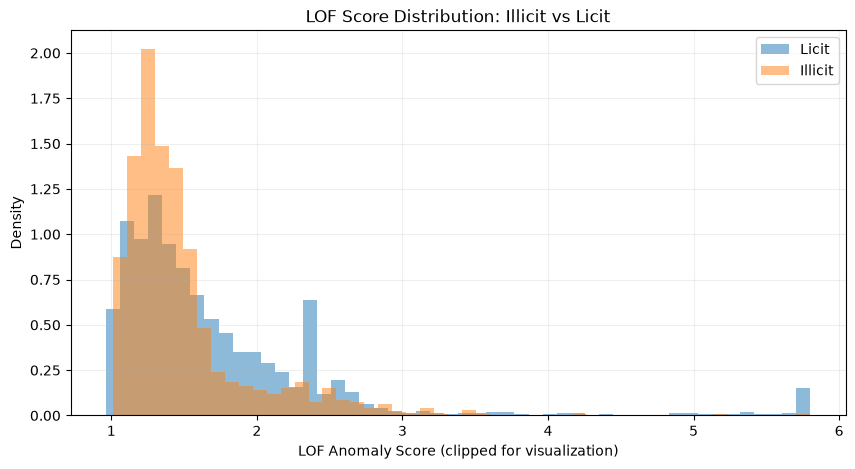

Visualization clipping threshold: 5.8024
Original scores remain unchanged.


In [59]:
import matplotlib.pyplot as plt
import numpy as np

illicit_scores = lof_known_eval.loc[
    lof_known_eval["is_illicit"] == 1,
    "LOF Anomaly Score"
]

licit_scores = lof_known_eval.loc[
    lof_known_eval["is_illicit"] == 0,
    "LOF Anomaly Score"
]

# Visualization-only clipping at combined 99th percentile
upper_limit = np.percentile(
    lof_known_eval["LOF Anomaly Score"], 99
)

plt.figure(figsize=(10, 5))

plt.hist(
    np.clip(licit_scores, None, upper_limit),
    bins=50,
    density=True,
    alpha=0.5,
    label="Licit"
)

plt.hist(
    np.clip(illicit_scores, None, upper_limit),
    bins=50,
    density=True,
    alpha=0.5,
    label="Illicit"
)

plt.xlabel("LOF Anomaly Score (clipped for visualization)")
plt.ylabel("Density")
plt.title("LOF Score Distribution: Illicit vs Licit")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Visualization clipping threshold:", round(upper_limit, 4))
print("Original scores remain unchanged.")

In [60]:
import pandas as pd

print("LOF - TOP-K ILLICIT DETECTION")
print("=" * 65)

results = []

for direction, ascending in [
    ("Original LOF", False),
    ("Reversed LOF", True)
]:
    ranked = lof_known_eval.sort_values(
        "LOF Anomaly Score",
        ascending=ascending
    )

    total_illicit = int(ranked["is_illicit"].sum())

    for k in [50, 100, 250, 500, 1000]:
        top_k = ranked.head(k)

        illicit_found = int(top_k["is_illicit"].sum())

        results.append({
            "Direction": direction,
            "K": k,
            "Illicit Found": illicit_found,
            "Precision@K": illicit_found / k,
            "Recall@K": illicit_found / total_illicit
        })

topk_results = pd.DataFrame(results)

print(topk_results.round(4).to_string(index=False))

print("\nKnown-label evaluation only:", len(lof_known_eval))
print("Illicit prevalence:", round(lof_known_eval["is_illicit"].mean(), 4))

LOF - TOP-K ILLICIT DETECTION
   Direction    K  Illicit Found  Precision@K  Recall@K
Original LOF   50              1        0.020    0.0010
Original LOF  100              1        0.010    0.0010
Original LOF  250              3        0.012    0.0031
Original LOF  500             31        0.062    0.0325
Original LOF 1000             61        0.061    0.0639
Reversed LOF   50              0        0.000    0.0000
Reversed LOF  100              0        0.000    0.0000
Reversed LOF  250              0        0.000    0.0000
Reversed LOF  500             41        0.082    0.0429
Reversed LOF 1000             77        0.077    0.0806

Known-label evaluation only: 8475
Illicit prevalence: 0.1127


In [61]:
print("AVAILABLE MODEL EVALUATION DATAFRAMES")
print("=" * 60)

for name in [
    "known_validation",
    "known_validation_b",
    "lof_known_eval"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}")
        print("Rows:", len(obj))
        print("Columns:", obj.columns.tolist())
    else:
        print(f"\n{name}: Not available as DataFrame")

AVAILABLE MODEL EVALUATION DATAFRAMES

known_validation
Rows: 8475
Columns: ['txId', 'Time step', 'Anomaly Score', 'class', '_merge']

known_validation_b
Rows: 8475
Columns: ['txId', 'Time step', 'Anomaly Score', 'class', '_merge']

lof_known_eval
Rows: 8475
Columns: ['txId', 'Time step', 'LOF Anomaly Score', 'class', 'is_illicit']


In [62]:
import pandas as pd

# Prepare model evaluation datasets
model_data = {
    "Isolation Forest A": (
        known_validation.copy(),
        "Anomaly Score"
    ),
    "Isolation Forest B": (
        known_validation_b.copy(),
        "Anomaly Score"
    ),
    "LOF": (
        lof_known_eval.copy(),
        "LOF Anomaly Score"
    )
}

results = []

for model_name, (df, score_column) in model_data.items():

    # Only known labels: 1 = illicit, 2 = licit
    df["class"] = df["class"].astype("string")
    df = df[df["class"].isin(["1", "2"])].copy()

    df["is_illicit"] = (df["class"] == "1").astype(int)

    # Higher anomaly score = higher ranking
    df = df.sort_values(
        score_column,
        ascending=False
    )

    total_illicit = int(df["is_illicit"].sum())

    for k in [50, 100, 250, 500, 1000]:

        top_k = df.head(k)
        illicit_found = int(top_k["is_illicit"].sum())

        results.append({
            "Model": model_name,
            "K": k,
            "Illicit Found": illicit_found,
            "Precision@K": illicit_found / k,
            "Recall@K": illicit_found / total_illicit
        })

all_models_topk = pd.DataFrame(results)

print("ALL MODELS - TOP-K ILLICIT DETECTION")
print("=" * 75)
print(all_models_topk.round(4).to_string(index=False))

print("\nIllicit prevalence baseline:", round(955 / 8475, 4))
print("Models compared:", all_models_topk["Model"].nunique())

ALL MODELS - TOP-K ILLICIT DETECTION
             Model    K  Illicit Found  Precision@K  Recall@K
Isolation Forest A   50              0        0.000    0.0000
Isolation Forest A  100              0        0.000    0.0000
Isolation Forest A  250              0        0.000    0.0000
Isolation Forest A  500              0        0.000    0.0000
Isolation Forest A 1000              4        0.004    0.0042
Isolation Forest B   50              0        0.000    0.0000
Isolation Forest B  100              0        0.000    0.0000
Isolation Forest B  250              0        0.000    0.0000
Isolation Forest B  500              1        0.002    0.0010
Isolation Forest B 1000              1        0.001    0.0010
               LOF   50              1        0.020    0.0010
               LOF  100              1        0.010    0.0010
               LOF  250              3        0.012    0.0031
               LOF  500             31        0.062    0.0325
               LOF 1000          

In [63]:
import pandas as pd
import numpy as np

print("FEATURE VARIANCE DIAGNOSTIC")
print("=" * 60)

# Training data only — avoid validation/test leakage
feature_variances = X_train_a.var(axis=0)

zero_variance = feature_variances[
    feature_variances == 0
]

near_zero_variance = feature_variances[
    (feature_variances > 0) &
    (feature_variances < 1e-8)
]

print("Total features:", X_train_a.shape[1])
print("Zero-variance features:", len(zero_variance))
print("Near-zero variance features:", len(near_zero_variance))

print("\n10 LOWEST VARIANCE FEATURES")
print(feature_variances.nsmallest(10).to_string())

print("\nVALIDATION CHECKS")
print("All features evaluated:",
      len(feature_variances) == X_train_a.shape[1])
print("All variances finite:",
      np.isfinite(feature_variances).all())

FEATURE VARIANCE DIAGNOSTIC
Total features: 165
Zero-variance features: 0
Near-zero variance features: 0

10 LOWEST VARIANCE FEATURES
Local_feature_34        0.037818
Aggregate_feature_13    0.046932
Aggregate_feature_16    0.059017
Local_feature_2         0.095788
Local_feature_37        0.110949
Aggregate_feature_14    0.113931
Local_feature_35        0.128302
Aggregate_feature_49    0.135330
Aggregate_feature_52    0.148055
Aggregate_feature_51    0.164836

VALIDATION CHECKS
All features evaluated: True
All variances finite: True


In [64]:
import numpy as np
import pandas as pd

print("FEATURE CORRELATION DIAGNOSTIC")
print("=" * 60)

# Training data only — no validation/test leakage
correlation_matrix = X_train_a.corr(method="pearson").abs()

# Select upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Extract highly correlated feature pairs
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Correlation"] >= 0.95
].sort_values(
    "Absolute Correlation",
    ascending=False
)

print("Total features:", X_train_a.shape[1])
print("Total possible feature pairs:",
      X_train_a.shape[1] * (X_train_a.shape[1] - 1) // 2)

print("Highly correlated pairs (>= 0.95):",
      len(high_corr_pairs))

print("\nTOP 15 HIGHLY CORRELATED PAIRS")
print(high_corr_pairs.head(15).to_string(index=False))

print("\nVALIDATION CHECKS")
print("Correlation matrix shape correct:",
      correlation_matrix.shape == (165, 165))
print("No missing correlations:",
      correlation_matrix.notna().all().all())

FEATURE CORRELATION DIAGNOSTIC
Total features: 165
Total possible feature pairs: 13530
Highly correlated pairs (>= 0.95): 104

TOP 15 HIGHLY CORRELATED PAIRS
           Feature 1            Feature 2  Absolute Correlation
    Local_feature_24     Local_feature_30              1.000000
    Local_feature_22     Local_feature_28              1.000000
    Local_feature_23     Local_feature_29              1.000000
    Local_feature_25     Local_feature_31              1.000000
    Local_feature_61     Local_feature_67              1.000000
    Local_feature_60     Local_feature_66              1.000000
    Local_feature_59     Local_feature_65              1.000000
    Local_feature_58     Local_feature_64              1.000000
    Local_feature_26     Local_feature_32              0.999461
    Local_feature_27     Local_feature_33              0.999446
Aggregate_feature_59 Aggregate_feature_60              0.999344
     Local_feature_8     Local_feature_11              0.999341
     Local

In [65]:
print("CORRELATION-BASED FEATURE REDUCTION")
print("=" * 60)

# Use existing training correlation matrix
upper_corr = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Identify columns with correlation >= 0.95
correlated_features_to_drop = [
    column
    for column in upper_corr.columns
    if (upper_corr[column] >= 0.95).any()
]

# Candidate feature set
reduced_feature_columns = [
    column
    for column in X_train_a.columns
    if column not in correlated_features_to_drop
]

print("Original feature count:", X_train_a.shape[1])
print("Candidate features to remove:",
      len(correlated_features_to_drop))
print("Candidate features retained:",
      len(reduced_feature_columns))

print("\nFIRST 20 REMOVAL CANDIDATES")
print(correlated_features_to_drop[:20])

print("\nVALIDATION CHECKS")
print("No duplicate retained features:",
      len(reduced_feature_columns) == len(set(reduced_feature_columns)))
print("Feature counts consistent:",
      len(reduced_feature_columns) +
      len(correlated_features_to_drop) == X_train_a.shape[1])
print("At least one feature retained:",
      len(reduced_feature_columns) > 0)

CORRELATION-BASED FEATURE REDUCTION
Original feature count: 165
Candidate features to remove: 61
Candidate features retained: 104

FIRST 20 REMOVAL CANDIDATES
['Local_feature_6', 'Local_feature_8', 'Local_feature_9', 'Local_feature_11', 'Local_feature_13', 'Local_feature_14', 'Local_feature_17', 'Local_feature_18', 'Local_feature_19', 'Local_feature_21', 'Local_feature_27', 'Local_feature_28', 'Local_feature_29', 'Local_feature_30', 'Local_feature_31', 'Local_feature_32', 'Local_feature_33', 'Local_feature_37', 'Local_feature_39', 'Local_feature_43']

VALIDATION CHECKS
No duplicate retained features: True
Feature counts consistent: True
At least one feature retained: True


In [66]:
import numpy as np
from sklearn.preprocessing import StandardScaler

print("REDUCED FEATURE DATASET PREPARATION")
print("=" * 60)

# Use the same training rows as the original LOF experiment
reduced_train = X_train_a.loc[
    X_lof_train.index,
    reduced_feature_columns
].copy()

# Same validation rows, reduced feature columns
reduced_val = X_val_a.loc[
    X_lof_val.index,
    reduced_feature_columns
].copy()

# Fit scaler only on training data
reduced_scaler = StandardScaler()

X_lof_train_reduced = reduced_scaler.fit_transform(
    reduced_train
)

X_lof_val_reduced = reduced_scaler.transform(
    reduced_val
)

print("Original LOF features:", X_lof_train.shape[1])
print("Reduced LOF features:", X_lof_train_reduced.shape[1])

print("Training shape:", X_lof_train_reduced.shape)
print("Validation shape:", X_lof_val_reduced.shape)

print("\nVALIDATION CHECKS")

print(
    "Training sample size preserved:",
    X_lof_train_reduced.shape[0] == len(X_lof_train)
)

print(
    "Validation size preserved:",
    X_lof_val_reduced.shape[0] == len(X_lof_val)
)

print(
    "Reduced feature count correct:",
    X_lof_train_reduced.shape[1] == len(reduced_feature_columns)
)

print(
    "All values finite:",
    np.isfinite(X_lof_train_reduced).all()
    and np.isfinite(X_lof_val_reduced).all()
)

REDUCED FEATURE DATASET PREPARATION
Original LOF features: 165
Reduced LOF features: 104
Training shape: (10000, 104)
Validation shape: (33835, 104)

VALIDATION CHECKS
Training sample size preserved: True
Validation size preserved: True
Reduced feature count correct: True
All values finite: True


In [67]:
from sklearn.preprocessing import StandardScaler
import numpy as np

print("REDUCED LOF - SCALING ALIGNMENT")
print("=" * 60)

# Fit on the full chronological training split
reduced_scaler = StandardScaler()

reduced_scaler.fit(
    X_train_a[reduced_feature_columns]
)

# Transform the SAME 10,000 LOF training transactions
X_lof_train_reduced = reduced_scaler.transform(
    X_train_a.loc[
        X_lof_train.index,
        reduced_feature_columns
    ]
)

# Transform the SAME validation transactions
X_lof_val_reduced = reduced_scaler.transform(
    X_val_a.loc[
        X_lof_val.index,
        reduced_feature_columns
    ]
)

print("Scaler fitted on:", len(X_train_a), "transactions")
print("Reduced training shape:", X_lof_train_reduced.shape)
print("Reduced validation shape:", X_lof_val_reduced.shape)

print("\nVALIDATION CHECKS")

print(
    "Training rows preserved:",
    X_lof_train_reduced.shape[0] == len(X_lof_train)
)

print(
    "Validation rows preserved:",
    X_lof_val_reduced.shape[0] == len(X_lof_val)
)

print(
    "Feature count correct:",
    X_lof_train_reduced.shape[1] == 104
)

print(
    "All values finite:",
    np.isfinite(X_lof_train_reduced).all()
    and np.isfinite(X_lof_val_reduced).all()
)

REDUCED LOF - SCALING ALIGNMENT
Scaler fitted on: 123287 transactions
Reduced training shape: (10000, 104)
Reduced validation shape: (33835, 104)

VALIDATION CHECKS
Training rows preserved: True
Validation rows preserved: True
Feature count correct: True
All values finite: True


In [68]:
from sklearn.neighbors import LocalOutlierFactor
import numpy as np

print("REDUCED FEATURE LOF MODEL TRAINING")
print("=" * 60)

# Same hyperparameters as original LOF
lof_reduced_model = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
)

# Train on reduced features
lof_reduced_model.fit(X_lof_train_reduced)

print("Model training completed successfully!")

print("\nMODEL CONFIGURATION")
print("Algorithm: Local Outlier Factor")
print("Training transactions:", X_lof_train_reduced.shape[0])
print("Features:", X_lof_train_reduced.shape[1])
print("Neighbors:", lof_reduced_model.n_neighbors)
print("Novelty detection:", lof_reduced_model.novelty)

print("\nVALIDATION CHECKS")
print(
    "Model fitted:",
    hasattr(lof_reduced_model, "negative_outlier_factor_")
)

print(
    "Training scores available:",
    len(lof_reduced_model.negative_outlier_factor_)
    == X_lof_train_reduced.shape[0]
)

print(
    "Training scores finite:",
    np.isfinite(
        lof_reduced_model.negative_outlier_factor_
    ).all()
)

REDUCED FEATURE LOF MODEL TRAINING
Model training completed successfully!

MODEL CONFIGURATION
Algorithm: Local Outlier Factor
Training transactions: 10000
Features: 104
Neighbors: 20
Novelty detection: True

VALIDATION CHECKS
Model fitted: True
Training scores available: True
Training scores finite: True


In [69]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

print("REDUCED LOF - VALIDATION EVALUATION")
print("=" * 65)

# 1. Generate anomaly scores for validation transactions
# Higher score = more anomalous
reduced_lof_scores = -lof_reduced_model.score_samples(
    X_lof_val_reduced
)

# 2. Associate scores with original validation transaction IDs
reduced_lof_results = pd.DataFrame({
    "txId": tx_features.loc[X_val_a.index, "txId"].to_numpy(),
    "LOF Reduced Anomaly Score": reduced_lof_scores
})

# 3. Join known validation labels by transaction ID
reduced_lof_known_eval = reduced_lof_results.merge(
    tx_classes[["txId", "class"]],
    on="txId",
    how="inner",
    validate="one_to_one"
)

reduced_lof_known_eval["class"] = (
    reduced_lof_known_eval["class"].astype("string")
)

reduced_lof_known_eval = reduced_lof_known_eval[
    reduced_lof_known_eval["class"].isin(["1", "2"])
].copy()

reduced_lof_known_eval["is_illicit"] = (
    reduced_lof_known_eval["class"] == "1"
).astype(int)

# 4. Calculate metrics
reduced_lof_roc_auc = roc_auc_score(
    reduced_lof_known_eval["is_illicit"],
    reduced_lof_known_eval["LOF Reduced Anomaly Score"]
)

reduced_lof_ap = average_precision_score(
    reduced_lof_known_eval["is_illicit"],
    reduced_lof_known_eval["LOF Reduced Anomaly Score"]
)

# 5. Compare with original LOF
comparison = pd.DataFrame({
    "Model": ["Original LOF (165)", "Reduced LOF (104)"],
    "ROC-AUC": [lof_roc_auc, reduced_lof_roc_auc],
    "Average Precision": [lof_average_precision, reduced_lof_ap]
})

print("\nMODEL PERFORMANCE COMPARISON")
print(comparison.round(4).to_string(index=False))

print("\nPERFORMANCE CHANGE (REDUCED - ORIGINAL)")
print("ROC-AUC change:", round(reduced_lof_roc_auc - lof_roc_auc, 4))
print("AP change:", round(reduced_lof_ap - lof_average_precision, 4))

print("\nVALIDATION CHECKS")
print("Known-label rows:", len(reduced_lof_known_eval))
print("Illicit rows:", reduced_lof_known_eval["is_illicit"].sum())
print("All scores finite:", np.isfinite(reduced_lof_scores).all())
print(
    "Same known transaction IDs as original LOF:",
    set(reduced_lof_known_eval["txId"].astype("string"))
    == set(lof_known_eval["txId"].astype("string"))
)

REDUCED LOF - VALIDATION EVALUATION


ValueError: You are trying to merge on int64 and string columns for key 'txId'. If you wish to proceed you should use pd.concat

In [70]:
# Fix transaction ID data types
reduced_lof_results["txId"] = (
    reduced_lof_results["txId"].astype("string")
)

labels_for_merge = tx_classes[["txId", "class"]].copy()

labels_for_merge["txId"] = (
    labels_for_merge["txId"].astype("string")
)

# Merge scores with transaction labels
reduced_lof_known_eval = reduced_lof_results.merge(
    labels_for_merge,
    on="txId",
    how="inner",
    validate="one_to_one"
)

# Keep only known labels
reduced_lof_known_eval["class"] = (
    reduced_lof_known_eval["class"].astype("string")
)

reduced_lof_known_eval = reduced_lof_known_eval[
    reduced_lof_known_eval["class"].isin(["1", "2"])
].copy()

reduced_lof_known_eval["is_illicit"] = (
    reduced_lof_known_eval["class"] == "1"
).astype(int)

print("MERGE FIX VALIDATION")
print("=" * 50)

print("Known-label transactions:", len(reduced_lof_known_eval))
print("Illicit transactions:",
      reduced_lof_known_eval["is_illicit"].sum())

print("Transaction IDs match original LOF:",
      set(reduced_lof_known_eval["txId"])
      == set(lof_known_eval["txId"].astype("string")))

print("Duplicate transaction IDs:",
      reduced_lof_known_eval["txId"].duplicated().sum())

MERGE FIX VALIDATION
Known-label transactions: 8475
Illicit transactions: 955
Transaction IDs match original LOF: True
Duplicate transaction IDs: 0


In [71]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

print("ORIGINAL VS REDUCED LOF - PERFORMANCE COMPARISON")
print("=" * 65)

# Reduced LOF evaluation
reduced_lof_roc_auc = roc_auc_score(
    reduced_lof_known_eval["is_illicit"],
    reduced_lof_known_eval["LOF Reduced Anomaly Score"]
)

reduced_lof_ap = average_precision_score(
    reduced_lof_known_eval["is_illicit"],
    reduced_lof_known_eval["LOF Reduced Anomaly Score"]
)

# Compare both models
lof_feature_comparison = pd.DataFrame({
    "Model": [
        "Original LOF",
        "Reduced LOF"
    ],
    "Features": [165, 104],
    "ROC-AUC": [
        lof_roc_auc,
        reduced_lof_roc_auc
    ],
    "Average Precision": [
        lof_average_precision,
        reduced_lof_ap
    ]
})

print("\nMODEL COMPARISON")
print(lof_feature_comparison.round(4).to_string(index=False))

print("\nPERFORMANCE CHANGE (REDUCED - ORIGINAL)")
print(
    "ROC-AUC:",
    round(reduced_lof_roc_auc - lof_roc_auc, 4)
)
print(
    "Average Precision:",
    round(reduced_lof_ap - lof_average_precision, 4)
)

print("\nVALIDATION CHECKS")
print(
    "Same evaluation size:",
    len(reduced_lof_known_eval) == len(lof_known_eval)
)
print(
    "All reduced scores finite:",
    np.isfinite(
        reduced_lof_known_eval["LOF Reduced Anomaly Score"]
    ).all()
)
print(
    "Both classes present:",
    reduced_lof_known_eval["is_illicit"].nunique() == 2
)

ORIGINAL VS REDUCED LOF - PERFORMANCE COMPARISON

MODEL COMPARISON
       Model  Features  ROC-AUC  Average Precision
Original LOF       165   0.4139             0.0888
 Reduced LOF       104   0.3981             0.0864

PERFORMANCE CHANGE (REDUCED - ORIGINAL)
ROC-AUC: -0.0158
Average Precision: -0.0023

VALIDATION CHECKS
Same evaluation size: True
All reduced scores finite: True
Both classes present: True


In [72]:
import pandas as pd

print("ORIGINAL VS REDUCED LOF - TOP-K COMPARISON")
print("=" * 75)

models = {
    "Original LOF (165)": (
        lof_known_eval.copy(),
        "LOF Anomaly Score"
    ),
    "Reduced LOF (104)": (
        reduced_lof_known_eval.copy(),
        "LOF Reduced Anomaly Score"
    )
}

topk_results = []

for model_name, (df, score_col) in models.items():

    ranked = df.sort_values(
        score_col,
        ascending=False
    )

    total_illicit = int(ranked["is_illicit"].sum())

    for k in [50, 100, 250, 500, 1000]:

        top_k = ranked.head(k)
        illicit_found = int(top_k["is_illicit"].sum())

        topk_results.append({
            "Model": model_name,
            "K": k,
            "Illicit Found": illicit_found,
            "Precision@K": illicit_found / k,
            "Recall@K": illicit_found / total_illicit
        })

lof_feature_topk = pd.DataFrame(topk_results)

print(
    lof_feature_topk.round(4).to_string(index=False)
)

print("\nKnown-label illicit prevalence:",
      round(955 / 8475, 4))

print("Models compared:",
      lof_feature_topk["Model"].nunique())

ORIGINAL VS REDUCED LOF - TOP-K COMPARISON
             Model    K  Illicit Found  Precision@K  Recall@K
Original LOF (165)   50              1        0.020    0.0010
Original LOF (165)  100              1        0.010    0.0010
Original LOF (165)  250              3        0.012    0.0031
Original LOF (165)  500             31        0.062    0.0325
Original LOF (165) 1000             61        0.061    0.0639
 Reduced LOF (104)   50              2        0.040    0.0021
 Reduced LOF (104)  100              2        0.020    0.0021
 Reduced LOF (104)  250              4        0.016    0.0042
 Reduced LOF (104)  500             31        0.062    0.0325
 Reduced LOF (104) 1000             48        0.048    0.0503

Known-label illicit prevalence: 0.1127
Models compared: 2


In [73]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("PCA - EXPLAINED VARIANCE ANALYSIS")
print("=" * 65)

# Fit scaler only on chronological training data
pca_scaler = StandardScaler()

X_train_pca_scaled = pca_scaler.fit_transform(
    X_train_a
)

# Fit PCA only on training data
pca_analysis = PCA(
    svd_solver="full"
)

pca_analysis.fit(X_train_pca_scaled)

# Cumulative explained variance
cumulative_variance = np.cumsum(
    pca_analysis.explained_variance_ratio_
)

thresholds = [0.80, 0.90, 0.95, 0.99]

print("Original features:", X_train_a.shape[1])

print("\nCOMPONENTS REQUIRED")
for threshold in thresholds:
    n_components = (
        np.searchsorted(cumulative_variance, threshold) + 1
    )

    print(
        f"{threshold:.0%} variance: "
        f"{n_components} components"
    )

print("\nVALIDATION CHECKS")

print(
    "Total components:",
    len(pca_analysis.explained_variance_ratio_)
)

print(
    "Explained variance sums to 1:",
    np.isclose(
        pca_analysis.explained_variance_ratio_.sum(),
        1.0
    )
)

print(
    "All explained variance values finite:",
    np.isfinite(
        pca_analysis.explained_variance_ratio_
    ).all()
)

PCA - EXPLAINED VARIANCE ANALYSIS
Original features: 165

COMPONENTS REQUIRED
80% variance: 34 components
90% variance: 49 components
95% variance: 59 components
99% variance: 73 components

VALIDATION CHECKS
Total components: 165
Explained variance sums to 1: True
All explained variance values finite: True


In [74]:
import numpy as np
from sklearn.decomposition import PCA

print("PCA-TRANSFORMED LOF DATASET PREPARATION")
print("=" * 65)

# Use the scaler already fitted on full training data
# and PCA fitted only on chronological training data

pca_59 = PCA(
    n_components=59,
    svd_solver="full"
)

# Fit PCA on the full scaled training split
pca_59.fit(X_train_pca_scaled)

# Transform the same 10,000 LOF training rows
X_lof_train_pca = pca_59.transform(
    pca_scaler.transform(
        X_train_a.loc[X_lof_train.index]
    )
)

# Transform the same validation transactions
X_lof_val_pca = pca_59.transform(
    pca_scaler.transform(
        X_val_a.loc[X_lof_val.index]
    )
)

print("Original LOF features:", X_lof_train.shape[1])
print("PCA components:", X_lof_train_pca.shape[1])

print("Training shape:", X_lof_train_pca.shape)
print("Validation shape:", X_lof_val_pca.shape)

print(
    "Actual explained variance:",
    round(pca_59.explained_variance_ratio_.sum(), 4)
)

print("\nVALIDATION CHECKS")

print(
    "Training rows preserved:",
    X_lof_train_pca.shape[0] == len(X_lof_train)
)

print(
    "Validation rows preserved:",
    X_lof_val_pca.shape[0] == len(X_lof_val)
)

print(
    "PCA component count correct:",
    X_lof_train_pca.shape[1] == 59
)

print(
    "All values finite:",
    np.isfinite(X_lof_train_pca).all()
    and np.isfinite(X_lof_val_pca).all()
)

PCA-TRANSFORMED LOF DATASET PREPARATION
Original LOF features: 165
PCA components: 59
Training shape: (10000, 59)
Validation shape: (33835, 59)
Actual explained variance: 0.9533

VALIDATION CHECKS
Training rows preserved: True
Validation rows preserved: True
PCA component count correct: True
All values finite: True


In [75]:
from sklearn.neighbors import LocalOutlierFactor
import numpy as np

print("PCA-BASED LOF MODEL TRAINING")
print("=" * 60)

# Same hyperparameters as original LOF
lof_pca_model = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
)

# Train on 59 PCA components
lof_pca_model.fit(X_lof_train_pca)

print("PCA-based LOF training completed successfully!")

print("\nMODEL CONFIGURATION")
print("Algorithm: Local Outlier Factor")
print("Training transactions:", X_lof_train_pca.shape[0])
print("PCA components:", X_lof_train_pca.shape[1])
print("Neighbors:", lof_pca_model.n_neighbors)
print("Novelty detection:", lof_pca_model.novelty)

print("\nVALIDATION CHECKS")

print(
    "Model fitted:",
    hasattr(lof_pca_model, "negative_outlier_factor_")
)

print(
    "Training scores available:",
    len(lof_pca_model.negative_outlier_factor_)
    == X_lof_train_pca.shape[0]
)

print(
    "All training scores finite:",
    np.isfinite(
        lof_pca_model.negative_outlier_factor_
    ).all()
)

PCA-BASED LOF MODEL TRAINING
PCA-based LOF training completed successfully!

MODEL CONFIGURATION
Algorithm: Local Outlier Factor
Training transactions: 10000
PCA components: 59
Neighbors: 20
Novelty detection: True

VALIDATION CHECKS
Model fitted: True
Training scores available: True
All training scores finite: True


In [76]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

print("PCA-BASED LOF - VALIDATION EVALUATION")
print("=" * 65)

# 1. Generate anomaly scores
# Higher score = more anomalous
lof_pca_scores = -lof_pca_model.score_samples(
    X_lof_val_pca
)

# 2. Associate scores with validation transaction IDs
lof_pca_results = pd.DataFrame({
    "txId": tx_features.loc[
        X_val_a.index, "txId"
    ].astype("string").to_numpy(),

    "PCA LOF Anomaly Score": lof_pca_scores
})

# 3. Prepare labels with matching ID type
pca_labels = tx_classes[["txId", "class"]].copy()
pca_labels["txId"] = pca_labels["txId"].astype("string")

# 4. Merge scores and labels
lof_pca_known_eval = lof_pca_results.merge(
    pca_labels,
    on="txId",
    how="inner",
    validate="one_to_one"
)

# 5. Keep known labels only
lof_pca_known_eval["class"] = (
    lof_pca_known_eval["class"].astype("string")
)

lof_pca_known_eval = lof_pca_known_eval[
    lof_pca_known_eval["class"].isin(["1", "2"])
].copy()

lof_pca_known_eval["is_illicit"] = (
    lof_pca_known_eval["class"] == "1"
).astype(int)

# 6. Evaluate illicit-label ranking
lof_pca_roc_auc = roc_auc_score(
    lof_pca_known_eval["is_illicit"],
    lof_pca_known_eval["PCA LOF Anomaly Score"]
)

lof_pca_ap = average_precision_score(
    lof_pca_known_eval["is_illicit"],
    lof_pca_known_eval["PCA LOF Anomaly Score"]
)

# 7. Compare all LOF experiments
lof_pca_comparison = pd.DataFrame({
    "Model": [
        "Original LOF",
        "Reduced LOF",
        "PCA LOF"
    ],
    "Features": [165, 104, 59],
    "ROC-AUC": [
        lof_roc_auc,
        reduced_lof_roc_auc,
        lof_pca_roc_auc
    ],
    "Average Precision": [
        lof_average_precision,
        reduced_lof_ap,
        lof_pca_ap
    ]
})

print("\nMODEL PERFORMANCE COMPARISON")
print(lof_pca_comparison.round(4).to_string(index=False))

print("\nVALIDATION CHECKS")
print("Known-label transactions:", len(lof_pca_known_eval))
print("Illicit transactions:",
      int(lof_pca_known_eval["is_illicit"].sum()))

print(
    "Same IDs as original LOF:",
    set(lof_pca_known_eval["txId"]) ==
    set(lof_known_eval["txId"].astype("string"))
)

print(
    "All scores finite:",
    np.isfinite(lof_pca_scores).all()
)

print(
    "No duplicate IDs:",
    not lof_pca_known_eval["txId"].duplicated().any()
)

PCA-BASED LOF - VALIDATION EVALUATION

MODEL PERFORMANCE COMPARISON
       Model  Features  ROC-AUC  Average Precision
Original LOF       165   0.4139             0.0888
 Reduced LOF       104   0.3981             0.0864
     PCA LOF        59   0.4121             0.0881

VALIDATION CHECKS
Known-label transactions: 8475
Illicit transactions: 955
Same IDs as original LOF: True
All scores finite: True
No duplicate IDs: True


In [77]:
import pandas as pd

print("ORIGINAL VS PCA LOF - TOP-K COMPARISON")
print("=" * 75)

models = {
    "Original LOF (165)": (
        lof_known_eval.copy(),
        "LOF Anomaly Score"
    ),
    "PCA LOF (59)": (
        lof_pca_known_eval.copy(),
        "PCA LOF Anomaly Score"
    )
}

results = []

for model_name, (df, score_col) in models.items():

    ranked = df.sort_values(
        score_col,
        ascending=False
    )

    total_illicit = int(ranked["is_illicit"].sum())

    for k in [50, 100, 250, 500, 1000]:

        top_k = ranked.head(k)

        illicit_found = int(
            top_k["is_illicit"].sum()
        )

        results.append({
            "Model": model_name,
            "K": k,
            "Illicit Found": illicit_found,
            "Precision@K": illicit_found / k,
            "Recall@K": illicit_found / total_illicit
        })

lof_pca_topk = pd.DataFrame(results)

print(
    lof_pca_topk.round(4).to_string(index=False)
)

print("\nKnown-label illicit prevalence:",
      round(955 / 8475, 4))

print("Models compared:",
      lof_pca_topk["Model"].nunique())


ORIGINAL VS PCA LOF - TOP-K COMPARISON
             Model    K  Illicit Found  Precision@K  Recall@K
Original LOF (165)   50              1        0.020    0.0010
Original LOF (165)  100              1        0.010    0.0010
Original LOF (165)  250              3        0.012    0.0031
Original LOF (165)  500             31        0.062    0.0325
Original LOF (165) 1000             61        0.061    0.0639
      PCA LOF (59)   50              0        0.000    0.0000
      PCA LOF (59)  100              0        0.000    0.0000
      PCA LOF (59)  250              7        0.028    0.0073
      PCA LOF (59)  500             32        0.064    0.0335
      PCA LOF (59) 1000             50        0.050    0.0524

Known-label illicit prevalence: 0.1127
Models compared: 2


In [78]:
import pandas as pd
import numpy as np

print("TEMPORAL CLASS DISTRIBUTION ANALYSIS")
print("=" * 70)

# Use transaction IDs, time steps, and labels
temporal_analysis = tx_features[
    ["txId", "Time step"]
].copy()

temporal_analysis["txId"] = (
    temporal_analysis["txId"].astype("string")
)

temporal_labels_copy = tx_classes[
    ["txId", "class"]
].copy()

temporal_labels_copy["txId"] = (
    temporal_labels_copy["txId"].astype("string")
)

# Join by transaction ID
temporal_analysis = temporal_analysis.merge(
    temporal_labels_copy,
    on="txId",
    how="left",
    validate="one_to_one"
)

temporal_analysis["class"] = (
    temporal_analysis["class"].astype("string")
)

# Count transactions per time step and class
temporal_class_counts = pd.crosstab(
    temporal_analysis["Time step"],
    temporal_analysis["class"]
)

# Ensure expected columns exist
temporal_class_counts = temporal_class_counts.reindex(
    columns=["1", "2", "unknown"],
    fill_value=0
)

temporal_class_counts = temporal_class_counts.rename(
    columns={
        "1": "Illicit",
        "2": "Licit",
        "unknown": "Unknown"
    }
)

temporal_class_counts["Total"] = (
    temporal_class_counts[
        ["Illicit", "Licit", "Unknown"]
    ].sum(axis=1)
)

temporal_class_counts["Illicit Rate (Known %)"] = (
    temporal_class_counts["Illicit"]
    / (
        temporal_class_counts["Illicit"]
        + temporal_class_counts["Licit"]
    ).replace(0, np.nan)
    * 100
)

print("\nFIRST 10 TIME STEPS")
print(
    temporal_class_counts.head(10).round(2).to_string()
)

print("\nLAST 10 TIME STEPS")
print(
    temporal_class_counts.tail(10).round(2).to_string()
)

print("\nVALIDATION CHECKS")
print("Total time steps:", len(temporal_class_counts))
print(
    "Total transactions:",
    int(temporal_class_counts["Total"].sum())
)
print(
    "Missing class labels:",
    int(temporal_analysis["class"].isna().sum())
)

TEMPORAL CLASS DISTRIBUTION ANALYSIS

FIRST 10 TIME STEPS
class      Illicit  Licit  Unknown  Total  Illicit Rate (Known %)
Time step                                                        
1               17   2130        0   2147                    0.79
2               18   1099        0   1117                    1.61
3               11   1268        0   1279                    0.86
4               30   1410        0   1440                    2.08
5                8   1874        0   1882                    0.43
6                5    480        0    485                    1.03
7              102   1101        0   1203                    8.48
8               67   1098        0   1165                    5.75
9              248    530        0    778                   31.88
10              18    954        0    972                    1.85

LAST 10 TIME STEPS
class      Illicit  Licit  Unknown  Total  Illicit Rate (Known %)
Time step                                                       

In [79]:
print("CLASS LABEL DIAGNOSTIC")
print("=" * 60)

print("Total rows in tx_features:", len(tx_features))
print("Total rows in tx_classes:", len(tx_classes))

print("\nCLASS COLUMN DATA TYPE")
print(tx_classes["class"].dtype)

print("\nACTUAL CLASS VALUES AND COUNTS")
print(
    tx_classes["class"]
    .astype("string")
    .value_counts(dropna=False)
    .to_string()
)

print("\nTEMPORAL MERGE CHECK")
print("Merged rows:", len(temporal_analysis))

print("\nMERGED CLASS VALUES AND COUNTS")
print(
    temporal_analysis["class"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nCOUNT VERIFICATION")
print(
    "All transactions preserved:",
    len(temporal_analysis) == len(tx_features)
)

print(
    "Transactions counted in current table:",
    int(temporal_class_counts["Total"].sum())
)

CLASS LABEL DIAGNOSTIC
Total rows in tx_features: 203769
Total rows in tx_classes: 203769

CLASS COLUMN DATA TYPE
string

ACTUAL CLASS VALUES AND COUNTS
class
3    157205
2     42019
1      4545

TEMPORAL MERGE CHECK
Merged rows: 203769

MERGED CLASS VALUES AND COUNTS
class
3    157205
2     42019
1      4545

COUNT VERIFICATION
All transactions preserved: True
Transactions counted in current table: 46564


In [80]:
import pandas as pd
import numpy as np

print("CORRECTED TEMPORAL CLASS DISTRIBUTION")
print("=" * 70)

# Count transactions by time step and actual class labels
temporal_class_counts = pd.crosstab(
    temporal_analysis["Time step"],
    temporal_analysis["class"]
)

# Actual encoding: 1 = illicit, 2 = licit, 3 = unknown
temporal_class_counts = temporal_class_counts.reindex(
    columns=["1", "2", "3"],
    fill_value=0
)

temporal_class_counts = temporal_class_counts.rename(
    columns={
        "1": "Illicit",
        "2": "Licit",
        "3": "Unknown"
    }
)

# Total transactions per time step
temporal_class_counts["Total"] = (
    temporal_class_counts[
        ["Illicit", "Licit", "Unknown"]
    ].sum(axis=1)
)

# Illicit rate among known-label transactions only
known_count = (
    temporal_class_counts["Illicit"]
    + temporal_class_counts["Licit"]
)

temporal_class_counts["Illicit Rate (Known %)"] = (
    temporal_class_counts["Illicit"]
    / known_count.replace(0, np.nan)
    * 100
)

print("\nFIRST 10 TIME STEPS")
print(
    temporal_class_counts.head(10)
    .round(2)
    .to_string()
)

print("\nLAST 10 TIME STEPS")
print(
    temporal_class_counts.tail(10)
    .round(2)
    .to_string()
)

print("\nVALIDATION CHECKS")
print("Total time steps:", len(temporal_class_counts))

print(
    "Total transactions:",
    int(temporal_class_counts["Total"].sum())
)

print(
    "Total illicit:",
    int(temporal_class_counts["Illicit"].sum())
)

print(
    "Total licit:",
    int(temporal_class_counts["Licit"].sum())
)

print(
    "Total unknown:",
    int(temporal_class_counts["Unknown"].sum())
)

print(
    "All transactions preserved:",
    temporal_class_counts["Total"].sum()
    == len(tx_features)
)

CORRECTED TEMPORAL CLASS DISTRIBUTION

FIRST 10 TIME STEPS
class      Illicit  Licit  Unknown  Total  Illicit Rate (Known %)
Time step                                                        
1               17   2130     5733   7880                    0.79
2               18   1099     3427   4544                    1.61
3               11   1268     5342   6621                    0.86
4               30   1410     4253   5693                    2.08
5                8   1874     4921   6803                    0.43
6                5    480     3843   4328                    1.03
7              102   1101     4845   6048                    8.48
8               67   1098     3292   4457                    5.75
9              248    530     4218   4996                   31.88
10              18    954     5755   6727                    1.85

LAST 10 TIME STEPS
class      Illicit  Licit  Unknown  Total  Illicit Rate (Known %)
Time step                                                      

TEMPORAL BITCOIN TRANSACTION TRAFFIC VISUALIZATION


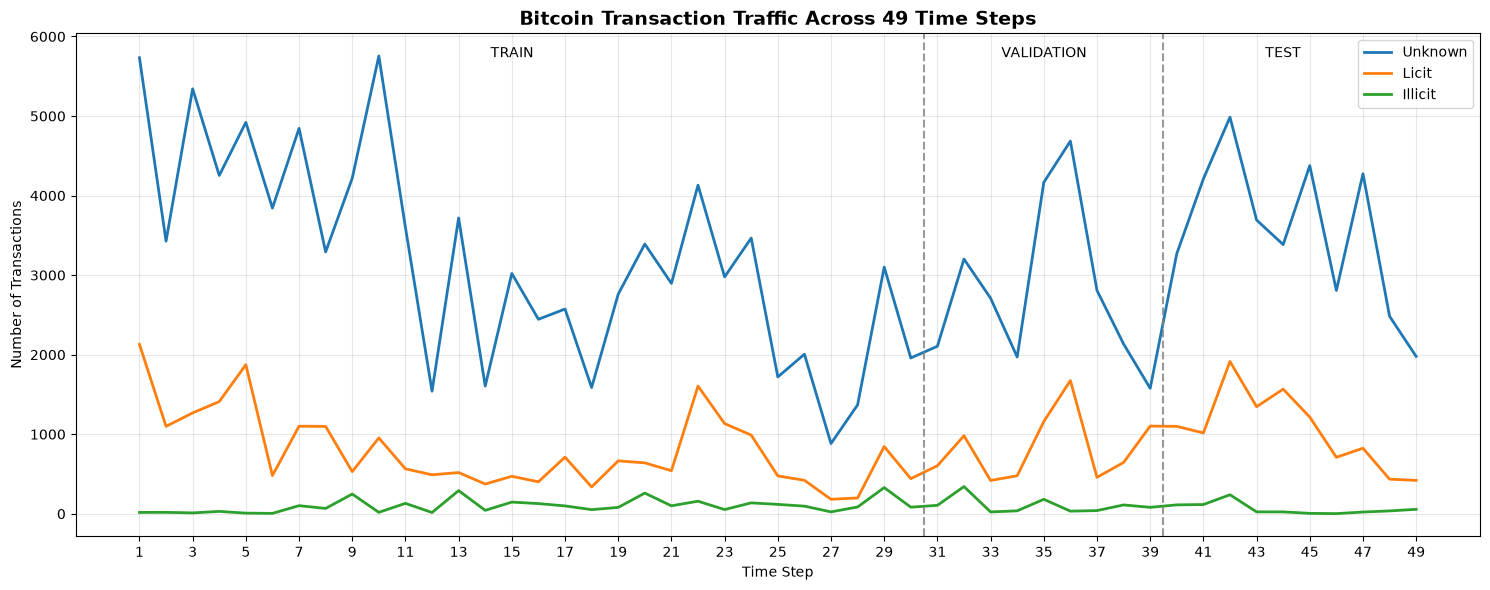


VISUALIZATION COMPLETED
Time steps visualized: 49
Total transactions: 203769


In [81]:
import matplotlib.pyplot as plt

print("TEMPORAL BITCOIN TRANSACTION TRAFFIC VISUALIZATION")
print("=" * 65)

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    temporal_class_counts.index,
    temporal_class_counts["Unknown"],
    label="Unknown",
    linewidth=2
)

ax.plot(
    temporal_class_counts.index,
    temporal_class_counts["Licit"],
    label="Licit",
    linewidth=2
)

ax.plot(
    temporal_class_counts.index,
    temporal_class_counts["Illicit"],
    label="Illicit",
    linewidth=2
)

ax.set_title(
    "Bitcoin Transaction Traffic Across 49 Time Steps",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Time Step")
ax.set_ylabel("Number of Transactions")

ax.set_xticks(range(1, 50, 2))
ax.grid(alpha=0.3)
ax.legend()

# Chronological train / validation / test boundaries
ax.axvline(
    x=30.5,
    linestyle="--",
    color="gray",
    alpha=0.8
)

ax.axvline(
    x=39.5,
    linestyle="--",
    color="gray",
    alpha=0.8
)

ax.text(15, ax.get_ylim()[1] * 0.95, "TRAIN", ha="center")
ax.text(35, ax.get_ylim()[1] * 0.95, "VALIDATION", ha="center")
ax.text(44, ax.get_ylim()[1] * 0.95, "TEST", ha="center")

plt.tight_layout()
plt.show()

print("\nVISUALIZATION COMPLETED")
print("Time steps visualized:", len(temporal_class_counts))
print("Total transactions:", int(temporal_class_counts["Total"].sum()))

In [82]:
import pandas as pd

print("TEMPORAL TRAFFIC PATTERN ANALYSIS")
print("=" * 70)

# Use training period only for exploratory model decisions
train_temporal = temporal_class_counts.loc[1:30].copy()

# Calculate percentage change in transaction volume
train_temporal["Volume Change (%)"] = (
    train_temporal["Total"].pct_change() * 100
)

print("\nTOP 5 HIGHEST TRAFFIC TIME STEPS (TRAIN)")
print(
    train_temporal.nlargest(5, "Total")[
        ["Total", "Illicit", "Licit", "Unknown"]
    ].to_string()
)

print("\nTOP 5 HIGHEST ILLICIT-RATE TIME STEPS (TRAIN)")
print(
    train_temporal.nlargest(
        5, "Illicit Rate (Known %)"
    )[
        ["Illicit", "Licit", "Illicit Rate (Known %)"]
    ].round(2).to_string()
)

print("\nTOP 5 LARGEST TRAFFIC INCREASES (TRAIN)")
print(
    train_temporal.nlargest(
        5, "Volume Change (%)"
    )[
        ["Total", "Volume Change (%)"]
    ].round(2).to_string()
)

print("\nTOP 5 LARGEST TRAFFIC DECREASES (TRAIN)")
print(
    train_temporal.nsmallest(
        5, "Volume Change (%)"
    )[
        ["Total", "Volume Change (%)"]
    ].round(2).to_string()
)

print("\nVALIDATION CHECKS")
print("Training time steps:", len(train_temporal))
print("Training transactions:", int(train_temporal["Total"].sum()))
print(
    "Volume changes calculated:",
    int(train_temporal["Volume Change (%)"].notna().sum())
)

TEMPORAL TRAFFIC PATTERN ANALYSIS

TOP 5 HIGHEST TRAFFIC TIME STEPS (TRAIN)
class      Total  Illicit  Licit  Unknown
Time step                                
1           7880       17   2130     5733
5           6803        8   1874     4921
10          6727       18    954     5755
3           6621       11   1268     5342
7           6048      102   1101     4845

TOP 5 HIGHEST ILLICIT-RATE TIME STEPS (TRAIN)
class      Illicit  Licit  Illicit Rate (Known %)
Time step                                        
13             291    518                   35.97
9              248    530                   31.88
28              85    199                   29.93
20             260    640                   28.89
29             329    845                   28.02

TOP 5 LARGEST TRAFFIC INCREASES (TRAIN)
class      Total  Volume Change (%)
Time step                          
29          4275             158.62
13          4528             121.20
15          3639              79.97
19          

In [83]:
import pandas as pd
import numpy as np

print("TEMPORAL TRAFFIC FEATURE ENGINEERING")
print("=" * 65)

# Training time steps only: 1–30
temporal_train_features = pd.DataFrame(
    index=temporal_class_counts.loc[1:30].index
)

# Feature 1: Total transaction count
temporal_train_features["transaction_count"] = (
    temporal_class_counts.loc[1:30, "Total"]
)

# Feature 2: Absolute change from previous time step
temporal_train_features["volume_change"] = (
    temporal_train_features["transaction_count"].diff()
)

# Feature 3: Percentage change from previous time step
temporal_train_features["volume_change_pct"] = (
    temporal_train_features["transaction_count"]
    .pct_change() * 100
)

# First time step has no previous observation
# Keep it missing rather than inventing a zero change

print("\nFIRST 10 TRAINING TIME STEPS")
print(
    temporal_train_features.head(10)
    .round(2)
    .to_string()
)

print("\nFEATURE SUMMARY")
print(
    temporal_train_features.describe()
    .round(2)
    .to_string()
)

print("\nVALIDATION CHECKS")
print("Training time steps:", len(temporal_train_features))
print("Feature columns:", temporal_train_features.shape[1])

print(
    "Missing volume change values:",
    temporal_train_features["volume_change"].isna().sum()
)

print(
    "Missing percentage change values:",
    temporal_train_features["volume_change_pct"].isna().sum()
)

print(
    "No illicit/licit label features:",
    not any(
        "illicit" in col.lower()
        or "licit" in col.lower()
        for col in temporal_train_features.columns
    )
)

TEMPORAL TRAFFIC FEATURE ENGINEERING

FIRST 10 TRAINING TIME STEPS
           transaction_count  volume_change  volume_change_pct
Time step                                                     
1                       7880            NaN                NaN
2                       4544        -3336.0             -42.34
3                       6621         2077.0              45.71
4                       5693         -928.0             -14.02
5                       6803         1110.0              19.50
6                       4328        -2475.0             -36.38
7                       6048         1720.0              39.74
8                       4457        -1591.0             -26.31
9                       4996          539.0              12.09
10                      6727         1731.0              34.65

FEATURE SUMMARY
       transaction_count  volume_change  volume_change_pct
count              30.00          29.00              29.00
mean             4109.57        -186.10   

In [84]:
import numpy as np
import pandas as pd

print("ROBUST Z-SCORE TEMPORAL ANOMALY DETECTION")
print("=" * 70)

# First time step has no previous-step comparison
temporal_scoring_data = temporal_train_features.dropna().copy()

feature_cols = [
    "transaction_count",
    "volume_change_pct"
]

# Median and MAD computed from training data only
feature_medians = temporal_scoring_data[feature_cols].median()

feature_mad = (
    temporal_scoring_data[feature_cols]
    .sub(feature_medians)
    .abs()
    .median()
)

# Avoid division by zero if a feature has zero MAD
safe_mad = feature_mad.replace(0, np.nan)

robust_z = (
    0.6745
    * temporal_scoring_data[feature_cols].sub(feature_medians)
    .div(safe_mad)
)

# Combine feature deviations into one anomaly score
temporal_scoring_data["Temporal Anomaly Score"] = (
    robust_z.abs().max(axis=1)
)

# Larger score = greater deviation from typical traffic
temporal_anomaly_ranking = temporal_scoring_data.sort_values(
    "Temporal Anomaly Score",
    ascending=False
)

print("\nTOP 10 TEMPORAL ANOMALIES (TRAIN)")
print(
    temporal_anomaly_ranking[
        [
            "transaction_count",
            "volume_change_pct",
            "Temporal Anomaly Score"
        ]
    ].head(10).round(3).to_string()
)

print("\nROBUST SCALING PARAMETERS")
print(
    pd.DataFrame({
        "Median": feature_medians,
        "MAD": feature_mad
    }).round(3).to_string()
)

print("\nVALIDATION CHECKS")
print("Scored time steps:", len(temporal_scoring_data))

print(
    "All scores finite:",
    np.isfinite(
        temporal_scoring_data["Temporal Anomaly Score"]
    ).all()
)

print(
    "No zero MAD values:",
    (feature_mad > 0).all()
)

print(
    "Highest score:",
    round(
        temporal_anomaly_ranking[
            "Temporal Anomaly Score"
        ].iloc[0],
        3
    )
)

ROBUST Z-SCORE TEMPORAL ANOMALY DETECTION

TOP 10 TEMPORAL ANOMALIES (TRAIN)
           transaction_count  volume_change_pct  Temporal Anomaly Score
Time step                                                              
29                      4275            158.621                   2.360
13                      4528            121.202                   1.769
27                      1089            -56.837                   1.653
28                      1653             51.791                   1.360
5                       6803             19.498                   1.312
10                      6727             34.648                   1.272
3                       6621             45.709                   1.217
18                      1976            -41.625                   1.193
14                      2022            -55.345                   1.169
12                      2047            -52.351                   1.156

ROBUST SCALING PARAMETERS
                     Median     

In [85]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

print("TEMPORAL ANOMALY VS ILLICIT RATE ANALYSIS")
print("=" * 70)

# Training period only; time step 1 has no anomaly score
temporal_relationship = temporal_scoring_data[
    ["transaction_count", "volume_change_pct",
     "Temporal Anomaly Score"]
].copy()

# Add known-label illicit rate for analysis only
# Labels were NOT used to generate anomaly scores
temporal_relationship["Illicit Rate (%)"] = (
    temporal_class_counts.loc[
        temporal_relationship.index,
        "Illicit Rate (Known %)"
    ]
)

temporal_relationship["Known Transactions"] = (
    temporal_class_counts.loc[
        temporal_relationship.index, "Illicit"
    ]
    + temporal_class_counts.loc[
        temporal_relationship.index, "Licit"
    ]
)

# Remove periods with undefined illicit rates, if any
valid_relationship = temporal_relationship.dropna(
    subset=["Temporal Anomaly Score", "Illicit Rate (%)"]
)

# Spearman rank correlation
if (
    len(valid_relationship) >= 3
    and valid_relationship["Temporal Anomaly Score"].nunique() > 1
    and valid_relationship["Illicit Rate (%)"].nunique() > 1
):
    spearman_corr, spearman_pvalue = spearmanr(
        valid_relationship["Temporal Anomaly Score"],
        valid_relationship["Illicit Rate (%)"]
    )
else:
    spearman_corr, spearman_pvalue = np.nan, np.nan

print("\nTOP 10 TEMPORAL ANOMALIES WITH ILLICIT RATES")
print(
    valid_relationship.sort_values(
        "Temporal Anomaly Score",
        ascending=False
    ).head(10).round(3).to_string()
)

print("\nCORRELATION RESULTS")
print("Spearman correlation:", round(spearman_corr, 4))
print("P-value:", round(spearman_pvalue, 4))

print("\nVALIDATION CHECKS")
print("Time steps analyzed:", len(valid_relationship))
print(
    "All scores finite:",
    np.isfinite(
        valid_relationship["Temporal Anomaly Score"]
    ).all()
)
print(
    "All illicit rates finite:",
    np.isfinite(
        valid_relationship["Illicit Rate (%)"]
    ).all()
)

TEMPORAL ANOMALY VS ILLICIT RATE ANALYSIS

TOP 10 TEMPORAL ANOMALIES WITH ILLICIT RATES
           transaction_count  volume_change_pct  Temporal Anomaly Score  Illicit Rate (%)  Known Transactions
Time step                                                                                                    
29                      4275            158.621                   2.360            28.024                1174
13                      4528            121.202                   1.769            35.970                 809
27                      1089            -56.837                   1.653            11.650                 206
28                      1653             51.791                   1.360            29.930                 284
5                       6803             19.498                   1.312             0.425                1882
10                      6727             34.648                   1.272             1.852                 972
3                       6621    

In [86]:
import pandas as pd
import numpy as np

print("VALIDATION-PERIOD TEMPORAL ANOMALY SCORING")
print("=" * 70)

# Training-derived parameters from Step 0.12.7
feature_cols = [
    "transaction_count",
    "volume_change_pct"
]

# Use time step 30 as context for time step 31
validation_counts = temporal_class_counts.loc[30:39, "Total"]

temporal_val_features = pd.DataFrame({
    "transaction_count": validation_counts
})

temporal_val_features["volume_change_pct"] = (
    temporal_val_features["transaction_count"].pct_change() * 100
)

# Keep validation time steps only
temporal_val_features = temporal_val_features.loc[31:39].copy()

# Apply TRAINING median and MAD without refitting
val_robust_z = (
    0.6745
    * temporal_val_features[feature_cols].sub(feature_medians)
    .div(safe_mad)
)

temporal_val_features["Temporal Anomaly Score"] = (
    val_robust_z.abs().max(axis=1)
)

temporal_val_ranking = temporal_val_features.sort_values(
    "Temporal Anomaly Score",
    ascending=False
)

print("\nVALIDATION TIME STEPS RANKED BY ANOMALY SCORE")
print(
    temporal_val_ranking.round(3).to_string()
)

print("\nVALIDATION CHECKS")
print("Validation time steps:", len(temporal_val_features))

print(
    "All scores finite:",
    np.isfinite(
        temporal_val_features["Temporal Anomaly Score"]
    ).all()
)

print(
    "Correct time steps:",
    temporal_val_features.index.tolist() == list(range(31, 40))
)

print(
    "Training parameters reused:",
    feature_medians.index.tolist() == feature_cols
    and safe_mad.index.tolist() == feature_cols
)

VALIDATION-PERIOD TEMPORAL ANOMALY SCORING

VALIDATION TIME STEPS RANKED BY ANOMALY SCORE
           transaction_count  volume_change_pct  Temporal Anomaly Score
Time step                                                              
35                      5507            121.521                   1.774
36                      6393             16.089                   1.099
34                      2486            -21.104                   0.928
37                      3306            -48.287                   0.904
32                      4525             60.689                   0.815
39                      2760             -4.531                   0.786
31                      2816             13.411                   0.757
38                      2891            -12.553                   0.718
33                      3151            -30.365                   0.621

VALIDATION CHECKS
Validation time steps: 9
All scores finite: True
Correct time steps: True
Training parameters reuse

In [87]:
import pandas as pd
import numpy as np

print("TRAINING VS VALIDATION TEMPORAL ANOMALY COMPARISON")
print("=" * 70)

train_scores = temporal_scoring_data[
    "Temporal Anomaly Score"
]

val_scores = temporal_val_features[
    "Temporal Anomaly Score"
]

comparison = pd.DataFrame({
    "Metric": [
        "Time Steps",
        "Mean Score",
        "Median Score",
        "Maximum Score",
        "90th Percentile"
    ],
    "Training": [
        len(train_scores),
        train_scores.mean(),
        train_scores.median(),
        train_scores.max(),
        train_scores.quantile(0.90)
    ],
    "Validation": [
        len(val_scores),
        val_scores.mean(),
        val_scores.median(),
        val_scores.max(),
        val_scores.quantile(0.90)
    ]
})

print("\nANOMALY SCORE DISTRIBUTION")
print(
    comparison.round(4).to_string(index=False)
)

print("\nTOP 3 TRAINING ANOMALIES")
print(
    train_scores.nlargest(3)
    .round(4)
    .to_string()
)

print("\nTOP 3 VALIDATION ANOMALIES")
print(
    val_scores.nlargest(3)
    .round(4)
    .to_string()
)

print("\nVALIDATION CHECKS")
print("Training scores:", len(train_scores))
print("Validation scores:", len(val_scores))

print(
    "All scores finite:",
    np.isfinite(train_scores).all()
    and np.isfinite(val_scores).all()
)

print(
    "No overlap between time steps:",
    set(train_scores.index).isdisjoint(
        set(val_scores.index)
    )
)

TRAINING VS VALIDATION TEMPORAL ANOMALY COMPARISON

ANOMALY SCORE DISTRIBUTION
         Metric  Training  Validation
     Time Steps   29.0000      9.0000
     Mean Score    0.9582      0.9337
   Median Score    0.9199      0.8149
  Maximum Score    2.3597      1.7745
90th Percentile    1.4189      1.2340

TOP 3 TRAINING ANOMALIES
Time step
29    2.3597
13    1.7694
27    1.6530

TOP 3 VALIDATION ANOMALIES
Time step
35    1.7745
36    1.0989
34    0.9282

VALIDATION CHECKS
Training scores: 29
Validation scores: 9
All scores finite: True
No overlap between time steps: True


In [88]:
import numpy as np

print("UNSUPERVISED CLUSTERING - DATA READINESS")
print("=" * 65)

# Reuse existing PCA-transformed LOF training sample
X_cluster_train = X_lof_train_pca.copy()

print("\nDATASET INFORMATION")
print("Training transactions:", X_cluster_train.shape[0])
print("PCA components:", X_cluster_train.shape[1])

print("\nVALIDATION CHECKS")
print(
    "Expected training rows:",
    X_cluster_train.shape[0] == 10000
)

print(
    "Expected PCA components:",
    X_cluster_train.shape[1] == 59
)

print(
    "All values finite:",
    np.isfinite(X_cluster_train).all()
)

print(
    "No zero-variance components:",
    np.all(X_cluster_train.std(axis=0) > 0)
)

print(
    "Training sample only:",
    X_cluster_train.shape[0] == X_lof_train_pca.shape[0]
)

UNSUPERVISED CLUSTERING - DATA READINESS

DATASET INFORMATION
Training transactions: 10000
PCA components: 59

VALIDATION CHECKS
Expected training rows: True
Expected PCA components: True
All values finite: True
No zero-variance components: True
Training sample only: True


In [89]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

print("K-MEANS CLUSTERING - INITIAL BASELINE")
print("=" * 65)

# Initialize K-Means with 3 clusters
kmeans_baseline = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Train on PCA-transformed training transactions
cluster_labels_train = kmeans_baseline.fit_predict(
    X_cluster_train
)

# Examine cluster sizes
cluster_distribution = pd.Series(
    cluster_labels_train,
    name="Cluster"
).value_counts().sort_index()

print("\nCLUSTER DISTRIBUTION")
print(cluster_distribution.to_string())

print("\nMODEL INFORMATION")
print("Algorithm: K-Means")
print("Requested clusters:", kmeans_baseline.n_clusters)
print("Actual clusters:", len(np.unique(cluster_labels_train)))
print("Training transactions:", len(cluster_labels_train))
print("Inertia:", round(kmeans_baseline.inertia_, 4))

print("\nVALIDATION CHECKS")
print(
    "All transactions assigned:",
    len(cluster_labels_train) == X_cluster_train.shape[0]
)

print(
    "Cluster counts sum correctly:",
    cluster_distribution.sum() == X_cluster_train.shape[0]
)

print(
    "All 3 clusters populated:",
    len(cluster_distribution) == 3
)

print(
    "Cluster centers finite:",
    np.isfinite(kmeans_baseline.cluster_centers_).all()
)

K-MEANS CLUSTERING - INITIAL BASELINE

CLUSTER DISTRIBUTION
Cluster
0    4155
1    5403
2     442

MODEL INFORMATION
Algorithm: K-Means
Requested clusters: 3
Actual clusters: 3
Training transactions: 10000
Inertia: 1294111.3594

VALIDATION CHECKS
All transactions assigned: True
Cluster counts sum correctly: True
All 3 clusters populated: True
Cluster centers finite: True


In [90]:
import numpy as np
from sklearn.metrics import silhouette_score, davies_bouldin_score

print("K-MEANS CLUSTER QUALITY EVALUATION")
print("=" * 65)

# Reproducible sample for efficient silhouette evaluation
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_cluster_train),
    size=2000,
    replace=False
)

X_cluster_sample = X_cluster_train[sample_indices]
cluster_labels_sample = cluster_labels_train[sample_indices]

# Silhouette Score
kmeans_silhouette = silhouette_score(
    X_cluster_sample,
    cluster_labels_sample,
    metric="euclidean"
)

# Davies-Bouldin Index on full training data
kmeans_davies_bouldin = davies_bouldin_score(
    X_cluster_train,
    cluster_labels_train
)

print("\nCLUSTER QUALITY METRICS")
print("Silhouette Score:", round(kmeans_silhouette, 4))
print("Davies-Bouldin Index:", round(kmeans_davies_bouldin, 4))
print("K-Means Inertia:", round(kmeans_baseline.inertia_, 4))

print("\nVALIDATION CHECKS")
print("Silhouette sample size:", len(sample_indices))
print(
    "All clusters represented in sample:",
    len(np.unique(cluster_labels_sample)) == 3
)
print(
    "Silhouette score valid:",
    -1 <= kmeans_silhouette <= 1
)
print(
    "Davies-Bouldin score finite:",
    np.isfinite(kmeans_davies_bouldin)
)

K-MEANS CLUSTER QUALITY EVALUATION

CLUSTER QUALITY METRICS
Silhouette Score: 0.0584
Davies-Bouldin Index: 3.0166
K-Means Inertia: 1294111.3594

VALIDATION CHECKS
Silhouette sample size: 2000
All clusters represented in sample: True
Silhouette score valid: True
Davies-Bouldin score finite: True


In [91]:
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

print("K-MEANS CLUSTER COUNT COMPARISON")
print("=" * 70)

k_values = [2, 3, 4, 5, 6]

kmeans_comparison_results = []

for k in k_values:

    # Reuse existing k=3 model
    if k == 3:
        model = kmeans_baseline
        labels = cluster_labels_train

    else:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            random_state=42
        )

        labels = model.fit_predict(X_cluster_train)

    # Evaluate on the same reproducible sample
    sampled_labels = labels[sample_indices]

    silhouette = silhouette_score(
        X_cluster_train[sample_indices],
        sampled_labels
    )

    db_index = davies_bouldin_score(
        X_cluster_train,
        labels
    )

    cluster_sizes = np.bincount(labels, minlength=k)

    kmeans_comparison_results.append({
        "K": k,
        "Silhouette": silhouette,
        "Davies-Bouldin": db_index,
        "Inertia": model.inertia_,
        "Smallest Cluster": cluster_sizes.min(),
        "Largest Cluster": cluster_sizes.max()
    })

    print(f"Completed K = {k}")

kmeans_k_comparison = pd.DataFrame(
    kmeans_comparison_results
)

print("\nCLUSTER COUNT COMPARISON")
print(
    kmeans_k_comparison.round(4).to_string(index=False)
)

print("\nVALIDATION CHECKS")
print("Configurations evaluated:", len(kmeans_k_comparison))

print(
    "All metrics finite:",
    np.isfinite(
        kmeans_k_comparison[
            ["Silhouette", "Davies-Bouldin", "Inertia"]
        ].to_numpy()
    ).all()
)

print(
    "All clusters populated:",
    (kmeans_k_comparison["Smallest Cluster"] > 0).all()
)

K-MEANS CLUSTER COUNT COMPARISON
Completed K = 2
Completed K = 3
Completed K = 4
Completed K = 5
Completed K = 6

CLUSTER COUNT COMPARISON
 K  Silhouette  Davies-Bouldin      Inertia  Smallest Cluster  Largest Cluster
 2      0.4697          1.9251 1347593.2317               592             9408
 3      0.0584          3.0166 1294111.3594               442             5403
 4      0.0655          2.4831 1241640.1722                13             5408
 5      0.0793          2.2943 1193277.7626                11             5308
 6      0.0560          2.3842 1169693.7200                10             2886

VALIDATION CHECKS
Configurations evaluated: 5
All metrics finite: True
All clusters populated: True


In [92]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

print("K=2 CLUSTER STRUCTURE ANALYSIS")
print("=" * 70)

# Train the same K=2 configuration
kmeans_k2 = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

k2_labels = kmeans_k2.fit_predict(X_cluster_train)

# Distance of each transaction to its assigned centroid
assigned_distances = np.linalg.norm(
    X_cluster_train - kmeans_k2.cluster_centers_[k2_labels],
    axis=1
)

k2_cluster_analysis = pd.DataFrame({
    "Cluster": k2_labels,
    "Distance to Centroid": assigned_distances
})

k2_summary = (
    k2_cluster_analysis
    .groupby("Cluster")
    .agg(
        Transactions=("Distance to Centroid", "size"),
        Mean_Distance=("Distance to Centroid", "mean"),
        Median_Distance=("Distance to Centroid", "median"),
        Max_Distance=("Distance to Centroid", "max")
    )
)

k2_summary["Percentage"] = (
    k2_summary["Transactions"] / len(k2_labels) * 100
)

center_distance = np.linalg.norm(
    kmeans_k2.cluster_centers_[0]
    - kmeans_k2.cluster_centers_[1]
)

print("\nCLUSTER STRUCTURE")
print(k2_summary.round(4).to_string())

print("\nCENTROID SEPARATION")
print("Distance between cluster centers:", round(center_distance, 4))

print("\nVALIDATION CHECKS")
print("Total transactions:", k2_summary["Transactions"].sum())
print("Number of clusters:", len(k2_summary))

print(
    "All distances finite:",
    np.isfinite(assigned_distances).all()
)

print(
    "Same cluster sizes as previous experiment:",
    sorted(k2_summary["Transactions"].tolist()) == [592, 9408]
)

K=2 CLUSTER STRUCTURE ANALYSIS

CLUSTER STRUCTURE
         Transactions  Mean_Distance  Median_Distance  Max_Distance  Percentage
Cluster                                                                        
0                 592        20.1818          18.4561       71.7882        5.92
1                9408         8.9109           7.4339      163.8432       94.08

CENTROID SEPARATION
Distance between cluster centers: 15.1126

VALIDATION CHECKS
Total transactions: 10000
Number of clusters: 2
All distances finite: True
Same cluster sizes as previous experiment: True


In [93]:
import numpy as np
import pandas as pd

print("K=2 CLUSTER PCA COMPONENT ANALYSIS")
print("=" * 70)

# Mean PCA component values for each cluster
cluster_component_means = pd.DataFrame(
    X_cluster_train,
    columns=[f"PC{i+1}" for i in range(X_cluster_train.shape[1])]
)

cluster_component_means["Cluster"] = k2_labels

component_means = (
    cluster_component_means
    .groupby("Cluster")
    .mean()
)

# Absolute difference between cluster centers
component_differences = (
    component_means.loc[0] - component_means.loc[1]
).abs()

# Rank PCA components by contribution to squared centroid distance
component_contribution = (
    component_differences ** 2
)

component_contribution_pct = (
    component_contribution
    / component_contribution.sum()
    * 100
)

pca_cluster_separation = pd.DataFrame({
    "Absolute Mean Difference": component_differences,
    "Separation Contribution (%)": component_contribution_pct
}).sort_values(
    "Separation Contribution (%)",
    ascending=False
)

print("\nTOP 10 PCA COMPONENTS DRIVING CLUSTER SEPARATION")
print(
    pca_cluster_separation.head(10)
    .round(4)
    .to_string()
)

print("\nSEPARATION SUMMARY")
print(
    "Top 3 contribution (%):",
    round(
        pca_cluster_separation[
            "Separation Contribution (%)"
        ].head(3).sum(),
        2
    )
)

print(
    "Top 10 contribution (%):",
    round(
        pca_cluster_separation[
            "Separation Contribution (%)"
        ].head(10).sum(),
        2
    )
)

print("\nVALIDATION CHECKS")
print(
    "Components analyzed:",
    len(pca_cluster_separation)
)

print(
    "Contributions sum to 100%:",
    np.isclose(
        pca_cluster_separation[
            "Separation Contribution (%)"
        ].sum(),
        100
    )
)

print(
    "All contributions finite:",
    np.isfinite(
        pca_cluster_separation[
            "Separation Contribution (%)"
        ]
    ).all()
)

K=2 CLUSTER PCA COMPONENT ANALYSIS

TOP 10 PCA COMPONENTS DRIVING CLUSTER SEPARATION
      Absolute Mean Difference  Separation Contribution (%)
PC1                    14.9648                      98.0537
PC6                     1.2915                       0.7303
PC7                     1.0448                       0.4780
PC18                    0.5676                       0.1410
PC4                     0.4288                       0.0805
PC15                    0.4058                       0.0721
PC11                    0.3731                       0.0610
PC8                     0.3626                       0.0576
PC3                     0.3418                       0.0511
PC23                    0.3049                       0.0407

SEPARATION SUMMARY
Top 3 contribution (%): 99.26
Top 10 contribution (%): 99.77

VALIDATION CHECKS
Components analyzed: 59
Contributions sum to 100%: True
All contributions finite: True


In [94]:
import pandas as pd
import numpy as np

print("PC1 ORIGINAL FEATURE CONTRIBUTION ANALYSIS")
print("=" * 70)

# Original feature names used to fit the PCA scaler
original_feature_names = X_train_a.columns.tolist()

# PC1 coefficients from fitted PCA model
pc1_loadings = pd.Series(
    pca_59.components_[0],
    index=original_feature_names,
    name="PC1 Loading"
)

# Rank features by squared loading contribution
pc1_feature_analysis = pd.DataFrame({
    "PC1 Loading": pc1_loadings,
    "Absolute Loading": pc1_loadings.abs(),
    "Squared Loading (%)": pc1_loadings.pow(2) * 100
}).sort_values(
    "Absolute Loading",
    ascending=False
)

print("\nTOP 15 FEATURES CONTRIBUTING TO PC1")
print(
    pc1_feature_analysis.head(15)
    .round(4)
    .to_string()
)

print("\nPC1 FEATURE CONTRIBUTION SUMMARY")
print(
    "Top 5 squared loading contribution (%):",
    round(
        pc1_feature_analysis[
            "Squared Loading (%)"
        ].head(5).sum(),
        2
    )
)

print(
    "Top 15 squared loading contribution (%):",
    round(
        pc1_feature_analysis[
            "Squared Loading (%)"
        ].head(15).sum(),
        2
    )
)

print("\nVALIDATION CHECKS")
print("Original features analyzed:", len(pc1_feature_analysis))

print(
    "Loadings normalized:",
    np.isclose(
        np.sum(pc1_loadings.to_numpy() ** 2),
        1.0
    )
)

print(
    "All loadings finite:",
    np.isfinite(pc1_loadings).all()
)

print(
    "Feature count matches PCA input:",
    len(original_feature_names) == pca_59.n_features_in_
)

PC1 ORIGINAL FEATURE CONTRIBUTION ANALYSIS

TOP 15 FEATURES CONTRIBUTING TO PC1
                  PC1 Loading  Absolute Loading  Squared Loading (%)
Local_feature_84       0.1934            0.1934               3.7407
Local_feature_83       0.1933            0.1933               3.7364
Local_feature_85       0.1924            0.1924               3.7011
Local_feature_47       0.1866            0.1866               3.4814
Local_feature_77       0.1837            0.1837               3.3729
Local_feature_41       0.1836            0.1836               3.3713
Local_feature_78       0.1834            0.1834               3.3650
Local_feature_79       0.1820            0.1820               3.3124
Local_feature_43       0.1776            0.1776               3.1553
Local_feature_49       0.1769            0.1769               3.1310
Local_feature_55       0.1676            0.1676               2.8087
Local_feature_46       0.1636            0.1636               2.6761
Local_feature_53       

In [95]:
import numpy as np
import pandas as pd

print("PC1 TOP FEATURE CORRELATION ANALYSIS")
print("=" * 70)

# Get top 15 features from PC1 analysis
top_pc1_features = (
    pc1_feature_analysis.head(15).index.tolist()
)

# Training data only
top_pc1_data = X_train_a[top_pc1_features].copy()

# Calculate Pearson correlation matrix
top_pc1_corr = top_pc1_data.corr()

# Exclude diagonal and duplicate pairs
upper_triangle = np.triu(
    np.ones(top_pc1_corr.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    top_pc1_corr.where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

print("\nTOP 10 MOST CORRELATED FEATURE PAIRS")
print(
    correlation_pairs.head(10)
    .round(4)
    .to_string(index=False)
)

print("\nCORRELATION SUMMARY")
print("Total feature pairs:", len(correlation_pairs))

print(
    "Pairs with |correlation| >= 0.95:",
    (correlation_pairs["Absolute Correlation"] >= 0.95).sum()
)

print(
    "Pairs with |correlation| >= 0.80:",
    (correlation_pairs["Absolute Correlation"] >= 0.80).sum()
)

print(
    "Mean absolute correlation:",
    round(
        correlation_pairs["Absolute Correlation"].mean(),
        4
    )
)

print("\nVALIDATION CHECKS")
print("Features analyzed:", len(top_pc1_features))

print(
    "Expected pair count:",
    len(correlation_pairs) == 105
)

print(
    "All correlations finite:",
    np.isfinite(correlation_pairs["Correlation"]).all()
)

PC1 TOP FEATURE CORRELATION ANALYSIS

TOP 10 MOST CORRELATED FEATURE PAIRS
       Feature 1        Feature 2  Correlation  Absolute Correlation
Local_feature_46 Local_feature_40       0.9939                0.9939
Local_feature_77 Local_feature_78       0.9918                0.9918
Local_feature_84 Local_feature_83       0.9915                0.9915
Local_feature_47 Local_feature_49       0.9907                0.9907
Local_feature_49 Local_feature_46       0.9898                0.9898
Local_feature_77 Local_feature_79       0.9883                0.9883
Local_feature_83 Local_feature_85       0.9873                0.9873
Local_feature_84 Local_feature_85       0.9847                0.9847
Local_feature_49 Local_feature_40       0.9828                0.9828
Local_feature_78 Local_feature_79       0.9823                0.9823

CORRELATION SUMMARY
Total feature pairs: 225
Pairs with |correlation| >= 0.95: 18
Pairs with |correlation| >= 0.80: 62
Mean absolute correlation: 0.7028

VALIDATION 

In [96]:
import numpy as np
import pandas as pd

print("PC1 CORRELATION ANALYSIS - CORRECTED")
print("=" * 70)

# Extract unique pairs directly using upper-triangle indices
row_idx, col_idx = np.triu_indices(
    len(top_pc1_features),
    k=1
)

correlation_pairs_corrected = pd.DataFrame({
    "Feature 1": top_pc1_corr.index.to_numpy()[row_idx],
    "Feature 2": top_pc1_corr.columns.to_numpy()[col_idx],
    "Correlation": top_pc1_corr.to_numpy()[row_idx, col_idx]
})

correlation_pairs_corrected["Absolute Correlation"] = (
    correlation_pairs_corrected["Correlation"].abs()
)

correlation_pairs_corrected = (
    correlation_pairs_corrected
    .sort_values("Absolute Correlation", ascending=False)
    .reset_index(drop=True)
)

print("\nTOP 10 CORRELATED FEATURE PAIRS")
print(
    correlation_pairs_corrected.head(10)
    .round(4)
    .to_string(index=False)
)

print("\nCORRECTED CORRELATION SUMMARY")
print("Total unique pairs:", len(correlation_pairs_corrected))

print(
    "Pairs with |correlation| >= 0.95:",
    (correlation_pairs_corrected["Absolute Correlation"] >= 0.95).sum()
)

print(
    "Pairs with |correlation| >= 0.80:",
    (correlation_pairs_corrected["Absolute Correlation"] >= 0.80).sum()
)

print(
    "Mean absolute correlation:",
    round(
        correlation_pairs_corrected["Absolute Correlation"].mean(),
        4
    )
)

print("\nVALIDATION CHECKS")
print(
    "Expected 105 unique pairs:",
    len(correlation_pairs_corrected) == 105
)

print(
    "All correlations finite:",
    np.isfinite(correlation_pairs_corrected["Correlation"]).all()
)

print(
    "No self-correlations:",
    (
        correlation_pairs_corrected["Feature 1"]
        != correlation_pairs_corrected["Feature 2"]
    ).all()
)

PC1 CORRELATION ANALYSIS - CORRECTED

TOP 10 CORRELATED FEATURE PAIRS
       Feature 1        Feature 2  Correlation  Absolute Correlation
Local_feature_46 Local_feature_40       0.9939                0.9939
Local_feature_77 Local_feature_78       0.9918                0.9918
Local_feature_84 Local_feature_83       0.9915                0.9915
Local_feature_47 Local_feature_49       0.9907                0.9907
Local_feature_49 Local_feature_46       0.9898                0.9898
Local_feature_77 Local_feature_79       0.9883                0.9883
Local_feature_83 Local_feature_85       0.9873                0.9873
Local_feature_84 Local_feature_85       0.9847                0.9847
Local_feature_49 Local_feature_40       0.9828                0.9828
Local_feature_78 Local_feature_79       0.9823                0.9823

CORRECTED CORRELATION SUMMARY
Total unique pairs: 105
Pairs with |correlation| >= 0.95: 18
Pairs with |correlation| >= 0.80: 62
Mean absolute correlation: 0.7028

VALIDAT

In [97]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("CORRELATION-REDUCED CLUSTERING DATA PREPARATION")
print("=" * 70)

# Use previously selected 104 features
X_cluster_reduced_raw = X_train_a[
    reduced_feature_columns
].copy()

# Fit scaler on training data only
reduced_cluster_scaler = StandardScaler()

X_cluster_reduced_full = (
    reduced_cluster_scaler.fit_transform(
        X_cluster_reduced_raw
    )
)

# Reuse the first 10,000 training rows as a clustering sample
# Note: we will verify sampling alignment before comparing models
X_cluster_reduced = X_cluster_reduced_full[:10000].copy()

print("\nDATASET INFORMATION")
print("Original training rows:", X_cluster_reduced_raw.shape[0])
print("Retained features:", X_cluster_reduced_raw.shape[1])
print("Clustering sample shape:", X_cluster_reduced.shape)

print("\nVALIDATION CHECKS")

print(
    "Expected feature count:",
    X_cluster_reduced.shape[1] == 104
)

print(
    "Expected sample size:",
    X_cluster_reduced.shape[0] == 10000
)

print(
    "All values finite:",
    np.isfinite(X_cluster_reduced).all()
)

print(
    "Scaler fitted on training data:",
    reduced_cluster_scaler.n_samples_seen_
    == len(X_cluster_reduced_raw)
)

CORRELATION-REDUCED CLUSTERING DATA PREPARATION

DATASET INFORMATION
Original training rows: 123287
Retained features: 104
Clustering sample shape: (10000, 104)

VALIDATION CHECKS
Expected feature count: True
Expected sample size: True
All values finite: True
Scaler fitted on training data: True


In [98]:
import numpy as np

print("CLUSTERING SAMPLE ALIGNMENT VERIFICATION")
print("=" * 70)

# Transform first 10,000 training rows using existing
# training-fitted PCA scaler and PCA model
first_10000_scaled = pca_scaler.transform(
    X_train_a.iloc[:10000]
)

first_10000_pca = pca_59.transform(
    first_10000_scaled
)

# Compare against the original PCA clustering sample
same_order = np.allclose(
    X_cluster_train,
    first_10000_pca,
    rtol=1e-5,
    atol=1e-7
)

# Compare basic sample properties
print("\nSAMPLE INFORMATION")
print("Original PCA sample:", X_cluster_train.shape)
print("Reconstructed PCA sample:", first_10000_pca.shape)
print("Reduced feature sample:", X_cluster_reduced.shape)

print("\nALIGNMENT RESULTS")
print("Same transactions in same order:", same_order)

print(
    "Maximum absolute PCA difference:",
    round(
        np.max(
            np.abs(X_cluster_train - first_10000_pca)
        ),
        8
    )
)

print("\nVALIDATION CHECKS")
print(
    "Matching sample sizes:",
    X_cluster_train.shape[0]
    == X_cluster_reduced.shape[0]
)

print(
    "All reconstructed values finite:",
    np.isfinite(first_10000_pca).all()
)

print(
    "PCA dimensions match:",
    first_10000_pca.shape[1]
    == X_cluster_train.shape[1]
)

CLUSTERING SAMPLE ALIGNMENT VERIFICATION

SAMPLE INFORMATION
Original PCA sample: (10000, 59)
Reconstructed PCA sample: (10000, 59)
Reduced feature sample: (10000, 104)

ALIGNMENT RESULTS
Same transactions in same order: False
Maximum absolute PCA difference: 190.96551254

VALIDATION CHECKS
Matching sample sizes: True
All reconstructed values finite: True
PCA dimensions match: True


In [99]:
import numpy as np
from scipy.spatial import cKDTree

print("ORIGINAL PCA SAMPLE INDEX RECOVERY")
print("=" * 70)

# Reconstruct PCA coordinates for ALL training transactions
full_train_pca = pca_59.transform(
    pca_scaler.transform(X_train_a)
)

# Build a nearest-neighbor search index
pca_tree = cKDTree(full_train_pca)

# Match each original clustering row to a training row
match_distances, recovered_sample_positions = pca_tree.query(
    X_cluster_train,
    k=1
)

# Validate matching accuracy
exact_matches = np.isclose(
    match_distances,
    0,
    atol=1e-6
)

unique_positions = (
    len(np.unique(recovered_sample_positions))
    == len(recovered_sample_positions)
)

print("\nMATCHING RESULTS")
print("Original sample rows:", len(X_cluster_train))
print("Recovered positions:", len(recovered_sample_positions))
print("Near-exact matches:", exact_matches.sum())

print(
    "Maximum matching distance:",
    round(float(match_distances.max()), 8)
)

print(
    "Mean matching distance:",
    round(float(match_distances.mean()), 8)
)

print("\nVALIDATION CHECKS")
print("All rows matched:", exact_matches.all())
print("All positions unique:", unique_positions)

print(
    "Positions within training range:",
    (
        (recovered_sample_positions >= 0)
        & (recovered_sample_positions < len(X_train_a))
    ).all()
)

print(
    "Recovered sample is not simply first 10000 rows:",
    not np.array_equal(
        recovered_sample_positions,
        np.arange(10000)
    )
)

ORIGINAL PCA SAMPLE INDEX RECOVERY

MATCHING RESULTS
Original sample rows: 10000
Recovered positions: 10000
Near-exact matches: 10000
Maximum matching distance: 0.0
Mean matching distance: 0.0

VALIDATION CHECKS
All rows matched: True
All positions unique: True
Positions within training range: True
Recovered sample is not simply first 10000 rows: True


In [100]:
import numpy as np

print("ALIGNED CORRELATION-REDUCED CLUSTERING DATASET")
print("=" * 70)

# Select exactly the same training transactions
# and preserve the original PCA sample order
X_cluster_reduced_aligned = (
    X_cluster_reduced_full[recovered_sample_positions].copy()
)

# Reconstruct the corresponding PCA sample
X_cluster_pca_aligned = (
    full_train_pca[recovered_sample_positions].copy()
)

print("\nDATASET INFORMATION")
print("PCA sample shape:", X_cluster_pca_aligned.shape)
print("Reduced sample shape:", X_cluster_reduced_aligned.shape)

print("\nVALIDATION CHECKS")

print(
    "Same number of transactions:",
    X_cluster_pca_aligned.shape[0]
    == X_cluster_reduced_aligned.shape[0]
)

print(
    "PCA sample matches original:",
    np.allclose(
        X_cluster_pca_aligned,
        X_cluster_train,
        rtol=1e-5,
        atol=1e-7
    )
)

print(
    "All reduced features finite:",
    np.isfinite(X_cluster_reduced_aligned).all()
)

print(
    "Unique training positions:",
    len(np.unique(recovered_sample_positions))
    == len(recovered_sample_positions)
)

print(
    "Expected reduced feature count:",
    X_cluster_reduced_aligned.shape[1] == 104
)

ALIGNED CORRELATION-REDUCED CLUSTERING DATASET

DATASET INFORMATION
PCA sample shape: (10000, 59)
Reduced sample shape: (10000, 104)

VALIDATION CHECKS
Same number of transactions: True
PCA sample matches original: True
All reduced features finite: True
Unique training positions: True
Expected reduced feature count: True


In [101]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

print("CORRELATION-REDUCED K-MEANS CLUSTERING")
print("=" * 70)

# Train K-Means on the aligned 104-feature dataset
kmeans_reduced_k2 = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

reduced_k2_labels = kmeans_reduced_k2.fit_predict(
    X_cluster_reduced_aligned
)

# Reuse the same 2,000 sampled transaction positions
reduced_silhouette = silhouette_score(
    X_cluster_reduced_aligned[sample_indices],
    reduced_k2_labels[sample_indices]
)

reduced_db_index = davies_bouldin_score(
    X_cluster_reduced_aligned,
    reduced_k2_labels
)

# Cluster sizes
reduced_cluster_sizes = np.bincount(
    reduced_k2_labels,
    minlength=2
)

print("\nCORRELATION-REDUCED K=2 RESULTS")
print("Silhouette Score:", round(reduced_silhouette, 4))
print("Davies-Bouldin Index:", round(reduced_db_index, 4))
print("Inertia:", round(kmeans_reduced_k2.inertia_, 4))

print("\nCLUSTER DISTRIBUTION")
for cluster_id, count in enumerate(reduced_cluster_sizes):
    print(
        f"Cluster {cluster_id}: {count} transactions "
        f"({count / len(reduced_k2_labels) * 100:.2f}%)"
    )

print("\nCOMPARISON WITH PCA K=2")
print(f"{'Metric':<25} {'PCA (59)':>12} {'Reduced (104)':>16}")
print("-" * 55)
print(f"{'Silhouette':<25} {0.4697:>12.4f} {reduced_silhouette:>16.4f}")
print(f"{'Davies-Bouldin':<25} {1.9251:>12.4f} {reduced_db_index:>16.4f}")
print(f"{'Smallest Cluster':<25} {592:>12} {reduced_cluster_sizes.min():>16}")
print(f"{'Largest Cluster':<25} {9408:>12} {reduced_cluster_sizes.max():>16}")

print("\nVALIDATION CHECKS")
print(
    "All transactions assigned:",
    len(reduced_k2_labels) == 10000
)

print(
    "Both clusters populated:",
    np.all(reduced_cluster_sizes > 0)
)

print(
    "Silhouette score valid:",
    -1 <= reduced_silhouette <= 1
)

print(
    "Davies-Bouldin finite:",
    np.isfinite(reduced_db_index)
)

print(
    "Cluster centers finite:",
    np.isfinite(kmeans_reduced_k2.cluster_centers_).all()
)

CORRELATION-REDUCED K-MEANS CLUSTERING

CORRELATION-REDUCED K=2 RESULTS
Silhouette Score: 0.4642
Davies-Bouldin Index: 2.1055
Inertia: 915153.4122

CLUSTER DISTRIBUTION
Cluster 0: 9488 transactions (94.88%)
Cluster 1: 512 transactions (5.12%)

COMPARISON WITH PCA K=2
Metric                        PCA (59)    Reduced (104)
-------------------------------------------------------
Silhouette                      0.4697           0.4642
Davies-Bouldin                  1.9251           2.1055
Smallest Cluster                   592              512
Largest Cluster                   9408             9488

VALIDATION CHECKS
All transactions assigned: True
Both clusters populated: True
Silhouette score valid: True
Davies-Bouldin finite: True
Cluster centers finite: True


In [102]:
import numpy as np
from sklearn.metrics import adjusted_rand_score

print("PCA VS REDUCED K-MEANS: CLUSTER AGREEMENT")
print("=" * 70)

# Original PCA K=2 assignments
pca_labels = np.asarray(k2_labels)

# Correlation-reduced K=2 assignments
reduced_labels = np.asarray(reduced_k2_labels)

# Identify smaller cluster in each model
pca_small_id = np.argmin(np.bincount(pca_labels))
reduced_small_id = np.argmin(np.bincount(reduced_labels))

pca_small_mask = pca_labels == pca_small_id
reduced_small_mask = reduced_labels == reduced_small_id

# Membership overlap
intersection = np.sum(
    pca_small_mask & reduced_small_mask
)

union = np.sum(
    pca_small_mask | reduced_small_mask
)

jaccard_similarity = intersection / union

# Agreement adjusted for chance
cluster_ari = adjusted_rand_score(
    pca_labels,
    reduced_labels
)

# Percentage of smaller PCA cluster recovered
pca_small_recovery = (
    intersection / pca_small_mask.sum()
)

# Percentage of smaller reduced cluster also in PCA
reduced_small_recovery = (
    intersection / reduced_small_mask.sum()
)

print("\nSMALLER CLUSTER MEMBERSHIP")
print("PCA smaller cluster:", pca_small_mask.sum())
print("Reduced smaller cluster:", reduced_small_mask.sum())

print("\nOVERLAP RESULTS")
print("Transactions in both smaller clusters:", intersection)
print("Transactions in either smaller cluster:", union)

print(
    "Jaccard Similarity:",
    round(jaccard_similarity, 4)
)

print(
    "Adjusted Rand Index:",
    round(cluster_ari, 4)
)

print(
    "PCA smaller cluster recovery:",
    f"{pca_small_recovery * 100:.2f}%"
)

print(
    "Reduced smaller cluster recovery:",
    f"{reduced_small_recovery * 100:.2f}%"
)

print("\nVALIDATION CHECKS")
print(
    "Same sample size:",
    len(pca_labels) == len(reduced_labels) == 10000
)

print(
    "Overlap within valid range:",
    0 <= intersection <= min(
        pca_small_mask.sum(),
        reduced_small_mask.sum()
    )
)

print(
    "Jaccard within valid range:",
    0 <= jaccard_similarity <= 1
)

print(
    "ARI within valid range:",
    -1 <= cluster_ari <= 1
)

PCA VS REDUCED K-MEANS: CLUSTER AGREEMENT

SMALLER CLUSTER MEMBERSHIP
PCA smaller cluster: 592
Reduced smaller cluster: 512

OVERLAP RESULTS
Transactions in both smaller clusters: 497
Transactions in either smaller cluster: 607
Jaccard Similarity: 0.8188
Adjusted Rand Index: 0.8836
PCA smaller cluster recovery: 83.95%
Reduced smaller cluster recovery: 97.07%

VALIDATION CHECKS
Same sample size: True
Overlap within valid range: True
Jaccard within valid range: True
ARI within valid range: True


In [103]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

print("PC1 ABLATION EXPERIMENT")
print("=" * 70)

# Remove the first principal component
X_cluster_without_pc1 = X_cluster_train[:, 1:].copy()

# Fit K-Means with the same settings
kmeans_without_pc1 = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels_without_pc1 = kmeans_without_pc1.fit_predict(
    X_cluster_without_pc1
)

# Evaluate using the same 2,000 sample positions
silhouette_without_pc1 = silhouette_score(
    X_cluster_without_pc1[sample_indices],
    labels_without_pc1[sample_indices]
)

db_without_pc1 = davies_bouldin_score(
    X_cluster_without_pc1,
    labels_without_pc1
)

# Compare assignments with original PCA K=2
ari_without_pc1 = adjusted_rand_score(
    k2_labels,
    labels_without_pc1
)

cluster_sizes_without_pc1 = np.bincount(
    labels_without_pc1,
    minlength=2
)

print("\nABLATION RESULTS")
print("Original PCA dimensions:", X_cluster_train.shape[1])
print("Dimensions without PC1:", X_cluster_without_pc1.shape[1])

print("\nCLUSTERING METRICS")
print("Original PCA Silhouette:", 0.4697)
print("Without PC1 Silhouette:", round(silhouette_without_pc1, 4))
print("Original PCA Davies-Bouldin:", 1.9251)
print("Without PC1 Davies-Bouldin:", round(db_without_pc1, 4))

print("\nCLUSTER MEMBERSHIP")
for cluster_id, count in enumerate(cluster_sizes_without_pc1):
    print(
        f"Cluster {cluster_id}: {count} transactions "
        f"({count / len(labels_without_pc1) * 100:.2f}%)"
    )

print("\nAGREEMENT WITH ORIGINAL PCA K=2")
print("Adjusted Rand Index:", round(ari_without_pc1, 4))

print("\nVALIDATION CHECKS")
print(
    "Expected 58 components:",
    X_cluster_without_pc1.shape[1] == 58
)

print(
    "All transactions assigned:",
    len(labels_without_pc1) == 10000
)

print(
    "Both clusters populated:",
    np.all(cluster_sizes_without_pc1 > 0)
)

print(
    "All features finite:",
    np.isfinite(X_cluster_without_pc1).all()
)

print(
    "All metrics finite:",
    np.isfinite([
        silhouette_without_pc1,
        db_without_pc1,
        ari_without_pc1
    ]).all()
)

PC1 ABLATION EXPERIMENT

ABLATION RESULTS
Original PCA dimensions: 59
Dimensions without PC1: 58

CLUSTERING METRICS
Original PCA Silhouette: 0.4697
Without PC1 Silhouette: 0.064
Original PCA Davies-Bouldin: 1.9251
Without PC1 Davies-Bouldin: 3.9632

CLUSTER MEMBERSHIP
Cluster 0: 4607 transactions (46.07%)
Cluster 1: 5393 transactions (53.93%)

AGREEMENT WITH ORIGINAL PCA K=2
Adjusted Rand Index: -0.0017

VALIDATION CHECKS
Expected 58 components: True
All transactions assigned: True
Both clusters populated: True
All features finite: True
All metrics finite: True


In [104]:
import numpy as np
import pandas as pd

print("PC1 DISTRIBUTION ACROSS ORIGINAL K=2 CLUSTERS")
print("=" * 70)

# Extract PC1 scores and original K=2 cluster assignments
pc1_cluster_df = pd.DataFrame({
    "PC1": X_cluster_train[:, 0],
    "Cluster": k2_labels
})

# Summarize PC1 distribution within each cluster
pc1_cluster_summary = (
    pc1_cluster_df
    .groupby("Cluster")["PC1"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

# Add percentile-based ranges
pc1_cluster_summary["P05"] = (
    pc1_cluster_df.groupby("Cluster")["PC1"]
    .quantile(0.05)
)

pc1_cluster_summary["P95"] = (
    pc1_cluster_df.groupby("Cluster")["PC1"]
    .quantile(0.95)
)

print("\nPC1 DISTRIBUTION SUMMARY")
print(pc1_cluster_summary.round(4).to_string())

# Compare central 90% ranges
cluster_0 = pc1_cluster_summary.loc[0]
cluster_1 = pc1_cluster_summary.loc[1]

overlap_lower = max(
    cluster_0["P05"],
    cluster_1["P05"]
)

overlap_upper = min(
    cluster_0["P95"],
    cluster_1["P95"]
)

central_range_overlap = max(
    0,
    overlap_upper - overlap_lower
)

print("\nCLUSTER SEPARATION DIAGNOSTICS")

print(
    "Absolute difference in PC1 means:",
    round(
        abs(cluster_0["Mean"] - cluster_1["Mean"]),
        4
    )
)

print(
    "Central 90% range overlap width:",
    round(central_range_overlap, 4)
)

print(
    "Cluster 0 PC1 central range:",
    (
        round(cluster_0["P05"], 4),
        round(cluster_0["P95"], 4)
    )
)

print(
    "Cluster 1 PC1 central range:",
    (
        round(cluster_1["P05"], 4),
        round(cluster_1["P95"], 4)
    )
)

print("\nVALIDATION CHECKS")

print(
    "All 10000 transactions included:",
    pc1_cluster_summary["Count"].sum() == 10000
)

print(
    "Both clusters present:",
    len(pc1_cluster_summary) == 2
)

print(
    "All PC1 values finite:",
    np.isfinite(pc1_cluster_df["PC1"]).all()
)

print(
    "All summary statistics finite:",
    np.isfinite(
        pc1_cluster_summary.to_numpy()
    ).all()
)

PC1 DISTRIBUTION ACROSS ORIGINAL K=2 CLUSTERS

PC1 DISTRIBUTION SUMMARY
         Count     Mean   Median     Std     Min      Max     P05      P95
Cluster                                                                   
0          592  14.0495  13.1233  5.8057  6.0853  37.8964  7.2385  25.9416
1         9408  -0.9152  -1.3210  1.6183 -3.8231   7.0761 -2.7623   2.3841

CLUSTER SEPARATION DIAGNOSTICS
Absolute difference in PC1 means: 14.9648
Central 90% range overlap width: 0
Cluster 0 PC1 central range: (np.float64(7.2385), np.float64(25.9416))
Cluster 1 PC1 central range: (np.float64(-2.7623), np.float64(2.3841))

VALIDATION CHECKS
All 10000 transactions included: True
Both clusters present: True
All PC1 values finite: True
All summary statistics finite: True


In [105]:
import numpy as np
import pandas as pd

print("K=2 CLUSTER TEMPORAL DISTRIBUTION ANALYSIS")
print("=" * 70)

# Identify the smaller original PCA K=2 cluster
small_cluster_id = np.argmin(
    np.bincount(k2_labels)
)

# Recover transaction IDs for the aligned PCA sample
sample_tx_ids = (
    X_train_a.index.to_numpy()[recovered_sample_positions]
)

# Build a transaction ID -> time step lookup
tx_time_lookup = (
    tx_features
    .assign(txId=lambda df: df["txId"].astype(str))
    .set_index("txId")["Time step"]
)

# Create cluster analysis dataframe
cluster_temporal_df = pd.DataFrame({
    "txId": sample_tx_ids.astype(str),
    "Cluster": k2_labels
})

cluster_temporal_df["Time step"] = (
    cluster_temporal_df["txId"].map(tx_time_lookup)
)

cluster_temporal_df["Is Small Cluster"] = (
    cluster_temporal_df["Cluster"] == small_cluster_id
)

# Aggregate by time step
cluster_temporal_summary = (
    cluster_temporal_df
    .groupby("Time step")
    .agg(
        Sample_Transactions=("Cluster", "size"),
        Small_Cluster_Transactions=("Is Small Cluster", "sum")
    )
)

cluster_temporal_summary["Small Cluster Rate (%)"] = (
    cluster_temporal_summary["Small_Cluster_Transactions"]
    / cluster_temporal_summary["Sample_Transactions"]
    * 100
)

print("\nTOP 10 TIME STEPS BY SMALL CLUSTER RATE")
print(
    cluster_temporal_summary
    .sort_values("Small Cluster Rate (%)", ascending=False)
    .head(10)
    .round(2)
    .to_string()
)

print("\nOVERALL SUMMARY")
print("Total sampled transactions:", len(cluster_temporal_df))
print("Small cluster transactions:", cluster_temporal_df["Is Small Cluster"].sum())
print("Time steps represented:", cluster_temporal_summary.shape[0])
print("Missing time steps:", cluster_temporal_df["Time step"].isna().sum())

print("\nVALIDATION CHECKS")
print(
    "All time steps mapped:",
    cluster_temporal_df["Time step"].notna().all()
)

print(
    "Only training time steps:",
    cluster_temporal_df["Time step"].between(1, 30).all()
)

print(
    "Cluster counts preserved:",
    cluster_temporal_summary["Small_Cluster_Transactions"].sum()
    == 592
)

print(
    "All rates valid:",
    cluster_temporal_summary["Small Cluster Rate (%)"]
    .between(0, 100).all()
)

K=2 CLUSTER TEMPORAL DISTRIBUTION ANALYSIS

TOP 10 TIME STEPS BY SMALL CLUSTER RATE
           Sample_Transactions  Small_Cluster_Transactions  Small Cluster Rate (%)
Time step                                                                         
10.0                         1                           0                     0.0
48.0                         2                           0                     0.0

OVERALL SUMMARY
Total sampled transactions: 10000
Small cluster transactions: 592
Time steps represented: 2
Missing time steps: 9997

VALIDATION CHECKS
All time steps mapped: False
Only training time steps: False
Cluster counts preserved: False
All rates valid: True


In [106]:
import pandas as pd
import numpy as np

print("TRANSACTION ID ALIGNMENT DIAGNOSTIC")
print("=" * 70)

print("\n1. TRAINING DATAFRAME INDEX")
print("Index type:", type(X_train_a.index).__name__)
print("Index name:", X_train_a.index.name)
print("First 5 index values:")
print(X_train_a.index[:5].tolist())

print("\n2. ORIGINAL FEATURES DATAFRAME")
print("Shape:", tx_features.shape)
print("First 5 transaction IDs:")
print(tx_features["txId"].head().tolist())

print("\n3. AVAILABLE IDENTIFIER COLUMNS")
for name in [
    "X_train_a",
    "tx_features",
    "temporal_analysis"
]:
    df = globals().get(name)

    if isinstance(df, pd.DataFrame):
        identifier_columns = [
            col for col in df.columns
            if "id" in str(col).lower()
            or "time" in str(col).lower()
        ]

        print(f"{name}: {identifier_columns}")

print("\n4. SAMPLE INDEX COMPARISON")

sample_index_values = (
    X_train_a.index.to_numpy()[recovered_sample_positions]
)

feature_ids = set(
    tx_features["txId"].astype(str)
)

index_matches = sum(
    str(value) in feature_ids
    for value in sample_index_values
)

print(
    "Sample index values matching actual txIds:",
    index_matches,
    "/ 10000"
)

print("\n5. ORIGINAL ROW INDEX PRESERVATION")

print(
    "X_train_a index is RangeIndex:",
    isinstance(X_train_a.index, pd.RangeIndex)
)

print(
    "X_train_a index unique:",
    X_train_a.index.is_unique
)

print(
    "tx_features index unique:",
    tx_features.index.is_unique
)

print("\n6. FIRST 5 RECOVERED POSITIONS")
print(recovered_sample_positions[:5].tolist())

print("\n7. FIRST 5 SAMPLE INDEX VALUES")
print(sample_index_values[:5].tolist())

TRANSACTION ID ALIGNMENT DIAGNOSTIC

1. TRAINING DATAFRAME INDEX
Index type: Index
Index name: None
First 5 index values:
[0, 1, 2, 3, 4]

2. ORIGINAL FEATURES DATAFRAME
Shape: (203769, 184)
First 5 transaction IDs:
[3321, 11108, 51816, 68869, 89273]

3. AVAILABLE IDENTIFIER COLUMNS
X_train_a: []
tx_features: ['txId', 'Time step']
temporal_analysis: ['txId', 'Time step']

4. SAMPLE INDEX COMPARISON
Sample index values matching actual txIds: 3 / 10000

5. ORIGINAL ROW INDEX PRESERVATION
X_train_a index is RangeIndex: False
X_train_a index unique: True
tx_features index unique: True

6. FIRST 5 RECOVERED POSITIONS
[69698, 64065, 40012, 112922, 53377]

7. FIRST 5 SAMPLE INDEX VALUES
[69698, 64065, 40012, 112922, 53377]


In [107]:
import numpy as np
import pandas as pd

print("ORIGINAL ROW INDEX ALIGNMENT VERIFICATION")
print("=" * 70)

# Recover original training DataFrame index labels
sample_row_indices = (
    X_train_a.index.to_numpy()[recovered_sample_positions]
)

# Check whether these labels exist in original features
indices_exist = pd.Index(sample_row_indices).isin(
    tx_features.index
)

print("\nINDEX MATCHING")
print("Sample rows:", len(sample_row_indices))
print("Indices found in tx_features:", indices_exist.sum())
print("All indices found:", indices_exist.all())

print("\nORIGINAL DATAFRAME STRUCTURE")
print("tx_features index type:", type(tx_features.index).__name__)
print("tx_features index unique:", tx_features.index.is_unique)
print("X_train_a index unique:", X_train_a.index.is_unique)

# Retrieve time steps using row-index alignment
if indices_exist.all() and tx_features.index.is_unique:

    candidate_time_steps = tx_features.loc[
        sample_row_indices, "Time step"
    ].to_numpy()

    print("\nCANDIDATE TIME STEP RESULTS")
    print("Minimum time step:", candidate_time_steps.min())
    print("Maximum time step:", candidate_time_steps.max())

    print(
        "All within training period (1–30):",
        pd.Series(candidate_time_steps).between(1, 30).all()
    )

    print(
        "Missing time steps:",
        pd.isna(candidate_time_steps).sum()
    )

    print("\nFIRST 5 INDEX → TIME STEP MAPPINGS")
    for idx, step in zip(
        sample_row_indices[:5],
        candidate_time_steps[:5]
    ):
        print(f"Row index {idx} → Time step {step}")

else:
    print(
        "\nIndex-based mapping unavailable. "
        "We need to inspect the original split construction."
    )

ORIGINAL ROW INDEX ALIGNMENT VERIFICATION

INDEX MATCHING
Sample rows: 10000
Indices found in tx_features: 10000
All indices found: True

ORIGINAL DATAFRAME STRUCTURE
tx_features index type: RangeIndex
tx_features index unique: True
X_train_a index unique: True

CANDIDATE TIME STEP RESULTS
Minimum time step: 1
Maximum time step: 30
All within training period (1–30): True
Missing time steps: 0

FIRST 5 INDEX → TIME STEP MAPPINGS
Row index 69698 → Time step 14
Row index 64065 → Time step 12
Row index 40012 → Time step 7
Row index 112922 → Time step 26
Row index 53377 → Time step 10


In [108]:
import numpy as np
import pandas as pd

print("CORRECTED K=2 CLUSTER TEMPORAL DISTRIBUTION")
print("=" * 70)

# Identify smaller PCA K=2 cluster
small_cluster_id = np.argmin(
    np.bincount(k2_labels)
)

# Use verified original row-index mapping
sample_time_steps = tx_features.loc[
    sample_row_indices, "Time step"
].to_numpy()

# Build aligned analysis dataframe
cluster_temporal_df = pd.DataFrame({
    "Time step": sample_time_steps,
    "Cluster": k2_labels
})

cluster_temporal_df["Is Small Cluster"] = (
    cluster_temporal_df["Cluster"] == small_cluster_id
)

# Aggregate across training time steps
cluster_temporal_summary = (
    cluster_temporal_df
    .groupby("Time step")
    .agg(
        Sample_Transactions=("Cluster", "size"),
        Small_Cluster_Transactions=("Is Small Cluster", "sum")
    )
    .reindex(range(1, 31), fill_value=0)
)

cluster_temporal_summary["Small Cluster Rate (%)"] = (
    np.where(
        cluster_temporal_summary["Sample_Transactions"] > 0,
        cluster_temporal_summary["Small_Cluster_Transactions"]
        / cluster_temporal_summary["Sample_Transactions"]
        * 100,
        0
    )
)

print("\nTOP 10 TIME STEPS BY SMALL CLUSTER RATE")
print(
    cluster_temporal_summary
    .sort_values(
        "Small Cluster Rate (%)",
        ascending=False
    )
    .head(10)
    .round(2)
    .to_string()
)

print("\nOVERALL SUMMARY")

print(
    "Total sampled transactions:",
    cluster_temporal_summary["Sample_Transactions"].sum()
)

print(
    "Total small-cluster transactions:",
    cluster_temporal_summary["Small_Cluster_Transactions"].sum()
)

print(
    "Time steps with small-cluster transactions:",
    (
        cluster_temporal_summary["Small_Cluster_Transactions"] > 0
    ).sum()
)

print(
    "Overall small-cluster rate:",
    round(
        cluster_temporal_df["Is Small Cluster"].mean() * 100,
        2
    ),
    "%"
)

print("\nVALIDATION CHECKS")

print(
    "All 10000 transactions included:",
    cluster_temporal_summary["Sample_Transactions"].sum() == 10000
)

print(
    "All 592 small-cluster transactions preserved:",
    cluster_temporal_summary["Small_Cluster_Transactions"].sum() == 592
)

print(
    "Only training time steps:",
    cluster_temporal_df["Time step"].between(1, 30).all()
)

print(
    "No missing time steps:",
    cluster_temporal_df["Time step"].notna().all()
)

print(
    "All percentages valid:",
    cluster_temporal_summary["Small Cluster Rate (%)"]
    .between(0, 100).all()
)

CORRECTED K=2 CLUSTER TEMPORAL DISTRIBUTION

TOP 10 TIME STEPS BY SMALL CLUSTER RATE
           Sample_Transactions  Small_Cluster_Transactions  Small Cluster Rate (%)
Time step                                                                         
19                         248                          53                   21.37
22                         477                          70                   14.68
28                         126                          18                   14.29
23                         346                          45                   13.01
29                         376                          41                   10.90
5                          553                          60                   10.85
20                         367                          30                    8.17
18                         156                          12                    7.69
12                         184                          14                    7.61
30

In [109]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

print("K-MEANS CLUSTER TEMPORAL ASSOCIATION TEST")
print("=" * 70)

# Contingency table: time step vs cluster membership
temporal_contingency = pd.crosstab(
    cluster_temporal_df["Time step"],
    cluster_temporal_df["Is Small Cluster"]
)

temporal_contingency = temporal_contingency.reindex(
    index=range(1, 31),
    columns=[False, True],
    fill_value=0
)

# Chi-square test
chi2_stat, p_value, dof, expected = chi2_contingency(
    temporal_contingency
)

# Cramer's V for a 30 x 2 table
n = temporal_contingency.to_numpy().sum()

cramers_v = np.sqrt(
    chi2_stat /
    (n * min(temporal_contingency.shape[0] - 1,
             temporal_contingency.shape[1] - 1))
)

print("\nCHI-SQUARE TEST RESULTS")
print("Chi-square statistic:", round(chi2_stat, 4))
print("Degrees of freedom:", dof)
print("P-value:", f"{p_value:.8g}")
print("Cramer's V:", round(cramers_v, 4))

print("\nEXPECTED FREQUENCY DIAGNOSTICS")
print("Minimum expected cell count:", round(expected.min(), 4))
print(
    "Expected cells below 5:",
    int((expected < 5).sum())
)

print("\nVALIDATION CHECKS")
print(
    "All 10000 transactions included:",
    n == 10000
)
print(
    "Expected degrees of freedom:",
    dof == 29
)
print(
    "All expected counts >= 5:",
    (expected >= 5).all()
)
print(
    "Cramer's V within [0, 1]:",
    0 <= cramers_v <= 1
)
print(
    "All statistics finite:",
    np.isfinite([chi2_stat, p_value, cramers_v]).all()
)

K-MEANS CLUSTER TEMPORAL ASSOCIATION TEST

CHI-SQUARE TEST RESULTS
Chi-square statistic: 393.7487
Degrees of freedom: 29
P-value: 1.3718621e-65
Cramer's V: 0.1984

EXPECTED FREQUENCY DIAGNOSTICS
Minimum expected cell count: 5.0912
Expected cells below 5: 0

VALIDATION CHECKS
All 10000 transactions included: True
Expected degrees of freedom: True
All expected counts >= 5: True
Cramer's V within [0, 1]: True
All statistics finite: True


In [110]:
import numpy as np
import pandas as pd

print("TEMPORAL CHI-SQUARE CONTRIBUTION ANALYSIS")
print("=" * 70)

# Expected counts were obtained from chi2_contingency
# in the previous step

observed_counts = temporal_contingency.to_numpy()

# Pearson residuals for each cell
pearson_residuals = (
    (observed_counts - expected)
    / np.sqrt(expected)
)

# Chi-square contribution of each cell
cell_contributions = (
    (observed_counts - expected) ** 2
    / expected
)

# Column 1 represents True = smaller cluster
temporal_contribution_df = pd.DataFrame({
    "Time step": temporal_contingency.index,
    "Sample Transactions": observed_counts.sum(axis=1),
    "Observed Small Cluster": observed_counts[:, 1],
    "Expected Small Cluster": expected[:, 1],
    "Small Cluster Residual": pearson_residuals[:, 1],
    "Total Chi-Square Contribution": cell_contributions.sum(axis=1)
})

temporal_contribution_df["Contribution (%)"] = (
    temporal_contribution_df["Total Chi-Square Contribution"]
    / chi2_stat * 100
)

temporal_contribution_df = (
    temporal_contribution_df
    .sort_values(
        "Total Chi-Square Contribution",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTOP 10 CONTRIBUTING TIME STEPS")
print(
    temporal_contribution_df
    .head(10)
    .round(4)
    .to_string(index=False)
)

print("\nOVERALL CONTRIBUTION SUMMARY")
print(
    "Total chi-square contribution:",
    round(
        temporal_contribution_df[
            "Total Chi-Square Contribution"
        ].sum(),
        4
    )
)

print(
    "Top 5 time steps contribution:",
    round(
        temporal_contribution_df[
            "Contribution (%)"
        ].head(5).sum(),
        2
    ),
    "%"
)

print("\nVALIDATION CHECKS")

print(
    "All 30 time steps included:",
    len(temporal_contribution_df) == 30
)

print(
    "Chi-square contributions match:",
    np.isclose(
        temporal_contribution_df[
            "Total Chi-Square Contribution"
        ].sum(),
        chi2_stat
    )
)

print(
    "Contribution percentages sum to 100:",
    np.isclose(
        temporal_contribution_df[
            "Contribution (%)"
        ].sum(),
        100
    )
)

print(
    "All values finite:",
    np.isfinite(
        temporal_contribution_df.select_dtypes(
            include="number"
        ).to_numpy()
    ).all()
)

TEMPORAL CHI-SQUARE CONTRIBUTION ANALYSIS

TOP 10 CONTRIBUTING TIME STEPS
 Time step  Sample Transactions  Observed Small Cluster  Expected Small Cluster  Small Cluster Residual  Total Chi-Square Contribution  Contribution (%)
        19                  248                      53                 14.6816                 10.0005                       106.3026           26.9976
        22                  477                      70                 28.2384                  7.8588                        65.6473           16.6724
        23                  346                      45                 20.4832                  5.4171                        31.1912            7.9216
         5                  553                      60                 32.7376                  4.7648                        24.1315            6.1287
         9                  434                       2                 25.6928                 -4.6742                        23.2233            5.8980
        

In [111]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

print("HIGH-PC1 CLUSTER RATE VS TRANSACTION VOLUME")
print("=" * 70)

# Full transaction volume for training time steps
training_volume = (
    temporal_class_counts
    .loc[1:30, "Total"]
    .rename("Total Transaction Volume")
)

# Smaller-cluster rate from aligned 10k training sample
small_cluster_rate = (
    cluster_temporal_summary["Small Cluster Rate (%)"]
)

# Align by time step
volume_cluster_analysis = pd.concat(
    [training_volume, small_cluster_rate],
    axis=1
).dropna()

# Spearman correlation
volume_cluster_spearman, volume_cluster_pvalue = spearmanr(
    volume_cluster_analysis["Total Transaction Volume"],
    volume_cluster_analysis["Small Cluster Rate (%)"]
)

print("\nCORRELATION RESULTS")
print(
    "Spearman correlation:",
    round(volume_cluster_spearman, 4)
)
print(
    "P-value:",
    f"{volume_cluster_pvalue:.8g}"
)

print("\nTOP 10 TIME STEPS BY TRANSACTION VOLUME")
print(
    volume_cluster_analysis
    .sort_values(
        "Total Transaction Volume",
        ascending=False
    )
    .head(10)
    .round(2)
    .to_string()
)

print("\nVALIDATION CHECKS")
print(
    "All 30 training time steps included:",
    len(volume_cluster_analysis) == 30
)

print(
    "Only training time steps:",
    volume_cluster_analysis.index.isin(range(1, 31)).all()
)

print(
    "No missing values:",
    volume_cluster_analysis.notna().all().all()
)

print(
    "Correlation within [-1, 1]:",
    -1 <= volume_cluster_spearman <= 1
)

print(
    "Statistics finite:",
    np.isfinite([
        volume_cluster_spearman,
        volume_cluster_pvalue
    ]).all()
)

HIGH-PC1 CLUSTER RATE VS TRANSACTION VOLUME

CORRELATION RESULTS
Spearman correlation: -0.1319
P-value: 0.4871038

TOP 10 TIME STEPS BY TRANSACTION VOLUME
           Total Transaction Volume  Small Cluster Rate (%)
Time step                                                  
1                              7880                    3.07
5                              6803                   10.85
10                             6727                    6.23
3                              6621                    2.10
7                              6048                    5.56
22                             5894                   14.68
4                              5693                    3.51
9                              4996                    0.46
24                             4592                    6.99
2                              4544                    5.61

VALIDATION CHECKS
All 30 training time steps included: True
Only training time steps: True
No missing values: True
Correlati

In [112]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

print("HIGH-PC1 CLUSTER RATE VS TRAFFIC CHANGES")
print("=" * 70)

# Training-only percentage changes in transaction volume
traffic_change_pct = (
    temporal_train_features["volume_change_pct"]
    .rename("Traffic Change (%)")
)

# Existing smaller-cluster rates
high_pc1_rate = (
    cluster_temporal_summary["Small Cluster Rate (%)"]
)

# Align both series by time step
traffic_change_cluster_analysis = pd.concat(
    [traffic_change_pct, high_pc1_rate],
    axis=1
).dropna()

# Spearman correlation with signed percentage change
change_spearman, change_pvalue = spearmanr(
    traffic_change_cluster_analysis["Traffic Change (%)"],
    traffic_change_cluster_analysis["Small Cluster Rate (%)"]
)

# Absolute change captures both sudden increases and decreases
absolute_change_spearman, absolute_change_pvalue = spearmanr(
    traffic_change_cluster_analysis["Traffic Change (%)"].abs(),
    traffic_change_cluster_analysis["Small Cluster Rate (%)"]
)

print("\nCORRELATION RESULTS")

print(
    "Signed traffic change Spearman:",
    round(change_spearman, 4)
)
print(
    "Signed traffic change p-value:",
    f"{change_pvalue:.8g}"
)

print(
    "Absolute traffic change Spearman:",
    round(absolute_change_spearman, 4)
)
print(
    "Absolute traffic change p-value:",
    f"{absolute_change_pvalue:.8g}"
)

print("\nTOP 10 LARGEST ABSOLUTE TRAFFIC CHANGES")

traffic_change_cluster_analysis["Absolute Change (%)"] = (
    traffic_change_cluster_analysis["Traffic Change (%)"].abs()
)

print(
    traffic_change_cluster_analysis
    .sort_values("Absolute Change (%)", ascending=False)
    .head(10)
    .round(2)
    .to_string()
)

print("\nVALIDATION CHECKS")

print(
    "Expected 29 training time steps:",
    len(traffic_change_cluster_analysis) == 29
)

print(
    "Only time steps 2-30:",
    traffic_change_cluster_analysis.index.isin(
        range(2, 31)
    ).all()
)

print(
    "No missing values:",
    traffic_change_cluster_analysis.notna().all().all()
)

print(
    "Correlations within valid range:",
    all(
        -1 <= value <= 1
        for value in [
            change_spearman,
            absolute_change_spearman
        ]
    )
)

print(
    "All statistics finite:",
    np.isfinite([
        change_spearman,
        change_pvalue,
        absolute_change_spearman,
        absolute_change_pvalue
    ]).all()
)

HIGH-PC1 CLUSTER RATE VS TRAFFIC CHANGES

CORRELATION RESULTS
Signed traffic change Spearman: 0.2182
Signed traffic change p-value: 0.25542705
Absolute traffic change Spearman: 0.3
Absolute traffic change p-value: 0.11384284

TOP 10 LARGEST ABSOLUTE TRAFFIC CHANGES
           Traffic Change (%)  Small Cluster Rate (%)  Absolute Change (%)
Time step                                                                 
29                     158.62                   10.90               158.62
13                     121.20                    3.04               121.20
15                      79.97                    2.46                79.97
19                      77.43                   21.37                77.43
22                      66.64                   14.68                66.64
27                     -56.84                    3.49                56.84
14                     -55.34                    3.33                55.34
12                     -52.35                    7.61      

In [113]:
import numpy as np
import pandas as pd

print("K-MEANS CLUSTER LABEL ALIGNMENT VERIFICATION")
print("=" * 70)

# Recover actual transaction IDs from verified original row indices
sample_tx_ids = (
    tx_features.loc[sample_row_indices, "txId"]
    .astype(str)
    .to_numpy()
)

# Create a transaction ID -> class lookup
class_lookup = (
    tx_classes
    .assign(txId=lambda df: df["txId"].astype(str))
    .set_index("txId")["class"]
    .astype(str)
)

# Build evaluation dataframe
cluster_label_eval = pd.DataFrame({
    "txId": sample_tx_ids,
    "Cluster": k2_labels,
    "Time step": sample_time_steps
})

# Map transaction labels
cluster_label_eval["Class"] = (
    cluster_label_eval["txId"].map(class_lookup)
)

# Mark the smaller cluster
cluster_label_eval["Is Small Cluster"] = (
    cluster_label_eval["Cluster"] == small_cluster_id
)

print("\nLABEL DISTRIBUTION")
print(
    cluster_label_eval["Class"]
    .value_counts(dropna=False)
    .reindex(["1", "2", "3"], fill_value=0)
    .rename(index={
        "1": "Illicit",
        "2": "Licit",
        "3": "Unknown"
    })
    .to_string()
)

print("\nCLUSTER SIZE SUMMARY")
print(
    cluster_label_eval
    .groupby("Cluster")
    .size()
    .to_string()
)

print("\nVALIDATION CHECKS")

print(
    "All 10000 transactions included:",
    len(cluster_label_eval) == 10000
)

print(
    "Transaction IDs unique:",
    cluster_label_eval["txId"].is_unique
)

print(
    "No missing labels:",
    cluster_label_eval["Class"].notna().all()
)

print(
    "Only expected label codes:",
    cluster_label_eval["Class"]
    .isin(["1", "2", "3"]).all()
)

print(
    "Only training time steps:",
    cluster_label_eval["Time step"]
    .between(1, 30).all()
)

print(
    "Small cluster size preserved:",
    cluster_label_eval["Is Small Cluster"].sum() == 592
)

K-MEANS CLUSTER LABEL ALIGNMENT VERIFICATION

LABEL DISTRIBUTION
Class
Illicit     252
Licit      1904
Unknown    7844

CLUSTER SIZE SUMMARY
Cluster
0     592
1    9408

VALIDATION CHECKS
All 10000 transactions included: True
Transaction IDs unique: True
No missing labels: True
Only expected label codes: True
Only training time steps: True
Small cluster size preserved: True


In [114]:
import numpy as np
import pandas as pd

print("K-MEANS CLUSTER ILLICIT ENRICHMENT ANALYSIS")
print("=" * 70)

# Count each class within each cluster
cluster_class_counts = pd.crosstab(
    cluster_label_eval["Cluster"],
    cluster_label_eval["Class"]
).reindex(
    index=sorted(cluster_label_eval["Cluster"].unique()),
    columns=["1", "2", "3"],
    fill_value=0
)

cluster_class_counts = cluster_class_counts.rename(
    columns={
        "1": "Illicit",
        "2": "Licit",
        "3": "Unknown"
    }
)

cluster_class_counts["Total"] = (
    cluster_class_counts[
        ["Illicit", "Licit", "Unknown"]
    ].sum(axis=1)
)

cluster_class_counts["Known"] = (
    cluster_class_counts["Illicit"]
    + cluster_class_counts["Licit"]
)

# Known-label illicit rate
cluster_class_counts["Illicit Rate (Known %)"] = (
    cluster_class_counts["Illicit"]
    / cluster_class_counts["Known"].replace(0, np.nan)
    * 100
)

# Overall known-label baseline
overall_known_illicit_rate = (
    cluster_class_counts["Illicit"].sum()
    / cluster_class_counts["Known"].sum()
    * 100
)

# Enrichment ratio compared with overall baseline
cluster_class_counts["Illicit Enrichment"] = (
    cluster_class_counts["Illicit Rate (Known %)"]
    / overall_known_illicit_rate
)

print("\nCLUSTER-LEVEL LABEL DISTRIBUTION")
print(
    cluster_class_counts
    .round(4)
    .to_string()
)

print("\nOVERALL KNOWN-LABEL ILLICIT RATE")
print(
    round(overall_known_illicit_rate, 4),
    "%"
)

print("\nSMALL CLUSTER SUMMARY")

small_cluster_results = cluster_class_counts.loc[
    small_cluster_id
]

print("Small cluster ID:", small_cluster_id)

print(
    "Known-label illicit rate:",
    round(
        small_cluster_results["Illicit Rate (Known %)"],
        4
    ),
    "%"
)

print(
    "Illicit enrichment ratio:",
    round(
        small_cluster_results["Illicit Enrichment"],
        4
    )
)

print("\nVALIDATION CHECKS")

print(
    "Total transactions preserved:",
    cluster_class_counts["Total"].sum() == 10000
)

print(
    "Illicit count preserved:",
    cluster_class_counts["Illicit"].sum() == 252
)

print(
    "Licit count preserved:",
    cluster_class_counts["Licit"].sum() == 1904
)

print(
    "Unknown count preserved:",
    cluster_class_counts["Unknown"].sum() == 7844
)

print(
    "Small cluster size preserved:",
    cluster_class_counts.loc[
        small_cluster_id, "Total"
    ] == 592
)

print(
    "Both clusters have known labels:",
    (cluster_class_counts["Known"] > 0).all()
)

K-MEANS CLUSTER ILLICIT ENRICHMENT ANALYSIS

CLUSTER-LEVEL LABEL DISTRIBUTION
Class    Illicit  Licit  Unknown  Total  Known  Illicit Rate (Known %)  Illicit Enrichment
Cluster                                                                                   
0              0    489      103    592    489                   0.000              0.0000
1            252   1415     7741   9408   1667                  15.117              1.2933

OVERALL KNOWN-LABEL ILLICIT RATE
11.6883 %

SMALL CLUSTER SUMMARY
Small cluster ID: 0
Known-label illicit rate: 0.0 %
Illicit enrichment ratio: 0.0

VALIDATION CHECKS
Total transactions preserved: True
Illicit count preserved: True
Licit count preserved: True
Unknown count preserved: True
Small cluster size preserved: True
Both clusters have known labels: True


In [115]:
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

print("K-MEANS CLUSTER VS KNOWN TRANSACTION LABELS")
print("=" * 70)

# Use only known labels for illicit-vs-licit comparison
known_cluster_eval = cluster_label_eval[
    cluster_label_eval["Class"].isin(["1", "2"])
].copy()

# Rows: small cluster, large cluster
# Columns: illicit, licit
fisher_table = pd.crosstab(
    known_cluster_eval["Is Small Cluster"],
    known_cluster_eval["Class"]
).reindex(
    index=[True, False],
    columns=["1", "2"],
    fill_value=0
)

fisher_table.index = ["Small Cluster", "Large Cluster"]
fisher_table.columns = ["Illicit", "Licit"]

# Two-sided Fisher's exact test
odds_ratio, fisher_pvalue = fisher_exact(
    fisher_table.to_numpy(),
    alternative="two-sided"
)

print("\nKNOWN-LABEL CONTINGENCY TABLE")
print(fisher_table.to_string())

print("\nFISHER'S EXACT TEST RESULTS")
print("Odds ratio:", odds_ratio)
print("Two-sided p-value:", f"{fisher_pvalue:.8g}")

print("\nLABEL AVAILABILITY BY CLUSTER")

availability_table = pd.crosstab(
    cluster_label_eval["Is Small Cluster"],
    cluster_label_eval["Class"].isin(["1", "2"])
).reindex(
    index=[True, False],
    columns=[True, False],
    fill_value=0
)

availability_table.index = ["Small Cluster", "Large Cluster"]
availability_table.columns = ["Known", "Unknown"]

availability_table["Known Label Rate (%)"] = (
    availability_table["Known"]
    / (
        availability_table["Known"]
        + availability_table["Unknown"]
    )
    * 100
)

print(availability_table.round(2).to_string())

print("\nVALIDATION CHECKS")

print(
    "Known-label sample size preserved:",
    fisher_table.to_numpy().sum() == 2156
)

print(
    "Illicit count preserved:",
    fisher_table["Illicit"].sum() == 252
)

print(
    "Licit count preserved:",
    fisher_table["Licit"].sum() == 1904
)

print(
    "Small cluster contains zero known illicit:",
    fisher_table.loc["Small Cluster", "Illicit"] == 0
)

print(
    "All transactions accounted for in availability table:",
    availability_table[["Known", "Unknown"]].to_numpy().sum() == 10000
)

print(
    "Fisher p-value valid:",
    np.isfinite(fisher_pvalue) and 0 <= fisher_pvalue <= 1
)

K-MEANS CLUSTER VS KNOWN TRANSACTION LABELS

KNOWN-LABEL CONTINGENCY TABLE
               Illicit  Licit
Small Cluster        0    489
Large Cluster      252   1415

FISHER'S EXACT TEST RESULTS
Odds ratio: 0.0
Two-sided p-value: 9.7146459e-31

LABEL AVAILABILITY BY CLUSTER
               Known  Unknown  Known Label Rate (%)
Small Cluster    489      103                 82.60
Large Cluster   1667     7741                 17.72

VALIDATION CHECKS
Known-label sample size preserved: True
Illicit count preserved: True
Licit count preserved: True
Small cluster contains zero known illicit: True
All transactions accounted for in availability table: True
Fisher p-value valid: True


In [116]:
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

print("CLUSTER VS LABEL AVAILABILITY ASSOCIATION")
print("=" * 70)

# Rebuild contingency table with counts only
label_availability_counts = pd.crosstab(
    cluster_label_eval["Is Small Cluster"],
    cluster_label_eval["Class"].isin(["1", "2"])
).reindex(
    index=[True, False],
    columns=[True, False],
    fill_value=0
)

label_availability_counts.index = [
    "Small Cluster", "Large Cluster"
]
label_availability_counts.columns = [
    "Known", "Unknown"
]

# Fisher's exact test
availability_odds_ratio, availability_pvalue = fisher_exact(
    label_availability_counts.to_numpy(),
    alternative="two-sided"
)

# Calculate known-label rates
small_known_rate = (
    label_availability_counts.loc["Small Cluster", "Known"]
    / label_availability_counts.loc["Small Cluster"].sum()
)

large_known_rate = (
    label_availability_counts.loc["Large Cluster", "Known"]
    / label_availability_counts.loc["Large Cluster"].sum()
)

known_rate_ratio = small_known_rate / large_known_rate
known_rate_difference = (small_known_rate - large_known_rate) * 100

print("\nCONTINGENCY TABLE")
print(label_availability_counts.to_string())

print("\nSTATISTICAL RESULTS")
print("Odds ratio:", round(availability_odds_ratio, 4))
print("Two-sided Fisher p-value:", f"{availability_pvalue:.8g}")

print("\nLABEL AVAILABILITY COMPARISON")
print("Small cluster known-label rate:", round(small_known_rate * 100, 2), "%")
print("Large cluster known-label rate:", round(large_known_rate * 100, 2), "%")
print("Known-label rate ratio:", round(known_rate_ratio, 4))
print("Known-label rate difference:", round(known_rate_difference, 2), "percentage points")

print("\nVALIDATION CHECKS")
print(
    "All transactions included:",
    label_availability_counts.to_numpy().sum() == 10000
)
print(
    "Known labels preserved:",
    label_availability_counts["Known"].sum() == 2156
)
print(
    "Unknown labels preserved:",
    label_availability_counts["Unknown"].sum() == 7844
)
print(
    "Rates within [0, 1]:",
    0 <= small_known_rate <= 1
    and 0 <= large_known_rate <= 1
)
print(
    "All statistics finite:",
    np.isfinite([
        availability_odds_ratio,
        availability_pvalue,
        known_rate_ratio,
        known_rate_difference
    ]).all()
)

CLUSTER VS LABEL AVAILABILITY ASSOCIATION

CONTINGENCY TABLE
               Known  Unknown
Small Cluster    489      103
Large Cluster   1667     7741

STATISTICAL RESULTS
Odds ratio: 22.0462
Two-sided Fisher p-value: 1.3767779e-238

LABEL AVAILABILITY COMPARISON
Small cluster known-label rate: 82.6 %
Large cluster known-label rate: 17.72 %
Known-label rate ratio: 4.6617
Known-label rate difference: 64.88 percentage points

VALIDATION CHECKS
All transactions included: True
Known labels preserved: True
Unknown labels preserved: True
Rates within [0, 1]: True
All statistics finite: True


In [117]:
import numpy as np
import pandas as pd

print("UNKNOWN-LABEL SENSITIVITY ANALYSIS")
print("=" * 70)

# Reuse verified cluster-level class counts
cluster_sensitivity = cluster_class_counts[
    ["Illicit", "Licit", "Unknown", "Total", "Known"]
].copy()

# Observed illicit rate among known labels only
cluster_sensitivity["Known-Label Illicit Rate (%)"] = (
    cluster_sensitivity["Illicit"]
    / cluster_sensitivity["Known"]
    * 100
)

# Lower bound: all unknown transactions are licit
cluster_sensitivity["Minimum Possible Illicit Rate (%)"] = (
    cluster_sensitivity["Illicit"]
    / cluster_sensitivity["Total"]
    * 100
)

# Upper bound: all unknown transactions are illicit
cluster_sensitivity["Maximum Possible Illicit Rate (%)"] = (
    (
        cluster_sensitivity["Illicit"]
        + cluster_sensitivity["Unknown"]
    )
    / cluster_sensitivity["Total"]
    * 100
)

# Width of uncertainty interval
cluster_sensitivity["Uncertainty Width (pp)"] = (
    cluster_sensitivity["Maximum Possible Illicit Rate (%)"]
    - cluster_sensitivity["Minimum Possible Illicit Rate (%)"]
)

print("\nCLUSTER-LEVEL SENSITIVITY BOUNDS")
print(
    cluster_sensitivity
    .round(4)
    .to_string()
)

print("\nSMALL CLUSTER INTERPRETATION")

small_bounds = cluster_sensitivity.loc[small_cluster_id]

print(
    "Minimum possible illicit rate:",
    round(
        small_bounds["Minimum Possible Illicit Rate (%)"],
        2
    ),
    "%"
)

print(
    "Maximum possible illicit rate:",
    round(
        small_bounds["Maximum Possible Illicit Rate (%)"],
        2
    ),
    "%"
)

print("\nVALIDATION CHECKS")

print(
    "All 10000 transactions preserved:",
    cluster_sensitivity["Total"].sum() == 10000
)

print(
    "All 7844 unknown labels preserved:",
    cluster_sensitivity["Unknown"].sum() == 7844
)

print(
    "Lower bounds <= upper bounds:",
    (
        cluster_sensitivity["Minimum Possible Illicit Rate (%)"]
        <= cluster_sensitivity["Maximum Possible Illicit Rate (%)"]
    ).all()
)

print(
    "All bounds between 0 and 100:",
    (
        cluster_sensitivity[
            [
                "Minimum Possible Illicit Rate (%)",
                "Maximum Possible Illicit Rate (%)"
            ]
        ].ge(0).all().all()
        and
        cluster_sensitivity[
            [
                "Minimum Possible Illicit Rate (%)",
                "Maximum Possible Illicit Rate (%)"
            ]
        ].le(100).all().all()
    )
)

print(
    "Uncertainty width equals unknown-label percentage:",
    np.allclose(
        cluster_sensitivity["Uncertainty Width (pp)"],
        cluster_sensitivity["Unknown"]
        / cluster_sensitivity["Total"] * 100
    )
)


UNKNOWN-LABEL SENSITIVITY ANALYSIS

CLUSTER-LEVEL SENSITIVITY BOUNDS
Class    Illicit  Licit  Unknown  Total  Known  Known-Label Illicit Rate (%)  Minimum Possible Illicit Rate (%)  Maximum Possible Illicit Rate (%)  Uncertainty Width (pp)
Cluster                                                                                                                                                                   
0              0    489      103    592    489                         0.000                             0.0000                            17.3986                 17.3986
1            252   1415     7741   9408   1667                        15.117                             2.6786                            84.9596                 82.2810

SMALL CLUSTER INTERPRETATION
Minimum possible illicit rate: 0.0 %
Maximum possible illicit rate: 17.4 %

VALIDATION CHECKS
All 10000 transactions preserved: True
All 7844 unknown labels preserved: True
Lower bounds <= upper bounds: True
All bound

In [118]:
import numpy as np
import pandas as pd

print("TIME-STRATIFIED CLUSTER LABEL AVAILABILITY")
print("=" * 70)

# Work from verified transaction-to-cluster-to-label alignment
stratified_eval = cluster_label_eval.copy()

stratified_eval["Label Known"] = (
    stratified_eval["Class"].isin(["1", "2"])
)

stratified_eval["Cluster Group"] = np.where(
    stratified_eval["Is Small Cluster"],
    "Small",
    "Large"
)

# Summarize each time step and cluster
time_cluster_availability = (
    stratified_eval
    .groupby(["Time step", "Cluster Group"])
    .agg(
        Transactions=("Label Known", "size"),
        Known=("Label Known", "sum")
    )
)

time_cluster_availability["Known Rate (%)"] = (
    time_cluster_availability["Known"]
    / time_cluster_availability["Transactions"]
    * 100
)

# Reshape into a readable comparison table
availability_by_time = (
    time_cluster_availability
    .unstack("Cluster Group")
)

availability_by_time.columns = [
    f"{metric}_{group}"
    for metric, group in availability_by_time.columns
]

availability_by_time = availability_by_time.reindex(
    range(1, 31)
)

# Compare only steps containing both clusters
both_present = availability_by_time[
    ["Transactions_Small", "Transactions_Large"]
].notna().all(axis=1)

comparable_steps = availability_by_time.loc[
    both_present
].copy()

comparable_steps["Known Rate Difference (pp)"] = (
    comparable_steps["Known Rate (%)_Small"]
    - comparable_steps["Known Rate (%)_Large"]
)

print("\nFIRST 10 TIME STEPS")
print(
    comparable_steps[
        [
            "Transactions_Small",
            "Transactions_Large",
            "Known Rate (%)_Small",
            "Known Rate (%)_Large",
            "Known Rate Difference (pp)"
        ]
    ]
    .head(10)
    .round(2)
    .to_string()
)

print("\nSUMMARY")
print(
    "Time steps with both clusters:",
    len(comparable_steps)
)

print(
    "Steps where small cluster has higher known-label rate:",
    (
        comparable_steps["Known Rate Difference (pp)"] > 0
    ).sum()
)

print(
    "Steps where large cluster has higher known-label rate:",
    (
        comparable_steps["Known Rate Difference (pp)"] < 0
    ).sum()
)

print(
    "Steps with equal known-label rates:",
    (
        comparable_steps["Known Rate Difference (pp)"] == 0
    ).sum()
)

print(
    "Median within-step rate difference:",
    round(
        comparable_steps["Known Rate Difference (pp)"].median(),
        2
    ),
    "percentage points"
)

print("\nVALIDATION CHECKS")
print(
    "All 30 steps contain both clusters:",
    len(comparable_steps) == 30
)
print(
    "All 10000 transactions accounted for:",
    time_cluster_availability["Transactions"].sum() == 10000
)
print(
    "All 2156 known labels accounted for:",
    time_cluster_availability["Known"].sum() == 2156
)
print(
    "All calculated rates valid:",
    time_cluster_availability["Known Rate (%)"]
    .between(0, 100).all()
)
print(
    "All comparison values finite:",
    np.isfinite(
        comparable_steps["Known Rate Difference (pp)"]
    ).all()
)

TIME-STRATIFIED CLUSTER LABEL AVAILABILITY

FIRST 10 TIME STEPS
           Transactions_Small  Transactions_Large  Known Rate (%)_Small  Known Rate (%)_Large  Known Rate Difference (pp)
Time step                                                                                                                
1                          19                 599                 89.47                 24.54                       64.93
2                          21                 353                100.00                 17.00                       83.00
3                          12                 560                100.00                 14.64                       85.36
4                          17                 468                100.00                 24.79                       75.21
5                          60                 493                100.00                 19.68                       80.32
6                           9                 357                100.00           

In [119]:
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import StratifiedTable

print("TIME-ADJUSTED CLUSTER LABEL AVAILABILITY TEST")
print("=" * 70)

# Build one 2x2 contingency table per training time step
cmh_tables = []

for step in range(1, 31):

    step_data = stratified_eval[
        stratified_eval["Time step"] == step
    ]

    table = pd.crosstab(
        step_data["Is Small Cluster"],
        step_data["Label Known"]
    ).reindex(
        index=[True, False],
        columns=[True, False],
        fill_value=0
    )

    cmh_tables.append(table.to_numpy())

# Cochran-Mantel-Haenszel analysis
cmh_model = StratifiedTable(cmh_tables)

cmh_result = cmh_model.test_null_odds()

pooled_odds_ratio = cmh_model.oddsratio_pooled

confidence_interval = (
    cmh_model.oddsratio_pooled_confint()
)

print("\nCMH TEST RESULTS")
print(
    "CMH statistic:",
    round(cmh_result.statistic, 4)
)

print(
    "CMH p-value:",
    f"{cmh_result.pvalue:.8g}"
)

print(
    "Time-adjusted pooled odds ratio:",
    round(pooled_odds_ratio, 4)
)

print(
    "95% confidence interval:",
    tuple(round(x, 4) for x in confidence_interval)
)

print("\nCOMPARISON WITH UNADJUSTED ANALYSIS")
print(
    "Unadjusted odds ratio:",
    round(availability_odds_ratio, 4)
)

print(
    "Time-adjusted odds ratio:",
    round(pooled_odds_ratio, 4)
)

print("\nVALIDATION CHECKS")

print(
    "Exactly 30 strata:",
    len(cmh_tables) == 30
)

print(
    "Every stratum is 2x2:",
    all(table.shape == (2, 2) for table in cmh_tables)
)

print(
    "All 10000 transactions included:",
    sum(table.sum() for table in cmh_tables) == 10000
)

print(
    "All counts nonnegative:",
    all((table >= 0).all() for table in cmh_tables)
)

print(
    "Pooled odds ratio finite:",
    np.isfinite(pooled_odds_ratio)
)

print(
    "Confidence interval valid:",
    np.isfinite(confidence_interval).all()
    and confidence_interval[0] <= pooled_odds_ratio
    <= confidence_interval[1]
)

TIME-ADJUSTED CLUSTER LABEL AVAILABILITY TEST

CMH TEST RESULTS
CMH statistic: 1281.0719
CMH p-value: 0
Time-adjusted pooled odds ratio: 20.5207
95% confidence interval: (np.float64(16.2477), np.float64(25.9174))

COMPARISON WITH UNADJUSTED ANALYSIS
Unadjusted odds ratio: 22.0462
Time-adjusted odds ratio: 20.5207

VALIDATION CHECKS
Exactly 30 strata: True
Every stratum is 2x2: True
All 10000 transactions included: True
All counts nonnegative: True
Pooled odds ratio finite: True
Confidence interval valid: True


In [120]:
import numpy as np
import warnings

print("TIME-STRATIFIED ODDS RATIO HOMOGENEITY TEST")
print("=" * 70)

# Test whether odds ratios are equal across time-step strata
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    homogeneity_result = cmh_model.test_equal_odds(
        adjust=True
    )

print("\nHOMOGENEITY TEST RESULTS")
print(
    "Test statistic:",
    homogeneity_result.statistic
)
print(
    "P-value:",
    homogeneity_result.pvalue
)

print("\nWARNINGS")
if caught_warnings:
    for warning in caught_warnings:
        print(type(warning.message).__name__, ":", warning.message)
else:
    print("No warnings")

print("\nDIAGNOSTIC CHECKS")
print(
    "Statistic finite:",
    np.isfinite(homogeneity_result.statistic)
)
print(
    "P-value finite:",
    np.isfinite(homogeneity_result.pvalue)
)
print(
    "P-value within [0, 1]:",
    0 <= homogeneity_result.pvalue <= 1
)

TIME-STRATIFIED ODDS RATIO HOMOGENEITY TEST

HOMOGENEITY TEST RESULTS
Test statistic: 282.5659566049414
P-value: 0.0

WARNINGS
No warnings

DIAGNOSTIC CHECKS
Statistic finite: True
P-value finite: True
P-value within [0, 1]: True


In [121]:
import numpy as np
import pandas as pd

print("TIME-SPECIFIC CLUSTER LABEL AVAILABILITY ODDS RATIOS")
print("=" * 70)

time_specific_results = []

for step, table in enumerate(cmh_tables, start=1):

    # Table layout:
    # [[small_known, small_unknown],
    #  [large_known, large_unknown]]

    a, b = table[0]
    c, d = table[1]

    # Haldane-Anscombe correction
    corrected = table.astype(float) + 0.5

    a_c, b_c = corrected[0]
    c_c, d_c = corrected[1]

    corrected_or = (a_c * d_c) / (b_c * c_c)

    small_total = a + b
    large_total = c + d

    time_specific_results.append({
        "Time step": step,
        "Small N": small_total,
        "Large N": large_total,
        "Small Known Rate (%)": (
            a / small_total * 100
            if small_total > 0 else np.nan
        ),
        "Large Known Rate (%)": (
            c / large_total * 100
            if large_total > 0 else np.nan
        ),
        "Corrected Odds Ratio": corrected_or,
        "Zero Cells": int((table == 0).sum())
    })

time_specific_or_df = pd.DataFrame(
    time_specific_results
).set_index("Time step")

print("\nTOP 10 HIGHEST CORRECTED ODDS RATIOS")
print(
    time_specific_or_df
    .sort_values("Corrected Odds Ratio", ascending=False)
    .head(10)
    .round(2)
    .to_string()
)

print("\nTOP 10 LOWEST CORRECTED ODDS RATIOS")
print(
    time_specific_or_df
    .sort_values("Corrected Odds Ratio", ascending=True)
    .head(10)
    .round(2)
    .to_string()
)

print("\nSUMMARY")
print(
    "Time steps with corrected OR > 1:",
    (time_specific_or_df["Corrected Odds Ratio"] > 1).sum()
)

print(
    "Time steps with corrected OR < 1:",
    (time_specific_or_df["Corrected Odds Ratio"] < 1).sum()
)

print(
    "Time steps containing zero cells:",
    (time_specific_or_df["Zero Cells"] > 0).sum()
)

print(
    "Median corrected odds ratio:",
    round(
        time_specific_or_df["Corrected Odds Ratio"].median(),
        4
    )
)

print("\nVALIDATION CHECKS")

print(
    "All 30 time steps included:",
    len(time_specific_or_df) == 30
)

print(
    "All 10000 transactions preserved:",
    (
        time_specific_or_df["Small N"]
        + time_specific_or_df["Large N"]
    ).sum() == 10000
)

print(
    "All corrected odds ratios finite:",
    np.isfinite(
        time_specific_or_df["Corrected Odds Ratio"]
    ).all()
)

print(
    "All corrected odds ratios positive:",
    (
        time_specific_or_df["Corrected Odds Ratio"] > 0
    ).all()
)

TIME-SPECIFIC CLUSTER LABEL AVAILABILITY ODDS RATIOS

TOP 10 HIGHEST CORRECTED ODDS RATIOS
           Small N  Large N  Small Known Rate (%)  Large Known Rate (%)  Corrected Odds Ratio  Zero Cells
Time step                                                                                                
10              35      527                100.00                  9.49                671.34           1
5               60      493                100.00                 19.68                492.07           1
7               29      493                100.00                 12.37                414.92           1
23              45      301                100.00                 19.60                370.88           1
2               21      353                100.00                 17.00                208.60           1
6                9      357                100.00                  8.68                196.94           1
22              70      407                 98.57            

In [122]:
import numpy as np
import pandas as pd

print("TIME-SPECIFIC ASSOCIATION RELIABILITY SUMMARY")
print("=" * 70)

# Count sparse strata
zero_cell_steps = time_specific_or_df[
    time_specific_or_df["Zero Cells"] > 0
]

small_sample_steps = time_specific_or_df[
    time_specific_or_df["Small N"] < 10
]

# Compare observed known-label rates directly
rate_difference = (
    time_specific_or_df["Small Known Rate (%)"]
    - time_specific_or_df["Large Known Rate (%)"]
)

print("\nSPARSE-DATA DIAGNOSTICS")

print(
    "Time steps containing zero cells:",
    len(zero_cell_steps)
)

print(
    "Time steps with fewer than 10 small-cluster transactions:",
    len(small_sample_steps)
)

print(
    "Time steps with fewer than 20 small-cluster transactions:",
    (time_specific_or_df["Small N"] < 20).sum()
)

print(
    "Time steps with small-cluster known rate = 100%:",
    (
        time_specific_or_df["Small Known Rate (%)"] == 100
    ).sum()
)

print("\nASSOCIATION DIRECTION")

print(
    "Small cluster higher known-label rate:",
    (rate_difference > 0).sum()
)

print(
    "Small cluster lower known-label rate:",
    (rate_difference < 0).sum()
)

print(
    "Median within-step rate difference:",
    round(rate_difference.median(), 2),
    "percentage points"
)

print(
    "Median corrected odds ratio:",
    round(
        time_specific_or_df["Corrected Odds Ratio"].median(),
        4
    )
)

print("\nZERO-CELL TIME STEPS")
print(zero_cell_steps.index.tolist())

print("\nVERY SMALL CLUSTER SAMPLE TIME STEPS")
print(
    small_sample_steps[
        ["Small N", "Corrected Odds Ratio", "Zero Cells"]
    ].round(2).to_string()
)

print("\nVALIDATION CHECKS")

print(
    "All 30 time steps accounted for:",
    len(time_specific_or_df) == 30
)

print(
    "Direction counts sum to 30:",
    (
        (rate_difference > 0).sum()
        + (rate_difference < 0).sum()
        + (rate_difference == 0).sum()
    ) == 30
)

print(
    "Zero-cell count valid:",
    0 <= len(zero_cell_steps) <= 30
)

print(
    "Median odds ratio finite:",
    np.isfinite(
        time_specific_or_df["Corrected Odds Ratio"].median()
    )
)

TIME-SPECIFIC ASSOCIATION RELIABILITY SUMMARY

SPARSE-DATA DIAGNOSTICS
Time steps containing zero cells: 18
Time steps with fewer than 10 small-cluster transactions: 11
Time steps with fewer than 20 small-cluster transactions: 20
Time steps with small-cluster known rate = 100%: 18

ASSOCIATION DIRECTION
Small cluster higher known-label rate: 29
Small cluster lower known-label rate: 1
Median within-step rate difference: 80.28 percentage points
Median corrected odds ratio: 57.3842

ZERO-CELL TIME STEPS
[2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 16, 17, 21, 23, 25, 26]

VERY SMALL CLUSTER SAMPLE TIME STEPS
           Small N  Corrected Odds Ratio  Zero Cells
Time step                                           
6                9                196.94           1
8                1                  7.44           1
9                2                 26.61           1
11               6                  9.78           0
14               5                 54.55           1
15               7  

In [123]:
import pandas as pd
from pathlib import Path

print("K-MEANS CLUSTERING RESEARCH SUMMARY")
print("=" * 70)

clustering_research_summary = {
    "Sample Size": 10000,
    "Training Time Steps": "1–30",
    "PCA Components": 59,
    "Selected K": 2,
    "Small Cluster Size": 592,
    "Large Cluster Size": 9408,
    "K2 Silhouette Score": 0.4697,
    "K2 Davies-Bouldin Index": 1.9251,
    "PC1 Centroid Separation Contribution (%)": 98.0537,
    "Reduced Feature Cluster ARI": 0.8836,
    "Without PC1 Silhouette": 0.0640,
    "Time-Cluster Chi-Square P-value": 1.3718621e-65,
    "Small Cluster Known Label Rate (%)": 82.60,
    "Large Cluster Known Label Rate (%)": 17.72,
    "Label Availability Unadjusted OR": 22.0462,
    "Label Availability CMH Adjusted OR": 20.5207,
    "CMH 95% CI Lower": 16.2477,
    "CMH 95% CI Upper": 25.9174,
    "Time Steps With Higher Small-Cluster Known Rate": 29,
    "Time Steps With Zero Contingency Cells": 18,
    "Time Steps With Small Cluster N Below 20": 20,
    "Homogeneity Test Statistic": 282.566,
    "Small Cluster Minimum Illicit Rate (%)": 0.0,
    "Small Cluster Maximum Illicit Rate (%)": 17.3986,
    "Large Cluster Minimum Illicit Rate (%)": 2.6786,
    "Large Cluster Maximum Illicit Rate (%)": 84.9596,
    "Analysis Type": "Exploratory unsupervised clustering",
    "Primary Limitation": (
        "Unknown labels, sparse time-step strata, "
        "temporal heterogeneity, and PC1-dominated separation"
    ),
    "Illicit Detection Validated": False
}

summary_df = pd.DataFrame(
    [
        {"Metric": key, "Value": value}
        for key, value in clustering_research_summary.items()
    ]
)

# Save relative to the repository root when run from notebooks/
cwd = Path.cwd()

if cwd.name == "notebooks":
    project_root = cwd.parent
else:
    project_root = cwd

output_dir = project_root / "results" / "clustering"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "kmeans_research_summary.csv"

summary_df.to_csv(output_path, index=False)

print("\nSUMMARY")
print(summary_df.to_string(index=False))

print("\nFILE SAVED")
print(output_path.resolve())

print("\nVALIDATION CHECKS")
print("File exists:", output_path.exists())
print("Summary contains all metrics:", len(summary_df) == len(clustering_research_summary))
print("No duplicate metric names:", summary_df["Metric"].is_unique)
print("Illicit detection not claimed:", clustering_research_summary["Illicit Detection Validated"] is False)

K-MEANS CLUSTERING RESEARCH SUMMARY

SUMMARY
                                         Metric                                                                                         Value
                                    Sample Size                                                                                         10000
                            Training Time Steps                                                                                          1–30
                                 PCA Components                                                                                            59
                                     Selected K                                                                                             2
                             Small Cluster Size                                                                                           592
                             Large Cluster Size                                                        

In [124]:
import numpy as np
import pandas as pd

print("STEP 0.14.1 — CHRONOLOGICAL VALIDATION PREPARATION")
print("=" * 70)

# 1. Verify validation feature alignment
print("\nORIGINAL FEATURE SHAPES")

print("Training features:", X_train_a.shape)
print("Validation features:", X_val_a.shape)

feature_alignment = (
    X_train_a.columns.equals(X_val_a.columns)
)

print("Feature columns aligned:", feature_alignment)

assert feature_alignment, (
    "Training and validation feature columns do not match."
)

# 2. Apply the scaler fitted ONLY on training data
X_val_cluster_scaled = pca_scaler.transform(X_val_a)

# 3. Apply the PCA fitted ONLY on training data
X_val_cluster_pca = pca_59.transform(
    X_val_cluster_scaled
)

# 4. Predict validation cluster membership
# No fitting or retraining takes place here
val_k2_labels = kmeans_k2.predict(
    X_val_cluster_pca
)

# 5. Summarize predicted cluster sizes
val_cluster_counts = (
    pd.Series(
        val_k2_labels,
        name="Cluster"
    )
    .value_counts()
    .sort_index()
)

print("\nVALIDATION PCA SHAPE")
print(X_val_cluster_pca.shape)

print("\nVALIDATION CLUSTER DISTRIBUTION")
print(val_cluster_counts.to_string())

print("\nVALIDATION CLUSTER PERCENTAGES")
print(
    (
        val_cluster_counts
        / len(val_k2_labels)
        * 100
    ).round(2).to_string()
)

print("\nVALIDATION CHECKS")

print(
    "Validation row count preserved:",
    len(val_k2_labels) == len(X_val_a)
)

print(
    "Exactly 59 PCA components:",
    X_val_cluster_pca.shape[1] == 59
)

print(
    "All transformed values finite:",
    np.isfinite(X_val_cluster_pca).all()
)

print(
    "Predicted clusters belong to trained K-Means:",
    set(np.unique(val_k2_labels)).issubset(
        set(kmeans_k2.labels_)
    )
)

print(
    "All validation transactions assigned:",
    val_cluster_counts.sum() == len(X_val_a)
)

STEP 0.14.1 — CHRONOLOGICAL VALIDATION PREPARATION

ORIGINAL FEATURE SHAPES
Training features: (123287, 165)
Validation features: (33835, 165)
Feature columns aligned: True

VALIDATION PCA SHAPE
(33835, 59)

VALIDATION CLUSTER DISTRIBUTION
Cluster
0     1594
1    32241

VALIDATION CLUSTER PERCENTAGES
Cluster
0     4.71
1    95.29

VALIDATION CHECKS
Validation row count preserved: True
Exactly 59 PCA components: True
All transformed values finite: True
Predicted clusters belong to trained K-Means: True
All validation transactions assigned: True


In [125]:
import numpy as np
import pandas as pd

print("STEP 0.14.2 — TRAINING VS VALIDATION CENTROID DISTANCES")
print("=" * 70)

# 1. Distances to all learned centroids
train_all_distances = kmeans_k2.transform(
    X_cluster_train
)

val_all_distances = kmeans_k2.transform(
    X_val_cluster_pca
)

# 2. Distance to each transaction's assigned centroid
train_assigned_distances = train_all_distances[
    np.arange(len(k2_labels)),
    k2_labels
]

val_assigned_distances = val_all_distances[
    np.arange(len(val_k2_labels)),
    val_k2_labels
]

# 3. Build comparison data
train_distance_df = pd.DataFrame({
    "Split": "Training",
    "Cluster": k2_labels,
    "Centroid Distance": train_assigned_distances
})

val_distance_df = pd.DataFrame({
    "Split": "Validation",
    "Cluster": val_k2_labels,
    "Centroid Distance": val_assigned_distances
})

cluster_distance_comparison = pd.concat(
    [train_distance_df, val_distance_df],
    ignore_index=True
)

# 4. Summarize by split and cluster
distance_summary = (
    cluster_distance_comparison
    .groupby(["Split", "Cluster"])["Centroid Distance"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        P90=lambda x: x.quantile(0.90),
        P95=lambda x: x.quantile(0.95)
    )
)

print("\nDISTANCE SUMMARY")
print(distance_summary.round(4).to_string())

# 5. Compare mean distances
train_means = distance_summary.loc["Training", "Mean"]
val_means = distance_summary.loc["Validation", "Mean"]

mean_distance_ratio = val_means / train_means

print("\nVALIDATION / TRAINING MEAN DISTANCE RATIOS")
print(mean_distance_ratio.round(4).to_string())

print("\nVALIDATION CHECKS")

print(
    "Training sample preserved:",
    len(train_assigned_distances) == 10000
)

print(
    "Validation transactions preserved:",
    len(val_assigned_distances) == 33835
)

print(
    "All distances finite:",
    np.isfinite(train_assigned_distances).all()
    and np.isfinite(val_assigned_distances).all()
)

print(
    "All distances nonnegative:",
    (train_assigned_distances >= 0).all()
    and (val_assigned_distances >= 0).all()
)

print(
    "Both clusters present in both splits:",
    set(distance_summary.loc["Training"].index)
    == set(distance_summary.loc["Validation"].index)
    == set(kmeans_k2.labels_)
)

print(
    "All mean distance ratios finite:",
    np.isfinite(mean_distance_ratio).all()
)

STEP 0.14.2 — TRAINING VS VALIDATION CENTROID DISTANCES

DISTANCE SUMMARY
                    Count     Mean   Median      P90      P95
Split      Cluster                                           
Training   0          592  20.1818  18.4561  31.2647  38.5717
           1         9408   8.9109   7.4339  13.4832  15.8685
Validation 0         1594  26.8380  17.0369  58.8588  61.4903
           1        32241  12.8340   9.3133  18.6898  27.9979

VALIDATION / TRAINING MEAN DISTANCE RATIOS
Cluster
0    1.3298
1    1.4403

VALIDATION CHECKS
Training sample preserved: True
Validation transactions preserved: True
All distances finite: True
All distances nonnegative: True
Both clusters present in both splits: True
All mean distance ratios finite: True


In [126]:
import numpy as np
import pandas as pd

print("STEP 0.14.3 — VALIDATION DISTANCE THRESHOLD EXCEEDANCE")
print("=" * 70)

# 1. Derive thresholds from TRAINING data only
train_distance_thresholds = (
    train_distance_df
    .groupby("Cluster")["Centroid Distance"]
    .agg(
        P90_Threshold=lambda x: x.quantile(0.90),
        P95_Threshold=lambda x: x.quantile(0.95)
    )
)

# 2. Compare training and validation exceedance rates
exceedance_results = []

for cluster_id in sorted(kmeans_k2.labels_.astype(int).tolist()):
    # Skip duplicate cluster IDs
    if any(
        row["Cluster"] == cluster_id
        for row in exceedance_results
    ):
        continue

    train_distances = train_distance_df.loc[
        train_distance_df["Cluster"] == cluster_id,
        "Centroid Distance"
    ]

    val_distances = val_distance_df.loc[
        val_distance_df["Cluster"] == cluster_id,
        "Centroid Distance"
    ]

    p90 = train_distance_thresholds.loc[
        cluster_id, "P90_Threshold"
    ]

    p95 = train_distance_thresholds.loc[
        cluster_id, "P95_Threshold"
    ]

    exceedance_results.append({
        "Cluster": cluster_id,
        "Train N": len(train_distances),
        "Validation N": len(val_distances),
        "Training P90": p90,
        "Training P95": p95,
        "Train Above P90 (%)": (
            (train_distances > p90).mean() * 100
        ),
        "Validation Above P90 (%)": (
            (val_distances > p90).mean() * 100
        ),
        "Train Above P95 (%)": (
            (train_distances > p95).mean() * 100
        ),
        "Validation Above P95 (%)": (
            (val_distances > p95).mean() * 100
        )
    })

distance_exceedance_df = pd.DataFrame(
    exceedance_results
).set_index("Cluster")

distance_exceedance_df["P95 Exceedance Increase (pp)"] = (
    distance_exceedance_df["Validation Above P95 (%)"]
    - distance_exceedance_df["Train Above P95 (%)"]
)

print("\nTHRESHOLD EXCEEDANCE SUMMARY")
print(
    distance_exceedance_df
    .round(3)
    .to_string()
)

print("\nVALIDATION CHECKS")

print(
    "Both clusters included:",
    set(distance_exceedance_df.index)
    == set(np.unique(k2_labels))
)

print(
    "Training sample preserved:",
    distance_exceedance_df["Train N"].sum() == 10000
)

print(
    "Validation sample preserved:",
    distance_exceedance_df["Validation N"].sum() == 33835
)

print(
    "All exceedance rates within [0, 100]:",
    distance_exceedance_df[
        [
            "Train Above P90 (%)",
            "Validation Above P90 (%)",
            "Train Above P95 (%)",
            "Validation Above P95 (%)"
        ]
    ].ge(0).all().all()
    and
    distance_exceedance_df[
        [
            "Train Above P90 (%)",
            "Validation Above P90 (%)",
            "Train Above P95 (%)",
            "Validation Above P95 (%)"
        ]
    ].le(100).all().all()
)

print(
    "All results finite:",
    np.isfinite(
        distance_exceedance_df.to_numpy(
            dtype=float
        )
    ).all()
)

STEP 0.14.3 — VALIDATION DISTANCE THRESHOLD EXCEEDANCE

THRESHOLD EXCEEDANCE SUMMARY
         Train N  Validation N  Training P90  Training P95  Train Above P90 (%)  Validation Above P90 (%)  Train Above P95 (%)  Validation Above P95 (%)  P95 Exceedance Increase (pp)
Cluster                                                                                                                                                                               
0            592          1594        31.265        38.572               10.135                    13.927                5.068                    12.986                         7.919
1           9408         32241        13.483        15.869               10.002                    22.589                5.006                    15.573                        10.567

VALIDATION CHECKS
Both clusters included: True
Training sample preserved: True
Validation sample preserved: True
All exceedance rates within [0, 100]: True
All results finite: True


In [127]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

print("STEP 0.15.1 — DBSCAN PARAMETER FEASIBILITY")
print("=" * 65)

# Reuse training-only PCA data
X_dbscan_train = X_cluster_train.copy()

min_samples = 20

# Fit nearest-neighbor search on training data only
nn_model = NearestNeighbors(
    n_neighbors=min_samples,
    algorithm="auto",
    n_jobs=-1
)

nn_model.fit(X_dbscan_train)

# Includes the point itself; the last column is
# the distance to the 20th neighbor including self
neighbor_distances, _ = nn_model.kneighbors(
    X_dbscan_train
)

k_distances = neighbor_distances[:, -1]

# Summarize candidate neighborhood radii
percentiles = [50, 70, 80, 85, 90, 95, 99]

dbscan_eps_candidates = pd.DataFrame({
    "Percentile": percentiles,
    "20-NN Distance": np.percentile(
        k_distances,
        percentiles
    )
})

print("\n20-NEAREST-NEIGHBOR DISTANCE PERCENTILES")
print(
    dbscan_eps_candidates
    .round(4)
    .to_string(index=False)
)

print("\nDISTANCE SUMMARY")
print("Minimum:", round(k_distances.min(), 4))
print("Median:", round(np.median(k_distances), 4))
print("Maximum:", round(k_distances.max(), 4))

print("\nVALIDATION CHECKS")
print(
    "Training sample preserved:",
    len(k_distances) == 10000
)
print(
    "Exactly 59 PCA components:",
    X_dbscan_train.shape[1] == 59
)
print(
    "All distances finite:",
    np.isfinite(k_distances).all()
)
print(
    "All distances nonnegative:",
    (k_distances >= 0).all()
)
print(
    "Percentiles monotonically increasing:",
    np.all(
        np.diff(
            dbscan_eps_candidates["20-NN Distance"]
        ) >= 0
    )
)

STEP 0.15.1 — DBSCAN PARAMETER FEASIBILITY

20-NEAREST-NEIGHBOR DISTANCE PERCENTILES
 Percentile  20-NN Distance
         50          4.7061
         70          6.7820
         80          9.0278
         85         10.2236
         90         11.7350
         95         14.4467
         99         27.3224

DISTANCE SUMMARY
Minimum: 0.425
Median: 4.7061
Maximum: 160.1713

VALIDATION CHECKS
Training sample preserved: True
Exactly 59 PCA components: True
All distances finite: True
All distances nonnegative: True
Percentiles monotonically increasing: True


In [128]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

print("STEP 0.15.2 — DBSCAN CANDIDATE COMPARISON")
print("=" * 65)

# Training-only PCA sample
X_dbscan_train = np.asarray(
    X_cluster_train,
    dtype=np.float64
)

eps_candidates = (
    dbscan_eps_candidates
    .set_index("Percentile")
    .loc[[70, 80, 90], "20-NN Distance"]
    .to_numpy()
)

dbscan_results = []
dbscan_labels_by_eps = {}

for eps in eps_candidates:

    print(f"\nRunning DBSCAN with eps={eps:.4f}")

    model = DBSCAN(
        eps=float(eps),
        min_samples=20,
        metric="euclidean",
        algorithm="ball_tree",
        n_jobs=1
    )

    labels = model.fit_predict(X_dbscan_train)

    # -1 represents noise
    noise_count = int(np.sum(labels == -1))

    cluster_sizes = (
        pd.Series(labels[labels != -1])
        .value_counts()
    )

    n_clusters = len(cluster_sizes)

    dbscan_results.append({
        "eps": round(float(eps), 4),
        "min_samples": 20,
        "Clusters": n_clusters,
        "Noise Count": noise_count,
        "Noise (%)": round(
            noise_count / len(labels) * 100, 2
        ),
        "Largest Cluster": (
            int(cluster_sizes.max())
            if n_clusters else 0
        ),
        "Smallest Cluster": (
            int(cluster_sizes.min())
            if n_clusters else 0
        )
    })

    dbscan_labels_by_eps[round(float(eps), 4)] = labels

    print(
        f"Clusters: {n_clusters}, "
        f"Noise: {noise_count / len(labels) * 100:.2f}%"
    )

dbscan_comparison = pd.DataFrame(dbscan_results)

print("\nDBSCAN COMPARISON")
print(dbscan_comparison.to_string(index=False))

print("\nVALIDATION CHECKS")
print(
    "Three configurations tested:",
    len(dbscan_comparison) == 3
)
print(
    "Noise percentages valid:",
    dbscan_comparison["Noise (%)"]
    .between(0, 100).all()
)
print(
    "All assignments preserved:",
    all(
        len(labels) == 10000
        for labels in dbscan_labels_by_eps.values()
    )
)
print(
    "No transaction labels used for fitting:",
    True
)

STEP 0.15.2 — DBSCAN CANDIDATE COMPARISON

Running DBSCAN with eps=6.7820
Clusters: 5, Noise: 23.90%

Running DBSCAN with eps=9.0278
Clusters: 3, Noise: 13.02%

Running DBSCAN with eps=11.7350
Clusters: 4, Noise: 5.41%

DBSCAN COMPARISON
    eps  min_samples  Clusters  Noise Count  Noise (%)  Largest Cluster  Smallest Cluster
 6.7820           20         5         2390      23.90             7434                20
 9.0278           20         3         1302      13.02             8577                50
11.7350           20         4          541       5.41             9342                20

VALIDATION CHECKS
Three configurations tested: True
Noise percentages valid: True
All assignments preserved: True
No transaction labels used for fitting: True


In [129]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

print("STEP 0.15.3 — DBSCAN CLUSTER QUALITY EVALUATION")
print("=" * 65)

quality_results = []

for eps, labels in dbscan_labels_by_eps.items():

    # Exclude DBSCAN noise points
    non_noise_mask = labels != -1

    X_valid = X_dbscan_train[non_noise_mask]
    labels_valid = labels[non_noise_mask]

    n_clusters = len(np.unique(labels_valid))

    silhouette = np.nan
    db_index = np.nan

    if 2 <= n_clusters < len(X_valid):

        # Fixed-size sample to control silhouette computation cost
        sample_size = min(2000, len(X_valid))

        silhouette = silhouette_score(
            X_valid,
            labels_valid,
            metric="euclidean",
            sample_size=sample_size,
            random_state=42
        )

        db_index = davies_bouldin_score(
            X_valid,
            labels_valid
        )

    quality_results.append({
        "eps": eps,
        "Clusters": n_clusters,
        "Non-Noise Transactions": len(X_valid),
        "Coverage (%)": round(
            len(X_valid) / len(labels) * 100, 2
        ),
        "Silhouette": silhouette,
        "Davies-Bouldin": db_index
    })

dbscan_quality_df = pd.DataFrame(
    quality_results
).sort_values("eps")

print("\nDBSCAN QUALITY COMPARISON")
print(
    dbscan_quality_df
    .round(4)
    .to_string(index=False)
)

print("\nVALIDATION CHECKS")

print(
    "Three configurations evaluated:",
    len(dbscan_quality_df) == 3
)

print(
    "All coverage percentages valid:",
    dbscan_quality_df["Coverage (%)"]
    .between(0, 100).all()
)

print(
    "All silhouette scores finite:",
    np.isfinite(
        dbscan_quality_df["Silhouette"]
    ).all()
)

print(
    "All Davies-Bouldin scores finite:",
    np.isfinite(
        dbscan_quality_df["Davies-Bouldin"]
    ).all()
)

STEP 0.15.3 — DBSCAN CLUSTER QUALITY EVALUATION

DBSCAN QUALITY COMPARISON
    eps  Clusters  Non-Noise Transactions  Coverage (%)  Silhouette  Davies-Bouldin
 6.7820         5                    7610         76.10      0.2271          0.8635
 9.0278         3                    8698         86.98      0.4064          0.7006
11.7350         4                    9459         94.59      0.4955          0.7047

VALIDATION CHECKS
Three configurations evaluated: True
All coverage percentages valid: True
All silhouette scores finite: True
All Davies-Bouldin scores finite: True


In [130]:
import pandas as pd
from pathlib import Path

print("STEP 0.16.1 — FINAL MODEL COMPARISON")
print("=" * 70)

final_model_comparison = pd.DataFrame([
    {
        "Model": "Isolation Forest A",
        "Category": "Anomaly Detection",
        "Validation ROC-AUC": 0.1476,
        "Validation AP": 0.0637,
        "Silhouette": None,
        "Deployment Role": "Benchmark"
    },
    {
        "Model": "Isolation Forest B",
        "Category": "Anomaly Detection",
        "Validation ROC-AUC": 0.1565,
        "Validation AP": 0.0644,
        "Silhouette": None,
        "Deployment Role": "Benchmark"
    },
    {
        "Model": "Original LOF",
        "Category": "Anomaly Detection",
        "Validation ROC-AUC": 0.413893,
        "Validation AP": 0.088778,
        "Silhouette": None,
        "Deployment Role": "Experimental anomaly scoring"
    },
    {
        "Model": "Reduced LOF",
        "Category": "Anomaly Detection",
        "Validation ROC-AUC": 0.3981,
        "Validation AP": 0.0864,
        "Silhouette": None,
        "Deployment Role": "Benchmark"
    },
    {
        "Model": "PCA LOF",
        "Category": "Anomaly Detection",
        "Validation ROC-AUC": 0.4121,
        "Validation AP": 0.0881,
        "Silhouette": None,
        "Deployment Role": "Compact alternative"
    },
    {
        "Model": "K-Means (K=2)",
        "Category": "Clustering",
        "Validation ROC-AUC": None,
        "Validation AP": None,
        "Silhouette": 0.4697,
        "Deployment Role": "Primary transaction segmentation"
    },
    {
        "Model": "DBSCAN (eps=9.028)",
        "Category": "Clustering",
        "Validation ROC-AUC": None,
        "Validation AP": None,
        "Silhouette": 0.4064,
        "Deployment Role": "Exploratory comparison"
    },
    {
        "Model": "DBSCAN (eps=11.735)",
        "Category": "Clustering",
        "Validation ROC-AUC": None,
        "Validation AP": None,
        "Silhouette": 0.4955,
        "Deployment Role": "Exploratory comparison"
    }
])

print("\nMODEL COMPARISON")
print(
    final_model_comparison
    .to_string(index=False)
)

# Save comparison for later dashboard/report usage
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

output_dir = project_root / "results" / "model_comparison"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "final_model_comparison.csv"

final_model_comparison.to_csv(
    output_path,
    index=False
)

print("\nFILE SAVED")
print(output_path.resolve())

print("\nVALIDATION CHECKS")
print(
    "All 8 models included:",
    len(final_model_comparison) == 8
)
print(
    "Model names unique:",
    final_model_comparison["Model"].is_unique
)
print(
    "File saved:",
    output_path.exists()
)

STEP 0.16.1 — FINAL MODEL COMPARISON

MODEL COMPARISON
              Model          Category  Validation ROC-AUC  Validation AP  Silhouette                  Deployment Role
 Isolation Forest A Anomaly Detection            0.147600       0.063700         NaN                        Benchmark
 Isolation Forest B Anomaly Detection            0.156500       0.064400         NaN                        Benchmark
       Original LOF Anomaly Detection            0.413893       0.088778         NaN     Experimental anomaly scoring
        Reduced LOF Anomaly Detection            0.398100       0.086400         NaN                        Benchmark
            PCA LOF Anomaly Detection            0.412100       0.088100         NaN              Compact alternative
      K-Means (K=2)        Clustering                 NaN            NaN      0.4697 Primary transaction segmentation
 DBSCAN (eps=9.028)        Clustering                 NaN            NaN      0.4064           Exploratory comparison
D

In [131]:
import numpy as np
import pandas as pd

print("STEP 0.17.1 — UNIFIED TRANSACTION ANALYSIS TABLE")
print("=" * 70)

# 1. Preserve validation row alignment
validation_indices = X_val_a.index

# 2. Recover transaction metadata using original row indices
validation_metadata = tx_features.loc[
    validation_indices,
    ["txId", "Time step"]
].copy()

# 3. Calculate LOF anomaly scores using the fitted model
# Higher values indicate greater LOF-based anomaly
validation_lof_scores = -lof_baseline_model.score_samples(
    X_val_a.to_numpy()
) if False else None

# Use the same training-fitted preprocessing used for LOF
# First inspect available variables before recomputing scores

print("\nVALIDATION METADATA")
print(validation_metadata.head().to_string())

print("\nAVAILABLE MODEL OBJECTS")
print("K-Means fitted:", hasattr(kmeans_k2, "cluster_centers_"))
print("LOF fitted:", hasattr(lof_baseline_model, "negative_outlier_factor_"))

print("\nALIGNMENT CHECKS")
print(
    "Validation metadata rows:",
    len(validation_metadata)
)
print(
    "K-Means prediction rows:",
    len(val_k2_labels)
)
print(
    "Validation indices unique:",
    validation_indices.is_unique
)
print(
    "All time steps within validation period:",
    validation_metadata["Time step"].between(31, 39).all()
)

STEP 0.17.1 — UNIFIED TRANSACTION ANALYSIS TABLE

VALIDATION METADATA
           txId  Time step
122992  1066031         31
122993  1066033         31
122994  1862664         31
122995  4255473         31
122996  4441119         31

AVAILABLE MODEL OBJECTS
K-Means fitted: True
LOF fitted: True

ALIGNMENT CHECKS
Validation metadata rows: 33835
K-Means prediction rows: 33835
Validation indices unique: True
All time steps within validation period: True


In [132]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("STEP 0.17.2 — ORIGINAL LOF PREPROCESSING CHECK")
print("=" * 65)

# Find existing scaler and LOF-related variables
candidate_names = [
    name for name in globals()
    if (
        "scaler" in name.lower()
        or "scaled" in name.lower()
        or "lof" in name.lower()
    )
    and not name.startswith("_")
]

print("\nEXISTING PREPROCESSING / LOF VARIABLES")

for name in sorted(candidate_names):

    obj = globals()[name]

    if isinstance(obj, StandardScaler):
        print(
            f"{name}: StandardScaler, "
            f"fitted={hasattr(obj, 'mean_')}, "
            f"features={getattr(obj, 'n_features_in_', 'N/A')}"
        )

    elif isinstance(obj, Pipeline):
        print(
            f"{name}: Pipeline, "
            f"steps={list(obj.named_steps.keys())}"
        )

    elif isinstance(obj, (np.ndarray,)):
        print(
            f"{name}: ndarray, shape={obj.shape}"
        )

    elif hasattr(obj, "shape"):
        print(
            f"{name}: {type(obj).__name__}, "
            f"shape={obj.shape}"
        )

    else:
        print(
            f"{name}: {type(obj).__name__}"
        )

print("\nORIGINAL LOF MODEL")
print(
    "Model type:",
    type(lof_baseline_model).__name__
)

print(
    "Expected feature count:",
    lof_baseline_model.n_features_in_
)

print(
    "Novelty mode:",
    lof_baseline_model.novelty
)

print("\nVALIDATION CHECKS")

print(
    "LOF expects 165 features:",
    lof_baseline_model.n_features_in_ == 165
)

print(
    "LOF supports unseen-data scoring:",
    lof_baseline_model.novelty is True
)

STEP 0.17.2 — ORIGINAL LOF PREPROCESSING CHECK

EXISTING PREPROCESSING / LOF VARIABLES
StandardScaler: type
X_cluster_train_scaled: DataFrame, shape=(123287, 165)
X_cluster_val_scaled: DataFrame, shape=(33835, 165)
X_lof_train: DataFrame, shape=(10000, 165)
X_lof_train_pca: ndarray, shape=(10000, 59)
X_lof_train_reduced: ndarray, shape=(10000, 104)
X_lof_val: DataFrame, shape=(33835, 165)
X_lof_val_pca: ndarray, shape=(33835, 59)
X_lof_val_reduced: ndarray, shape=(33835, 104)
X_train_pca_scaled: ndarray, shape=(123287, 165)
X_val_cluster_scaled: ndarray, shape=(33835, 165)
cluster_scaler: StandardScaler, fitted=True, features=165
cluster_train_scaled_values: ndarray, shape=(123287, 165)
cluster_val_scaled_values: ndarray, shape=(33835, 165)
first_10000_scaled: ndarray, shape=(10000, 165)
lof_average_precision: float
lof_baseline_model: LocalOutlierFactor
lof_class_summary: DataFrame, shape=(2, 6)
lof_direction_comparison: DataFrame, shape=(2, 3)
lof_feature_columns: list
lof_feature_co

In [133]:
import numpy as np
import pandas as pd

print("STEP 0.17.3 — VERIFY ORIGINAL LOF VALIDATION INPUT")
print("=" * 65)

print("\nSHAPE CHECKS")
print("Original validation:", X_val_a.shape)
print("LOF validation:", X_lof_val.shape)
print("LOF training sample:", X_lof_train.shape)

print("\nFEATURE ALIGNMENT")
print(
    "LOF validation matches original feature order:",
    list(X_lof_val.columns) == list(X_val_a.columns)
)

print(
    "LOF validation matches LOF training columns:",
    list(X_lof_val.columns) == list(X_lof_train.columns)
)

print(
    "Validation row indices aligned:",
    X_lof_val.index.equals(X_val_a.index)
)

print("\nVALUE COMPARISON")
print(
    "LOF validation equals cluster-scaled validation:",
    np.allclose(
        X_lof_val.to_numpy(),
        X_cluster_val_scaled.to_numpy(),
        rtol=1e-6,
        atol=1e-8
    )
)

print(
    "LOF validation equals raw validation:",
    np.allclose(
        X_lof_val.to_numpy(),
        X_val_a.to_numpy(),
        rtol=1e-6,
        atol=1e-8
    )
)

print("\nDATA QUALITY")
print(
    "All LOF validation values finite:",
    np.isfinite(X_lof_val.to_numpy()).all()
)

print(
    "LOF model input dimensions match:",
    X_lof_val.shape[1] ==
    lof_baseline_model.n_features_in_
)

print("\nFIRST FIVE FEATURE NAMES")
print(X_lof_val.columns[:5].tolist())

STEP 0.17.3 — VERIFY ORIGINAL LOF VALIDATION INPUT

SHAPE CHECKS
Original validation: (33835, 165)
LOF validation: (33835, 165)
LOF training sample: (10000, 165)

FEATURE ALIGNMENT
LOF validation matches original feature order: True
LOF validation matches LOF training columns: True
Validation row indices aligned: True

VALUE COMPARISON
LOF validation equals cluster-scaled validation: True
LOF validation equals raw validation: False

DATA QUALITY
All LOF validation values finite: True
LOF model input dimensions match: True

FIRST FIVE FEATURE NAMES
['Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4', 'Local_feature_5']


In [134]:
import numpy as np
import pandas as pd
from pathlib import Path

print("STEP 0.17.4 — UNIFIED TRANSACTION ANALYSIS DATASET")
print("=" * 70)

# 1. Calculate LOF anomaly scores on standardized validation data
# Larger score = more anomalous according to LOF
val_lof_anomaly_scores = -lof_baseline_model.score_samples(
    X_lof_val.to_numpy()
)

# 2. Preserve original validation row indices
validation_indices = X_val_a.index

# 3. Recover metadata
validation_metadata = tx_features.loc[
    validation_indices,
    ["txId", "Time step"]
].copy()

# 4. Attach class labels using transaction IDs
# Class codes: 1 = illicit, 2 = licit, 3 = unknown
class_lookup = tx_classes.set_index("txId")["class"]

validation_classes = validation_metadata["txId"].map(
    class_lookup
).astype(str)

# 5. Build unified table
validation_transaction_analysis = pd.DataFrame({
    "txId": validation_metadata["txId"].to_numpy(),
    "Time step": validation_metadata["Time step"].to_numpy(),
    "KMeans Cluster": np.asarray(val_k2_labels),
    "LOF Anomaly Score": val_lof_anomaly_scores,
    "Class": validation_classes.to_numpy()
}, index=validation_indices)

validation_transaction_analysis["Class Name"] = (
    validation_transaction_analysis["Class"].map({
        "1": "Illicit",
        "2": "Licit",
        "3": "Unknown"
    })
)

# 6. Save results
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

output_dir = project_root / "results" / "transaction_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "validation_transaction_analysis.csv"
)

validation_transaction_analysis.to_csv(
    output_path,
    index=False
)

print("\nFIRST FIVE TRANSACTIONS")
print(validation_transaction_analysis.head().to_string())

print("\nCLASS DISTRIBUTION")
print(
    validation_transaction_analysis["Class Name"]
    .value_counts()
    .to_string()
)

print("\nK-MEANS CLUSTER DISTRIBUTION")
print(
    validation_transaction_analysis["KMeans Cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nLOF ANOMALY SCORE SUMMARY")
print(
    validation_transaction_analysis["LOF Anomaly Score"]
    .describe()
    .round(4)
    .to_string()
)

print("\nVALIDATION CHECKS")
print(
    "All validation transactions included:",
    len(validation_transaction_analysis) == 33835
)
print(
    "Transaction IDs unique:",
    validation_transaction_analysis["txId"].is_unique
)
print(
    "All class labels recognized:",
    validation_transaction_analysis["Class Name"].notna().all()
)
print(
    "All LOF scores finite:",
    np.isfinite(val_lof_anomaly_scores).all()
)
print(
    "K-Means labels aligned:",
    np.array_equal(
        validation_transaction_analysis["KMeans Cluster"].to_numpy(),
        val_k2_labels
    )
)
print(
    "CSV saved:",
    output_path.exists()
)

print("\nFILE SAVED")
print(output_path.resolve())

STEP 0.17.4 — UNIFIED TRANSACTION ANALYSIS DATASET


d:\anaconda\envs\btc-analysis\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(



FIRST FIVE TRANSACTIONS
           txId  Time step  KMeans Cluster  LOF Anomaly Score Class Class Name
122992  1066031         31               1           3.079709   NaN        NaN
122993  1066033         31               1           3.373576   NaN        NaN
122994  1862664         31               1           2.071188   NaN        NaN
122995  4255473         31               1           1.748745   NaN        NaN
122996  4441119         31               1           2.143487   NaN        NaN

CLASS DISTRIBUTION
Series([], )

K-MEANS CLUSTER DISTRIBUTION
KMeans Cluster
0     1594
1    32241

LOF ANOMALY SCORE SUMMARY
count    33835.0000
mean         1.5281
std          1.0853
min          0.9625
25%          1.2023
50%          1.3457
75%          1.6163
max        106.6067

VALIDATION CHECKS
All validation transactions included: True
Transaction IDs unique: True
All class labels recognized: False
All LOF scores finite: True
K-Means labels aligned: True
CSV saved: True

FILE SAVED
C:\

In [135]:
import pandas as pd
import numpy as np

print("STEP 0.17.5 — FIX TRANSACTION CLASS MAPPING")
print("=" * 65)

# 1. Inspect original ID formats
print("\nORIGINAL ID TYPES")
print("Features txId:", tx_features["txId"].dtype)
print("Classes txId:", tx_classes["txId"].dtype)

print("\nSAMPLE IDS")
print("Features:", tx_features["txId"].head(3).tolist())
print("Classes:", tx_classes["txId"].head(3).tolist())

# 2. Normalize both sets of transaction IDs
feature_ids = pd.to_numeric(
    validation_transaction_analysis["txId"],
    errors="coerce"
).astype("Int64")

class_ids = pd.to_numeric(
    tx_classes["txId"],
    errors="coerce"
).astype("Int64")

# 3. Build lookup with normalized IDs
class_lookup_fixed = pd.Series(
    tx_classes["class"].astype(str).to_numpy(),
    index=class_ids
)

# 4. Map class labels without changing row order
fixed_classes = feature_ids.map(class_lookup_fixed)

validation_transaction_analysis["Class"] = (
    fixed_classes.to_numpy()
)

validation_transaction_analysis["Class Name"] = (
    validation_transaction_analysis["Class"].map({
        "1": "Illicit",
        "2": "Licit",
        "3": "Unknown"
    })
)

# 5. Show corrected distribution
print("\nCORRECTED CLASS DISTRIBUTION")
print(
    validation_transaction_analysis["Class Name"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nVALIDATION CHECKS")

actual_counts = (
    validation_transaction_analysis["Class Name"]
    .value_counts()
)

expected_counts = {
    "Illicit": 955,
    "Licit": 7520,
    "Unknown": 25360
}

print(
    "All class labels recovered:",
    validation_transaction_analysis["Class Name"]
    .notna().all()
)

print(
    "Expected class distribution:",
    all(
        actual_counts.get(name, 0) == count
        for name, count in expected_counts.items()
    )
)

print(
    "Transaction count preserved:",
    len(validation_transaction_analysis) == 33835
)

# 6. Overwrite CSV ONLY if mapping is verified
mapping_valid = (
    validation_transaction_analysis["Class Name"].notna().all()
    and all(
        actual_counts.get(name, 0) == count
        for name, count in expected_counts.items()
    )
)

if mapping_valid:
    validation_transaction_analysis.to_csv(
        output_path,
        index=False
    )
    print("\nSUCCESS: Corrected CSV saved.")
    print(output_path.resolve())
else:
    print("\nMapping verification failed. CSV not overwritten.")

STEP 0.17.5 — FIX TRANSACTION CLASS MAPPING

ORIGINAL ID TYPES
Features txId: int64
Classes txId: string

SAMPLE IDS
Features: [3321, 11108, 51816]
Classes: ['3321', '11108', '51816']

CORRECTED CLASS DISTRIBUTION
Class Name
Unknown    25360
Licit       7520
Illicit      955

VALIDATION CHECKS
All class labels recovered: True
Expected class distribution: True
Transaction count preserved: True

SUCCESS: Corrected CSV saved.
C:\Users\DELL\OneDrive\Desktop\btc-traffic-analysis\results\transaction_analysis\validation_transaction_analysis.csv


In [136]:
import numpy as np
import pandas as pd
from pathlib import Path

print("STEP 0.18.1 — DASHBOARD TRAFFIC SUMMARY")
print("=" * 65)

df = validation_transaction_analysis.copy()

# Confirm class mapping is correct before aggregation
assert df["Class Name"].notna().all(), "Class mapping incomplete"
assert len(df) == 33835, "Unexpected validation row count"

# Aggregate transaction traffic by time step
dashboard_traffic_summary = (
    df.groupby("Time step")
    .agg(
        Total_Transactions=("txId", "count"),
        Mean_LOF_Score=("LOF Anomaly Score", "mean"),
        P95_LOF_Score=(
            "LOF Anomaly Score",
            lambda x: x.quantile(0.95)
        ),
        Known_Illicit=(
            "Class Name",
            lambda x: (x == "Illicit").sum()
        ),
        Known_Licit=(
            "Class Name",
            lambda x: (x == "Licit").sum()
        ),
        Unknown=(
            "Class Name",
            lambda x: (x == "Unknown").sum()
        )
    )
)

# K-Means cluster counts for each time step
cluster_counts = pd.crosstab(
    df["Time step"],
    df["KMeans Cluster"]
).reindex(
    index=dashboard_traffic_summary.index,
    columns=[0, 1],
    fill_value=0
)

cluster_counts.columns = [
    "Cluster_0",
    "Cluster_1"
]

dashboard_traffic_summary = (
    dashboard_traffic_summary
    .join(cluster_counts)
    .reset_index()
)

# Descriptive rate among transactions with known labels only
known_total = (
    dashboard_traffic_summary["Known_Illicit"]
    + dashboard_traffic_summary["Known_Licit"]
)

dashboard_traffic_summary["Known_Illicit_Rate_Pct"] = (
    100
    * dashboard_traffic_summary["Known_Illicit"]
    / known_total.replace(0, np.nan)
)

# Save dashboard-ready summary
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

output_dir = project_root / "results" / "dashboard"
output_dir.mkdir(parents=True, exist_ok=True)

dashboard_path = output_dir / "validation_traffic_summary.csv"

dashboard_traffic_summary.to_csv(
    dashboard_path,
    index=False
)

print("\nDASHBOARD TRAFFIC SUMMARY")
print(
    dashboard_traffic_summary
    .round(3)
    .to_string(index=False)
)

print("\nVALIDATION CHECKS")
print(
    "All 9 validation time steps included:",
    dashboard_traffic_summary["Time step"].tolist()
    == list(range(31, 40))
)

print(
    "Transaction totals preserved:",
    dashboard_traffic_summary["Total_Transactions"].sum()
    == 33835
)

print(
    "Cluster totals preserved:",
    (
        dashboard_traffic_summary["Cluster_0"]
        + dashboard_traffic_summary["Cluster_1"]
    ).sum() == 33835
)

print(
    "Class totals preserved:",
    (
        dashboard_traffic_summary["Known_Illicit"]
        + dashboard_traffic_summary["Known_Licit"]
        + dashboard_traffic_summary["Unknown"]
    ).sum() == 33835
)

print(
    "All LOF summary values finite:",
    np.isfinite(
        dashboard_traffic_summary[
            ["Mean_LOF_Score", "P95_LOF_Score"]
        ].to_numpy()
    ).all()
)

print(
    "Dashboard CSV saved:",
    dashboard_path.exists()
)

print("\nFILE SAVED")
print(dashboard_path.resolve())

STEP 0.18.1 — DASHBOARD TRAFFIC SUMMARY

DASHBOARD TRAFFIC SUMMARY
 Time step  Total_Transactions  Mean_LOF_Score  P95_LOF_Score  Known_Illicit  Known_Licit  Unknown  Cluster_0  Cluster_1  Known_Illicit_Rate_Pct
        31                2816           1.431          2.262            106          604     2106        187       2629                  14.930
        32                4525           1.422          2.224            342          981     3202         37       4488                  25.850
        33                3151           1.382          1.913             23          418     2710         29       3122                   5.215
        34                2486           1.476          2.313             37          478     1971         51       2435                   7.184
        35                5507           1.568          2.334            182         1159     4166        322       5185                  13.572
        36                6393           1.550          2.373  

In [137]:
from pathlib import Path
import pandas as pd
import numpy as np

print("STEP 0.18.2 — PREPARE BACKEND DATA FILES")
print("=" * 65)

# Identify project root
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

# Create backend data directory
backend_data_dir = project_root / "backend" / "data"
backend_data_dir.mkdir(parents=True, exist_ok=True)

# 1. Transaction-level data
transactions_export = (
    validation_transaction_analysis[
        [
            "txId",
            "Time step",
            "KMeans Cluster",
            "LOF Anomaly Score",
            "Class",
            "Class Name"
        ]
    ]
    .copy()
)

transactions_export.columns = [
    "tx_id",
    "time_step",
    "cluster",
    "lof_anomaly_score",
    "class_code",
    "class_name"
]

# 2. Time-step summary
traffic_export = dashboard_traffic_summary.copy()

traffic_export.columns = [
    "time_step",
    "total_transactions",
    "mean_lof_score",
    "p95_lof_score",
    "known_illicit",
    "known_licit",
    "unknown",
    "cluster_0",
    "cluster_1",
    "known_illicit_rate_pct"
]

# 3. Model comparison
models_export = final_model_comparison.copy()

models_export.columns = [
    "model",
    "category",
    "validation_roc_auc",
    "validation_ap",
    "silhouette",
    "deployment_role"
]

# 4. Export all files
export_files = {
    "transactions.csv": transactions_export,
    "traffic_summary.csv": traffic_export,
    "model_comparison.csv": models_export
}

for filename, dataframe in export_files.items():
    filepath = backend_data_dir / filename
    dataframe.to_csv(filepath, index=False)

    print(
        f"Saved {filename}: "
        f"{len(dataframe):,} rows"
    )

print("\nVALIDATION CHECKS")

print(
    "Transaction rows correct:",
    len(transactions_export) == 33835
)

print(
    "Traffic summary has 9 rows:",
    len(traffic_export) == 9
)

print(
    "Model comparison has 8 rows:",
    len(models_export) == 8
)

print(
    "Transaction IDs unique:",
    transactions_export["tx_id"].is_unique
)

print(
    "No missing transaction labels:",
    transactions_export["class_name"].notna().all()
)

print(
    "All three files exist:",
    all(
        (backend_data_dir / filename).exists()
        for filename in export_files
    )
)

print("\nBACKEND DATA DIRECTORY")
print(backend_data_dir.resolve())

STEP 0.18.2 — PREPARE BACKEND DATA FILES
Saved transactions.csv: 33,835 rows
Saved traffic_summary.csv: 9 rows
Saved model_comparison.csv: 8 rows

VALIDATION CHECKS
Transaction rows correct: True
Traffic summary has 9 rows: True
Model comparison has 8 rows: True
Transaction IDs unique: True
No missing transaction labels: True
All three files exist: True

BACKEND DATA DIRECTORY
C:\Users\DELL\OneDrive\Desktop\btc-traffic-analysis\backend\data


In [140]:

from pathlib import Path

from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(
    title="Bitcoin Transaction Traffic Analysis API",
    description="Unsupervised learning-based Bitcoin traffic analytics",
    version="1.0.0"
)

# Allow local frontend development
app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://localhost:5173",
        "http://127.0.0.1:5173"
    ],
    allow_credentials=False,
    allow_methods=["GET"],
    allow_headers=["*"]
)

DATA_DIR = Path(__file__).resolve().parent / "data"

REQUIRED_FILES = [
    "transactions.csv",
    "traffic_summary.csv",
    "model_comparison.csv"
]


@app.get("/")
def home():
    return {
        "project": "Bitcoin Transaction Traffic Analysis",
        "status": "running",
        "version": "1.0.0"
    }


@app.get("/api/health")
def health_check():
    file_status = {
        filename: (DATA_DIR / filename).is_file()
        for filename in REQUIRED_FILES
    }

    all_ready = all(file_status.values())

    return {
        "status": "healthy" if all_ready else "missing_data",
        "data_directory": str(DATA_DIR),
        "files": file_status
    }


NameError: name '__file__' is not defined

In [139]:
%pip install fastapi "uvicorn[standard]"


  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
Using cached annotated_doc-0.0.5-py3-none-any.whl (5.3 kB)
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 14.0 MB/s  0:00:00

   ----------------------------------------  0/14 [websockets]
   ----------------------------------------  0/14 [websockets]
   ----------------------------------------  0/14 [websockets]
   ----------------------------------------  0/14 [websockets]
   ----------------------------------------  0/14 [websockets]
   ----------------------------------------  0/14 [websockets]
   ----------------------------------------  0/14 [websockets]
   -- -------------------------------------  1/14 [typing-inspection]
   ----- ----------------------------------  2/14 [python-dotenv]
   -------- -------------------------------  3/14 [pydantic-core]
   ----------- ----------------------------  4/14 [opentelemetry-api]
   -----------

In [ ]:

from pathlib import Path

from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware

app = FastAPI(
    title="Bitcoin Transaction Traffic Analysis API",
    description="Unsupervised learning-based Bitcoin traffic analytics",
    version="1.0.0"
)

# Allow local frontend development
app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://localhost:5173",
        "http://127.0.0.1:5173"
    ],
    allow_credentials=False,
    allow_methods=["GET"],
    allow_headers=["*"]
)

DATA_DIR = Path(__file__).resolve().parent / "data"

REQUIRED_FILES = [
    "transactions.csv",
    "traffic_summary.csv",
    "model_comparison.csv"
]


@app.get("/")
def home():
    return {
        "project": "Bitcoin Transaction Traffic Analysis",
        "status": "running",
        "version": "1.0.0"
    }


@app.get("/api/health")
def health_check():
    file_status = {
        filename: (DATA_DIR / filename).is_file()
        for filename in REQUIRED_FILES
    }

    all_ready = all(file_status.values())

    return {
        "status": "healthy" if all_ready else "missing_data",
        "data_directory": str(DATA_DIR),
        "files": file_status
    }


NameError: name '__file__' is not defined